# Evaluating Heart Disease Prediction Through Data Cleaning, Machine Learning Model Comparison, and Comprehensive Performance Evaluation
## with LSRO-ML-HDPM: a Leakage-Safe, Sensitivity-Optimised extension of ML-HDPM (Al-Alshaikh et al., 2024)
**`Heart_Disease_Research_LSRO_MLHDPM.ipynb`** (builds on `Heart_Disease_Research_Final_Optimized.ipynb` of 8 Nov 2026, which is kept unchanged as an archive)

Team: James DiPasquale, Ariana Netterville, Mohammed Alshamsi

**DS 340W Research Notebook (Penn State)** | One self-contained, Colab-compatible notebook

| Item | Value |
|---|---|
| Original project | Liedel (2022), *Early-Stage Heart Disease Prediction*, https://github.com/celiedel/Early-Stage_Heart_Disease_Prediction |
| Parent Paper 1 (P1) | Al-Alshaikh et al. (2024), *Comprehensive evaluation and performance analysis of machine learning in heart disease prediction*, Scientific Reports 14:7819 |
| Parent Paper 2 (P2) | Al-Ssulami et al. (2023), *Improving Coronary Heart Disease Prediction Through Machine Learning and an Innovative Data Augmentation Technique*, Cognitive Computation 15:1687-1702 |
| Parent Paper 3 (P3) | Lambay & Mohideen (2024), *Applying data science approach to predicting diseases and recommending drugs in healthcare using machine learning models: A cardio disease case study*, Multimedia Tools and Applications 83:68341-68361 |
| Main dataset | Heart Disease Dataset (Comprehensive), `heart_statlog_cleveland_hungary_final.csv`, 1190 rows x 11 features |
| Secondary datasets | UCI Cleveland `processed.cleveland.data`, 303 rows x 13 features (P1, P3); P2's published files incl. Hungarian-98-10 and VA-93-10 |

### How to use this notebook
1. Set `RUN_MODE` in the configuration cell: `"quick"` (about 20 minutes, reduced folds, trials and epochs, for testing that everything runs) or `"full"` (the research configuration; 95.7 minutes measured on 2 CPU cores; this file contains the full-mode outputs).
2. Leave `FINAL_VALIDATION_AUTHORIZED = False` during development. The 10% validation set is then never evaluated. Set it to `True` only once, after the final run is frozen (Section 30).
3. Run all cells top to bottom (`Runtime > Run all`). The data cells load the CSV files from the working folder, from an upload, or from pinned GitHub commits.
4. All result tables are written to `outputs/` as CSV files, and figures to `outputs/figures/`.

### Research-integrity rules followed here
* **Historical reproductions** of the original project are clearly labelled `HISTORICAL (leaky)`. They are reproduced to show where the original 96.6% came from, **not** as evidence of generalisation.
* Every corrected experiment splits the data **before** any resampling, scaling, encoding, imputation or feature selection. All of those steps are fitted inside training folds through pipelines.
* Exact duplicate records (272 in the comprehensive file) are kept on the **same side** of every split (group-aware splitting), so no patient record can appear in both training and testing.
* **Three datasets, three roles** (stratified, group-aware, seed 42; Section 10):
  * **Training (70%)**: fitting, tuning, feature selection, resampling, CV, nested CV and thresholds.
  * **Test (20%)**: model comparisons during development, and the choice of the final model from a pre-declared shortlist.
  * **Validation (10%)**: sealed in a vault and evaluated **once**, for the frozen final model, only when explicitly authorised.
* Every test-set access is logged, and so is every validation access (zero unless authorised). The test set has been viewed many times across versions, so whether optimisation helps is judged by **nested cross-validation** inside the training set.
* Where a parent paper does not specify a detail (thresholds, architectures, ratios), the choice made here is stated in the code and labelled as an **interpretation**, not an exact reproduction.
* No result in this notebook is typed in by hand except the *reported* numbers copied from the original documents, which are labelled as such.

## Table of contents
1. Introduction and objectives
2. Dataset descriptions
3. Audit: parent-paper checklist, leakage audit, notebook comparison
4. Package installation
5. Imports, configuration and random seeds
6. Dataset loading and validation (incl. 6.1 P2's own files)
7. Exploratory data analysis
8. Building blocks (preprocessing, selectors, balancers, models, metrics, leakage-safe CV)
9. HISTORICAL reproduction of the original project (leaky, labelled)
10. Three-way split (70/20/10), validation vault, leakage checks, ablation, near-duplicate audit
11. Corrected baseline and preprocessing comparison
12. Class balancing (12 methods)
13. Feature selection (12 methods) and P3's EG-HFS threshold
14. Feature engineering
15. Parent-paper protocols (P1, P2 incl. exact reproduction from the authors' files, P3)
16. Deep learning (original networks, P1 convolutional interpretation, P1 network as described + AEHOM)
17. Combinations of selectors, balancers and models
18. Hyperparameter optimisation (Optuna, random, grid, EHO, bees, early stopping)
19. Ensembles (voting, stacking, blending, weighting, calibration, bagging)
20. **Primary evidence: nested CV of the whole optimisation procedure**
21. Final model: pre-declared shortlist chosen on the test set, thresholds, freeze
22. Subgroups: age, sex, hospital
23. Cross-hospital generalisation
24. Why has accuracy plateaued? Diagnostics
25. Error analysis and calibration
26. Feature importance and SHAP
27. Could more data help? Public datasets checked for overlap
28. **Model A: HISTORICAL ML-HDPM reproduction** (Al-Alshaikh et al.) on Cleveland-303
29. **LSRO-ML-HDPM: Models B to F** (leakage-safe, cost-sensitive, calibrated, recall-constrained), comparison and ablation
30. **FINAL VALIDATION** (untouched 10%, one evaluation, only when authorised)
31. Comprehensive comparison
32. Export
33. What changed; 34. Limitations; 35. Conclusions

---
## 1. Introduction and objectives
Cardiovascular diseases cause an estimated 17.9 million deaths per year. The original project (Liedel, 2022) reported **96.6% XGBoost accuracy** on the 1,190-row comprehensive dataset. The previous version of this notebook showed that the figure comes from duplicate leakage, not from SMOTE. The SMOTE-before-split cell exists in the code but was not executed in the saved run. Its leakage-free equivalent is about 86 to 88% accuracy.

**This notebook asks**: with leakage removed, can a serious, systematic optimisation effort produce a genuinely better model than the corrected baseline? It also implements the three parent papers as faithfully as their text and published materials allow.

**Objectives**
1. Preserve the historical reproduction and the leakage findings, with the correct attribution (duplicates, not SMOTE).
2. Re-implement the parent papers more faithfully:
   * P1's network as its equations describe it, AEHOM over all weights, and the literal UCOM;
   * P2 reproduced exactly from the authors' published files;
   * P3 with its strict threshold rule, both of its "SG" models, and its 14-attribute dataset.
3. Try every reasonable improvement: Bayesian and other tuners, more model families, feature engineering, more selectors and balancers, ensembles, threshold optimisation, and additional data.
4. Reproduce ML-HDPM (P1) end to end on its own dataset and protocol (Model A), and test our proposed extension **LSRO-ML-HDPM** (Models B to F): cost-sensitive training, Platt calibration and a recall-constrained threshold, all learned from training data only, with F2 as the pre-declared primary metric.
5. Judge every improvement fairly: nested cross-validation of the whole procedure inside the training set, development comparisons on the 20% test set with paired tests, and one final evaluation of the frozen model on an untouched 10% validation set.
6. Explain the plateau with diagnostic experiments.

---
## 2. Dataset descriptions
**Heart Disease Dataset (Comprehensive)** (Siddhartha 2020, IEEE DataPort; Kaggle `sid321axn/heart-statlog-cleveland-hungary-final`): 1,190 rows x 11 features. It contains **272 exact duplicates**, leaving **918 unique patients**. The file has no source column; rows were attributed to their source by row order and verified (Section 6).

| Source (row order) | Rows | Disease | Notes |
|---|---|---|---|
| Hungary (0-293) | 294 | 106 | |
| Switzerland (294-416) | 123 | 115 | cholesterol recorded as 0 for every patient (missing) |
| Long Beach VA (417-616) | 200 | 149 | cholesterol 0 for 49 patients (missing) |
| Statlog (617-886) | 270 | 120 | every row is an exact copy of a Cleveland row |
| Cleveland (887-1189) | 303 | 139 | identical to UCI `processed.cleveland.data` on the shared columns |

**UCI Cleveland 303 x 13** (`processed.cleveland.data`): the dataset of P1, and of P3's "14-attribute UCI" description.

**P2's published files** (github.com/Abdulrakeeb/Heart-disease-dataset, pinned commit):
* UCI-918-11 and UCI-1190-11, the latter byte-identical to our file;
* six classifier-specific augmented datasets, for example UCI-DT-1174-11;
* Cleveland-303-10 and four augmented versions of it;
* the exact cross-dataset test sets **Hungarian-98-10** and **VA-93-10**.

Known data-quality issues: the 272 duplicates; impossible zeros in cholesterol (172 rows) and resting blood pressure (1 row); one undocumented ST-slope value 0; and curator-filled values for variables that are missing in the raw UCI files.

---
## 3. Audit

### 3.1 Parent-paper checklist
Status codes:
* **EXACT**: as specified, using the paper's data or settings.
* **FAITHFUL**: follows the text, but a detail the paper does not give had to be chosen (named in the "Assumption" column).
* **APPROX**: an interpretation of an under-specified method.
* **N/A**: requires data or information that is not available.

Searches for official code or supplementary material (November 2026):
* P1: none found (Scientific Reports article only).
* P2: dataset repository found and used; no code.
* P3: none found.

#### Parent Paper 1: Al-Alshaikh et al. (2024), Scientific Reports 14:7819
| Element | What P1 says | Status here | Assumption / gap |
|---|---|---|---|
| Dataset | UCI Cleveland 303 (14 attributes) | EXACT (Sections 15.1b, 28) | also run on the comprehensive data |
| Missing values | replaced from similar patients (age, cholesterol, BP) | FAITHFUL | KNN imputer (k = 5) on standardised numeric variables |
| Duplicate removal, standard scaling | yes | EXACT | |
| GA feature selection | 18 iterations, 80 genomes, 40 best kept, 40 random, crossover 5%, mutation 0.05, MSE fitness | FAITHFUL | MSE read as out-of-fold Brier score of logistic regression; single-point crossover |
| RFE ("RFEM") and GA + RFE | number of features is a parameter (value not given) | FAITHFUL | RFECV chooses the number inside CV |
| SMOTE | on the training set | EXACT (training folds only) | |
| UCOM / USCOM | undersample majority (keep 2/3), k-means on minority (k by SSE), 8:1:1 split per cluster, SMOTE to balance | FAITHFUL (literal 2/3 version) + APPROX (earlier interpretation) | 8:1:1 split replaced by our outer CV / test design |
| SVM, LDA, NB, DT, RF, PCA | listed as conventional methods | EXACT (defaults) | PCA is used as PCA + logistic regression |
| "MLDCNN" | Eqs. 11-20: weighted sums, Gaussian activation exp(-x^2), back-propagation with momentum; **no convolution operation is described** | FAITHFUL (dense Gaussian network, SGD + momentum) + APPROX (Conv1D variant kept for comparison) | layer count and widths not given: two settings compared by CV |
| AEHOM | Eqs. 21-24 (clan update, matriarch, separating operator) + two-point crossover + mutation, to adjust the weights | FAITHFUL (applied to all network weights after back-propagation) | population, iterations, c, l and bounds not given; our guard keeps the result only if internal validation loss does not worsen |
| Modified bee method | "adaptation of the traditional bee algorithm" for parameter optimisation, no details | APPROX (standard Bees Algorithm) | modification unknown |
| Reduced-database experiment | train on a subset of the data | APPROX (learning curves, Section 24) | subset rule not given |
| k-fold CV; accuracy, precision, recall, F, specificity, FPR | yes | EXACT | |
| ECG feature extraction (Vmax, THD, RR-based HR, ZCR, entropy, energy, SD, RMSSD) | from medical-device signals | **N/A** | no ECG signals in any dataset here |
| MIMIC-III stroke experiments | used to motivate the 2:3 ratio | **N/A** | credentialed dataset, not provided |
| Reported results | train/test accuracy 95.5/89.1, etc. | reproduced end to end in Section 28 (Model A) | the reported training F-score (91.5) is lower than both its precision (94.8) and recall (96.2), which is impossible for an F1 score |

#### Parent Paper 2: Al-Ssulami et al. (2023), Cognitive Computation 15:1687-1702
| Element | What P2 says | Status here | Assumption / gap |
|---|---|---|---|
| Base data | UCI-1190-11 / 918 unique | EXACT (authors' files) | |
| Normalisation | z-score of age, resting BP, cholesterol, max heart rate | EXACT | |
| Classifiers and hyperparameters (Table 4) | k-NN k=1; SVM RBF C=50 gamma=0.1; RF 50 trees depth 11 rs 0; DT, GNB, AdaBoost default | EXACT | DT/AdaBoost seeds not given |
| Bagging | 100 estimators, random state 1 | EXACT | |
| Algorithm 1 (selective duplication) | LOO-CV, exact-match search, duplicate the misclassified instances, at most two copies, stop on (a) no improvement, (b) target reached, (c) more than 272 duplicates | FAITHFUL; compared record by record with the authors' output (Section 15.2c) | LOO replaced by 10-fold for RF and AdaBoost (run time) |
| Augmented datasets | Table 5 / repository | EXACT (authors' files used directly) | |
| LOO, 5-fold and 10-fold CV | on the augmented data | EXACT (historical protocol) + corrected group-aware and in-fold versions | |
| Cross-dataset test | train Cleveland-303-10 / Cleveland-DT-474-10, test Hungarian-98-10 and VA-93-10 | **EXACT** (authors' files) | |

#### Parent Paper 3: Lambay and Mohideen (2024), Multimedia Tools and Applications 83:68341-68361
| Element | What P3 says | Status here | Assumption / gap |
|---|---|---|---|
| EG-HFS | SU = 2 Gain / (H(X) + H(Y)); keep a feature if SU > th (Algorithm 2) | FAITHFUL (strict ">") | th not reported anywhere: swept and chosen by CV (Section 13.2); discretisation of continuous variables not given (10 quantile bins) |
| Mean imputation | yes | EXACT | |
| Classifiers | RF, LR, SVM, DT, SGD (abstract, results) or Stochastic Gradient Boosting (Section 3.3), GB, XGB | EXACT (both SGD and SGB run) | no hyperparameters reported: defaults |
| Data | "UCI heart dataset, 14 attributes" (also mentions FAERS, weight, smoking) | FAITHFUL (Cleveland-303-14) + comprehensive data | the paper's description is internally inconsistent |
| Split | single train/test split, ratio not given | replaced by CV + test set (70/20/10 design) | |
| Metrics | accuracy, precision, recall, F1, sensitivity, specificity, ROC | EXACT | P3 reports F1 values above 1 for drug recommendation |
| Drug recommendation (CDP-DR) | FAERS drug data | **N/A** | no drug data; kept outside the prediction experiment |
| "XGB with linear kernel" | in the results text | not applicable | XGBoost has no kernels |

### 3.2 Leakage and methodology audit
| # | Issue | Where it occurred | Fix in this notebook | How it is verified |
|---|---|---|---|---|
| 1 | Duplicate leakage | original split: 46 of 119 test rows had a training twin; P2's CV on augmented files | group-aware split (duplicates kept together); one copy per record per side; nested CV on unique training patientsue patients | assertions in 10.1; twin analysis in 9; leakage measured in 15.2c |
| 2 | SMOTE / resampling leakage | original code (SMOTE on full data; not executed in the reported run) | every sampler inside imbalanced-learn pipelines, training folds only | spy test (10.2); ablation B vs D (10.3) |
| 3 | Feature selection outside CV | original chi2 display only; previous notebook A selected on the full training set | every selector is a pipeline step, refitted in every fold | spy test (10.2); selection-frequency table (13.1) |
| 4 | Scaling / encoding leakage | original `get_dummies` on full data (harmless for one-hot, but not principled) | all scalers, encoders and imputers fitted in training folds | pipeline design; spy test |
| 5 | Hyperparameter-tuning leakage | original NN grid search and model files named after test accuracy | tuning uses training CV only; nested CV gives tuning-free outer estimates | Section 20 |
| 6 | Model selection using test results | original NN; risk of picking the best of many test scores | tuning by training CV only; final choice from a pre-declared shortlist on the test set; untouched validation set for the unbiased estimate; access logs for both | log in Section 29 |
| 7 | Inconsistent CV | original: unstratified single split; previous notebook: StratifiedGroupKFold differed across versions | version-independent grouped split; StratifiedKFold on unique records; repeated CV | same split in two library versions (tested) |
| 8 | Random seeds | SMOTE unseeded in the original | one SEED used by every component, Optuna sampler included | re-runs give identical tables |
| 9 | Version-dependent splitting | `StratifiedGroupKFold(shuffle=True)` changed between scikit-learn 1.6 and 1.9 | MD5-hash group ranking | identical test set in both environments |
| 10 | Metric calculations | mixed definitions in the original | one metric function, checked against scikit-learn and a hand-worked example | Section 8.7 assertions |
| 11 | Hard-coded confidence intervals | original `1.96*sqrt(0.08*0.92/119)` style | Wilson intervals from counts, stratified bootstrap, corrected resampled t-test | Sections 9, 21 |
| 12 | F1 definitions | macro for most original models, weighted for the stack | positive-class F1 everywhere, with macro F1 reported separately | metric function |
| 13 | Dataset counts | duplicates counted as patients; "1,190 patients" | 1,190 rows = 918 unique patients; counts asserted at load time | Section 6 assertions |
| 14 | Other | near-duplicates; biologically impossible zeros; test-set reuse; leaky "extra data" | near-duplicate audit (10.4); zeros treated as missing; test-reuse acknowledged (10.5); external files checked for overlap (27) | Sections 10.4, 10.5, 27 |
| 15 | Exposure of the final validation set | no separate validation set in earlier versions | 10% sealed in `FinalValidationVault`; removed from `df` after Section 10; EDA, nested CV, LOHO and diagnostics use development data only; one authorised evaluation with a frozen-model manifest and receipt | vault access log (0 unless authorised); Section 10 assertions; dry run in Section 28 |

### 3.3 Original project, previous final notebook, and this notebook
| Area | Original project | Previous final notebook | This optimised notebook |
|---|---|---|---|
| Split | random 90/10 | grouped 80/20 | **grouped, stratified 70/20/10 (train / test / sealed validation)**; test set identical to before |
| Headline evaluation | single leaky 90/10 split | locked test + repeated CV on training | nested CV inside training + test comparisons + **one sealed validation evaluation** |
| Duplicates | crossed the split | grouped split | grouped split + near-duplicate audit |
| Split stability | n/a | version-dependent (found during testing) | hash-based, version-independent |
| Models | 9 families | + LDA, NB, SGD, GB, AdaBoost, bagging, CNN | + LightGBM, CatBoost, Extra Trees, HistGB, MLP, P1 network as described |
| Tuning | hand-set; NN grid guided by test | random search, EHO, bees (XGBoost) | Optuna (10 families), random, grid, EHO, bees, early stopping |
| Ensembles | two stacks | stacks only | soft/hard voting, stacking, blending, learned weights, calibrated, bagging |
| Thresholds | 0.5 | 0.5 | policies chosen on training OOF; FP/FN counts reported |
| Feature engineering | none | none | clinical derived features, polynomial, splines |
| P2 reproduction | n/a | approximate (own augmentation) | **exact with the authors' files**, incl. Hungarian-98 / VA-93 |
| P1 network | n/a | Conv1D interpretation | + dense Gaussian network per Eqs. 11-20, AEHOM on all weights, literal UCOM |
| P3 | n/a | SU with mean threshold, SGD | + strict threshold rule, threshold sweep, SGB, Cleveland-14 |
| Diagnostics | none | subgroups, LOHO | + learning and complexity curves, class overlap, consensus errors, hospital shift, error analysis, calibration |
| Extra data | none | none | public datasets checked for overlap; naive-merge demonstration |
| ML-HDPM (P1) | n/a | components run separately | **end-to-end Model A** on Cleveland-303 under P1's UCOM 8:1:1 protocol, plus a leakage-free CV version |
| Novel contribution | none | none | **LSRO-ML-HDPM** (Models B to F) with ablation, F2 as primary metric, paired tests, frozen for one validation evaluation |

---
## 4. Package installation
Colab already ships scikit-learn, pandas, matplotlib, seaborn, TensorFlow/Keras and statsmodels. The cell below installs only what is usually missing. Restarting the runtime is **not** needed.

In [1]:
import importlib, subprocess, sys

REQUIRED = {"xgboost": "xgboost", "imblearn": "imbalanced-learn", "shap": "shap", "statsmodels": "statsmodels",
            "seaborn": "seaborn", "lightgbm": "lightgbm", "catboost": "catboost", "optuna": "optuna", "tqdm": "tqdm"}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")
HAVE_TF = importlib.util.find_spec("tensorflow") is not None
print("TensorFlow available:", HAVE_TF)

All required packages are already installed.
TensorFlow available: True


## 5. Imports, configuration and random seeds
`RUN_MODE = "quick"` runs every section with reduced settings (fewer folds, GA generations, Optuna trials, nested-CV folds and epochs) to check the notebook end to end. `RUN_MODE = "full"` uses the research settings, including the paper-specified GA settings (18 generations, 80 genomes) and the full nested cross-validation. Results in the report come from `"full"`. `FINAL_VALIDATION_AUTHORIZED` (default `False`) keeps the 10% final-validation set locked; see Section 30. Long loops show `tqdm` progress bars.

In [2]:
# ============================== CONFIGURATION ==============================
RUN_MODE = "full"        # "quick" for a fast functional test, "full" for the final research run
SEED = 42                # one seed used everywhere
N_JOBS = 2               # parallel CV folds (Colab CPU has 2 cores)
SPLIT_FRACTIONS = {"train": 0.70, "test": 0.20, "validation": 0.10}   # three-way split of the UNIQUE patients (stratified, group-aware)
TEST_FRACTION = SPLIT_FRACTIONS["test"]
# ---- FINAL VALIDATION SWITCH ------------------------------------------------
# Keep False during development. The 10% validation set is then never evaluated: Section 30 only runs a
# code-path check on training rows. Set True ONCE, after every model choice, threshold, preprocessing step
# and line of code is frozen. The evaluation is logged and a receipt is written to outputs/.
FINAL_VALIDATION_AUTHORIZED = False
# -----------------------------------------------------------------------------
PRIMARY_METRIC = "mcc"   # model-selection criterion, fixed in advance (training CV only)
# ===========================================================================

import os, random, time, json, hashlib, warnings, math, itertools, urllib.request, functools, tempfile
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Memory
import scipy
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.feature_selection import (SelectorMixin, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, VarianceThreshold)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold, GroupKFold,
                                     LeaveOneOut, cross_val_predict, cross_validate, cross_val_score,
                                     RandomizedSearchCV, ParameterSampler)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve, jaccard_score, make_scorer)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
                              BaggingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

import imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import ClusterCentroids, RandomUnderSampler
from imblearn.combine import SMOTEENN
from imblearn import FunctionSampler

import xgboost
from xgboost import XGBClassifier
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import SelectFromModel, SequentialFeatureSelector
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer
from sklearn.model_selection import GridSearchCV, learning_curve, validation_curve
from imblearn.over_sampling import ADASYN, SMOTENC
from imblearn.combine import SMOTETomek
import lightgbm
from lightgbm import LGBMClassifier
import catboost
from catboost import CatBoostClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from tqdm.auto import tqdm

try:
    import shap
    HAVE_SHAP = True
except Exception as e:
    HAVE_SHAP = False
    print("SHAP not importable:", e)

if HAVE_TF:
    import tensorflow as tf
    from tensorflow import keras
    tf.get_logger().setLevel("ERROR")

def set_all_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    if HAVE_TF:
        keras.utils.set_random_seed(seed)
set_all_seeds()

QUICK = RUN_MODE == "quick"
CFG = dict(
    cv_splits      = 3 if QUICK else 5,     # folds of group-aware stratified CV on the training set
    cv_repeats     = 1 if QUICK else 2,     # repeated CV with different shuffles
    n_boot         = 200 if QUICK else 2000,
    ga_generations = 4 if QUICK else 18,    # P1: 18 iterations
    ga_population  = 20 if QUICK else 80,   # P1: 80 genomes
    ga_elite       = 10 if QUICK else 40,   # P1: 40 best kept
    tune_iter      = 6 if QUICK else 40,    # evaluations per tuner (same budget for all tuners)
    nested         = not QUICK,             # nested CV for the tuned model
    nn_epochs      = 60 if QUICK else 500,  # original project: 500 epochs, early stopping patience 20
    split_seeds    = 5 if QUICK else 30,    # repeated-split study of the historical protocol
    aug_models     = ["DT", "KNN"] if QUICK else ["KNN", "RF", "DT", "SVM", "GNB", "ADB"],
    perm_repeats   = 5 if QUICK else 30,
    shap_n         = 100 if QUICK else 300,
    optuna_trials  = 6 if QUICK else 60,    # Section 17: trials per model on the training set (5-fold CV)
    nested_outer   = 3 if QUICK else 5,     # Section 20: outer folds of nested CV inside the 70% training set
    nested_repeats = 1 if QUICK else 2,
    nested_trials  = 4 if QUICK else 25,    # Optuna trials per model inside each outer fold (3-fold inner CV)
    nested_models  = ["LR", "RF", "LGBM", "KNN"] if QUICK else ["LR", "SVM", "KNN", "RF", "ET", "XGB", "LGBM", "CatBoost", "HistGB", "MLP"],
    curve_points   = 4 if QUICK else 8,     # learning-curve sizes
)
OUT = "outputs"; FIG = os.path.join(OUT, "figures")
os.makedirs(FIG, exist_ok=True)
CACHE_DIR = tempfile.mkdtemp(prefix="hd_cache_")
MEMORY = Memory(CACHE_DIR, verbose=0)   # caches fitted preprocessing / selectors across models (avoids recomputation)

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titlesize": 11})
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight"); plt.show()

T0 = time.time()
print(f"RUN_MODE={RUN_MODE}  SEED={SEED}")
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| imblearn", imblearn.__version__, "| xgboost", xgboost.__version__,
      "| shap", shap.__version__ if HAVE_SHAP else None, "| tensorflow", tf.__version__ if HAVE_TF else None,
      "| lightgbm", lightgbm.__version__, "| catboost", catboost.__version__, "| optuna", optuna.__version__)
print(CFG)

RUN_MODE=full  SEED=42
python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | sklearn 1.9.1 | imblearn 0.14.2 | xgboost 3.4.1 | shap 0.54.1 | tensorflow 2.21.0 | lightgbm 4.7.0 | catboost 1.2.10 | optuna 5.0.0
{'cv_splits': 5, 'cv_repeats': 2, 'n_boot': 2000, 'ga_generations': 18, 'ga_population': 80, 'ga_elite': 40, 'tune_iter': 40, 'nested': True, 'nn_epochs': 500, 'split_seeds': 30, 'aug_models': ['KNN', 'RF', 'DT', 'SVM', 'GNB', 'ADB'], 'perm_repeats': 30, 'shap_n': 300, 'optuna_trials': 60, 'nested_outer': 5, 'nested_repeats': 2, 'nested_trials': 25, 'nested_models': ['LR', 'SVM', 'KNN', 'RF', 'ET', 'XGB', 'LGBM', 'CatBoost', 'HistGB', 'MLP'], 'curve_points': 8}


---
## 6. Dataset loading and validation

**Upload instructions (Google Colab)**
* Option A (recommended): click the folder icon on the left, then the upload icon, and upload `heart_statlog_cleveland_hungary_final.csv` (Kaggle: `sid321axn/heart-statlog-cleveland-hungary-final`). Optionally also upload `processed.cleveland.data` (UCI Heart Disease, Cleveland).
* Option B: set `USE_COLAB_UPLOAD = True` below to get an upload button.
* Option C: if neither file is present, the cell downloads them from pinned commits of public GitHub mirrors and checks them (shape, columns, class counts, duplicate count). The MD5 checksum is printed so you can compare it with your own copy.

The comprehensive file is **required**. The Cleveland 14-attribute file is optional (only the P1 Cleveland protocol needs it; it is skipped if unavailable).

In [3]:
USE_COLAB_UPLOAD = False
ALLOW_DOWNLOAD = True
DATA_FILE = "heart_statlog_cleveland_hungary_final.csv"
CLEV_FILE = "processed.cleveland.data"
MIRROR = {
    DATA_FILE: "https://raw.githubusercontent.com/erdenahmet11/Heart-Disease-Prediction/2cb9dcd75e2d90c60757c52b8bb8882a2a0081cc/heart_statlog_cleveland_hungary_final.csv",
    CLEV_FILE: "https://raw.githubusercontent.com/stevensmiley1989/Cleveland_Dataset/7a7df5e7b90e1bbb7a7320fec2f61b50044087ee/Inputs/processed.cleveland.data",
}
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_COLAB_UPLOAD:
    from google.colab import files
    print("Select the CSV (and optionally processed.cleveland.data)")
    files.upload()

def locate(fname, required=True):
    for p in [fname, os.path.join("data", fname), os.path.join("/content", fname),
              os.path.join("/content/drive/MyDrive", fname)]:
        if os.path.exists(p):
            return p
    if ALLOW_DOWNLOAD:
        try:
            urllib.request.urlretrieve(MIRROR[fname], fname)
            print(f"Downloaded {fname} from pinned mirror")
            return fname
        except Exception as e:
            print(f"Download of {fname} failed: {e}")
    if required:
        raise FileNotFoundError(f"{fname} not found. Upload it to the working folder (see instructions above).")
    return None

def md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()

DATA_PATH = locate(DATA_FILE)
raw = pd.read_csv(DATA_PATH)
raw.columns = [c.strip() for c in raw.columns]
# Some copies of the file use snake_case column names; map them to the original names used by the project.
ALIASES = {"chest_pain_type": "chest pain type", "resting_bp_s": "resting bp s", "fasting_blood_sugar": "fasting blood sugar",
           "resting_ecg": "resting ecg", "max_heart_rate": "max heart rate", "exercise_angina": "exercise angina",
           "st_slope": "ST slope", "ST_slope": "ST slope"}
raw = raw.rename(columns=ALIASES)

FEATURES = ["age", "sex", "chest pain type", "resting bp s", "cholesterol", "fasting blood sugar",
            "resting ecg", "max heart rate", "exercise angina", "oldpeak", "ST slope"]
TARGET = "target"
NUMERIC = ["age", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]
BINARY = ["sex", "fasting blood sugar", "exercise angina"]
NOMINAL = ["chest pain type", "resting ecg", "ST slope"]

# ---------------- validation of the file against what the original project used ----------------
assert list(raw.columns) == FEATURES + [TARGET], f"Unexpected columns: {list(raw.columns)}"
assert raw.shape == (1190, 12), f"Expected 1190 x 12, got {raw.shape}"
assert raw[TARGET].value_counts().to_dict() == {1: 629, 0: 561}, "Class counts differ from the original (629 / 561)"
assert raw.isna().sum().sum() == 0
assert raw.duplicated().sum() == 272, "Expected 272 exact duplicates"
print("File:", DATA_PATH, "| md5:", md5(DATA_PATH))
print("Validated: 1190 rows, 11 features + target, classes 629 / 561, 272 exact duplicates, no NaN.")

# ---------------- source hospital, inferred from row order and verified ----------------
SOURCE_BLOCKS = [(0, 294, "Hungary"), (294, 417, "Switzerland"), (417, 617, "Long Beach VA"),
                 (617, 887, "Statlog"), (887, 1190, "Cleveland")]
df = raw.copy()
df["source"] = ""
for a, b, name in SOURCE_BLOCKS:
    df.loc[a:b - 1, "source"] = name
# Statlog is a re-release of Cleveland Clinic patients, so for hospital-level analysis it joins Cleveland.
df["hospital"] = df["source"].replace({"Statlog": "Cleveland"})

chk = df.groupby("source", sort=False).agg(rows=(TARGET, "size"), positives=(TARGET, "sum"),
                                           chol_zero=("cholesterol", lambda s: int((s == 0).sum())))
display(chk)
assert (df.loc[df.source == "Switzerland", "cholesterol"] == 0).all(), "Switzerland block should have cholesterol = 0"
assert (df.loc[df.source.isin(["Hungary", "Cleveland", "Statlog"]), "cholesterol"] > 0).all()
assert chk.loc["Cleveland", "positives"] == 139 and chk.loc["Statlog", "positives"] == 120

# Exact-duplicate groups (identical features AND target). Used to keep duplicates on one side of every split.
df["dup_group"] = df.groupby(FEATURES + [TARGET], sort=False).ngroup()
stat_rows = df[df.source == "Statlog"][FEATURES + [TARGET]]
clev_keys = set(map(tuple, df[df.source == "Cleveland"][FEATURES + [TARGET]].to_numpy()))
n_stat_in_clev = sum(tuple(r) in clev_keys for r in stat_rows.to_numpy())
print(f"Statlog rows that are exact copies of Cleveland rows: {n_stat_in_clev} / {len(stat_rows)}")
print("Number of unique records:", df["dup_group"].nunique())
assert df.duplicated(FEATURES).sum() == 272, "No conflicting labels among duplicates"

# ---------------- three-way split: Training / Test / Validation (assigned once, here) ----------------
def three_way_group_split(y, groups, fractions, seed):
    """Stratified, group-aware three-way split that does not depend on any library version.
    Every duplicate group (= unique patient record) gets one seeded MD5 rank. Within each class, the lowest-ranked
    groups form the test set, the next ones the validation set, the rest the training set. All copies of a record
    therefore share one label. The test part is identical to the 20% locked test set of earlier versions."""
    y = np.asarray(y); groups = np.asarray(groups); assign = {}
    for c in np.unique(y):
        gs = np.unique(groups[y == c])
        rank = np.array([int(hashlib.md5(f"{seed}-{g}".encode()).hexdigest()[:12], 16) for g in gs])
        gs = gs[np.argsort(rank)]
        n_te = int(round(fractions["test"] * len(gs))); n_va = int(round(fractions["validation"] * len(gs)))
        assign.update({g: "test" for g in gs[:n_te]})
        assign.update({g: "validation" for g in gs[n_te:n_te + n_va]})
        assign.update({g: "train" for g in gs[n_te + n_va:]})
    return pd.Series(groups).map(assign).to_numpy()

df["split"] = three_way_group_split(df[TARGET], df["dup_group"], SPLIT_FRACTIONS, SEED)
assert df.groupby("dup_group")["split"].nunique().max() == 1, "a duplicate group crosses datasets"
u_ = df.drop_duplicates("dup_group")
SPLIT_REPORT = pd.DataFrame({
    "unique patients": u_.split.value_counts(),
    "share of unique patients": u_.split.value_counts(normalize=True),
    "target share": pd.Series(SPLIT_FRACTIONS),
    "disease prevalence": u_.groupby("split")[TARGET].mean(),
    "rows incl. exact copies": df.split.value_counts()}).loc[["train", "test", "validation"]]
SPLIT_REPORT.loc["all"] = [len(u_), 1.0, 1.0, u_[TARGET].mean(), len(df)]
display(SPLIT_REPORT.round(3))
assert (SPLIT_REPORT.loc[["train", "test", "validation"], "share of unique patients"]
        - SPLIT_REPORT.loc[["train", "test", "validation"], "target share"]).abs().max() < 0.01, "split proportions off target"
assert (SPLIT_REPORT["disease prevalence"] - u_[TARGET].mean()).abs().max() < 0.01, "class distribution differs between datasets"
print("Three-way split: proportions within 1 point of 70/20/10 and prevalence within 1 point of the overall rate.  [PASS]")

# ---------------- optional UCI Cleveland 14-attribute file (P1 dataset) ----------------
CLEV_PATH = locate(CLEV_FILE, required=False)
clev14 = None
if CLEV_PATH:
    cols14 = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
    clev14 = pd.read_csv(CLEV_PATH, header=None, names=cols14, na_values="?")
    assert clev14.shape == (303, 14)
    clev14["target"] = (clev14["num"] > 0).astype(int)
    print("Cleveland-303-14 loaded | md5:", md5(CLEV_PATH), "| missing values:", int(clev14.isna().sum().sum()),
          "| positives:", int(clev14.target.sum()))
    block = df[df.source == "Cleveland"].reset_index(drop=True)
    same = np.allclose(block[FEATURES].to_numpy(float), clev14.iloc[:, :11].to_numpy(float)) and \
           (block[TARGET].to_numpy() == clev14["target"].to_numpy()).all()
    print("Cleveland block of the comprehensive file equals UCI Cleveland on the 11 shared columns:", same)
    assert same
else:
    print("Cleveland-303-14 not available; the P1 Cleveland protocol (Section 14.1b) will be skipped.")

File: heart_statlog_cleveland_hungary_final.csv | md5: 89331abbd1786b4942ab8c588b832d39
Validated: 1190 rows, 11 features + target, classes 629 / 561, 272 exact duplicates, no NaN.


,rows,positives,chol_zero
source,,,
Hungary,294,106,0
Switzerland,123,115,123
Long Beach VA,200,149,49
Statlog,270,120,0
Cleveland,303,139,0


Statlog rows that are exact copies of Cleveland rows: 270 / 270
Number of unique records: 918


,unique patients,share of unique patients,target share,disease prevalence,rows incl. exact copies
train,642.0,0.699,0.7,0.553,836.0
test,184.0,0.200,0.2,0.554,234.0
validation,92.0,0.100,0.1,0.554,120.0
all,918.0,1.000,1.0,0.553,1190.0


Three-way split: proportions within 1 point of 70/20/10 and prevalence within 1 point of the overall rate.  [PASS]
Cleveland-303-14 loaded | md5: 2d91a8ff69cfd9616aa47b59d6f843db | missing values: 6 | positives: 139
Cleveland block of the comprehensive file equals UCI Cleveland on the 11 shared columns: True


### 6.1 Parent Paper 2's own datasets (authors' repository)
P2's Data Availability statement points to https://github.com/Abdulrakeeb/Heart-disease-dataset. It contains the base files, the six classifier-specific augmented datasets (Table 5), the four Cleveland augmented datasets, and the **exact** cross-dataset test sets `Hungarian-98-10.csv` and `VA-93-10.csv`. They are downloaded from a pinned commit and validated here; Section 15.2 uses them for an exact reproduction of P2's experiments.

In [4]:
P2_COMMIT = "b086ed06ec76475dd1eb817dc57d88cac23b37b6"
P2_FILES = ["UCI-918-11", "UCI-1190-11", "UCI-KNN-1099-11", "UCI-RF-1077-11", "UCI-DT-1174-11", "UCI-SVM-1114-11",
            "UCI-GNB-1054-11", "UCI-ADB-1060-11", "Cleveland-303-10", "Cleveland-KNN-387-10", "Cleveland-RF-400-10",
            "Cleveland-DT-474-10", "Cleveland-SVM-390-10", "Hungarian-98-10", "VA-93-10"]
P2_DIR = "p2_author_data"; os.makedirs(P2_DIR, exist_ok=True)
P2D = {}
for name in P2_FILES:
    path = os.path.join(P2_DIR, name + ".csv")
    if not os.path.exists(path) and ALLOW_DOWNLOAD:
        try:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/Abdulrakeeb/Heart-disease-dataset/{P2_COMMIT}/{name}.csv", path)
        except Exception as e:
            print("could not download", name, e)
    if os.path.exists(path):
        d = pd.read_csv(path)
        if d.shape[1] == 12:
            d.columns = FEATURES + [TARGET]                 # augmented files use short names (cp, restbp, ...)
        else:
            d.columns = [f for f in FEATURES if f != "fasting blood sugar"] + [TARGET]
        P2D[name] = d
HAVE_P2 = len(P2D) == len(P2_FILES)
if HAVE_P2:
    assert md5(os.path.join(P2_DIR, "UCI-1190-11.csv")) == md5(DATA_PATH) or len(P2D["UCI-1190-11"]) == 1190
    base_keys = set(map(tuple, np.round(P2D["UCI-918-11"].to_numpy(float), 4)))
    rows = []
    for name, d in P2D.items():
        keys = list(map(tuple, np.round(d.to_numpy(float), 4)))
        uniq = set(keys)
        rows.append({"file": name, "rows": len(d), "unique rows": len(uniq), "duplicates": len(d) - len(uniq),
                     "max copies of a record": int(pd.Series(keys).value_counts().max()), "HD": int(d[TARGET].sum()),
                     "NHD": int((d[TARGET] == 0).sum()),
                     "unique rows outside UCI-918": len(uniq - base_keys) if d.shape[1] == 12 else None})
    P2_INVENTORY = pd.DataFrame(rows); display(P2_INVENTORY)
    # Where do P2's cross-dataset test sets come from?
    F10 = [f for f in FEATURES if f != "fasting blood sugar"]
    blk = {tuple(np.round(r, 4)): s for r, s in zip(df[F10 + [TARGET]].to_numpy(float), df["source"])}
    for name in ["Hungarian-98-10", "VA-93-10", "Cleveland-303-10"]:
        src_ = pd.Series([blk.get(tuple(np.round(r, 4)), "not found") for r in P2D[name].to_numpy(float)]).value_counts().to_dict()
        print(f"{name}: rows found in the comprehensive file by source -> {src_}")
    clev_k = set(map(tuple, np.round(P2D["Cleveland-303-10"].to_numpy(float), 4)))
    for name in ["Hungarian-98-10", "VA-93-10"]:
        print(f"{name}: rows identical to a Cleveland-303-10 row = {sum(tuple(np.round(r, 4)) in clev_k for r in P2D[name].to_numpy(float))}")
else:
    print("P2 author files not available; Section 15.2 falls back to the approximate reconstruction.")

,file,rows,unique rows,duplicates,max copies of a record,HD,NHD,unique rows outside UCI-918
0,UCI-918-11,918,918,0,1,508,410,0.0
1,UCI-1190-11,1190,918,272,2,629,561,0.0
2,UCI-KNN-1099-11,1099,918,181,2,599,500,0.0
3,UCI-RF-1077-11,1077,918,159,2,579,498,0.0
4,UCI-DT-1174-11,1174,918,256,2,649,525,0.0
5,UCI-SVM-1114-11,1114,918,196,2,607,507,0.0
6,UCI-GNB-1054-11,1054,918,136,2,580,474,0.0
7,UCI-ADB-1060-11,1060,918,142,2,576,484,0.0
8,Cleveland-303-10,303,303,0,1,139,164,NaN
9,Cleveland-KNN-387-10,387,303,84,2,184,203,NaN


Hungarian-98-10: rows found in the comprehensive file by source -> {'Hungary': 98}
VA-93-10: rows found in the comprehensive file by source -> {'Long Beach VA': 93}
Cleveland-303-10: rows found in the comprehensive file by source -> {'Cleveland': 303}
Hungarian-98-10: rows identical to a Cleveland-303-10 row = 0
VA-93-10: rows identical to a Cleveland-303-10 row = 0


---
## 7. Exploratory data analysis (EDA)
EDA is descriptive and uses the **development data only** (training + test, 1,190 rows minus the validation patients and their copies). The 10% final-validation set is excluded even from descriptive plots. Nothing learned here is used to fit a model; every fitted statistic (medians, scaling, selected features) is learned later from training folds only.

In [5]:
eda = df[df.split != "validation"]   # EDA uses development data only (training + test); the 10% validation set is excluded
print("Shape:", eda.shape)
display(eda[FEATURES + [TARGET]].head())
display(eda[FEATURES + [TARGET]].describe().T.round(2))
print("Unique values per column:", {c: eda[c].nunique() for c in FEATURES + [TARGET]})

quality = pd.DataFrame({
    "zeros": (eda[FEATURES] == 0).sum(),
    "physiologically impossible zeros": [(eda[c] == 0).sum() if c in ["cholesterol", "resting bp s"] else 0 for c in FEATURES],
    "negative values": (eda[FEATURES] < 0).sum(),
})
display(quality[quality.sum(axis=1) > 0])
print("Duplicates by source (rows that are a later copy of an earlier row):")
display(eda[eda.duplicated(FEATURES + [TARGET])].groupby("source").size().rename("duplicates").to_frame())

Shape: (1070, 16)


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


,count,mean,std,min,25%,50%,75%,max
age,1070.0,53.72,9.38,28.0,47.00,54.0,60.00,77.0
sex,1070.0,0.77,0.42,0.0,1.00,1.0,1.00,1.0
chest pain type,1070.0,3.23,0.94,1.0,3.00,4.0,4.00,4.0
resting bp s,1070.0,132.36,18.46,0.0,120.00,130.0,140.00,200.0
cholesterol,1070.0,210.26,101.47,0.0,188.00,230.0,269.75,603.0
fasting blood sugar,1070.0,0.22,0.41,0.0,0.00,0.0,0.00,1.0
resting ecg,1070.0,0.71,0.88,0.0,0.00,0.0,2.00,2.0
max heart rate,1070.0,139.81,25.56,60.0,120.25,141.0,160.00,202.0
exercise angina,1070.0,0.39,0.49,0.0,0.00,0.0,1.00,1.0
oldpeak,1070.0,0.94,1.10,-2.6,0.00,0.6,1.60,6.2


Unique values per column: {'age': 50, 'sex': 2, 'chest pain type': 4, 'resting bp s': 66, 'cholesterol': 213, 'fasting blood sugar': 2, 'resting ecg': 3, 'max heart rate': 116, 'exercise angina': 2, 'oldpeak': 52, 'ST slope': 3, 'target': 2}


,zeros,physiologically impossible zeros,negative values
sex,251,0,0
resting bp s,1,1,0
cholesterol,155,155,0
fasting blood sugar,839,0,0
resting ecg,608,0,0
exercise angina,654,0,0
oldpeak,400,0,12


Duplicates by source (rows that are a later copy of an earlier row):


,duplicates
source,
Cleveland,242
Hungary,1
Long Beach VA,1


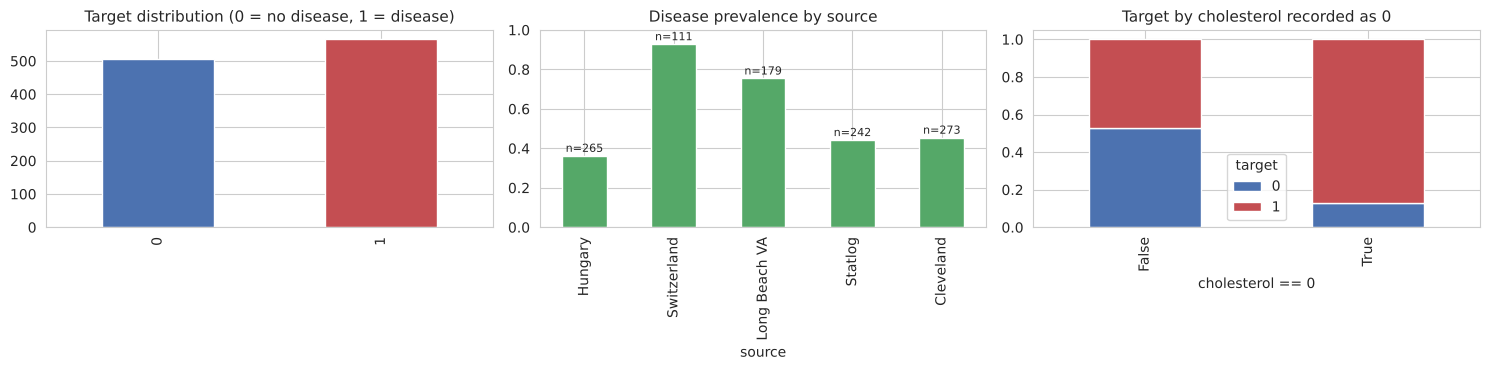

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
eda[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Target distribution (0 = no disease, 1 = disease)"); ax[0].set_xlabel("")
prev = eda.groupby("source", sort=False)[TARGET].agg(["mean", "size"])
prev["mean"].plot.bar(ax=ax[1], color="#55A868"); ax[1].set_title("Disease prevalence by source"); ax[1].set_ylim(0, 1)
for i, (m, n) in enumerate(prev.to_numpy()):
    ax[1].text(i, m + 0.02, f"n={int(n)}", ha="center", fontsize=8)
pd.crosstab(eda["cholesterol"] == 0, eda[TARGET], normalize="index").plot.bar(ax=ax[2], stacked=True, color=["#4C72B0", "#C44E52"])
ax[2].set_title("Target by cholesterol recorded as 0"); ax[2].set_xlabel("cholesterol == 0")
savefig("eda_target_source")

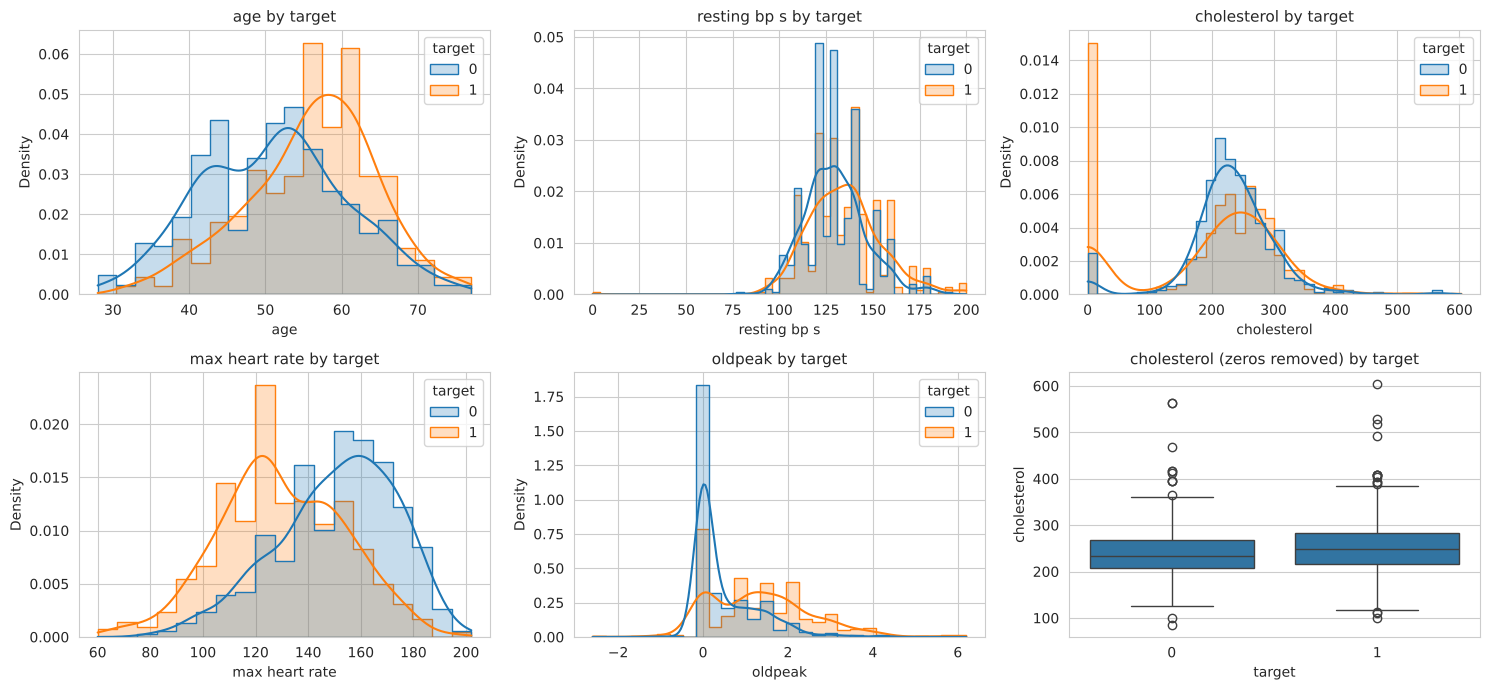

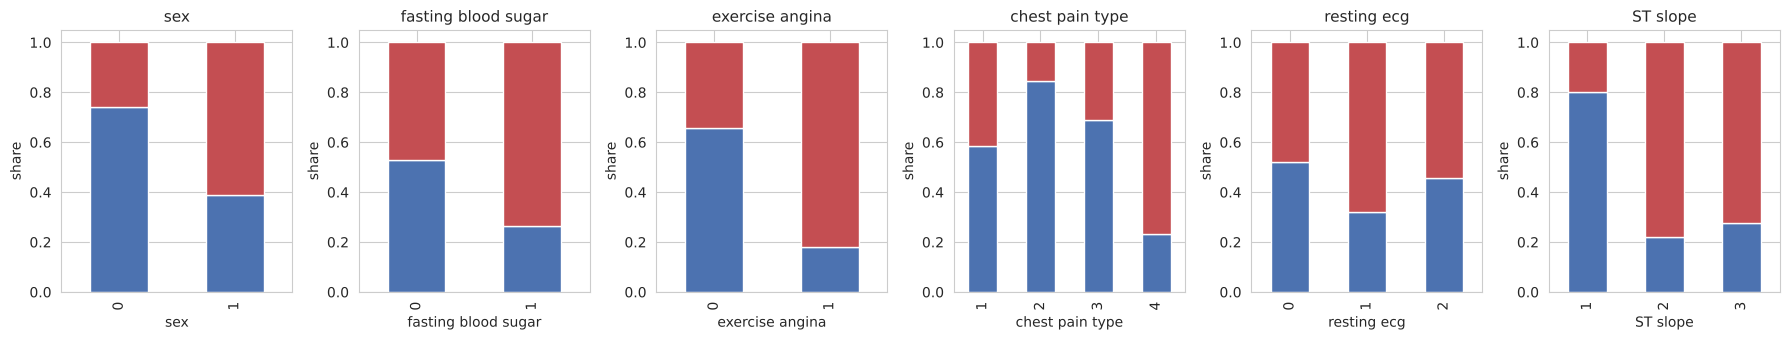

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(data=eda, x=col, hue=TARGET, kde=True, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(f"{col} by target")
sns.boxplot(data=eda[eda.cholesterol > 0], x=TARGET, y="cholesterol", ax=axes.ravel()[-1])
axes.ravel()[-1].set_title("cholesterol (zeros removed) by target")
savefig("eda_numeric")

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, col in zip(axes, BINARY + NOMINAL):
    pd.crosstab(eda[col], eda[TARGET], normalize="index").plot.bar(ax=ax, stacked=True, legend=False, color=["#4C72B0", "#C44E52"])
    ax.set_title(col); ax.set_ylabel("share")
savefig("eda_categorical")

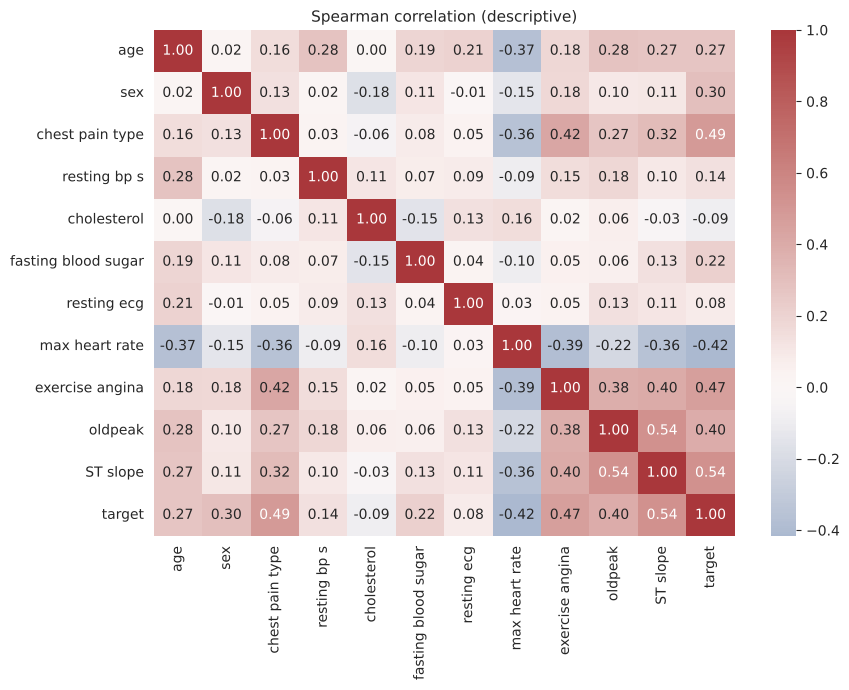

,n,prevalence,male_share
age_group,,,
<45,205,0.307,0.751
45-54,342,0.439,0.740
55-64,395,0.686,0.797
65+,128,0.633,0.758


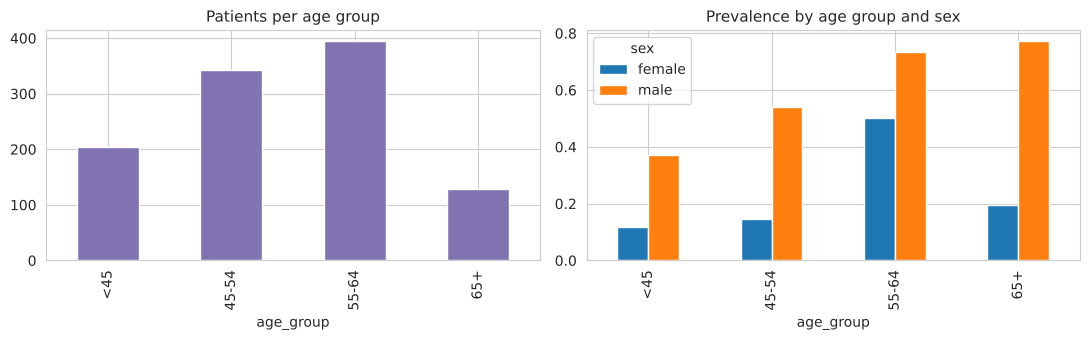

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(eda[FEATURES + [TARGET]].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Spearman correlation (descriptive)")
savefig("eda_correlation")

AGE_BINS = [0, 44, 54, 64, 200]; AGE_LABELS = ["<45", "45-54", "55-64", "65+"]
df["age_group"] = pd.cut(df["age"], AGE_BINS, labels=AGE_LABELS)
eda = df[df.split != "validation"]   # refresh the development view (age_group added)
age_tab = eda.groupby("age_group", observed=True).agg(n=(TARGET, "size"), prevalence=(TARGET, "mean"), male_share=("sex", "mean")).round(3)
display(age_tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
age_tab["n"].plot.bar(ax=ax[0], color="#8172B2", title="Patients per age group")
eda.groupby(["age_group", "sex"], observed=True)[TARGET].mean().unstack().rename(columns={0: "female", 1: "male"}).plot.bar(ax=ax[1], title="Prevalence by age group and sex")
savefig("eda_age_groups")

---
## 8. Building blocks
Everything that learns from data is written as a scikit-learn / imbalanced-learn component, so it can be placed inside a pipeline and is re-fitted on the training part of every fold. The pipeline order is always:

`raw features -> [zeros to NaN] -> scaling + imputation (+ missing indicator) and one-hot encoding -> feature selection -> class balancing (training folds only) -> model`

imbalanced-learn pipelines apply samplers **only during `fit`**; at prediction time the sampler is skipped, so validation and test rows are never resampled.

### 8.0 Reusable components module
The classes and resampling functions are written to `hd_components.py` by the next cell and imported. The notebook stays self-contained (it creates the file itself), and the components become importable by the parallel CV workers and by the cache that shares fitted GA / RFE / imputation steps between models. Each component is explained in Sections 8.1 to 8.5.

In [9]:
%%writefile hd_components.py
# hd_components.py: written by this notebook (Section 8.0). Reusable components that must be importable by the
# parallel cross-validation workers and by joblib's cache (classes defined inside a notebook cannot be pickled by reference).
import os, math
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.feature_selection import SelectorMixin
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, LeaveOneOut, cross_val_predict, train_test_split
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

SEED = int(os.environ.get("HD_SEED", "42"))

# ---------------------------------------------------------------- preprocessing helpers
class ZeroToNaN(TransformerMixin, BaseEstimator):
    """Stateless: marks physiologically impossible zeros (cholesterol, resting BP) as missing."""
    def __init__(self, columns=("cholesterol", "resting bp s")):
        self.columns = columns
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def transform(self, X):
        X = X.copy()
        for c in self.columns:
            if c in X.columns:
                col = X[c].astype(float)
                X[c] = col.mask(col == 0)
        return X
    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

class Prep(TransformerMixin, BaseEstimator):
    """Thin wrapper so the preprocessing pipeline can be one step of an imbalanced-learn pipeline
    (imbalanced-learn does not accept a Pipeline as an intermediate step)."""
    def __init__(self, pipeline):
        self.pipeline = pipeline
    def fit(self, X, y=None):
        self.pipeline_ = clone(self.pipeline).fit(X, y); return self
    def transform(self, X):
        return self.pipeline_.transform(X)
    def get_feature_names_out(self, input_features=None):
        return self.pipeline_.get_feature_names_out()


# ---------------------------------------------------------------- feature selectors (P3 SU, P1 GA)
def _entropy(codes):
    _, c = np.unique(codes, return_counts=True)
    p = c / c.sum()
    return float(-(p * np.log2(p)).sum())

class SymmetricUncertaintySelector(SelectorMixin, BaseEstimator):
    """P3 EG-HFS: symmetric uncertainty filter. threshold='mean' or a float; or keep top k if k is set."""
    def __init__(self, threshold="mean", k=None, n_bins=10, strict=False):
        self.threshold, self.k, self.n_bins, self.strict = threshold, k, n_bins, strict
    def _codes(self, x, edges):
        return np.searchsorted(edges, x, side="right")
    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y)
        self.n_features_in_ = X.shape[1]
        hy = _entropy(y); self.edges_ = []; su = []
        for j in range(X.shape[1]):
            x = X[:, j]; u = np.unique(x)
            edges = (u[:-1] + u[1:]) / 2 if len(u) <= self.n_bins else \
                    np.unique(np.quantile(x, np.linspace(0, 1, self.n_bins + 1)[1:-1]))
            self.edges_.append(edges)
            codes = self._codes(x, edges)
            hx = _entropy(codes)
            h_y_given_x = sum((codes == v).mean() * _entropy(y[codes == v]) for v in np.unique(codes))
            gain = hy - h_y_given_x
            su.append(0.0 if hx + hy == 0 else 2 * gain / (hx + hy))
        self.scores_ = np.array(su)
        if self.k:
            mask = np.zeros(X.shape[1], bool); mask[np.argsort(-self.scores_)[: self.k]] = True
        else:
            thr = self.scores_.mean() if self.threshold == "mean" else float(self.threshold)
            mask = self.scores_ > thr if self.strict else self.scores_ >= thr     # P3 Algorithm 2 uses "greater than th"
        if not mask.any():
            mask[np.argmax(self.scores_)] = True
        self.support_ = mask
        return self
    def _get_support_mask(self):
        return self.support_
    def transform(self, X):
        return np.asarray(X)[:, self.support_]

class GeneticAlgorithmSelector(SelectorMixin, BaseEstimator):
    """P1 genetic-algorithm wrapper selector (settings from the paper; fitness = out-of-fold MSE, minimised)."""
    def __init__(self, estimator=None, n_generations=18, population_size=80, n_elite=40,
                 crossover_rate=0.05, mutation_rate=0.05, cv=3, min_features=2, random_state=SEED):
        self.estimator, self.n_generations, self.population_size, self.n_elite = estimator, n_generations, population_size, n_elite
        self.crossover_rate, self.mutation_rate, self.cv, self.min_features, self.random_state = \
            crossover_rate, mutation_rate, cv, min_features, random_state
    def _fitness(self, mask, X, y):
        key = mask.tobytes()
        if key not in self._cache:
            est = clone(self.estimator) if self.estimator is not None else LogisticRegression(max_iter=2000)
            cv = StratifiedKFold(self.cv, shuffle=True, random_state=self.random_state)
            p = cross_val_predict(est, X[:, mask], y, cv=cv, method="predict_proba")[:, 1]
            self._cache[key] = float(np.mean((p - y) ** 2))
        return self._cache[key]
    def _repair(self, m, rng):
        if m.sum() < self.min_features:
            m[rng.choice(np.flatnonzero(~m), self.min_features - m.sum(), replace=False)] = True
        return m
    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y).astype(int)
        rng = np.random.default_rng(self.random_state)
        n = X.shape[1]; self.n_features_in_ = n; self._cache = {}
        P, E = self.population_size, min(self.n_elite, self.population_size)
        pop = np.array([self._repair(rng.random(n) < 0.5, rng) for _ in range(P)])
        self.history_ = []
        for g in range(self.n_generations):
            fit = np.array([self._fitness(m, X, y) for m in pop])
            order = np.argsort(fit)
            self.history_.append(float(fit[order[0]]))
            elite = pop[order[:E]]
            children = []
            while len(children) < P - E:
                pa, pb = pop[rng.integers(P)], pop[rng.integers(P)]          # parents picked at random
                child = pa.copy()
                if rng.random() < self.crossover_rate:                     # single-point crossover, p = 0.05
                    cut = rng.integers(1, n); child[cut:] = pb[cut:]
                child ^= rng.random(n) < self.mutation_rate                 # bit-flip mutation, p = 0.05
                children.append(self._repair(child, rng))
            pop = np.vstack([elite] + children) if children else elite
        fit = np.array([self._fitness(m, X, y) for m in pop])
        self.support_ = pop[np.argmin(fit)].copy()
        self.best_fitness_ = float(fit.min()); self.n_evaluations_ = len(self._cache)
        del self._cache
        return self
    def _get_support_mask(self):
        return self.support_
    def transform(self, X):
        return np.asarray(X)[:, self.support_]


# ---------------------------------------------------------------- class balancing (P1 USCOM) and P2 selective duplication
def uscom_resample(X, y, majority_excess_removed=0.5, k_max=6, random_state=SEED):
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    rng = np.random.default_rng(random_state)
    classes, counts = np.unique(y, return_counts=True)
    if len(classes) < 2 or counts[0] == counts[1]:
        return X, y
    maj, mino = classes[np.argmax(counts)], classes[np.argmin(counts)]
    i_maj, i_min = np.flatnonzero(y == maj), np.flatnonzero(y == mino)
    n_keep = len(i_min) + int(round((1 - majority_excess_removed) * (len(i_maj) - len(i_min))))
    keep = rng.choice(i_maj, n_keep, replace=False)
    Xmin = X[i_min]
    ks = list(range(1, min(k_max, len(Xmin) - 1) + 1))
    sse = [KMeans(k, n_init=10, random_state=random_state).fit(Xmin).inertia_ for k in ks]
    k = ks[int(np.argmax(np.diff(sse, 2))) + 1] if len(sse) >= 3 else 1          # elbow = largest 2nd difference
    labels = KMeans(k, n_init=10, random_state=random_state).fit_predict(Xmin)
    need = n_keep - len(i_min)
    sizes = np.bincount(labels, minlength=k)
    alloc = np.floor(need * sizes / sizes.sum()).astype(int)
    alloc[np.argsort(-(need * sizes / sizes.sum() - alloc))[: need - alloc.sum()]] += 1
    synth = []
    for c in range(k):
        members = Xmin[labels == c]
        if alloc[c] == 0:
            continue
        if len(members) < 2:
            synth.append(np.repeat(members, alloc[c], axis=0)); continue
        nn = NearestNeighbors(n_neighbors=min(6, len(members))).fit(members)
        neigh = nn.kneighbors(members, return_distance=False)[:, 1:]
        a = rng.integers(len(members), size=alloc[c])
        b = neigh[a, rng.integers(neigh.shape[1], size=alloc[c])]
        lam = rng.random((alloc[c], 1))
        synth.append(members[a] + lam * (members[b] - members[a]))
    Xs = np.vstack([X[keep], Xmin] + synth)
    ys = np.concatenate([y[keep], y[i_min], np.full(sum(len(s) for s in synth), mino)])
    return Xs, ys

def selective_duplication(X, y, estimator=None, inner_cv="loo", max_rounds=10, max_duplicates=272,
                          target_accuracy=1.0, random_state=SEED, return_history=False):
    """P2 Algorithm 1. Start from the unique instances; each round, run CV (LOO by default) of `estimator` on the current
    augmented set, find unique instances that have no correctly classified copy, and give them one extra copy
    (no instance appears more than twice). Stop when CV accuracy stops improving, the target accuracy is reached,
    or the number of duplicates would exceed 272 (the number of duplicates in the base dataset, as in P2)."""
    X = np.asarray(X, dtype=float); y = np.asarray(y).astype(int)
    _, uidx = np.unique(np.column_stack([X, y]), axis=0, return_index=True)
    uidx = np.sort(uidx); PX, Py = X[uidx], y[uidx]
    max_dups = int(max_duplicates)
    dup = np.zeros(len(PX), bool)
    best = (PX, Py); best_acc = -1.0; history = []
    for r in range(max_rounds):
        AX = np.vstack([PX, PX[dup]]); Ay = np.concatenate([Py, Py[dup]]); owner = np.concatenate([np.arange(len(PX)), np.flatnonzero(dup)])
        cv = LeaveOneOut() if inner_cv == "loo" else StratifiedKFold(int(inner_cv), shuffle=True, random_state=random_state)
        pred = cross_val_predict(clone(estimator), AX, Ay, cv=cv)
        acc = float((pred == Ay).mean())
        history.append({"round": r, "rows": len(Ay), "duplicates": int(dup.sum()), "cv_accuracy": acc})
        if acc <= best_acc:
            break                                             # (a) no improvement: keep the previous dataset
        best, best_acc = (AX, Ay), acc
        if acc >= target_accuracy:
            break                                             # (b) target reached
        correct = np.zeros(len(PX), bool); correct[owner[pred == Ay]] = True
        new_dup = dup | ~correct                              # misclassified unique instances get one extra copy
        if new_dup.sum() > max_dups or (new_dup == dup).all():
            break                                             # (c) too many duplicates, or nothing new to duplicate
        dup = new_dup
    return (best[0], best[1], history) if return_history else (best[0], best[1])


# ---------------------------------------------------------------- Keras wrapper (original FCNNs, P1 MLDCNN + EHO refinement)
def gaussian_activation(x):
    import tensorflow as tf
    return tf.exp(-tf.square(x))

class KerasTabularClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, arch="fcnn_baseline", epochs=500, batch_size=256, patience=20, validation_fraction=0.2,
                 learning_rate=0.001, eho_refine=False, eho_iterations=15, eho_clans=3, eho_clan_size=5,
                 random_state=SEED, verbose=0, hidden=(32, 16), optimizer="adam", momentum=0.9,
                 aehom_full=False, aehom_iterations=30, aehom_clans=4, aehom_clan_size=6, aehom_halfwidth=0.5, pos_weight=1.0):
        self.arch, self.epochs, self.batch_size, self.patience = arch, epochs, batch_size, patience
        self.validation_fraction, self.learning_rate, self.eho_refine = validation_fraction, learning_rate, eho_refine
        self.eho_iterations, self.eho_clans, self.eho_clan_size = eho_iterations, eho_clans, eho_clan_size
        self.random_state, self.verbose = random_state, verbose
        self.hidden, self.optimizer, self.momentum = hidden, optimizer, momentum
        self.aehom_full, self.aehom_iterations, self.aehom_clans = aehom_full, aehom_iterations, aehom_clans
        self.aehom_clan_size, self.aehom_halfwidth = aehom_clan_size, aehom_halfwidth
        self.pos_weight = pos_weight          # cost-sensitive learning: weight of the positive class in the cross-entropy

    def _shape(self, X):
        X = np.asarray(X, dtype=np.float32)
        return X[..., None] if self.arch == "mldcnn" else X

    def _build(self, n):
        from tensorflow import keras
        L = keras.layers
        if self.arch == "mldcnn":
            inp = keras.Input(shape=(n, 1)); h = inp
            for f in (32, 64, 64):
                h = L.Conv1D(f, 3, padding="same")(h); h = L.LayerNormalization()(h); h = L.Activation(gaussian_activation)(h)
            h = L.Flatten()(h); h = L.Dense(64)(h); h = L.LayerNormalization()(h); h = L.Activation(gaussian_activation)(h)
            h = L.Dropout(0.2)(h)
        else:
            inp = keras.Input(shape=(n,)); h = inp
            if self.arch == "fcnn_baseline":
                h = L.Dense(72, activation="relu")(h)
            elif self.arch == "mldcnn_dense":
                # P1 equations (11)-(20) describe weighted sums + Gaussian activation exp(-x^2) per layer, trained by
                # back-propagation with momentum. Layer widths are not given in P1: `hidden` is a tuned hyperparameter.
                for u in self.hidden:
                    h = L.Dense(u)(h); h = L.Activation(gaussian_activation)(h)
            elif self.arch == "fcnn_regularised":
                reg = lambda: keras.regularizers.l1_l2(l1=0.002, l2=0.002)
                for u in (72, 64, 24):
                    h = L.Dense(u, activation="relu", kernel_regularizer=reg())(h)
            else:
                raise ValueError(self.arch)
        out = L.Dense(2, activation="softmax")(h)
        model = keras.Model(inp, out)
        opt = keras.optimizers.SGD(self.learning_rate, momentum=self.momentum) if self.optimizer == "sgd" else keras.optimizers.Adam(self.learning_rate)
        model.compile(optimizer=opt, loss="sparse_categorical_crossentropy")
        return model

    def _sw(self, y):
        return np.where(np.asarray(y) == 1, float(self.pos_weight), 1.0).astype(np.float32)

    def fit(self, X, y, X_val=None, y_val=None):
        """X_val / y_val: optional explicit validation set for early stopping (P1's 8:1:1 protocol);
        otherwise a stratified internal split of the training data is used."""
        from tensorflow import keras
        keras.utils.set_random_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32); y = np.asarray(y).astype(int)
        self.classes_ = np.unique(y)
        if X_val is None:
            Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=self.validation_fraction, stratify=y, random_state=self.random_state)
        else:
            Xtr, ytr, Xva, yva = X, y, np.asarray(X_val, dtype=np.float32), np.asarray(y_val).astype(int)
        model = self._build(X.shape[1])
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience, restore_best_weights=True)
        # class-weighted binary cross-entropy (pos_weight = 1 is the ordinary loss); validation loss weighted the same way
        hist = model.fit(self._shape(Xtr), ytr, sample_weight=self._sw(ytr), validation_data=(self._shape(Xva), yva, self._sw(yva)),
                         epochs=self.epochs, batch_size=self.batch_size, callbacks=[es], verbose=self.verbose)
        self.history_ = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
        self.model_ = model
        self.eho_gain_ = 0.0
        if self.eho_refine:
            self._eho_refine(Xva, yva)
        self.aehom_report_ = None
        if self.aehom_full:
            self._aehom_all_weights(Xtr, ytr, Xva, yva)
        return self

    def _numpy_forward(self, weights, X):
        """Forward pass of the dense Gaussian network (mldcnn_dense) from a flat weight list."""
        h = X
        for i in range(0, len(weights) - 2, 2):
            h = np.exp(-np.square(h @ weights[i] + weights[i + 1]))
        z = h @ weights[-2] + weights[-1]; z = z - z.max(1, keepdims=True)
        return np.exp(z) / np.exp(z).sum(1, keepdims=True)

    def _aehom_all_weights(self, Xtr, ytr, Xva, yva):
        """P1 AEHOM applied to ALL network weights (eqs. 21-24 + two-point crossover + mutation), starting from the
        back-propagated weights. Fitness = training cross-entropy (P1 adjusts weights to reduce the error).
        Our safeguard: the result is kept only if the internal validation loss does not get worse."""
        if self.arch != "mldcnn_dense":
            raise ValueError("aehom_full is implemented for the dense P1 network")
        shapes = [w.shape for w in self.model_.get_weights()]
        sizes = [int(np.prod(sh)) for sh in shapes]
        def unflat(t):
            out, i = [], 0
            for sh, n in zip(shapes, sizes):
                out.append(t[i:i + n].reshape(sh)); i += n
            return out
        def ce(t, X, y):                    # class-weighted cross-entropy, consistent with the training loss
            p = self._numpy_forward(unflat(t), X); w = self._sw(y)
            return float(-np.sum(w * np.log(p[np.arange(len(y)), y] + 1e-12)) / np.sum(w))
        theta0 = np.concatenate([w.ravel() for w in self.model_.get_weights()]).astype(float)
        best, hist = aehom_optimize(lambda t: ce(t, Xtr, ytr), theta0, self.aehom_halfwidth, self.aehom_clans,
                                    self.aehom_clan_size, self.aehom_iterations, np.random.default_rng(self.random_state))
        v0, v1 = ce(theta0, Xva, yva), ce(best, Xva, yva)
        accepted = v1 <= v0
        if accepted:
            self.model_.set_weights([w.astype(np.float32) for w in unflat(best)])
        self.aehom_report_ = {"train_loss_before": hist[0], "train_loss_after": hist[-1], "val_loss_before": v0,
                              "val_loss_after": v1, "accepted": bool(accepted)}

    def _eho_refine(self, Xva, yva):
        """Elephant herding refinement of the output layer (P1 AEHOM idea), on the internal validation split."""
        from tensorflow import keras
        rng = np.random.default_rng(self.random_state)
        feat = keras.Model(self.model_.inputs, self.model_.layers[-2].output)
        H = np.asarray(feat(self._shape(Xva), training=False))
        W, b = self.model_.layers[-1].get_weights()
        theta0 = np.concatenate([W.ravel(), b])
        def loss(theta):
            Wt, bt = theta[: W.size].reshape(W.shape), theta[W.size:]
            z = H @ Wt + bt; z -= z.max(1, keepdims=True)
            p = np.exp(z) / np.exp(z).sum(1, keepdims=True)
            return float(-np.mean(np.log(p[np.arange(len(yva)), yva] + 1e-12)))
        scale = 0.05 * (np.std(theta0) + 1e-3)
        pop = theta0 + rng.normal(0, scale, (self.eho_clans, self.eho_clan_size, theta0.size)); pop[0, 0] = theta0
        fit = np.array([[loss(e) for e in clan] for clan in pop])
        alpha, beta = 0.5, 0.1
        for _ in range(self.eho_iterations):
            for c in range(self.eho_clans):
                best = np.argmin(fit[c]); center = pop[c].mean(0)
                for j in range(self.eho_clan_size):
                    if j == best:
                        cand = pop[c, j] + beta * (center - pop[c, j])                      # matriarch update
                    else:
                        cand = pop[c, j] + alpha * (pop[c, best] - pop[c, j]) * rng.random(theta0.size)  # clan updating
                    f = loss(cand)
                    if f < fit[c, j]:
                        pop[c, j], fit[c, j] = cand, f
                worst = np.argmax(fit[c])                                                   # separating operator
                pop[c, worst] = pop[c, np.argmin(fit[c])] + rng.normal(0, scale, theta0.size)
                fit[c, worst] = loss(pop[c, worst])
        c, j = np.unravel_index(np.argmin(fit), fit.shape)
        if fit[c, j] < loss(theta0):
            self.eho_gain_ = loss(theta0) - fit[c, j]
            th = pop[c, j]
            self.model_.layers[-1].set_weights([th[: W.size].reshape(W.shape).astype(np.float32), th[W.size:].astype(np.float32)])

    def predict_proba(self, X):
        return np.asarray(self.model_(self._shape(X), training=False))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


# ---------------------------------------------------------------- P1 AEHOM (elephant herding with crossover and mutation)
def aehom_optimize(fitness, theta0, halfwidth, n_clans, clan_size, iterations, rng, c=0.5, l=0.1, mut_rate=0.02):
    """Minimise `fitness` in the box theta0 +/- halfwidth.
    Eq. 21 clan updating: x_new = x + c * (x_matriarch - x) * RD;  Eq. 22-23 matriarch: x_new = l * clan centre;
    Eq. 24 separating operator: worst = Pmin + (Pmax - Pmin + 1) * k (clipped to the box, since +1 can leave it);
    then a two-point crossover between the two best elephants of each clan and a gene-replacement mutation.
    Population sizes, c and l are not given in P1 (our choices); the initial matriarch is the back-propagated solution."""
    lo, hi = theta0 - halfwidth, theta0 + halfwidth
    d = theta0.size
    pop = rng.uniform(lo, hi, (n_clans, clan_size, d)); pop[:, 0] = theta0
    fit = np.array([[fitness(e) for e in clan] for clan in pop])
    history = [float(fit.min())]
    for _ in range(iterations):
        for ci in range(n_clans):
            m = int(np.argmin(fit[ci])); centre = pop[ci].mean(0)
            for j in range(clan_size):
                if j == m:
                    cand = l * centre + (1 - l) * pop[ci, j]                     # eq. 22 (blended so the matriarch is not pulled to 0)
                else:
                    cand = pop[ci, j] + c * (pop[ci, m] - pop[ci, j]) * rng.random(d)   # eq. 21
                cand = np.clip(cand, lo, hi); f = fitness(cand)
                if f < fit[ci, j]:
                    pop[ci, j], fit[ci, j] = cand, f
            w = int(np.argmax(fit[ci]))                                          # eq. 24 separating operator
            pop[ci, w] = np.clip(lo + (hi - lo + 1) * rng.random(d), lo, hi); fit[ci, w] = fitness(pop[ci, w])
            a, b = np.argsort(fit[ci])[:2]                                       # two-point crossover
            p1, p2 = sorted(rng.choice(d, 2, replace=False))
            child = pop[ci, a].copy(); child[p1:p2] = pop[ci, b, p1:p2]
            mask = rng.random(d) < mut_rate                                      # mutation: replace genes with new values
            child[mask] = rng.uniform(lo[mask], hi[mask])
            fc = fitness(child); w = int(np.argmax(fit[ci]))
            if fc < fit[ci, w]:
                pop[ci, w], fit[ci, w] = child, fc
        history.append(float(fit.min()))
    ci, j = np.unravel_index(np.argmin(fit), fit.shape)
    return pop[ci, j].copy(), history

# ---------------------------------------------------------------- P1 UCOM, literal reading
def ucom_literal_resample(X, y, majority_keep=2 / 3, k_max=6, random_state=SEED):
    """P1 UCOM as written: (1) randomly keep two-thirds of the majority class (the 2:3 ratio P1 states),
    (2) k-means clustering of the minority class with k chosen by the SSE elbow, (3) SMOTE on the merged training set
    until both classes are equal. The per-cluster 8:1:1 train/validation/test split is replaced by our outer CV."""
    from imblearn.over_sampling import SMOTE
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    rng = np.random.default_rng(random_state)
    classes, counts = np.unique(y, return_counts=True)
    maj, mino = classes[np.argmax(counts)], classes[np.argmin(counts)]
    i_maj, i_min = np.flatnonzero(y == maj), np.flatnonzero(y == mino)
    keep = rng.choice(i_maj, int(round(majority_keep * len(i_maj))), replace=False)
    Xmin = X[i_min]
    ks = list(range(1, min(k_max, len(Xmin) - 1) + 1))
    sse = [KMeans(k, n_init=10, random_state=random_state).fit(Xmin).inertia_ for k in ks]
    k = ks[int(np.argmax(np.diff(sse, 2))) + 1] if len(sse) >= 3 else 1
    labels = KMeans(k, n_init=10, random_state=random_state).fit_predict(Xmin)
    order = np.concatenate([np.flatnonzero(labels == c) for c in range(k)])   # minority grouped cluster by cluster
    Xc = np.vstack([X[keep], Xmin[order]]); yc = np.concatenate([y[keep], y[i_min][order]])
    if len(np.unique(yc, return_counts=True)[1]) == 2 and len(set(np.unique(yc, return_counts=True)[1])) == 1:
        return Xc, yc
    return SMOTE(random_state=random_state).fit_resample(Xc, yc)

# ---------------------------------------------------------------- clinically motivated feature engineering
class ClinicalFeatures(TransformerMixin, BaseEstimator):
    """Adds derived variables computed row by row (no fitted statistics, so no leakage):
    hr_pct_pred  = max heart rate / (220 - age): fraction of age-predicted maximal heart rate (chronotropic response);
    age_x_maxhr  = age * max heart rate / 1000 (interaction asked for in the brief);
    oldpeak_pos  = ST depression > 0;  st_abn_x_oldpeak = oldpeak * (ST slope flat or down-sloping);
    exang_x_oldpeak = exercise angina * oldpeak;  asymptomatic_cp = chest pain type 4 (asymptomatic)."""
    NEW = ["hr_pct_pred", "age_x_maxhr", "oldpeak_pos", "st_abn_x_oldpeak", "exang_x_oldpeak", "asymptomatic_cp"]
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object); return self
    def transform(self, X):
        X = X.copy()
        X["hr_pct_pred"] = X["max heart rate"] / (220 - X["age"])
        X["age_x_maxhr"] = X["age"] * X["max heart rate"] / 1000
        X["oldpeak_pos"] = (X["oldpeak"] > 0).astype(float)
        X["st_abn_x_oldpeak"] = X["oldpeak"] * X["ST slope"].isin([2, 3]).astype(float)
        X["exang_x_oldpeak"] = X["exercise angina"] * X["oldpeak"]
        X["asymptomatic_cp"] = (X["chest pain type"] == 4).astype(float)
        return X
    def get_feature_names_out(self, input_features=None):
        return np.concatenate([self.feature_names_in_, self.NEW])

# ---------------------------------------------------------------- final predictor: single model or ensemble + threshold
def learn_weights(P, y):
    """Non-negative weights summing to 1 that minimise the log-loss of the weighted average of the columns of P."""
    from scipy.optimize import minimize
    k = P.shape[1]
    def loss(z):
        w = np.exp(z) / np.exp(z).sum(); p = np.clip(P @ w, 1e-6, 1 - 1e-6)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    z = minimize(loss, np.zeros(k), method="Nelder-Mead", options={"maxiter": 2000, "xatol": 1e-4, "fatol": 1e-7}).x
    return np.exp(z) / np.exp(z).sum()

class FinalEnsemble(ClassifierMixin, BaseEstimator):
    """members: list of (name, estimator). method: 'single' | 'soft' | 'hard' | 'stack' | 'weighted' | 'blend'.
    For 'stack' the meta-learner is trained on out-of-fold probabilities (cross_val_predict inside fit);
    for 'weighted' the weights are given (learned on out-of-fold predictions of the training data).
    threshold: decision threshold on P(class 1), chosen beforehand on training out-of-fold predictions."""
    def __init__(self, members=None, method="single", weights=None, threshold=0.5, stack_cv=5, random_state=SEED):
        self.members, self.method, self.weights, self.threshold = members, method, weights, threshold
        self.stack_cv, self.random_state = stack_cv, random_state
    def _proba_matrix(self, fitted, X):
        cols = []
        for m in fitted:
            if hasattr(m, "predict_proba"):
                cols.append(np.asarray(m.predict_proba(X))[:, 1])
            else:
                cols.append(1 / (1 + np.exp(-np.asarray(m.decision_function(X)))))
        return np.column_stack(cols)
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1])
        if self.method == "blend":
            # holdout blending: members on 75% of the training data, meta-learner on their predictions for the other 25%
            idx_a, idx_b = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=self.random_state)
            Xa = X.iloc[idx_a] if hasattr(X, "iloc") else X[idx_a]; Xb = X.iloc[idx_b] if hasattr(X, "iloc") else X[idx_b]
            self.fitted_ = [clone(est).fit(Xa, y[idx_a]) for _, est in self.members]
            self.meta_ = LogisticRegression(max_iter=2000).fit(self._proba_matrix(self.fitted_, Xb), y[idx_b])
            return self
        self.fitted_ = [clone(est).fit(X, y) for _, est in self.members]
        if self.method == "stack" or (self.method == "weighted" and self.weights is None):
            cv = StratifiedKFold(self.stack_cv, shuffle=True, random_state=self.random_state)
            oof = np.column_stack([cross_val_predict(clone(est), X, y, cv=cv, method="predict_proba")[:, 1]
                                   for _, est in self.members])
            if self.method == "stack":
                self.meta_ = LogisticRegression(max_iter=2000).fit(oof, y)
            else:
                self.weights_ = learn_weights(oof, y)
        return self
    def predict_proba(self, X):
        P = self._proba_matrix(self.fitted_, X)
        if self.method == "single":
            p = P[:, 0]
        elif self.method == "soft":
            p = P.mean(1)
        elif self.method == "hard":
            p = (P >= 0.5).mean(1)
        elif self.method == "weighted":
            w = np.asarray(self.weights if self.weights is not None else self.weights_, float); p = P @ (w / w.sum())
        elif self.method in ("stack", "blend"):
            p = self.meta_.predict_proba(P)[:, 1]
        else:
            raise ValueError(self.method)
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)


# ---------------------------------------------------------------- LSRO-ML-HDPM building blocks (Section 29)
def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

class PlattScaler:
    """Platt (sigmoid) calibration: logistic regression of the label on logit(score).
    Fitted ONLY on out-of-fold scores, i.e. on predictions for patients the scoring model did not train on."""
    def fit(self, s, y):
        self.lr_ = LogisticRegression(C=1e4, max_iter=1000).fit(_logit(s)[:, None], np.asarray(y).astype(int))
        self.a_, self.b_ = float(self.lr_.coef_[0, 0]), float(self.lr_.intercept_[0])
        self.n_fit_ = int(len(y))
        return self
    def transform(self, s):
        return self.lr_.predict_proba(_logit(s)[:, None])[:, 1]

class LSROVariant(ClassifierMixin, BaseEstimator):
    """A prefit ML-HDPM variant: fitted base pipeline -> optional Platt calibrator -> decision threshold.
    Nothing here is fitted at predict time; fit() refuses to refit so a frozen model cannot change."""
    def __init__(self, base=None, calibrator=None, threshold=0.5, label=""):
        self.base, self.calibrator, self.threshold, self.label = base, calibrator, threshold, label
        self.classes_ = np.array([0, 1])
    def fit(self, X, y):
        raise RuntimeError("LSROVariant is a frozen, prefit model")
    def predict_proba(self, X):
        s = np.asarray(self.base.predict_proba(X))[:, 1]
        p = self.calibrator.transform(s) if self.calibrator is not None else s
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)

def recall_constrained_threshold(y, s, target=0.90):
    """Pre-specified rule: the HIGHEST threshold whose recall is >= target. Specificity cannot fall as the threshold
    rises, so this maximises specificity subject to recall >= target. Returns (threshold, feasible, recall, specificity)."""
    y = np.asarray(y).astype(int); s = np.asarray(s, float)
    pos = np.sort(s[y == 1])[::-1]
    k = int(np.ceil(target * len(pos)))               # at least k positives must score >= threshold
    if len(pos) == 0 or k < 1:
        return 0.5, False, np.nan, np.nan
    t = float(pos[k - 1])
    pred = (s >= t).astype(int)
    rec = pred[y == 1].mean(); spec = 1 - pred[y == 0].mean()
    return t, bool(rec >= target and spec > 0), float(rec), float(spec)

Writing hd_components.py


In [10]:
os.environ["HD_SEED"] = str(SEED)
sys.path.insert(0, os.getcwd())          # parallel workers inherit this path and can import the module
import hd_components
importlib.reload(hd_components)
from hd_components import (ZeroToNaN, Prep, SymmetricUncertaintySelector, GeneticAlgorithmSelector, uscom_resample,
                           selective_duplication, KerasTabularClassifier, gaussian_activation, aehom_optimize,
                           ucom_literal_resample, ClinicalFeatures, FinalEnsemble, learn_weights,
                           PlattScaler, LSROVariant, recall_constrained_threshold)
print("Components imported from", hd_components.__file__)

Components imported from /home/claude/run_full5/hd_components.py


### 8.1 Preprocessing (factories; the ZeroToNaN and Prep classes are in the module)

In [11]:
def make_preprocessor(scaler="standard", imputer="median", indicator=True, zeros_as_missing=True,
                      numeric=None, binary=None, nominal=None, zero_cols=("cholesterol", "resting bp s")):
    """Column-wise preprocessing fitted on training data only."""
    numeric = NUMERIC if numeric is None else numeric
    binary = BINARY if binary is None else binary
    nominal = NOMINAL if nominal is None else nominal
    sc = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}[scaler]
    if imputer == "knn":       # P1: fill a missing value from similar patients
        imp = KNNImputer(n_neighbors=5, add_indicator=indicator)
    else:                      # "median" (default) or "mean" (P3)
        imp = SimpleImputer(strategy=imputer, add_indicator=indicator)
    num_pipe = Pipeline([("scale", sc), ("impute", imp)])     # scalers ignore NaN when fitting
    nom_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    ct = ColumnTransformer([("num", num_pipe, list(numeric)), ("bin", "passthrough", list(binary)),
                            ("nom", nom_pipe, list(nominal))], verbose_feature_names_out=False)
    steps = ([("zeros", ZeroToNaN(zero_cols))] if zeros_as_missing else []) + [("ct", ct)]
    return Prep(Pipeline(steps))

# Preprocessing used by the ORIGINAL project, made leakage-free: MinMax scaling and one-hot encoding fitted on training data,
# zeros kept as values (as in the original).
def prep_original():
    return make_preprocessor(scaler="minmax", zeros_as_missing=False, indicator=False)
# Improved preprocessing used in the new experiments: zeros -> missing, median imputation with a missing indicator, z-scores.
def prep_improved(imputer="median"):
    return make_preprocessor(scaler="standard", imputer=imputer, zeros_as_missing=True, indicator=True)
# P2 preprocessing: z-score of age, resting BP, cholesterol and max heart rate only; other columns as raw codes.
P2_SCALED = ["age", "resting bp s", "cholesterol", "max heart rate"]
def prep_p2(features=FEATURES):
    rest = [c for c in features if c not in P2_SCALED]
    return ColumnTransformer([("z", StandardScaler(), [c for c in P2_SCALED if c in features]),
                              ("raw", "passthrough", rest)], verbose_feature_names_out=False)

### 8.2 Feature selectors (all fitted inside training folds)
* **ANOVA F-test, mutual information, RFE**: scikit-learn, top `k` = 10 of the ~20 encoded features.
* **Symmetric uncertainty (P3 EG-HFS)**: SU = 2 * IG(X;Y) / (H(X) + H(Y)), continuous features discretised into 10 quantile bins learned on the training fold. P3 does not give the threshold; we keep features with SU at or above the mean SU (interpretation).
* **Genetic algorithm (P1)**: P1 settings in full mode: 18 generations, 80 genomes, 40 elite genomes carried over, the other 40 produced from randomly picked parents, single-point crossover with probability 0.05, bit-flip mutation with probability 0.05, fitness = mean squared error. We read "mean squared error of the genome" as the out-of-fold Brier score (MSE of predicted probabilities) of a logistic regression trained on the genome's features, minimised (interpretation).
* **GA + RFE (P1 hybrid)**: the GA subset is passed to RFE. P1 does not give the number of features to keep, so RFECV chooses it by inner CV (interpretation).

In [12]:
K_FEATURES = 10
def ga_selector():
    return GeneticAlgorithmSelector(n_generations=CFG["ga_generations"], population_size=CFG["ga_population"],
                                    n_elite=CFG["ga_elite"], random_state=SEED)
def rfecv_selector():
    return RFECV(LogisticRegression(max_iter=2000), step=1, min_features_to_select=2,
                 cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="neg_brier_score")

def make_selectors(k=K_FEATURES, include_ga=True):
    sel = {
        "None": [],
        "Variance threshold 0.006 (original)": [VarianceThreshold(0.006)],
        f"ANOVA F-test (k={k})": [SelectKBest(f_classif, k=k)],
        f"Mutual information (k={k})": [SelectKBest(functools.partial(mutual_info_classif, random_state=SEED), k=k)],
        f"RFE-LR (k={k})": [RFE(LogisticRegression(max_iter=2000), n_features_to_select=k)],
        "Symmetric uncertainty (P3 EG-HFS)": [SymmetricUncertaintySelector("mean")],
    }
    if include_ga:
        sel["Genetic algorithm (P1)"] = [ga_selector()]
        sel["GA + RFE (P1 hybrid)"] = [ga_selector(), rfecv_selector()]   # GA step is cached and shared with the GA-only pipeline
    return sel

### 8.3 Class-balancing methods (applied to training folds only)
* ROS, RUS, SMOTE, SMOTE-ENN and ClusterCentroids (cluster-based undersampling) from imbalanced-learn.
* **USCOM (P1 interpretation)**: (1) random undersampling of the majority class, removing half of its excess over the minority class (P1's 2:3 ratio refers to MIMIC-III stroke data and does not transfer), (2) k-means clustering of the minority class with k chosen by the SSE elbow (k = 1 to 6), (3) SMOTE-style interpolation **within each cluster** until the classes are equal. P1's 8:1:1 per-cluster split is replaced by our outer CV and test set.
* **Selective duplication (P2)**: iterative duplication of instances misclassified in leave-one-out CV of the training data (Section 14.2).

In [13]:
def make_samplers():
    return {
        "None": None,
        "ROS": RandomOverSampler(random_state=SEED),
        "RUS": RandomUnderSampler(random_state=SEED),
        "SMOTE": SMOTE(random_state=SEED),
        "SMOTE-ENN": SMOTEENN(random_state=SEED),
        "Cluster centroids (undersampling)": ClusterCentroids(estimator=KMeans(n_init=10, random_state=SEED), random_state=SEED),
        "USCOM (P1 interpretation)": FunctionSampler(func=uscom_resample, kw_args={"random_state": SEED}, validate=True),
    }

def p2_sampler(estimator, inner_cv="loo"):
    return FunctionSampler(func=selective_duplication, kw_args={"estimator": estimator, "inner_cv": inner_cv}, validate=True)

### 8.4 Models
* **Original configurations** are copied from the original notebooks (XGBoost uses `tree_method="exact"`, learning rate 0.3 and 100 trees, the defaults of the XGBoost version used in 2022, so that the original result is reproduced exactly).
* **Reference models** for the comparison experiments use standard, untuned settings.
* **Parent-paper configurations** follow each paper where it gives values.

In [14]:
XGB_ORIGINAL = dict(max_depth=10, gamma=0.6, booster="gbtree", objective="binary:logistic", eval_metric="logloss",
                    tree_method="exact", learning_rate=0.3, n_estimators=100, random_state=0, n_jobs=1, base_score=0.5)

def original_models(stack_cv=10):
    base = {
        "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=42),
        "Logistic Regression": LogisticRegression(solver="lbfgs", random_state=42),
        "Decision Tree (depth 6)": DecisionTreeClassifier(max_depth=6, random_state=42),
        "Random Forest (10 trees, entropy)": RandomForestClassifier(n_estimators=10, criterion="entropy", random_state=42, n_jobs=1),
        "XGBoost (original)": XGBClassifier(**XGB_ORIGINAL),
        "SVM (poly, degree 3)": SVC(C=1.0, kernel="poly", degree=3, probability=True, random_state=42),
        "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    }
    six = [("lr", base["Logistic Regression"]), ("dt", base["Decision Tree (depth 6)"]), ("rf", base["Random Forest (10 trees, entropy)"]),
           ("xgb", base["XGBoost (original)"]), ("svm", base["SVM (poly, degree 3)"]), ("knn", base["KNN (k=3)"])]
    base["Stacking (6 models, MLP meta)"] = StackingClassifier([(n, clone(m)) for n, m in six],
                                                              final_estimator=MLPClassifier(random_state=1, max_iter=200), cv=stack_cv)
    base["Stacking (RF + XGB, MLP meta)"] = StackingClassifier([("rf", clone(base["Random Forest (10 trees, entropy)"])), ("xgb", clone(base["XGBoost (original)"]))],
                                                              final_estimator=MLPClassifier(random_state=1, max_iter=200), cv=stack_cv)
    return base

def reference_models():
    return {
        "LR": LogisticRegression(max_iter=2000, random_state=SEED),
        "RF": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
        "XGB": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             eval_metric="logloss", random_state=SEED, n_jobs=1),
        "SVM-RBF": SVC(kernel="rbf", random_state=SEED),
        "KNN-15": KNeighborsClassifier(n_neighbors=15),
    }

def p1_models():
    return {"SVM": SVC(random_state=SEED), "LDA": LinearDiscriminantAnalysis(), "Naive Bayes": GaussianNB(),
            "Decision Tree": DecisionTreeClassifier(random_state=SEED),
            "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
            "PCA + LR": Pipeline([("pca", PCA(n_components=0.95, random_state=SEED)), ("lr", LogisticRegression(max_iter=2000))])}

def p2_models():   # P2 Table 4 hyperparameters; defaults otherwise
    return {"KNN": KNeighborsClassifier(n_neighbors=1),
            "RF": RandomForestClassifier(n_estimators=50, max_depth=11, random_state=0, n_jobs=1),
            "DT": DecisionTreeClassifier(random_state=SEED),
            "SVM": SVC(C=50, kernel="rbf", gamma=0.1, random_state=SEED),
            "GNB": GaussianNB(),
            "ADB": AdaBoostClassifier(random_state=SEED)}

def bagged(model):  # P2: 100 estimators, random state 1
    return BaggingClassifier(estimator=model, n_estimators=100, random_state=1, n_jobs=1)

def p3_models():
    return {"Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
            "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
            "SVM": SVC(random_state=SEED),
            "Decision Tree": DecisionTreeClassifier(random_state=SEED),
            "SGD": SGDClassifier(loss="log_loss", max_iter=2000, random_state=SEED),
            "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
            "XGBoost": XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1)}

### 8.5 Keras wrapper: original fully connected networks and the P1 multilayer CNN
* `fcnn_baseline`: Dense(72, ReLU) to Dense(2, softmax), Adam, sparse categorical cross-entropy, batch 256, up to 500 epochs, early stopping on validation loss (patience 20, best weights restored). This is the original project's baseline network.
* `fcnn_regularised`: Dense 72-64-24 with L1/L2 = 0.002, the original project's larger network.
* `mldcnn` (P1 interpretation): three Conv1D blocks (32, 64, 64 filters, kernel 3) with layer normalisation and the **Gaussian activation exp(-x^2)** named by P1, then Dense(64) with Gaussian activation, dropout 0.2 and a softmax output. P1 gives no layer sizes, so these are our choices. Layer normalisation is used instead of batch normalisation because, with early stopping after a few epochs on a few hundred patients, batch-norm running statistics were not yet adapted and the network collapsed to near-chance predictions in testing. Each feature is treated as one position of a 1-D sequence, which imposes an arbitrary feature order (a known weakness of CNNs on tabular data).
* `eho_refine=True`: after back-propagation, an elephant-herding search (clan updating, matriarch update and separating operator, P1's AEHOM idea) refines the output-layer weights on the internal validation split; the refined weights are kept only if the validation loss improves.

The validation split used for early stopping is taken from the **training fold**, never from the test set (the original project monitored a validation split but saved models named after their test accuracy).

### 8.6 Metrics, confidence intervals, leakage-safe cross-validation and the test set
Metric definitions (positive class = 1 = heart disease):
* **Accuracy** = (TP + TN) / N; **Precision (PPV)** = TP / (TP + FP); **Recall = Sensitivity (TPR)** = TP / (TP + FN); **Specificity (TNR)** = TN / (TN + FP)
* **F1** = 2TP / (2TP + FP + FN) for the positive class. The original project mixed macro F1 and weighted F1; here `f1` is always the positive-class F1 and `f1_macro` is reported separately for comparison with the original.
* **MCC** = (TP*TN - FP*FN) / sqrt((TP+FP)(TP+FN)(TN+FP)(TN+FN)); **ROC-AUC** from predicted probabilities or decision scores.
* 95% CIs: **Wilson** interval for proportions computed from the actual counts, and stratified **bootstrap** percentile intervals for F1, MCC and AUC. These replace the original hard-coded calculations.

In [15]:
METRICS = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "mcc", "roc_auc"]
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
           "precision": make_scorer(precision_score, zero_division=0), "recall": "recall",
           "specificity": make_scorer(recall_score, pos_label=0, zero_division=0), "f1": "f1", "f1_macro": "f1_macro",
           "mcc": make_scorer(matthews_corrcoef), "roc_auc": "roc_auc"}

def scores_of(model, X):
    """Continuous score for AUC: P(class 1) if available, otherwise the decision function."""
    if hasattr(model, "predict_proba"):
        try:
            return np.asarray(model.predict_proba(X))[:, 1]
        except Exception:
            pass
    return np.asarray(model.decision_function(X))

def compute_metrics(y, pred, score=None):
    y = np.asarray(y).astype(int); pred = np.asarray(pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    m = dict(n=len(y), tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn),
             accuracy=div(tp + tn, len(y)), precision=div(tp, tp + fp), recall=div(tp, tp + fn),
             specificity=div(tn, tn + fp), npv=div(tn, tn + fn), f1=div(2 * tp, 2 * tp + fp + fn))
    m["balanced_accuracy"] = (m["recall"] + m["specificity"]) / 2
    m["f1_macro"] = f1_score(y, pred, average="macro", zero_division=0)
    m["mcc"] = matthews_corrcoef(y, pred)
    m["roc_auc"] = roc_auc_score(y, score) if score is not None and len(np.unique(y)) == 2 else np.nan
    m["pr_auc"] = average_precision_score(y, score) if score is not None and len(np.unique(y)) == 2 else np.nan
    m["brier"] = brier_score_loss(y, score) if score is not None and np.all((score >= 0) & (score <= 1)) else np.nan
    return m

def wilson(k, n, alpha=0.05):
    lo, hi = proportion_confint(k, n, alpha=alpha, method="wilson")
    return float(lo), float(hi)

def bootstrap_ci(y, pred, score, n_boot=None, seed=SEED, metrics=("accuracy", "f1", "mcc", "roc_auc", "recall", "specificity")):
    n_boot = n_boot or CFG["n_boot"]
    rng = np.random.default_rng(seed); y = np.asarray(y); pred = np.asarray(pred); score = np.asarray(score)
    i0, i1 = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
    vals = {m: [] for m in metrics}
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(i0, len(i0)), rng.choice(i1, len(i1))])     # stratified bootstrap
        mm = compute_metrics(y[idx], pred[idx], score[idx])
        for m in metrics:
            vals[m].append(mm[m])
    return {m: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for m, v in vals.items()}

def grouped_stratified_split(y, groups, test_fraction, seed):
    """Group-aware, stratified hold-out split that does not depend on the scikit-learn version
    (StratifiedGroupKFold(shuffle=True) returns different folds in different releases). Every duplicate group gets a
    seeded MD5 rank; within each class the lowest-ranked groups form the test set. All copies of a record stay together."""
    y = np.asarray(y); groups = np.asarray(groups); test_groups = []
    for c in np.unique(y):
        gs = np.unique(groups[y == c])
        rank = np.array([int(hashlib.md5(f"{seed}-{g}".encode()).hexdigest()[:12], 16) for g in gs])
        test_groups.extend(gs[np.argsort(rank)[: int(round(test_fraction * len(gs)))]])
    is_test = np.isin(groups, test_groups)
    return np.flatnonzero(~is_test), np.flatnonzero(is_test)

def make_cv(n_splits, seed, groups=None):
    """Training-set CV splitter. With one row per record (the default) groups are all distinct and StratifiedKFold,
    whose shuffling is stable across scikit-learn versions, is equivalent to a group-aware split."""
    if groups is None or len(np.unique(groups)) == len(groups):
        return StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    return StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)

def make_pipe(model, prep=None, selectors=(), sampler=None, cache=True):
    steps = [("prep", prep if prep is not None else prep_improved())]
    steps += [(f"select{i}", s) for i, s in enumerate(selectors)]
    if sampler is not None:
        steps.append(("balance", sampler))
    steps.append(("model", model))
    return ImbPipeline(steps, memory=MEMORY if cache else None)

def repeated_group_cv(pipe, X, y, groups, n_splits=None, n_repeats=None, n_jobs=N_JOBS, seed_offset=0):
    n_splits = n_splits or CFG["cv_splits"]; n_repeats = n_repeats or CFG["cv_repeats"]
    rows = []
    for r in range(n_repeats):
        cv = make_cv(n_splits, SEED + seed_offset + r, groups)
        res = cross_validate(pipe, X, y, groups=groups, cv=cv, scoring=SCORING, n_jobs=n_jobs, error_score="raise")
        for i in range(n_splits):
            rows.append({"repeat": r, "fold": i, **{m: res[f"test_{m}"][i] for m in METRICS}, "fit_time": res["fit_time"][i]})
    return pd.DataFrame(rows)

CV_RESULTS, TEST_RESULTS, PIPES, FOLD_SCORES = [], [], {}, {}
def run_cv(label, experiment, pipe, X=None, y=None, groups=None, n_jobs=N_JOBS, verbose=True, **meta):
    X = X_train if X is None else X; y = y_train if y is None else y; groups = g_train if groups is None else groups
    t = time.time()
    folds = repeated_group_cv(pipe, X, y, groups, n_jobs=n_jobs)
    row = {"experiment": experiment, "config": label, **meta, "n_cv_folds": len(folds)}
    for m in METRICS:
        row[f"cv_{m}"] = folds[m].mean(); row[f"cv_{m}_sd"] = folds[m].std(ddof=1) if len(folds) > 1 else np.nan
    row["seconds"] = round(time.time() - t, 1)
    CV_RESULTS[:] = [r for r in CV_RESULTS if not (r["experiment"] == experiment and r["config"] == label)]
    CV_RESULTS.append(row); PIPES[(experiment, label)] = pipe; FOLD_SCORES[(experiment, label)] = folds
    if verbose:
        print(f"[{experiment}] {label:<55s} CV acc {row['cv_accuracy']:.3f}  F1 {row['cv_f1']:.3f}  "
              f"MCC {row['cv_mcc']:.3f}+/-{row['cv_mcc_sd']:.3f}  AUC {row['cv_roc_auc']:.3f}  ({row['seconds']}s)")
    return row

def cv_table(experiment=None, sort="cv_mcc"):
    t = pd.DataFrame(CV_RESULTS)
    if experiment is not None:
        t = t[t.experiment.isin([experiment] if isinstance(experiment, str) else experiment)]
    cols = [c for c in t.columns if c.startswith("cv_") and not c.endswith("_sd")] + ["cv_mcc_sd", "seconds"]
    keep = ["experiment", "config"] + [c for c in t.columns if c not in cols + ["experiment", "config", "n_cv_folds"] and not c.endswith("_sd")]
    return t[keep + cols].sort_values(sort, ascending=False).reset_index(drop=True)

class LockedTestSet:
    """Holds the hold-out test data. Every evaluation is logged; nothing in this class can fit a model."""
    def __init__(self, X, y, meta):
        self._X, self._y, self.meta = X, np.asarray(y), meta
        self.log = []
    @property
    def y(self):
        return self._y
    def evaluate(self, fitted, label, experiment, purpose="pre-specified comparison"):
        pred = np.asarray(fitted.predict(self._X)).astype(int)
        score = scores_of(fitted, self._X)
        m = compute_metrics(self._y, pred, score)
        self.log.append({"time": time.strftime("%H:%M:%S"), "experiment": experiment, "config": label, "purpose": purpose})
        TEST_RESULTS[:] = [r for r in TEST_RESULTS if not (r["experiment"] == experiment and r["config"] == label)]
        TEST_RESULTS.append({"experiment": experiment, "config": label, **{f"test_{k}": v for k, v in m.items()}})
        return m, pred, score
    def raw_features_for_explanation(self):
        return self._X

def fit_and_test(label, experiment, pipe, purpose="pre-specified comparison", X=None, y=None):
    X = X_train if X is None else X; y = y_train if y is None else y
    fitted = clone(pipe).fit(X, y)
    m, pred, score = TEST.evaluate(fitted, label, experiment, purpose)
    print(f"  TEST {label:<50s} acc {m['accuracy']:.3f}  F1 {m['f1']:.3f}  MCC {m['mcc']:.3f}  AUC {m['roc_auc']:.3f}  "
          f"sens {m['recall']:.3f}  spec {m['specificity']:.3f}")
    return fitted, m, pred, score

### 8.7 Verification of the metric code
The metric function is checked against scikit-learn's own implementations and against a hand-worked confusion matrix before it is used.

In [16]:
rng_ = np.random.default_rng(0)
yy = rng_.integers(0, 2, 500); ss = np.clip(yy * 0.3 + rng_.random(500) * 0.7, 0, 1); pp = (ss > 0.5).astype(int)
mm = compute_metrics(yy, pp, ss)
assert np.isclose(mm["accuracy"], accuracy_score(yy, pp)); assert np.isclose(mm["precision"], precision_score(yy, pp))
assert np.isclose(mm["recall"], recall_score(yy, pp)); assert np.isclose(mm["specificity"], recall_score(yy, pp, pos_label=0))
assert np.isclose(mm["f1"], f1_score(yy, pp)); assert np.isclose(mm["roc_auc"], roc_auc_score(yy, ss))
assert np.isclose(mm["balanced_accuracy"], balanced_accuracy_score(yy, pp))
# hand-worked example: TP=40, FN=10, TN=45, FP=5
y_h = np.array([1] * 50 + [0] * 50); p_h = np.array([1] * 40 + [0] * 10 + [0] * 45 + [1] * 5)
mh = compute_metrics(y_h, p_h)
assert (mh["tp"], mh["fn"], mh["tn"], mh["fp"]) == (40, 10, 45, 5)
assert np.isclose(mh["accuracy"], 0.85) and np.isclose(mh["recall"], 0.8) and np.isclose(mh["specificity"], 0.9)
assert np.isclose(mh["precision"], 40 / 45) and np.isclose(mh["f1"], 80 / 95)
assert np.isclose(mh["mcc"], (40 * 45 - 5 * 10) / math.sqrt(45 * 50 * 50 * 55))
# Wilson interval check for 115 / 119 correct
print("Wilson 95% CI for 115/119:", np.round(wilson(115, 119), 4))
print("Metric code verified against scikit-learn and a hand-worked example.")

Wilson 95% CI for 115/119: [0.9168 0.9869]
Metric code verified against scikit-learn and a hand-worked example.


### 8.8 Additional components for the optimisation experiments
* **Models**: Extra Trees, HistGradientBoosting, LightGBM, CatBoost and a scikit-learn MLP join the earlier models.
* **Preprocessing variants**: clinically motivated derived features (`ClinicalFeatures`, defined in the module), degree-2 polynomial expansion and spline expansion of the numeric variables.
* **Feature selectors**: L1-penalised logistic regression, tree-importance selection (Extra Trees), forward sequential selection, RFECV, and P3's EG-HFS with a strict `>` threshold.
* **Balancing**: class weighting (set on the model), SMOTE-Tomek, ADASYN, the literal P1 UCOM, and **SMOTE-NC**. SMOTE-NC interpolates numeric variables but copies categorical values from neighbours, so it never creates impossible values such as chest-pain type 2.6. It therefore runs on the raw (imputed, not yet one-hot encoded) features.
* **Statistics**: the Nadeau and Bengio corrected resampled t-test compares two models on the same CV folds. The ordinary paired t-test over CV folds is too optimistic because the training sets overlap.

In [17]:
def extra_models(class_weight=None):
    return {"ET": ExtraTreesClassifier(n_estimators=400, random_state=SEED, n_jobs=1, class_weight=class_weight),
            "HistGB": HistGradientBoostingClassifier(random_state=SEED),
            "LGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.8, verbose=-1, n_jobs=1, random_state=SEED, class_weight=class_weight),
            "CatBoost": CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05, verbose=0, thread_count=1, random_seed=SEED,
                                           auto_class_weights="Balanced" if class_weight else None),
            "MLP": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True, max_iter=1000, random_state=SEED)}

def prep_fe(kind="clinical"):
    """kind: 'clinical' (derived features), 'poly' (degree-2 polynomial of numeric), 'spline' (splines of numeric)."""
    num = list(NUMERIC) + (list(ClinicalFeatures.NEW) if kind == "clinical" else [])
    num_steps = [("scale", StandardScaler()), ("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if kind == "poly":
        num_steps.append(("poly", PolynomialFeatures(2, include_bias=False)))
    if kind == "spline":
        num_steps.append(("spline", SplineTransformer(n_knots=5, degree=3)))
    ct = ColumnTransformer([("num", Pipeline(num_steps), num), ("bin", "passthrough", list(BINARY)),
                            ("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), list(NOMINAL))],
                           verbose_feature_names_out=False)
    steps = ([("fe", ClinicalFeatures())] if kind == "clinical" else []) + [("zeros", ZeroToNaN()), ("ct", ct)]
    return Prep(Pipeline(steps))

def smotenc_pipe(model):
    """Impute raw features -> SMOTE-NC on raw (categorical columns kept categorical) -> scale + one-hot -> model."""
    stage1 = Prep(Pipeline([("zeros", ZeroToNaN()), ("ct", ColumnTransformer(
        [("num", SimpleImputer(strategy="median"), list(NUMERIC)), ("cat", "passthrough", list(BINARY) + list(NOMINAL))],
        verbose_feature_names_out=False))]))
    n_num, n_bin = len(NUMERIC), len(BINARY)
    stage2 = ColumnTransformer([("num", StandardScaler(), list(range(n_num))),
                                ("bin", "passthrough", list(range(n_num, n_num + n_bin))),
                                ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                                 list(range(n_num + n_bin, n_num + n_bin + len(NOMINAL))))])
    return ImbPipeline([("prep", stage1), ("balance", SMOTENC(categorical_features=list(range(n_num, n_num + n_bin + len(NOMINAL))),
                                                                  random_state=SEED)), ("encode", stage2), ("model", model)], memory=MEMORY)

def make_selectors_extra(k=K_FEATURES):
    return {"L1 logistic (SelectFromModel)": [SelectFromModel(LogisticRegression(penalty="l1", C=0.1, solver="liblinear", random_state=SEED))],
            "Tree importance (Extra Trees, median)": [SelectFromModel(ExtraTreesClassifier(300, random_state=SEED, n_jobs=1), threshold="median")],
            f"Sequential forward (LR, k={k})": [SequentialFeatureSelector(LogisticRegression(max_iter=2000), n_features_to_select=k,
                                                                          cv=StratifiedKFold(3, shuffle=True, random_state=SEED))],
            "RFECV (LR)": [rfecv_selector()]}

def make_samplers_extra():
    return {"SMOTE-Tomek": SMOTETomek(random_state=SEED), "ADASYN": ADASYN(random_state=SEED),
            "UCOM literal (P1: keep 2/3 of majority)": FunctionSampler(func=ucom_literal_resample, kw_args={"random_state": SEED}, validate=True)}

def class_weighted(name):
    """Reference model with class weighting instead of resampling."""
    m = reference_models()[name]
    if name == "XGB":
        m.set_params(scale_pos_weight=float((y_train == 0).sum() / (y_train == 1).sum()))
    elif name in ("LR", "RF", "SVM-RBF"):
        m.set_params(class_weight="balanced")
    else:
        return None                       # KNN has no class weights
    return m

def corrected_ttest(a, b, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test for paired CV scores a, b (same folds).
    Returns mean difference, corrected 95% CI and two-sided p-value."""
    d = np.asarray(a, float) - np.asarray(b, float); k = len(d)
    var = d.var(ddof=1) * (1 / k + n_test / n_train)
    t = d.mean() / math.sqrt(var) if var > 0 else 0.0
    p = 2 * stats.t.sf(abs(t), k - 1)
    half = stats.t.ppf(0.975, k - 1) * math.sqrt(var)
    return d.mean(), d.mean() - half, d.mean() + half, p

SCORING["pr_auc"] = "average_precision"
if "pr_auc" not in METRICS:
    METRICS.append("pr_auc")

---
## 9. HISTORICAL reproduction of the original project (LEAKAGE-PRONE, original protocol, kept separate)
> **Quarantined section.** This reproduces the original project's *own* protocol on all 1,190 rows, so it necessarily includes the patients that later form our 10% validation set. It is labelled leakage-prone, evaluates only the historical models, and feeds no decision in our pipeline. It runs before the validation set is sealed (Section 10).

This section re-runs the original large-set notebook as it was written, with the original models and settings:
`pd.get_dummies` on the full data, a random **unstratified 90/10 split** (`random_state=42`), MinMaxScaler fitted on the training part.

* **H1 (as reported)**: no SMOTE. The saved notebook shows the SMOTE cell was never executed in the run that produced 96.6% (train 1071 + test 119 = 1190 rows).
* **H2 (as the code is written)**: SMOTE applied to the **full dataset before the split**, as in the code cell. `SMOTE()` had no seed in the original; seed 42 is used here.

**These numbers are not evidence of generalisation.** They are reproduced to show where the reported results come from.

In [18]:
def original_design_matrix(data):
    X = pd.get_dummies(data[FEATURES], columns=NOMINAL, prefix=["CPType", "ECG", "SLP"]).astype(float)
    return X, data[TARGET].to_numpy()

REPORTED_ORIGINAL = pd.DataFrame({   # copied from the original notebook's saved output ("All Models Test Results")
    "Accuracy": [0.840336, 0.915966, 0.873950, 0.941176, 0.915966, 0.966387, 0.957983],
    "MCC": [0.679255, 0.828725, 0.748312, 0.882446, 0.825965, 0.930752, 0.914295],
    "F1 (as reported: macro, weighted for stack)": [0.836598, 0.913265, 0.870998, 0.939467, 0.912705, 0.965082, 0.958186],
    "AUC": [0.947300, 0.947400, 0.933200, 0.975177, 0.947100, 0.986111, 0.982600]},
    index=["KNN (k=3)", "SVM (poly, degree 3)", "Decision Tree (depth 6)", "Random Forest (10 trees, entropy)",
           "Logistic Regression", "XGBoost (original)", "Stacking (6 models, MLP meta)"])

def historical_run(smote_before_split=False, split_seed=42, models=None, verbose=True):
    X, y = original_design_matrix(df)
    if smote_before_split:
        X, y = SMOTE(random_state=SEED).fit_resample(X, y)
    Xtr, Xte, ytr, yte = train_test_split(X, y, train_size=0.9, random_state=split_seed)
    sc = MinMaxScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    models = models if models is not None else original_models()
    rows, fitted = [], {}
    for name, m in models.items():
        m = clone(m).fit(Xtr_s, ytr)
        pred = m.predict(Xte_s); sc_ = scores_of(m, Xte_s)
        r = compute_metrics(yte, pred, sc_)
        r["f1_as_original"] = f1_score(yte, pred, average="weighted" if name.startswith("Stacking") else "macro")
        rows.append({"model": name, **r}); fitted[name] = m
    return pd.DataFrame(rows).set_index("model"), (Xtr, Xte, ytr, yte), fitted

H1, H1_data, H1_fitted = historical_run(smote_before_split=False)
H2, H2_data, _ = historical_run(smote_before_split=True)
print("H1 split sizes:", len(H1_data[0]), "train /", len(H1_data[1]), "test  |  H2 (SMOTE before split):",
      len(H2_data[0]), "/", len(H2_data[1]))
cmp = H1[["accuracy", "mcc", "f1_as_original", "roc_auc"]].join(REPORTED_ORIGINAL, how="left")
cmp.columns = ["H1 accuracy", "H1 MCC", "H1 F1 (orig. averaging)", "H1 AUC", "Reported accuracy", "Reported MCC", "Reported F1", "Reported AUC"]
print("HISTORICAL (leaky) H1 reproduction vs reported values")
display(cmp.round(4))
print("HISTORICAL (leaky) H2: SMOTE before split")
display(H2[["accuracy", "precision", "recall", "specificity", "f1", "mcc", "roc_auc"]].round(4))

H1 split sizes: 1071 train / 119 test  |  H2 (SMOTE before split): 1132 / 126
HISTORICAL (leaky) H1 reproduction vs reported values


,H1 accuracy,H1 MCC,H1 F1 (orig. averaging),H1 AUC,Reported accuracy,Reported MCC,Reported F1,Reported AUC
model,,,,,,,,
Dummy (stratified),0.5210,0.0232,0.5098,0.5118,NaN,NaN,NaN,NaN
Logistic Regression,0.9160,0.8260,0.9127,0.9471,0.9160,0.8260,0.9127,0.9471
Decision Tree (depth 6),0.8739,0.7483,0.8710,0.9332,0.8740,0.7483,0.8710,0.9332
"Random Forest (10 trees, entropy)",0.9412,0.8824,0.9395,0.9752,0.9412,0.8824,0.9395,0.9752
XGBoost (original),0.9664,0.9308,0.9651,0.9770,0.9664,0.9308,0.9651,0.9861
"SVM (poly, degree 3)",0.9160,0.8287,0.9133,0.9474,0.9160,0.8287,0.9133,0.9474
KNN (k=3),0.8403,0.6793,0.8366,0.9473,0.8403,0.6793,0.8366,0.9473
"Stacking (6 models, MLP meta)",0.9580,0.9143,0.9582,0.9829,0.9580,0.9143,0.9582,0.9826
"Stacking (RF + XGB, MLP meta)",0.9580,0.9143,0.9582,0.9781,NaN,NaN,NaN,NaN


HISTORICAL (leaky) H2: SMOTE before split


,accuracy,precision,recall,specificity,f1,mcc,roc_auc
model,,,,,,,
Dummy (stratified),0.5238,0.4697,0.5536,0.5000,0.5082,0.0533,0.5268
Logistic Regression,0.8413,0.8000,0.8571,0.8286,0.8276,0.6822,0.9087
Decision Tree (depth 6),0.8492,0.8364,0.8214,0.8714,0.8288,0.6942,0.9159
"Random Forest (10 trees, entropy)",0.9286,0.9123,0.9286,0.9286,0.9204,0.8557,0.9736
XGBoost (original),0.9127,0.8947,0.9107,0.9143,0.9027,0.8236,0.9554
"SVM (poly, degree 3)",0.8571,0.8276,0.8571,0.8571,0.8421,0.7121,0.8957
KNN (k=3),0.8095,0.7963,0.7679,0.8429,0.7818,0.6132,0.8996
"Stacking (6 models, MLP meta)",0.9127,0.8947,0.9107,0.9143,0.9027,0.8236,0.9712
"Stacking (RF + XGB, MLP meta)",0.9127,0.8947,0.9107,0.9143,0.9027,0.8236,0.9702


In [19]:
# How many test rows have an identical twin in the training data under the original split?
keys = df[FEATURES + [TARGET]].astype(str).agg("|".join, axis=1).to_numpy()
i_tr, i_te = train_test_split(np.arange(len(df)), train_size=0.9, random_state=42)
twin = np.isin(keys[i_te], keys[i_tr])
print(f"Original split: {twin.sum()} of {len(i_te)} test rows ({twin.mean():.1%}) have an exact duplicate in the training set.")
xgb_h1 = H1_fitted["XGBoost (original)"]
Xte_s = MinMaxScaler().fit(H1_data[0]).transform(H1_data[1])
pred_h1 = xgb_h1.predict(Xte_s); yte_h1 = H1_data[3]
acc_twin = (pred_h1[twin] == yte_h1[twin]).mean(); acc_new = (pred_h1[~twin] == yte_h1[~twin]).mean()
print(f"HISTORICAL XGBoost accuracy on test rows WITH a training twin: {acc_twin:.3f} (n={twin.sum()})  |  "
      f"on test rows WITHOUT a twin: {acc_new:.3f} (n={(~twin).sum()})")

# Corrected confidence intervals for the historical XGBoost result (computed, not hard-coded)
k = int((pred_h1 == yte_h1).sum()); n = len(yte_h1)
lo, hi = wilson(k, n)
ci = bootstrap_ci(yte_h1, pred_h1, scores_of(xgb_h1, Xte_s))
print(f"\nHISTORICAL XGBoost: {k}/{n} correct = {k/n:.4f}")
print(f"  Original notebook: hard-coded error 0.03 -> radius 1.96*sqrt(0.03*0.97/119) = {1.96*math.sqrt(0.03*0.97/119):.3f}; proportion_confint(115, 119)")
print(f"  Corrected Wilson 95% CI for accuracy from the actual counts: [{lo:.3f}, {hi:.3f}]")
print("  Bootstrap 95% CIs:", {m: f"[{a:.3f}, {b:.3f}]" for m, (a, b) in ci.items()})
print("  Even this correct interval only describes a 119-row random split that contains duplicates; it is not a CI for new patients.")

Original split: 46 of 119 test rows (38.7%) have an exact duplicate in the training set.
HISTORICAL XGBoost accuracy on test rows WITH a training twin: 1.000 (n=46)  |  on test rows WITHOUT a twin: 0.945 (n=73)



HISTORICAL XGBoost: 115/119 correct = 0.9664
  Original notebook: hard-coded error 0.03 -> radius 1.96*sqrt(0.03*0.97/119) = 0.031; proportion_confint(115, 119)
  Corrected Wilson 95% CI for accuracy from the actual counts: [0.917, 0.987]
  Bootstrap 95% CIs: {'accuracy': '[0.924, 0.992]', 'f1': '[0.937, 0.993]', 'mcc': '[0.852, 0.983]', 'roc_auc': '[0.946, 1.000]', 'recall': '[0.903, 1.000]', 'specificity': '[0.936, 1.000]'}
  Even this correct interval only describes a 119-row random split that contains duplicates; it is not a CI for new patients.


In [20]:
# Historical fully connected network (original baseline architecture) on the same leaky split
if HAVE_TF:
    nn_h = KerasTabularClassifier("fcnn_baseline", epochs=CFG["nn_epochs"]).fit(MinMaxScaler().fit(H1_data[0]).transform(H1_data[0]), H1_data[2])
    p = nn_h.predict(Xte_s); s = scores_of(nn_h, Xte_s)
    H1.loc["FCNN 72-2 (original architecture)"] = {**compute_metrics(yte_h1, p, s), "f1_as_original": f1_score(yte_h1, p, average="macro")}
    print("HISTORICAL FCNN accuracy (original reported 0.916; early-stopping details differ):", round(H1.loc["FCNN 72-2 (original architecture)", "accuracy"], 4))

HISTORICAL FCNN accuracy (original reported 0.916; early-stopping details differ): 0.916


accuracy                          \
                                                 mean     std     min     max   
protocol                                                                        
group-aware split (duplicates kept together)   0.8547  0.0269  0.8043  0.9130   
random split (original, leaky)                 0.9406  0.0199  0.8908  0.9664   

                                                 mcc                          \
                                                mean     std     min     max   
protocol                                                                       
group-aware split (duplicates kept together)  0.7070  0.0544  0.6026  0.8256   
random split (original, leaky)                0.8811  0.0400  0.7804  0.9333   

                                             roc_auc                          
                                                mean     std     min     max  
protocol                                                                      
group-aware split (duplicates kept together)  0.9213  0.0220  0.8613  0.9627  
random split (original, leaky)                0.9696  0.0163  0.9380  0.9955

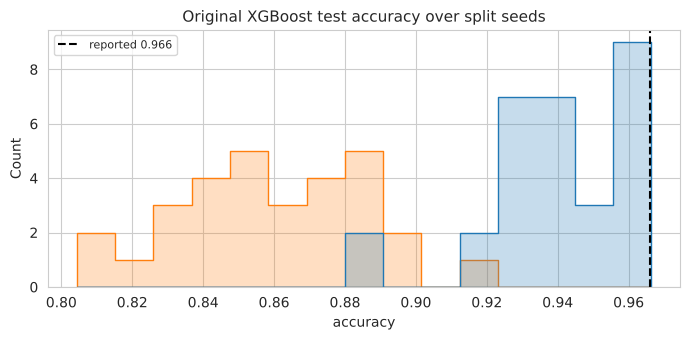

In [21]:
# Variability of the historical protocol across split seeds, compared with a duplicate-aware split of the same size
rows = []
X_all, y_all = original_design_matrix(df)
for s in range(CFG["split_seeds"]):
    for protocol in ["random split (original, leaky)", "group-aware split (duplicates kept together)"]:
        if protocol.startswith("random"):
            itr, ite = train_test_split(np.arange(len(df)), train_size=0.9, random_state=s)
        else:
            itr, ite = grouped_stratified_split(y_all, df["dup_group"], 0.10, s)
            ite = ite[~df.iloc[ite].duplicated(FEATURES + [TARGET]).to_numpy()]    # evaluate unique test patients
        sc = MinMaxScaler().fit(X_all.iloc[itr])
        m = XGBClassifier(**XGB_ORIGINAL).fit(sc.transform(X_all.iloc[itr]), y_all[itr])
        pr = m.predict(sc.transform(X_all.iloc[ite])); scr = scores_of(m, sc.transform(X_all.iloc[ite]))
        rows.append({"seed": s, "protocol": protocol, **compute_metrics(y_all[ite], pr, scr)})
split_study = pd.DataFrame(rows)
summary = split_study.groupby("protocol")[["accuracy", "mcc", "roc_auc"]].agg(["mean", "std", "min", "max"]).round(4)
display(summary)
plt.figure(figsize=(7, 3.5))
sns.histplot(data=split_study, x="accuracy", hue="protocol", bins=15, element="step")
plt.axvline(0.966, color="k", ls="--", label="reported 0.966"); plt.legend(fontsize=8)
plt.title("Original XGBoost test accuracy over split seeds")
savefig("historical_split_seeds")
H1.to_csv(os.path.join(OUT, "historical_H1_reproduction.csv")); H2.to_csv(os.path.join(OUT, "historical_H2_smote_before_split.csv"))
split_study.to_csv(os.path.join(OUT, "historical_split_seed_study.csv"), index=False)

---
## 10. Three-way split (Training / Test / Validation), leakage checks, and leakage ablation

### 10.1 Training 70%, Test 20%, final Validation 10%
The split was assigned once, in Section 6, by `three_way_group_split` (seed 42). Its three roles:

| Dataset | Unique patients | Used for | Never used for |
|---|---|---|---|
| **Training** (70%) | about 642 | fitting, hyperparameter tuning, feature selection, resampling, cross-validation, nested CV, thresholds, SHAP background | nothing is off limits |
| **Test** (20%) | 184 | model comparisons during development; choosing the final model from a pre-declared shortlist (Section 21) | fitting or tuning |
| **Validation** (10%) | about 92 | **one** evaluation of the frozen final model, only when `FINAL_VALIDATION_AUTHORIZED = True` (Section 30) | everything else: no tuning, thresholds, SHAP, feature selection, model selection, EDA or diagnostics |

How the split was built:
* **Unit of splitting.** The 1,190 rows contain 918 unique records. The split is done on duplicate groups (one group = one unique record), stratified by class, so every exact copy lands in the same dataset.
* **Test set.** It is the lowest 20% of the seeded hash ranking within each class. This makes it **identical to the locked test set of the earlier versions**, so earlier results remain comparable.
* **Validation set.** It is the next 10% of the ranking, so it comes from the former training patients. None of these patients was ever scored in a test-set evaluation.
* **Copies.** Each dataset keeps one copy of each record (`KEEP_TRAIN_DUPLICATES = False`); the ablation below measures the effect of keeping copies.

**Protection of the validation set:**
* Its rows go into a `FinalValidationVault` object and are then removed from `df`. Everything after this cell (EDA already excluded them) only sees the development data (training + test).
* The vault has no method that returns features or labels. It can do two things only:
  1. evaluate a frozen model once, if authorised;
  2. answer "is this record one of yours?" with True/False, used only to keep validation patients out of the external-data demonstration (Section 27).
* **Historical reproductions** (Section 9 and the parent-paper protocols on the papers' own files, Section 15) necessarily use the full published datasets, which include these patients. They follow the original protocols, are labelled as leakage-prone where applicable, never evaluate our model, and feed no choice.

In [22]:
KEEP_TRAIN_DUPLICATES = False
train_df, test_df = df[df.split == "train"].copy(), df[df.split == "test"].copy()
val_df = df[df.split == "validation"].copy()
test_df = test_df.drop_duplicates(FEATURES + [TARGET]); val_df = val_df.drop_duplicates(FEATURES + [TARGET])
if not KEEP_TRAIN_DUPLICATES:
    train_df = train_df.drop_duplicates(FEATURES + [TARGET])
X_train, y_train, g_train = train_df[FEATURES].reset_index(drop=True), train_df[TARGET].to_numpy(), train_df["dup_group"].to_numpy()
X_test_raw, y_test = test_df[FEATURES].reset_index(drop=True), test_df[TARGET].to_numpy()
meta_test = test_df[["age", "age_group", "sex", "hospital", "source"]].reset_index(drop=True)
meta_train = train_df[["age", "age_group", "sex", "hospital", "source"]].reset_index(drop=True)

# ---------------- leakage assertions across all three datasets ----------------
parts = {"train": train_df, "test": test_df, "validation": val_df}
for (na, A), (nb, B_) in itertools.combinations(parts.items(), 2):
    assert set(A["dup_group"]).isdisjoint(B_["dup_group"]), f"a duplicate group crosses {na}/{nb}"
    assert set(map(tuple, A[FEATURES].to_numpy())).isdisjoint(map(tuple, B_[FEATURES].to_numpy())), f"identical feature vector in {na} and {nb}"
n_all = df["dup_group"].nunique()
SPLIT_SIZES = pd.DataFrame({"unique patients": {k: len(v) for k, v in parts.items()},
                            "share": {k: len(v) / n_all for k, v in parts.items()},
                            "target share": SPLIT_FRACTIONS,
                            "disease prevalence": {k: v[TARGET].mean() for k, v in parts.items()}})
display(SPLIT_SIZES.round(4))
print(f"Train: {len(X_train)} | Test: {len(y_test)} | Validation: {len(val_df)} unique patients (total {n_all}).")
print("No record, duplicate group or feature vector is shared between any two of the three datasets.  [PASS]")
display(pd.DataFrame({"train records": meta_train.hospital.value_counts(), "test records": meta_test.hospital.value_counts(),
                      "train prevalence": train_df.groupby("hospital")[TARGET].mean().round(3),
                      "test prevalence": test_df.groupby("hospital")[TARGET].mean().round(3)}))

# ---------------- export the three datasets as individual CSV files (archival copies; the notebook never reads them back) ----------------
SPLIT_DIR = os.path.join(OUT, "data_splits"); os.makedirs(SPLIT_DIR, exist_ok=True)
n_copies = df.groupby("dup_group").size().rename("copies_in_1190_row_file")
export_cols = FEATURES + [TARGET, "source", "hospital", "dup_group"]
SPLIT_FILES = {"train": f"train_{len(train_df)}.csv", "test": f"test_{len(test_df)}.csv", "validation": f"validation_{len(val_df)}.csv"}
for k, part in parts.items():
    out_ = part[export_cols].merge(n_copies, left_on="dup_group", right_index=True).rename(columns={"dup_group": "record_id"})
    out_.insert(0, "dataset", k)
    out_.to_csv(os.path.join(SPLIT_DIR, SPLIT_FILES[k]), index=False)
pairs_ = list(itertools.combinations(parts, 2))
SPLIT_SUMMARY = pd.DataFrame([{
    "dataset": k, "file": SPLIT_FILES[k], "unique patients": len(v), "share of 918": round(len(v) / n_all, 4), "target share": SPLIT_FRACTIONS[k],
    "disease (1)": int(v[TARGET].sum()), "no disease (0)": int((v[TARGET] == 0).sum()), "disease prevalence": round(v[TARGET].mean(), 4),
    "rows incl. exact copies (1190-row file)": int(n_copies.loc[v["dup_group"]].sum()),
    **{f"records shared with {b if a == k else a}": len(set(parts[a]["dup_group"]) & set(parts[b]["dup_group"])) for a, b in pairs_ if k in (a, b)},
    **{f"identical feature vectors shared with {b if a == k else a}": len(set(map(tuple, parts[a][FEATURES].to_numpy())) & set(map(tuple, parts[b][FEATURES].to_numpy())))
       for a, b in pairs_ if k in (a, b)},
    "role": {"train": "fitting, preprocessing, feature selection, balancing, tuning, calibration, cross-validation",
             "test": "development comparisons (no tuning on it)",
             "validation": "sealed; evaluated once, only when FINAL_VALIDATION_AUTHORIZED = True"}[k]} for k, v in parts.items()])
SPLIT_SUMMARY.to_csv(os.path.join(SPLIT_DIR, "split_summary.csv"), index=False)
display(SPLIT_SUMMARY.drop(columns=["role"]))
print("Split files written to", SPLIT_DIR, ":", list(SPLIT_FILES.values()) + ["split_summary.csv"])
print("The validation CSV is an archival copy for submission. No later cell reads it; all modelling code sees validation only through VAULT.")
# Consistency with the delivered split files: if data/train_642.csv etc. exist (GitHub layout), the regenerated split must be identical.
# Only record identities are compared (features + label); nothing here is used for modelling.
_cmp = []
for k, fn in SPLIT_FILES.items():
    ref = os.path.join("data", fn)
    if os.path.exists(ref):
        a_ = pd.read_csv(ref)[FEATURES + [TARGET]].astype(float); b_ = parts[k][FEATURES + [TARGET]].astype(float)
        same = sorted(map(tuple, a_.to_numpy())) == sorted(map(tuple, b_.to_numpy()))
        _cmp.append((fn, same)); assert same, f"{fn} differs from the delivered split file"
print("Delivered split files found and identical to this split:" if _cmp else "No delivered split files in data/ to compare against.", _cmp)

class FinalValidationVault:
    """Holds the 10% final-validation set. No method returns its features or labels.
    evaluate() works only when FINAL_VALIDATION_AUTHORIZED is True, and only once per session."""
    def __init__(self, X, y, meta):
        self.__X, self.__y, self.__meta = X.reset_index(drop=True), np.asarray(y), meta.reset_index(drop=True)
        self.n, self.used, self.log = len(self.__y), False, []
    def contains(self, X, cols=None):
        """True/False per row: does this record match a validation patient on `cols`? (identity check only, no labels)"""
        cols = list(FEATURES if cols is None else cols)
        keys = set(map(tuple, np.asarray(self.__X[cols], dtype=float)))
        return np.array([tuple(r) in keys for r in np.asarray(X[cols], dtype=float)])
    def evaluate(self, models, manifest):
        """models: {label: fitted model}, all pre-declared in the frozen manifest. Scored in ONE sealed call."""
        if not FINAL_VALIDATION_AUTHORIZED:
            raise PermissionError("Final validation is locked. Set FINAL_VALIDATION_AUTHORIZED = True only after everything is frozen.")
        if self.used:
            raise PermissionError("The final validation set has already been evaluated once in this session.")
        self.used = True
        out = {label: (np.asarray(f.predict(self.__X)).astype(int), scores_of(f, self.__X)) for label, f in models.items()}
        self.log.append({"time": time.strftime("%Y-%m-%d %H:%M:%S"), "models": list(models), "manifest_sha256": manifest["sha256"]})
        return out, self.__y.copy(), self.__meta.copy()

VAULT = FinalValidationVault(val_df[FEATURES], val_df[TARGET], val_df[["age", "age_group", "sex", "hospital", "source"]])
VAL_GROUPS_SHA = hashlib.sha256(",".join(map(str, sorted(val_df["dup_group"]))).encode()).hexdigest()[:16]   # identifies the split, reveals nothing
df = df[df.split != "validation"].reset_index(drop=True)      # from here on, df = development data (training + test)
del val_df
for _v in ["raw", "block", "stat_rows", "clev_keys", "u_"]:      # helper frames from Section 6 that held all rows
    globals().pop(_v, None)
print(f"Validation set sealed in VAULT ({VAULT.n} patients; split fingerprint {VAL_GROUPS_SHA}). "
      f"FINAL_VALIDATION_AUTHORIZED = {FINAL_VALIDATION_AUTHORIZED}. Development data: {len(df)} rows.")

TEST = LockedTestSet(X_test_raw, y_test, meta_test)
del X_test_raw   # from here on the test features are only reachable through TEST.evaluate()

,unique patients,share,target share,disease prevalence
train,642,0.6993,0.7,0.5530
test,184,0.2004,0.2,0.5543
validation,92,0.1002,0.1,0.5543


Train: 642 | Test: 184 | Validation: 92 unique patients (total 918).
No record, duplicate group or feature vector is shared between any two of the three datasets.  [PASS]


,train records,test records,train prevalence,test prevalence
hospital,,,,
Cleveland,217,56,0.447,0.482
Hungary,203,61,0.369,0.344
Long Beach VA,138,40,0.761,0.725
Switzerland,84,27,0.929,0.926


,dataset,file,unique patients,share of 918,target share,disease (1),no disease (0),disease prevalence,rows incl. exact copies (1190-row file),records shared with test,records shared with validation,identical feature vectors shared with test,identical feature vectors shared with validation,records shared with train,identical feature vectors shared with train
0,train,train_642.csv,642,0.6993,0.7,355,287,0.5530,836,0.0,0.0,0.0,0.0,NaN,NaN
1,test,test_184.csv,184,0.2004,0.2,102,82,0.5543,234,NaN,0.0,NaN,0.0,0.0,0.0
2,validation,validation_92.csv,92,0.1002,0.1,51,41,0.5543,120,0.0,NaN,0.0,NaN,0.0,0.0


Split files written to outputs/data_splits : ['train_642.csv', 'test_184.csv', 'validation_92.csv', 'split_summary.csv']
The validation CSV is an archival copy for submission. No later cell reads it; all modelling code sees validation only through VAULT.
Delivered split files found and identical to this split: [('train_642.csv', True), ('test_184.csv', True), ('validation_92.csv', True)]
Validation set sealed in VAULT (92 patients; split fingerprint a68c32b080aa3548). FINAL_VALIDATION_AUTHORIZED = False. Development data: 1070 rows.


### 10.2 Verifying that resampling and feature selection never see validation or test rows
A "spy" transformer and a "spy" sampler are placed inside a pipeline and run through cross-validation. They record the rows they receive during fitting. The check confirms that (a) every fitted step only saw the training part of each fold, and (b) no test row ever reached any fitting step.

In [23]:
SPY_LOG = {"selector_fit_rows": [], "selector_transform_rows": [], "sampler_rows": [], "raw_rows_seen": set()}
class SpySelector(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        SPY_LOG["selector_fit_rows"].append(len(X)); return self
    def transform(self, X):
        SPY_LOG["selector_transform_rows"].append(len(X)); return X
def spy_raw_sampler(X, y):
    SPY_LOG["sampler_rows"].append(len(X))
    SPY_LOG["raw_rows_seen"].update(map(tuple, np.asarray(X[FEATURES], dtype=float)))
    return X, y

spy_pipe = ImbPipeline([("spy_samp", FunctionSampler(func=spy_raw_sampler, validate=False)),   # sees raw rows during fit
                        ("prep", prep_improved()), ("spy_sel", SpySelector()),
                        ("smote", SMOTE(random_state=SEED)), ("model", LogisticRegression(max_iter=2000))])
cvs = make_cv(CFG["cv_splits"], SEED, g_train)
folds_ = list(cvs.split(X_train, y_train, g_train))
fold_train_sizes = [len(a) for a, _ in folds_]; fold_val_sizes = [len(b) for _, b in folds_]
_ = cross_validate(spy_pipe, X_train, y_train, groups=g_train, cv=cvs, n_jobs=1)
print("Fold training sizes:                 ", fold_train_sizes)
print("Rows seen by selector.fit:           ", SPY_LOG["selector_fit_rows"])
print("Rows seen by the samplers (fit only):", SPY_LOG["sampler_rows"])
print("Fold validation sizes:               ", fold_val_sizes)
assert SPY_LOG["selector_fit_rows"] == fold_train_sizes and SPY_LOG["sampler_rows"] == fold_train_sizes
# validation rows only pass through transform (never fit, never resampled):
assert all(n in SPY_LOG["selector_transform_rows"] for n in fold_val_sizes)
test_rows_raw = set(map(tuple, np.asarray(TEST.raw_features_for_explanation()[FEATURES], dtype=float)))
assert len(SPY_LOG["raw_rows_seen"] & test_rows_raw) == 0
print("Selectors and samplers were fitted only on training-fold rows; validation folds were never resampled; "
      "no test row reached any fitting step.  [PASS]")

Fold training sizes:                  [513, 513, 514, 514, 514]
Rows seen by selector.fit:            [513, 513, 514, 514, 514]
Rows seen by the samplers (fit only): [513, 513, 514, 514, 514]
Fold validation sizes:                [129, 129, 128, 128, 128]
Selectors and samplers were fitted only on training-fold rows; validation folds were never resampled; no test row reached any fitting step.  [PASS]


### 10.3 Leakage ablation: how much of the reported 96.6% is explained by each problem?
The original XGBoost (exact original configuration) is evaluated over many 90/10 splits (seeds 0 to N-1) under five protocols. Only the protocol changes; the model does not. This analysis uses the **development data** (training + test rows); the validation patients are excluded. Protocol A is therefore close to, but not exactly, the 96.6% setting; the exact reproduction on all 1,190 rows is in Section 9.

accuracy              f1  \
                                                       mean     std    mean   
protocol                                                                      
A. Original protocol (random split, duplicates ...   0.9308  0.0206  0.9339   
B. SMOTE on full data before random split (code...   0.9304  0.0302  0.9305   
C. Group-aware split (no duplicate crosses), tr...   0.8486  0.0266  0.8648   
D. C + SMOTE fitted on training data only            0.8542  0.0311  0.8700   
E. C + one copy per record in training (used fr...   0.8510  0.0322  0.8687   

                                                               mcc          \
                                                       std    mean     std   
protocol                                                                     
A. Original protocol (random split, duplicates ...  0.0231  0.8611  0.0424   
B. SMOTE on full data before random split (code...  0.0313  0.8616  0.0599   
C. Group-aware split (no duplicate crosses), tr...  0.0247  0.6946  0.0535   
D. C + SMOTE fitted on training data only           0.0274  0.7062  0.0640   
E. C + one copy per record in training (used fr...  0.0274  0.6992  0.0662   

                                                   roc_auc          recall  \
                                                      mean     std    mean   
protocol                                                                     
A. Original protocol (random split, duplicates ...  0.9676  0.0150  0.9370   
B. SMOTE on full data before random split (code...  0.9649  0.0235  0.9358   
C. Group-aware split (no duplicate crosses), tr...  0.9136  0.0239  0.8754   
D. C + SMOTE fitted on training data only           0.9149  0.0240  0.8804   
E. C + one copy per record in training (used fr...  0.9185  0.0248  0.8884   

                                                           specificity          
                                                       std        mean     std  
protocol                                                                        
A. Original protocol (random split, duplicates ...  0.0362      0.9244  0.0351  
B. SMOTE on full data before random split (code...  0.0331      0.9255  0.0454  
C. Group-aware split (no duplicate crosses), tr...  0.0411      0.8153  0.0477  
D. C + SMOTE fitted on training data only           0.0399      0.8216  0.0570  
E. C + one copy per record in training (used fr...  0.0364      0.8045  0.0597

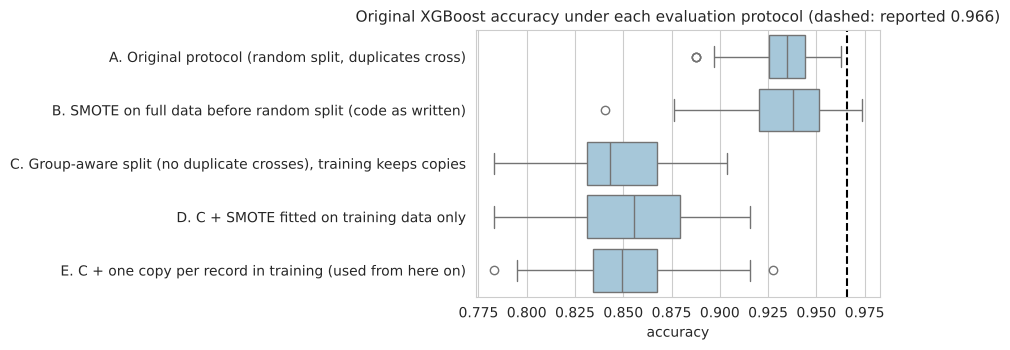

In [24]:
def ablation_protocol(protocol, seed):
    X, y = original_design_matrix(df); groups = df["dup_group"].to_numpy()
    if protocol == "A. Original protocol (random split, duplicates cross)":
        itr, ite = train_test_split(np.arange(len(df)), train_size=0.9, random_state=seed); Xs, ys = X, y
    elif protocol == "B. SMOTE on full data before random split (code as written)":
        Xs, ys = SMOTE(random_state=seed).fit_resample(X, y)
        itr, ite = train_test_split(np.arange(len(ys)), train_size=0.9, random_state=seed)
    else:
        itr, ite = grouped_stratified_split(y, groups, 0.10, seed); Xs, ys = X, y
        ite = ite[~df.iloc[ite].duplicated(FEATURES + [TARGET]).to_numpy()]
        if protocol.startswith("E"):
            itr = itr[~df.iloc[itr].duplicated(FEATURES + [TARGET]).to_numpy()]
    Xtr, ytr, Xte, yte = Xs.iloc[itr], ys[itr], Xs.iloc[ite], ys[ite]
    sc = MinMaxScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    if protocol.startswith("D"):
        Xtr, ytr = SMOTE(random_state=seed).fit_resample(Xtr, ytr)
    m = XGBClassifier(**XGB_ORIGINAL).fit(Xtr, ytr)
    return compute_metrics(yte, m.predict(Xte), scores_of(m, Xte))

PROTOCOLS = ["A. Original protocol (random split, duplicates cross)",
             "B. SMOTE on full data before random split (code as written)",
             "C. Group-aware split (no duplicate crosses), training keeps copies",
             "D. C + SMOTE fitted on training data only",
             "E. C + one copy per record in training (used from here on)"]
abl = pd.DataFrame([{"protocol": p, "seed": s, **ablation_protocol(p, s)} for p in PROTOCOLS for s in range(CFG["split_seeds"])])
ablation = abl.groupby("protocol")[["accuracy", "f1", "mcc", "roc_auc", "recall", "specificity"]].agg(["mean", "std"]).round(4)
display(ablation)
ablation.to_csv(os.path.join(OUT, "leakage_ablation.csv"))
plt.figure(figsize=(9, 3.6))
sns.boxplot(data=abl, y="protocol", x="accuracy", color="#9ecae1"); plt.axvline(0.966, color="k", ls="--")
plt.title("Original XGBoost accuracy under each evaluation protocol (dashed: reported 0.966)"); plt.ylabel("")
savefig("leakage_ablation")

### 10.4 Near-duplicate audit (related records across the split)
Exact duplicates are handled by the grouped split. This check looks for **near**-duplicates: a test patient whose record differs from a training record in only one or two variables, or is extremely close after standardisation. Such pairs could be the same patient recorded twice with a correction, and would leak information. The audit reports how many exist; no record is removed because of it.

In [25]:
Ztr_ = prep_original().fit(X_train).transform(X_train); Zte_ = prep_original().fit(X_train).transform(TEST.raw_features_for_explanation())
nn_ = NearestNeighbors(n_neighbors=1).fit(Ztr_)
dist_, idx_ = nn_.kneighbors(Zte_)
raw_tr = X_train.to_numpy(float); raw_te = TEST.raw_features_for_explanation()[FEATURES].to_numpy(float)
n_diff = (raw_te != raw_tr[idx_[:, 0]]).sum(1)
nd = pd.DataFrame({"variables that differ from the nearest training record": n_diff, "distance": dist_[:, 0],
                   "same label": TEST.y == y_train[idx_[:, 0]]})
display(nd["variables that differ from the nearest training record"].value_counts().sort_index().rename("test patients").to_frame())
near = nd[nd["variables that differ from the nearest training record"] <= 1]
print(f"Test patients differing from their nearest training record in at most one variable: {len(near)} "
      f"({near['same label'].sum()} with the same label). Exact duplicates across the split: {(n_diff == 0).sum()}")
NEAR_DUP_AUDIT = nd

,test patients
variables that differ from the nearest training record,
2,7
3,21
4,81
5,67
6,7
7,1


Test patients differing from their nearest training record in at most one variable: 0 (0 with the same label). Exact duplicates across the split: 0


### 10.5 Role and status of the test set
The previous versions evaluated **62** configurations on this same test set (59 pre-specified comparisons, the CV-selected final model and two references). It had become a "previously viewed" hold-out, which is exactly why the professor's three-way design is useful here:
1. **Test set (20%) = development comparison set.** Tuned models, ensembles, baselines and parent-paper pipelines are compared on it, and the final model is chosen on it from a **pre-declared shortlist** (Section 21). Choosing on the test set makes the winner's test score optimistic, so it is not the final estimate.
2. **Nested cross-validation inside the training set** (Section 20) remains the main evidence on whether the optimisation *procedure* helps. It never touches the test or validation patients.
3. **Validation set (10%) = the unbiased final estimate.** It is evaluated once, for the frozen, pre-declared models only (Section 30).

**Honest caveat.** The validation patients were never scored in any test evaluation. In earlier versions, however, they were part of the training data and of the all-patient nested CV, so some design decisions were made with data that included them. From this version on, nothing reads them. No independent external cohort exists (Section 27).

---
## 11. Corrected baseline: original models and configurations, leakage-free
Same models and hyperparameters as the original project, same MinMax scaling and one-hot encoding (now fitted inside training folds), zeros kept as values (as in the original). The only changes are the evaluation fixes. Results: repeated group-aware stratified CV on the training set, and the test set. This is a **pre-specified** comparison, so all baselines are evaluated on the test set.

Also included: the original pipeline with SMOTE moved **inside the training folds** (the fix for the SMOTE-before-split problem).

In [26]:
STACK_CV = 5 if QUICK else 10
for name, model in original_models(stack_cv=STACK_CV).items():
    pipe = make_pipe(model, prep=prep_original())
    run_cv(name, "Corrected baseline (original configs)", pipe, n_jobs=N_JOBS)
    fit_and_test(name, "Corrected baseline (original configs)", pipe)
pipe = make_pipe(XGBClassifier(**XGB_ORIGINAL), prep=prep_original(), sampler=SMOTE(random_state=SEED))
run_cv("XGBoost (original) + SMOTE inside training folds", "Corrected baseline (original configs)", pipe)
fit_and_test("XGBoost (original) + SMOTE inside training folds", "Corrected baseline (original configs)", pipe)

if HAVE_TF:
    for arch, label in [("fcnn_baseline", "FCNN 72-2 (original)"), ("fcnn_regularised", "FCNN 72-64-24 L1/L2 (original)")]:
        pipe = make_pipe(KerasTabularClassifier(arch, epochs=CFG["nn_epochs"]), prep=prep_original(), cache=False)
        run_cv(label, "Corrected baseline (original configs)", pipe, n_jobs=1)
        fit_and_test(label, "Corrected baseline (original configs)", pipe)

base_tab = cv_table("Corrected baseline (original configs)").merge(
    pd.DataFrame(TEST_RESULTS)[lambda t: t.experiment == "Corrected baseline (original configs)"][["config", "test_accuracy", "test_f1", "test_mcc", "test_roc_auc", "test_recall", "test_specificity"]],
    on="config", how="left")
display(base_tab[["config", "cv_accuracy", "cv_f1", "cv_mcc", "cv_mcc_sd", "cv_roc_auc", "test_accuracy", "test_f1", "test_mcc", "test_roc_auc", "test_recall", "test_specificity"]].round(3))

[Corrected baseline (original configs)] Dummy (stratified)                                      CV acc 0.505  F1 0.563  MCC -0.008+/-0.085  AUC 0.496  (1.9s)
  TEST Dummy (stratified)                                 acc 0.533  F1 0.594  MCC 0.045  AUC 0.522  sens 0.618  spec 0.427


[Corrected baseline (original configs)] Logistic Regression                                     CV acc 0.856  F1 0.873  MCC 0.709+/-0.075  AUC 0.918  (0.2s)
  TEST Logistic Regression                                acc 0.864  F1 0.877  MCC 0.725  AUC 0.937  sens 0.873  spec 0.854


[Corrected baseline (original configs)] Decision Tree (depth 6)                                 CV acc 0.809  F1 0.828  MCC 0.615+/-0.070  AUC 0.812  (0.2s)
  TEST Decision Tree (depth 6)                            acc 0.842  F1 0.857  MCC 0.681  AUC 0.837  sens 0.853  spec 0.829


[Corrected baseline (original configs)] Random Forest (10 trees, entropy)                       CV acc 0.835  F1 0.850  MCC 0.668+/-0.083  AUC 0.899  (0.3s)
  TEST Random Forest (10 trees, entropy)                  acc 0.859  F1 0.870  MCC 0.716  AUC 0.918  sens 0.853  spec 0.866


[Corrected baseline (original configs)] XGBoost (original)                                      CV acc 0.841  F1 0.860  MCC 0.680+/-0.089  AUC 0.911  (0.6s)
  TEST XGBoost (original)                                 acc 0.837  F1 0.847  MCC 0.676  AUC 0.922  sens 0.814  spec 0.866


[Corrected baseline (original configs)] SVM (poly, degree 3)                                    CV acc 0.844  F1 0.861  MCC 0.685+/-0.073  AUC 0.901  (0.3s)
  TEST SVM (poly, degree 3)                               acc 0.859  F1 0.871  MCC 0.715  AUC 0.900  sens 0.863  spec 0.854


... (7 outputs left out)

  TEST FCNN 72-2 (original)                               acc 0.853  F1 0.866  MCC 0.704  AUC 0.935  sens 0.853  spec 0.854


[Corrected baseline (original configs)] FCNN 72-64-24 L1/L2 (original)                          CV acc 0.855  F1 0.871  MCC 0.707+/-0.068  AUC 0.917  (297.9s)


  TEST FCNN 72-64-24 L1/L2 (original)                     acc 0.859  F1 0.873  MCC 0.714  AUC 0.931  sens 0.873  spec 0.841


,config,cv_accuracy,cv_f1,cv_mcc,cv_mcc_sd,cv_roc_auc,test_accuracy,test_f1,test_mcc,test_roc_auc,test_recall,test_specificity
0,FCNN 72-2 (original),0.858,0.873,0.714,0.073,0.917,0.853,0.866,0.704,0.935,0.853,0.854
1,"Stacking (6 models, MLP meta)",0.857,0.875,0.711,0.083,0.919,0.853,0.867,0.703,0.935,0.863,0.841
2,Logistic Regression,0.856,0.873,0.709,0.075,0.918,0.864,0.877,0.725,0.937,0.873,0.854
3,FCNN 72-64-24 L1/L2 (original),0.855,0.871,0.707,0.068,0.917,0.859,0.873,0.714,0.931,0.873,0.841
4,"Stacking (RF + XGB, MLP meta)",0.846,0.866,0.689,0.094,0.911,0.842,0.857,0.681,0.923,0.853,0.829
5,"SVM (poly, degree 3)",0.844,0.861,0.685,0.073,0.901,0.859,0.871,0.715,0.900,0.863,0.854
6,XGBoost (original) + SMOTE inside training folds,0.843,0.860,0.684,0.087,0.909,0.864,0.874,0.728,0.930,0.853,0.878
7,XGBoost (original),0.841,0.860,0.680,0.089,0.911,0.837,0.847,0.676,0.922,0.814,0.866
8,"Random Forest (10 trees, entropy)",0.835,0.850,0.668,0.083,0.899,0.859,0.870,0.716,0.918,0.853,0.866
9,KNN (k=3),0.831,0.850,0.659,0.074,0.867,0.853,0.867,0.703,0.900,0.863,0.841


### 11.1 Preprocessing comparison (CV only)
Effect of treating impossible zeros as missing values, and of the imputation methods named by the papers (median; mean, P3; similar-patient KNN imputation, P1), with the original XGBoost and logistic regression.

In [27]:
PREPS = {"Original (MinMax, zeros as values)": prep_original,
         "Zeros -> NaN, median + indicator, z-score": lambda: prep_improved("median"),
         "Zeros -> NaN, mean + indicator (P3)": lambda: prep_improved("mean"),
         "Zeros -> NaN, KNN similar-patient imputation (P1)": lambda: prep_improved("knn"),
         "Zeros -> NaN, median, no indicator": lambda: make_preprocessor(indicator=False)}
for pname, pf in PREPS.items():
    for mname, model in [("XGBoost (original)", XGBClassifier(**XGB_ORIGINAL)), ("LR", LogisticRegression(max_iter=2000))]:
        run_cv(f"{mname} | {pname}", "Preprocessing", make_pipe(model, prep=pf()), model=mname, preprocessing=pname)
display(cv_table("Preprocessing")[["model", "preprocessing", "cv_accuracy", "cv_f1", "cv_mcc", "cv_roc_auc"]].round(3))

[Preprocessing] XGBoost (original) | Original (MinMax, zeros as values) CV acc 0.841  F1 0.860  MCC 0.680+/-0.089  AUC 0.911  (2.2s)


[Preprocessing] LR | Original (MinMax, zeros as values)                 CV acc 0.856  F1 0.873  MCC 0.709+/-0.075  AUC 0.918  (0.3s)


[Preprocessing] XGBoost (original) | Zeros -> NaN, median + indicator, z-score CV acc 0.848  F1 0.865  MCC 0.693+/-0.085  AUC 0.910  (1.2s)


[Preprocessing] LR | Zeros -> NaN, median + indicator, z-score          CV acc 0.860  F1 0.876  MCC 0.717+/-0.084  AUC 0.919  (0.2s)


[Preprocessing] XGBoost (original) | Zeros -> NaN, mean + indicator (P3) CV acc 0.843  F1 0.860  MCC 0.682+/-0.081  AUC 0.909  (1.0s)


[Preprocessing] LR | Zeros -> NaN, mean + indicator (P3)                CV acc 0.860  F1 0.876  MCC 0.717+/-0.084  AUC 0.919  (0.2s)


[Preprocessing] XGBoost (original) | Zeros -> NaN, KNN similar-patient imputation (P1) CV acc 0.850  F1 0.866  MCC 0.696+/-0.075  AUC 0.914  (1.3s)


[Preprocessing] LR | Zeros -> NaN, KNN similar-patient imputation (P1)  CV acc 0.861  F1 0.877  MCC 0.720+/-0.088  AUC 0.918  (0.3s)


[Preprocessing] XGBoost (original) | Zeros -> NaN, median, no indicator CV acc 0.847  F1 0.864  MCC 0.690+/-0.087  AUC 0.904  (1.1s)


[Preprocessing] LR | Zeros -> NaN, median, no indicator                 CV acc 0.849  F1 0.865  MCC 0.695+/-0.094  AUC 0.914  (0.3s)


,model,preprocessing,cv_accuracy,cv_f1,cv_mcc,cv_roc_auc
0,LR,"Zeros -> NaN, KNN similar-patient imputation (P1)",0.861,0.877,0.720,0.918
1,LR,"Zeros -> NaN, median + indicator, z-score",0.860,0.876,0.717,0.919
2,LR,"Zeros -> NaN, mean + indicator (P3)",0.860,0.876,0.717,0.919
3,LR,"Original (MinMax, zeros as values)",0.856,0.873,0.709,0.918
4,XGBoost (original),"Zeros -> NaN, KNN similar-patient imputation (P1)",0.850,0.866,0.696,0.914
5,LR,"Zeros -> NaN, median, no indicator",0.849,0.865,0.695,0.914
6,XGBoost (original),"Zeros -> NaN, median + indicator, z-score",0.848,0.865,0.693,0.910
7,XGBoost (original),"Zeros -> NaN, median, no indicator",0.847,0.864,0.690,0.904
8,XGBoost (original),"Zeros -> NaN, mean + indicator (P3)",0.843,0.860,0.682,0.909
9,XGBoost (original),"Original (MinMax, zeros as values)",0.841,0.860,0.680,0.911


---
## 12. Class-balancing comparison (training CV only)
Twelve balancing options x five reference models (no resampling, class weights, ROS, RUS, SMOTE, SMOTE-NC, SMOTE-ENN, SMOTE-Tomek, ADASYN, cluster centroids, P1 USCOM interpretation, P1 UCOM literal), with the improved preprocessing and no feature selection. Balancing is fitted only on the training part of each fold. The classes are already close to balanced (about 55% / 45% in training), so large gains are not expected. **The test set is not used here.**

model,KNN-15,LR,RF,SVM-RBF,XGB,mean over models
sampler,,,,,,
Class weights,NaN,0.715,0.710,0.725,0.713,0.716
RUS,0.684,0.716,0.720,0.736,0.713,0.714
None,0.700,0.717,0.718,0.732,0.702,0.713
SMOTE-Tomek,0.688,0.719,0.719,0.729,0.697,0.710
ROS,0.676,0.722,0.713,0.734,0.698,0.708
SMOTE,0.680,0.719,0.710,0.725,0.695,0.706
Cluster centroids (undersampling),0.673,0.711,0.711,0.727,0.697,0.704
USCOM (P1 interpretation),0.672,0.712,0.716,0.724,0.682,0.701
UCOM literal (P1: keep 2/3 of majority),0.691,0.707,0.713,0.715,0.676,0.700


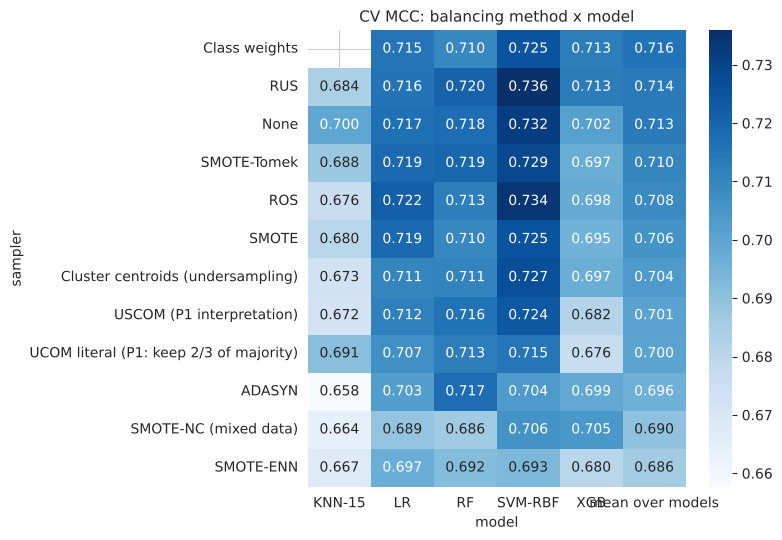

,model,sampler,cv_accuracy,cv_recall,cv_specificity,cv_f1,cv_mcc,cv_roc_auc
0,SVM-RBF,RUS,0.869,0.900,0.831,0.884,0.736,0.911
1,SVM-RBF,ROS,0.868,0.900,0.829,0.883,0.734,0.912
2,SVM-RBF,None,0.867,0.910,0.814,0.883,0.732,0.911
3,SVM-RBF,SMOTE-Tomek,0.865,0.903,0.819,0.881,0.729,0.911
4,SVM-RBF,Cluster centroids (undersampling),0.864,0.901,0.819,0.880,0.727,0.911
5,SVM-RBF,Class weights,0.864,0.896,0.824,0.879,0.725,0.911
6,SVM-RBF,SMOTE,0.864,0.897,0.822,0.879,0.725,0.911
7,SVM-RBF,USCOM (P1 interpretation),0.863,0.897,0.820,0.878,0.724,0.910
8,LR,ROS,0.862,0.880,0.840,0.876,0.722,0.919
9,RF,RUS,0.861,0.890,0.826,0.876,0.720,0.919


In [28]:
ALL_SAMPLERS = {**make_samplers(), **make_samplers_extra()}
for sname, sampler in tqdm(list(ALL_SAMPLERS.items()), desc="balancing methods"):
    for mname, model in reference_models().items():
        run_cv(f"{mname} | {sname}", "Balancing", make_pipe(model, sampler=clone(sampler) if sampler is not None else None),
               model=mname, sampler=sname, verbose=False)
for mname in reference_models():
    m = class_weighted(mname)
    if m is not None:
        run_cv(f"{mname} | Class weights", "Balancing", make_pipe(m), model=mname, sampler="Class weights", verbose=False)
    run_cv(f"{mname} | SMOTE-NC (mixed data)", "Balancing", smotenc_pipe(reference_models()[mname]), model=mname,
           sampler="SMOTE-NC (mixed data)", verbose=False)
bal = cv_table("Balancing")
piv_bal = bal.pivot(index="sampler", columns="model", values="cv_mcc")
piv_bal["mean over models"] = piv_bal.mean(axis=1)
display(piv_bal.sort_values("mean over models", ascending=False).round(3))
plt.figure(figsize=(8, 5.5)); sns.heatmap(piv_bal.sort_values("mean over models", ascending=False), annot=True, fmt=".3f", cmap="Blues")
plt.title("CV MCC: balancing method x model"); savefig("balancing_heatmap")
display(bal[["model", "sampler", "cv_accuracy", "cv_recall", "cv_specificity", "cv_f1", "cv_mcc", "cv_roc_auc"]].head(10).round(3))

---
## 13. Feature-selection comparison (training CV only)
Twelve options (none, the original low-variance filter, ANOVA, mutual information, RFE, RFECV, L1 logistic, tree importance, sequential forward selection, symmetric uncertainty, GA, GA + RFE) x five reference models, improved preprocessing, no balancing. Every selector is refitted inside every training fold. The GA runs once per fold and its result is cached and shared by all models and by the GA + RFE pipeline. **The test set is not used here.**

done: None                                          (4s elapsed)


done: Variance threshold 0.006 (original)           (9s elapsed)


done: ANOVA F-test (k=10)                           (13s elapsed)


done: Mutual information (k=10)                     (18s elapsed)


done: RFE-LR (k=10)                                 (21s elapsed)


done: Symmetric uncertainty (P3 EG-HFS)             (25s elapsed)


... (3 outputs left out)

done: Tree importance (Extra Trees, median)         (77s elapsed)


done: Sequential forward (LR, k=10)                 (89s elapsed)


done: RFECV (LR)                                    (93s elapsed)


model,KNN-15,LR,RF,SVM-RBF,XGB,mean over models
selector,,,,,,
Variance threshold 0.006 (original),0.700,0.717,0.718,0.732,0.702,0.713
None,0.700,0.717,0.718,0.732,0.702,0.713
RFECV (LR),0.725,0.703,0.711,0.711,0.696,0.709
RFE-LR (k=10),0.714,0.704,0.681,0.727,0.696,0.704
GA + RFE (P1 hybrid),0.708,0.711,0.678,0.724,0.695,0.703
ANOVA F-test (k=10),0.706,0.722,0.681,0.713,0.673,0.699
L1 logistic (SelectFromModel),0.683,0.720,0.686,0.710,0.681,0.696
Genetic algorithm (P1),0.690,0.704,0.681,0.712,0.692,0.696
"Tree importance (Extra Trees, median)",0.668,0.685,0.700,0.685,0.680,0.683


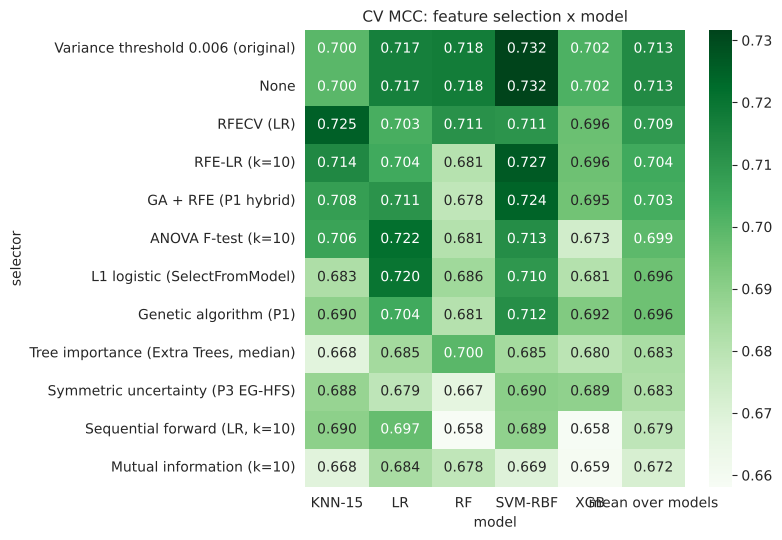

In [29]:
t_fs = time.time()
ALL_SELECTORS = {**make_selectors(), **make_selectors_extra()}
for fsname, sel in tqdm(list(ALL_SELECTORS.items()), desc="feature selectors"):
    for mname, model in reference_models().items():
        run_cv(f"{mname} | {fsname}", "Feature selection", make_pipe(model, selectors=[clone(s) for s in sel]),
               model=mname, selector=fsname, verbose=False)
    print(f"done: {fsname:<45s} ({time.time() - t_fs:.0f}s elapsed)")
fs = cv_table("Feature selection")
piv_fs = fs.pivot(index="selector", columns="model", values="cv_mcc"); piv_fs["mean over models"] = piv_fs.mean(axis=1)
display(piv_fs.sort_values("mean over models", ascending=False).round(3))
plt.figure(figsize=(8, 5.5)); sns.heatmap(piv_fs.sort_values("mean over models", ascending=False), annot=True, fmt=".3f", cmap="Greens")
plt.title("CV MCC: feature selection x model"); savefig("feature_selection_heatmap")

### 13.1 Which features does each method select? (selection stability across CV folds)
Each selector is fitted on the training part of every CV fold; the table shows how often each encoded feature was kept. Stable selectors keep the same features in every fold.

In [30]:
feat_names = prep_improved().fit(X_train, y_train).get_feature_names_out()
@MEMORY.cache
def _support_of(selector, Z, y):
    return clone(selector).fit(Z, y).get_support()
freq = {}
cvs = make_cv(CFG["cv_splits"], SEED, g_train)
for fsname, sel in ALL_SELECTORS.items():
    if not sel:
        continue
    masks = []
    for tr, _ in cvs.split(X_train, y_train, g_train):
        p = prep_improved().fit(X_train.iloc[tr], y_train[tr])
        Z = p.transform(X_train.iloc[tr]); names = p.get_feature_names_out(); keep = np.ones(Z.shape[1], bool)
        cur = Z
        for s in sel:
            sup = _support_of(s, cur, y_train[tr]); idx = np.flatnonzero(keep); keep[idx[~sup]] = False; cur = cur[:, sup]
        masks.append(pd.Series(keep, index=names))
    freq[fsname] = pd.concat(masks, axis=1).mean(axis=1)
sel_freq = pd.DataFrame(freq).fillna(0)
display(sel_freq.round(2))
sel_freq.to_csv(os.path.join(OUT, "feature_selection_frequency.csv"))
su_full = SymmetricUncertaintySelector().fit(prep_improved().fit(X_train, y_train).transform(X_train), y_train)
su_scores = pd.Series(su_full.scores_, index=feat_names).sort_values(ascending=False).rename("symmetric uncertainty (training set)")
display(su_scores.round(4).to_frame())
su_scores.to_csv(os.path.join(OUT, "p3_symmetric_uncertainty_scores.csv"))

,Variance threshold 0.006 (original),ANOVA F-test (k=10),Mutual information (k=10),RFE-LR (k=10),Symmetric uncertainty (P3 EG-HFS),Genetic algorithm (P1),GA + RFE (P1 hybrid),L1 logistic (SelectFromModel),"Tree importance (Extra Trees, median)","Sequential forward (LR, k=10)",RFECV (LR)
age,1.0,1.0,0.4,0.2,0.0,0.2,0.2,0.8,1.0,0.2,0.2
resting bp s,1.0,0.0,0.2,0.2,0.0,0.2,0.2,0.8,1.0,0.2,0.2
cholesterol,1.0,0.0,1.0,0.0,0.0,0.2,0.0,0.0,1.0,0.4,0.0
max heart rate,1.0,1.0,1.0,0.2,0.0,0.0,0.0,1.0,1.0,0.0,0.2
oldpeak,1.0,1.0,0.8,0.8,0.8,0.8,0.8,1.0,1.0,0.8,0.6
missingindicator_cholesterol,1.0,1.0,0.8,1.0,0.8,1.0,1.0,1.0,1.0,1.0,1.0
sex,1.0,0.8,0.2,1.0,0.0,1.0,1.0,1.0,0.0,0.8,1.0
fasting blood sugar,1.0,0.2,0.2,1.0,0.0,1.0,1.0,1.0,0.0,0.6,1.0
exercise angina,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.4,1.0
chest pain type_1,1.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.2,0.2


,symmetric uncertainty (training set)
ST slope_1,0.3009
ST slope_2,0.2345
chest pain type_4,0.1879
exercise angina,0.1669
chest pain type_2,0.1348
missingindicator_cholesterol,0.0843
oldpeak,0.0822
sex,0.0673
max heart rate,0.0639
fasting blood sugar,0.0535


### 13.2 P3 EG-HFS: the threshold `th`
P3's Algorithm 2 keeps a feature when its symmetric uncertainty is **strictly greater** than a threshold `th`, but the value of `th` is not reported. The paper, its abstract and the publisher's page give no supplementary material or code (searched November 2026). Instead of guessing, the threshold is treated as a hyperparameter: a grid of `th` values is evaluated by training CV for P3's classifiers. The table also shows how many features each threshold keeps on the full training set.

In [31]:
su_vals = np.sort(su_full.scores_)
TH_GRID = [0.0] + list(np.round(np.quantile(su_vals, [0.25, 0.5, 0.75]), 4)) + [round(float(su_vals.mean()), 4)]
th_rows = []
for th in tqdm(TH_GRID, desc="EG-HFS thresholds"):
    n_keep = int((su_full.scores_ > th).sum())
    for mname in ["Random Forest", "Logistic Regression", "Gradient Boosting"]:
        pipe = make_pipe(p3_models()[mname], prep=prep_improved("mean"), selectors=[SymmetricUncertaintySelector(threshold=th, strict=True)])
        r = run_cv(f"P3 {mname} | EG-HFS th={th}", "P3 EG-HFS threshold", pipe, model=mname, th=th, verbose=False)
        th_rows.append({"th": th, "features kept (full training set)": n_keep, "model": mname, "cv_accuracy": r["cv_accuracy"], "cv_mcc": r["cv_mcc"]})
TH_TABLE = pd.DataFrame(th_rows)
display(TH_TABLE.pivot_table(index=["th", "features kept (full training set)"], columns="model", values="cv_mcc").round(3))

,model,Gradient Boosting,Logistic Regression,Random Forest
th,features kept (full training set),,,
0.0000,19,0.708,0.717,0.713
0.0173,14,0.704,0.726,0.701
0.0535,10,0.697,0.717,0.681
0.0811,7,0.676,0.679,0.665
0.1096,5,0.667,0.675,0.667


---
## 14. Feature engineering (training CV only)
Can new variables built from the existing measurements help? Four representations are compared with five models:
* **Original**: the 11 variables, zeros treated as missing, z-scored and one-hot encoded (the improved preprocessing).
* **Clinical derived features** (`ClinicalFeatures`, all computed row by row, so nothing is learned from other patients):
  * `hr_pct_pred` = max heart rate / (220 - age), the share of age-predicted maximal heart rate reached during exercise. A low value (chronotropic incompetence) is an established adverse sign in exercise testing.
  * `age_x_maxhr`: the age by max heart rate interaction asked for in the brief.
  * `oldpeak_pos`: any ST depression.
  * `st_abn_x_oldpeak`: ST depression on a flat or down-sloping segment, the combination read as ischaemic in exercise ECG interpretation.
  * `exang_x_oldpeak`: exercise angina combined with ST depression.
  * `asymptomatic_cp`: asymptomatic chest-pain type, as a single flag.
* **Polynomial (degree 2)** and **spline** expansions of the numeric variables: generic nonlinear transformations with no clinical assumptions.

No variable is created from the outcome, and no cut-off is learned from the data.

model,LGBM,LR,RF,SVM-RBF,XGB,mean over models
representation,,,,,,
Original (improved prep),0.708,0.717,0.718,0.732,0.702,0.715
Splines (numeric),0.699,0.715,0.707,0.709,0.709,0.708
Clinical derived features,0.687,0.714,0.708,0.721,0.695,0.705
Polynomial degree 2 (numeric),0.675,0.709,0.695,0.701,0.671,0.690


model,LGBM,LR,RF,SVM-RBF,XGB
representation,,,,,
Clinical derived features,0.845,0.858,0.855,0.861,0.849
Original (improved prep),0.855,0.860,0.860,0.867,0.852
Polynomial degree 2 (numeric),0.839,0.856,0.848,0.851,0.836
Splines (numeric),0.850,0.859,0.854,0.856,0.855


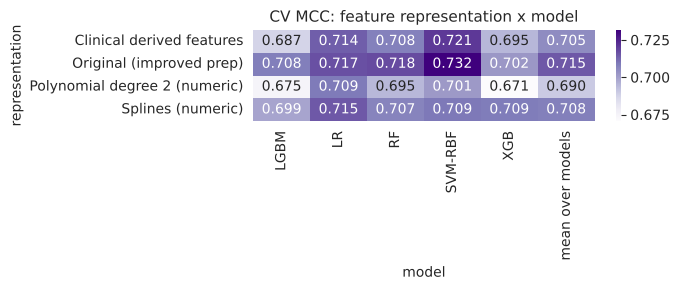

,mean (no disease),mean (disease),univariate AUC
hr_pct_pred,0.878,0.781,0.293
age_x_maxhr,7.402,7.103,0.437
oldpeak_pos,0.415,0.730,0.657
st_abn_x_oldpeak,0.287,1.116,0.726
exang_x_oldpeak,0.137,0.903,0.709
asymptomatic_cp,0.258,0.758,0.750


In [32]:
FE_PREPS = {"Original (improved prep)": lambda: prep_improved(), "Clinical derived features": lambda: prep_fe("clinical"),
            "Polynomial degree 2 (numeric)": lambda: prep_fe("poly"), "Splines (numeric)": lambda: prep_fe("spline")}
FE_MODELS = {"LR": lambda: LogisticRegression(max_iter=5000, random_state=SEED), "RF": lambda: reference_models()["RF"],
             "XGB": lambda: reference_models()["XGB"], "LGBM": lambda: extra_models()["LGBM"], "SVM-RBF": lambda: reference_models()["SVM-RBF"]}
for fname, pf in tqdm(list(FE_PREPS.items()), desc="feature representations"):
    for mname, mf in FE_MODELS.items():
        run_cv(f"{mname} | {fname}", "Feature engineering", make_pipe(mf(), prep=pf()), model=mname, representation=fname, verbose=False)
fe_tab = cv_table("Feature engineering")
piv_fe = fe_tab.pivot(index="representation", columns="model", values="cv_mcc"); piv_fe["mean over models"] = piv_fe.mean(axis=1)
display(piv_fe.sort_values("mean over models", ascending=False).round(3))
display(fe_tab.pivot(index="representation", columns="model", values="cv_accuracy").round(3))
plt.figure(figsize=(7, 3)); sns.heatmap(piv_fe, annot=True, fmt=".3f", cmap="Purples"); plt.title("CV MCC: feature representation x model")
savefig("feature_engineering_heatmap")

# How informative are the derived variables on their own? (training data, descriptive)
fe_check = ClinicalFeatures().fit(X_train).transform(X_train)
fe_desc = pd.DataFrame({f: [fe_check.loc[y_train == 0, f].mean(), fe_check.loc[y_train == 1, f].mean(),
                            roc_auc_score(y_train, fe_check[f].fillna(fe_check[f].median()))] for f in ClinicalFeatures.NEW},
                       index=["mean (no disease)", "mean (disease)", "univariate AUC"]).T
display(fe_desc.round(3))

---
## 15. Parent-paper protocols
Two kinds of experiment are kept strictly apart here:
* **Corrected protocols (15.1a, 15.2, 15.3).** Each paper's pipeline, fitted on our 70% training set with every step inside training folds, and compared on the 20% test set.
* **Historical / original-protocol reproductions (15.1b, 15.2c, 15.3b).** These run on the papers' *own* datasets (UCI Cleveland-303, P2's published augmented files and test sets), with the papers' own evaluation protocols, so that results similar to the published ones can be demonstrated. Where the protocol leaks (P2's CV on duplicated data), this is **labelled LEAKAGE-PRONE** and the leak is measured. These datasets contain patients that are also in our validation set. That is unavoidable when reproducing a published protocol, but these runs never evaluate our model, and none of their results feeds any choice in our pipeline.

Approximations are labelled.

### 15.1a P1 (Al-Alshaikh et al.) on the comprehensive dataset
Similar-patient (KNN) imputation, z-scaling, **GA + RFE** feature selection, **USCOM** (or SMOTE) balancing, then P1's conventional classifiers. The MLDCNN is in Section 16.

[P1 protocol] P1 SVM | GA+RFE | USCOM                                 CV acc 0.857  F1 0.874  MCC 0.712+/-0.063  AUC 0.913  (30.9s)


  TEST P1 SVM | GA+RFE | USCOM                            acc 0.875  F1 0.887  MCC 0.747  AUC 0.932  sens 0.882  spec 0.866


[P1 protocol] P1 SVM | GA+RFE | SMOTE                                 CV acc 0.857  F1 0.874  MCC 0.712+/-0.080  AUC 0.913  (0.3s)
  TEST P1 SVM | GA+RFE | SMOTE                            acc 0.875  F1 0.887  MCC 0.747  AUC 0.933  sens 0.882  spec 0.866


[P1 protocol] P1 LDA | GA+RFE | USCOM                                 CV acc 0.855  F1 0.871  MCC 0.707+/-0.063  AUC 0.919  (0.3s)
  TEST P1 LDA | GA+RFE | USCOM                            acc 0.859  F1 0.873  MCC 0.714  AUC 0.948  sens 0.873  spec 0.841


[P1 protocol] P1 LDA | GA+RFE | SMOTE                                 CV acc 0.855  F1 0.871  MCC 0.707+/-0.063  AUC 0.919  (0.3s)
  TEST P1 LDA | GA+RFE | SMOTE                            acc 0.870  F1 0.882  MCC 0.736  AUC 0.947  sens 0.882  spec 0.854


[P1 protocol] P1 Naive Bayes | GA+RFE | USCOM                         CV acc 0.839  F1 0.855  MCC 0.675+/-0.093  AUC 0.900  (0.3s)
  TEST P1 Naive Bayes | GA+RFE | USCOM                    acc 0.853  F1 0.864  MCC 0.706  AUC 0.929  sens 0.843  spec 0.866


... (3 outputs left out)

[P1 protocol] P1 Random Forest | GA+RFE | USCOM                       CV acc 0.836  F1 0.852  MCC 0.671+/-0.090  AUC 0.903  (1.1s)
  TEST P1 Random Forest | GA+RFE | USCOM                  acc 0.853  F1 0.864  MCC 0.706  AUC 0.943  sens 0.843  spec 0.866


[P1 protocol] P1 Random Forest | GA+RFE | SMOTE                       CV acc 0.839  F1 0.856  MCC 0.675+/-0.106  AUC 0.904  (1.0s)
  TEST P1 Random Forest | GA+RFE | SMOTE                  acc 0.875  F1 0.887  MCC 0.747  AUC 0.935  sens 0.882  spec 0.866


[P1 protocol] P1 PCA + LR | GA+RFE | USCOM                            CV acc 0.860  F1 0.873  MCC 0.717+/-0.072  AUC 0.918  (0.3s)
  TEST P1 PCA + LR | GA+RFE | USCOM                       acc 0.886  F1 0.898  MCC 0.769  AUC 0.945  sens 0.902  spec 0.866


[P1 protocol] P1 PCA + LR | GA+RFE | SMOTE                            CV acc 0.863  F1 0.877  MCC 0.723+/-0.071  AUC 0.918  (0.3s)
  TEST P1 PCA + LR | GA+RFE | SMOTE                       acc 0.886  F1 0.898  MCC 0.769  AUC 0.948  sens 0.902  spec 0.866
GA selected (fit on the whole training set): ['oldpeak', 'missingindicator_cholesterol', 'sex', 'fasting blood sugar', 'exercise angina', 'chest pain type_1', 'chest pain type_4', 'ST slope_2', 'ST slope_3']
GA + RFE selected: ['oldpeak', 'missingindicator_cholesterol', 'sex', 'fasting blood sugar', 'exercise angina', 'chest pain type_4', 'ST slope_2', 'ST slope_3']
GA evaluations: 499, best out-of-fold MSE 0.1036


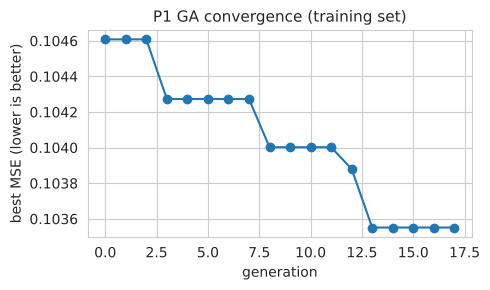

,config,train_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_specificity,test_fpr
0,P1 SVM | GA+RFE | USCOM,0.886,0.875,0.891,0.882,0.887,0.866,0.134
1,P1 SVM | GA+RFE | SMOTE,0.889,0.875,0.891,0.882,0.887,0.866,0.134
2,P1 LDA | GA+RFE | USCOM,0.857,0.859,0.873,0.873,0.873,0.841,0.159
3,P1 LDA | GA+RFE | SMOTE,0.869,0.870,0.882,0.882,0.882,0.854,0.146
4,P1 Naive Bayes | GA+RFE | USCOM,0.841,0.853,0.887,0.843,0.864,0.866,0.134
5,P1 Naive Bayes | GA+RFE | SMOTE,0.844,0.853,0.895,0.833,0.863,0.878,0.122
6,P1 Decision Tree | GA+RFE | USCOM,0.927,0.864,0.905,0.843,0.873,0.890,0.110
7,P1 Decision Tree | GA+RFE | SMOTE,0.928,0.859,0.904,0.833,0.867,0.890,0.110
8,P1 Random Forest | GA+RFE | USCOM,0.928,0.853,0.887,0.843,0.864,0.866,0.134
9,P1 Random Forest | GA+RFE | SMOTE,0.928,0.875,0.891,0.882,0.887,0.866,0.134


In [33]:
def train_metrics(fitted, X=None, y=None):
    X = X_train if X is None else X; y = y_train if y is None else y
    return compute_metrics(y, fitted.predict(X), scores_of(fitted, X))

P1_ROWS = []
for name, model in p1_models().items():
    for bname, sampler in [("USCOM", make_samplers()["USCOM (P1 interpretation)"]), ("SMOTE", SMOTE(random_state=SEED))]:
        label = f"P1 {name} | GA+RFE | {bname}"
        pipe = make_pipe(model, prep=prep_improved("knn"), selectors=[ga_selector(), rfecv_selector()], sampler=sampler)
        run_cv(label, "P1 protocol", pipe, model=name, sampler=bname)
        fitted, m, _, _ = fit_and_test(label, "P1 protocol", pipe)
        tm = train_metrics(fitted)
        P1_ROWS.append({"config": label, "train_accuracy": tm["accuracy"], "test_accuracy": m["accuracy"],
                        "test_precision": m["precision"], "test_recall": m["recall"], "test_f1": m["f1"],
                        "test_specificity": m["specificity"], "test_fpr": 1 - m["specificity"]})
ga_fit = fitted.named_steps["select0"]
names_ = fitted.named_steps["prep"].get_feature_names_out()
ga_names = names_[ga_fit.get_support()]
print("GA selected (fit on the whole training set):", list(ga_names))
print("GA + RFE selected:", list(ga_names[fitted.named_steps["select1"].get_support()]))
print(f"GA evaluations: {ga_fit.n_evaluations_}, best out-of-fold MSE {ga_fit.best_fitness_:.4f}")
plt.figure(figsize=(5, 3)); plt.plot(ga_fit.history_, marker="o"); plt.xlabel("generation"); plt.ylabel("best MSE (lower is better)")
plt.title("P1 GA convergence (training set)"); savefig("p1_ga_convergence")
display(pd.DataFrame(P1_ROWS).round(3))

#### P1 with the literal UCOM (training CV only)
The same P1 pipeline, with UCOM read literally: two-thirds of the majority class is kept (the ratio P1 states), the minority class is clustered, and SMOTE equalises the classes. In our training data the classes are close to balanced, so keeping two-thirds of the majority makes it the smaller class; SMOTE then oversamples it back.

In [34]:
for name in ["SVM", "LDA", "PCA + LR", "Random Forest"]:
    pipe = make_pipe(p1_models()[name], prep=prep_improved("knn"), selectors=[ga_selector(), rfecv_selector()],
                     sampler=make_samplers_extra()["UCOM literal (P1: keep 2/3 of majority)"])
    run_cv(f"P1 {name} | GA+RFE | UCOM literal", "P1 protocol (UCOM literal)", pipe, model=name)
display(cv_table(["P1 protocol", "P1 protocol (UCOM literal)"])[["experiment", "config", "cv_accuracy", "cv_f1", "cv_mcc", "cv_roc_auc"]].head(12).round(3))

[P1 protocol (UCOM literal)] P1 SVM | GA+RFE | UCOM literal                          CV acc 0.854  F1 0.869  MCC 0.704+/-0.061  AUC 0.912  (0.6s)


[P1 protocol (UCOM literal)] P1 LDA | GA+RFE | UCOM literal                          CV acc 0.853  F1 0.868  MCC 0.703+/-0.071  AUC 0.920  (0.3s)


[P1 protocol (UCOM literal)] P1 PCA + LR | GA+RFE | UCOM literal                     CV acc 0.856  F1 0.869  MCC 0.710+/-0.073  AUC 0.918  (0.3s)


[P1 protocol (UCOM literal)] P1 Random Forest | GA+RFE | UCOM literal                CV acc 0.829  F1 0.842  MCC 0.658+/-0.081  AUC 0.904  (1.0s)


,experiment,config,cv_accuracy,cv_f1,cv_mcc,cv_roc_auc
0,P1 protocol,P1 PCA + LR | GA+RFE | SMOTE,0.863,0.877,0.723,0.918
1,P1 protocol,P1 PCA + LR | GA+RFE | USCOM,0.860,0.873,0.717,0.918
2,P1 protocol,P1 SVM | GA+RFE | SMOTE,0.857,0.874,0.712,0.913
3,P1 protocol,P1 SVM | GA+RFE | USCOM,0.857,0.874,0.712,0.913
4,P1 protocol (UCOM literal),P1 PCA + LR | GA+RFE | UCOM literal,0.856,0.869,0.710,0.918
5,P1 protocol,P1 LDA | GA+RFE | USCOM,0.855,0.871,0.707,0.919
6,P1 protocol,P1 LDA | GA+RFE | SMOTE,0.855,0.871,0.707,0.919
7,P1 protocol (UCOM literal),P1 SVM | GA+RFE | UCOM literal,0.854,0.869,0.704,0.912
8,P1 protocol (UCOM literal),P1 LDA | GA+RFE | UCOM literal,0.853,0.868,0.703,0.920
9,P1 protocol,P1 Random Forest | GA+RFE | SMOTE,0.839,0.856,0.675,0.904


### 15.1b HISTORICAL (original protocol): P1 on its own dataset, UCI Cleveland 303 x 13
P1 used the Cleveland data (14 attributes). Evaluated with repeated stratified 10-fold CV (P1 used k-fold CV); every step is fitted inside each training fold. Training (resubstitution) and test-fold metrics are reported side by side, as P1 reports training and testing results.

In [35]:
P1_CLEV = None
if clev14 is not None:
    from sklearn.model_selection import RepeatedStratifiedKFold
    feats14 = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
    def prep14():
        return make_preprocessor(scaler="standard", imputer="knn", indicator=False, zeros_as_missing=False,
                                 numeric=["age", "trestbps", "chol", "thalach", "oldpeak", "ca"],
                                 binary=["sex", "fbs", "exang"], nominal=["cp", "restecg", "slope", "thal"])
    Xc, yc = clev14[feats14], clev14["target"].to_numpy()
    print("Cleveland duplicates:", int(clev14[feats14 + ["target"]].duplicated().sum()))
    cvc = RepeatedStratifiedKFold(n_splits=3 if QUICK else 10, n_repeats=1 if QUICK else 2, random_state=SEED)
    rows = []
    models_c = dict(p1_models())
    if HAVE_TF:
        models_c["MLDCNN + EHO refinement"] = KerasTabularClassifier("mldcnn", epochs=CFG["nn_epochs"], batch_size=32, eho_refine=True)
    for name, model in models_c.items():
        pipe = make_pipe(model, prep=prep14(), selectors=[ga_selector(), rfecv_selector()],
                         sampler=make_samplers()["USCOM (P1 interpretation)"])   # GA / RFE / USCOM fits are cached and shared
        res = cross_validate(pipe, Xc, yc, cv=cvc, scoring=SCORING, return_train_score=True,
                             n_jobs=1 if name.startswith("MLDCNN") else N_JOBS)
        rows.append({"model": name, **{f"train_{m}": res[f"train_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1", "specificity"]},
                     **{f"test_{m}": res[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1", "specificity", "mcc", "roc_auc"]},
                     "test_accuracy_sd": res["test_accuracy"].std(ddof=1)})
        print(f"P1-Cleveland {name:<28s} train acc {rows[-1]['train_accuracy']:.3f} | CV test acc {rows[-1]['test_accuracy']:.3f}")
    P1_CLEV = pd.DataFrame(rows)
    display(P1_CLEV.round(3))
    P1_CLEV.to_csv(os.path.join(OUT, "p1_cleveland303_protocol.csv"), index=False)

Cleveland duplicates: 0


P1-Cleveland SVM                          train acc 0.891 | CV test acc 0.827


P1-Cleveland LDA                          train acc 0.860 | CV test acc 0.832


P1-Cleveland Naive Bayes                  train acc 0.841 | CV test acc 0.818


P1-Cleveland Decision Tree                train acc 0.985 | CV test acc 0.762


P1-Cleveland Random Forest                train acc 0.990 | CV test acc 0.815


P1-Cleveland PCA + LR                     train acc 0.855 | CV test acc 0.825


P1-Cleveland MLDCNN + EHO refinement      train acc 0.896 | CV test acc 0.799


,model,train_accuracy,train_precision,train_recall,train_f1,train_specificity,test_accuracy,test_precision,test_recall,test_f1,test_specificity,test_mcc,test_roc_auc,test_accuracy_sd
0,SVM,0.891,0.888,0.874,0.881,0.906,0.827,0.824,0.802,0.809,0.848,0.656,0.894,0.067
1,LDA,0.860,0.863,0.827,0.845,0.889,0.832,0.843,0.791,0.811,0.866,0.666,0.906,0.066
2,Naive Bayes,0.841,0.823,0.834,0.828,0.847,0.818,0.804,0.812,0.805,0.823,0.640,0.893,0.061
3,Decision Tree,0.985,0.978,0.990,0.984,0.981,0.762,0.747,0.740,0.739,0.780,0.526,0.760,0.073
4,Random Forest,0.990,0.986,0.992,0.989,0.988,0.815,0.821,0.776,0.795,0.847,0.631,0.875,0.075
5,PCA + LR,0.855,0.851,0.829,0.840,0.877,0.825,0.827,0.798,0.808,0.848,0.654,0.904,0.084
6,MLDCNN + EHO refinement,0.896,0.901,0.870,0.884,0.918,0.799,0.798,0.773,0.779,0.820,0.602,0.891,0.061


### 15.2 P2 (Al-Ssulami et al.): selective duplication of misclassified instances, and bagging
**(a) HISTORICAL P2 protocol (leaky, labelled).** P2 builds the augmented dataset from all available data and then runs CV on the augmented dataset, so the two copies of a duplicated instance can sit in different folds. This is reproduced on the **training set only** (the test set is not touched) to show the inflation.

**(b) Corrected P2 protocol.** The augmentation is a sampler inside the pipeline: in each outer fold it is built from that fold's training part only, and the model is scored on patients it has never seen (outer group-aware CV and the test set).

P2 used leave-one-out inside the augmentation loop. LOO is used for the fast classifiers; for RF and AdaBoost (and for SVM inside the corrected outer CV) the inner loop uses 10-fold CV to keep the run time reasonable (labelled deviation).

In [36]:
INNER = {"KNN": "loo", "DT": "loo", "SVM": "loo", "GNB": "loo", "RF": 10, "ADB": 10}
pp2 = prep_p2().fit(X_train)
Z = pp2.transform(X_train)
hist_rows, aug_rows = [], []
for name in CFG["aug_models"]:
    base = p2_models()[name]
    AX, Ay, h = selective_duplication(Z, y_train, estimator=base, inner_cv=INNER[name], return_history=True)
    aug_rows.append({"classifier": name, "base rows (unique)": len(np.unique(Z, axis=0)), "augmented rows": len(Ay),
                     "duplicates added": len(Ay) - len(np.unique(Z, axis=0)), "rounds": len(h), "HD": int(Ay.sum()), "NHD": int((Ay == 0).sum()),
                     "inner CV": INNER[name], "inner CV accuracy by round": [round(r["cv_accuracy"], 3) for r in h]})
    for cvname, cv in [("5-fold", StratifiedKFold(5, shuffle=True, random_state=SEED)), ("10-fold", StratifiedKFold(10, shuffle=True, random_state=SEED)),
                       ("LOO", LeaveOneOut())]:
        for mlabel, mdl in [(name, base), (f"Bagged-{name}", bagged(base))]:
            if cvname == "LOO" and (mlabel.startswith("Bagged") or name in ("RF", "ADB") or QUICK):
                continue
            a_base = cross_val_score(clone(mdl), Z, y_train, cv=cv, scoring="accuracy", n_jobs=N_JOBS).mean()
            a_aug = cross_val_score(clone(mdl), AX, Ay, cv=cv, scoring="accuracy", n_jobs=N_JOBS).mean()
            hist_rows.append({"model": mlabel, "augmented for": name, "CV": cvname, "accuracy on unique data": a_base,
                              "accuracy on augmented data (LEAKY)": a_aug})
P2_AUG = pd.DataFrame(aug_rows); P2_HIST = pd.DataFrame(hist_rows)
print("Augmented datasets built from the training set (compare with P2 Table 5):"); display(P2_AUG)
print("HISTORICAL P2 protocol: CV accuracy on unique vs augmented data (augmented-data CV is leaky)")
display(P2_HIST.round(4))

Augmented datasets built from the training set (compare with P2 Table 5):


,classifier,base rows (unique),augmented rows,duplicates added,rounds,HD,NHD,inner CV,inner CV accuracy by round
0,KNN,642,774,132,2,424,350,loo,"[0.794, 1.0]"
1,RF,642,748,106,4,397,351,10,"[0.864, 0.952, 0.969, 0.963]"
2,DT,642,889,247,7,495,394,loo,"[0.799, 0.92, 0.951, 0.99, 0.995, 0.998, 1.0]"
3,SVM,642,784,142,5,430,354,loo,"[0.819, 0.918, 0.947, 0.95, 0.952]"
4,GNB,642,642,0,2,355,287,loo,"[0.833, 0.714]"
5,ADB,642,642,0,2,355,287,10,"[0.858, 0.772]"


HISTORICAL P2 protocol: CV accuracy on unique vs augmented data (augmented-data CV is leaky)


,model,augmented for,CV,accuracy on unique data,accuracy on augmented data (LEAKY)
0,KNN,KNN,5-fold,0.8021,0.9135
1,Bagged-KNN,KNN,5-fold,0.8021,0.9122
2,KNN,KNN,10-fold,0.8021,0.9640
3,Bagged-KNN,KNN,10-fold,0.8021,0.9640
4,KNN,KNN,LOO,0.7944,1.0000
5,RF,RF,5-fold,0.8489,0.9599
6,Bagged-RF,RF,5-fold,0.8551,0.9559
7,RF,RF,10-fold,0.8645,0.9693
8,Bagged-RF,RF,10-fold,0.8599,0.9639
9,DT,DT,5-fold,0.7836,0.8830


In [37]:
P2_CORR_MODELS = ["DT", "KNN"] if QUICK else ["DT", "KNN", "RF", "SVM"]
INNER_CORR = {"DT": "loo", "KNN": "loo", "RF": 10, "SVM": 10}
for name in P2_CORR_MODELS:
    base = p2_models()[name]
    for mlabel, mdl in [(name, base), (f"Bagged-{name}", bagged(base))]:
        for aug in [False, True]:
            label = f"P2 {mlabel} | {'augmented in-fold' if aug else 'no augmentation'}"
            sampler = p2_sampler(clone(base), INNER_CORR[name]) if aug else None
            pipe = make_pipe(mdl, prep=prep_p2(), sampler=sampler)
            run_cv(label, "P2 protocol (corrected)", pipe, model=mlabel, augmentation=aug)
            fit_and_test(label, "P2 protocol (corrected)", pipe)
p2c = cv_table("P2 protocol (corrected)").merge(pd.DataFrame(TEST_RESULTS)[["experiment", "config", "test_accuracy", "test_mcc", "test_roc_auc"]],
                                                on=["experiment", "config"], how="left")
display(p2c[["model", "augmentation", "cv_accuracy", "cv_f1", "cv_mcc", "cv_roc_auc", "test_accuracy", "test_mcc", "test_roc_auc"]].round(3))
P2_AUG.to_csv(os.path.join(OUT, "p2_augmented_dataset_sizes.csv"), index=False)
P2_HIST.to_csv(os.path.join(OUT, "p2_historical_leaky_protocol.csv"), index=False)

[P2 protocol (corrected)] P2 DT | no augmentation                                 CV acc 0.769  F1 0.791  MCC 0.533+/-0.083  AUC 0.765  (0.3s)
  TEST P2 DT | no augmentation                            acc 0.799  F1 0.814  MCC 0.596  AUC 0.799  sens 0.794  spec 0.805


[P2 protocol (corrected)] P2 DT | augmented in-fold                               CV acc 0.789  F1 0.808  MCC 0.575+/-0.095  AUC 0.787  (68.7s)


  TEST P2 DT | augmented in-fold                          acc 0.804  F1 0.809  MCC 0.621  AUC 0.812  sens 0.745  spec 0.878


[P2 protocol (corrected)] P2 Bagged-DT | no augmentation                          CV acc 0.834  F1 0.853  MCC 0.665+/-0.075  AUC 0.905  (1.3s)


  TEST P2 Bagged-DT | no augmentation                     acc 0.842  F1 0.856  MCC 0.683  AUC 0.920  sens 0.843  spec 0.841


[P2 protocol (corrected)] P2 Bagged-DT | augmented in-fold                        CV acc 0.827  F1 0.846  MCC 0.651+/-0.068  AUC 0.903  (1.6s)


... (18 outputs left out)

  TEST P2 Bagged-SVM | no augmentation                    acc 0.864  F1 0.877  MCC 0.725  AUC 0.924  sens 0.873  spec 0.854


[P2 protocol (corrected)] P2 Bagged-SVM | augmented in-fold                       CV acc 0.809  F1 0.827  MCC 0.616+/-0.075  AUC 0.879  (5.9s)


  TEST P2 Bagged-SVM | augmented in-fold                  acc 0.853  F1 0.870  MCC 0.702  AUC 0.915  sens 0.882  spec 0.817


,model,augmentation,cv_accuracy,cv_f1,cv_mcc,cv_roc_auc,test_accuracy,test_mcc,test_roc_auc
0,Bagged-RF,False,0.860,0.877,0.718,0.921,0.853,0.702,0.936
1,Bagged-RF,True,0.859,0.875,0.716,0.920,0.880,0.758,0.938
2,RF,False,0.856,0.873,0.710,0.919,0.864,0.725,0.932
3,RF,True,0.854,0.871,0.705,0.914,0.859,0.714,0.932
4,Bagged-DT,False,0.834,0.853,0.665,0.905,0.842,0.683,0.920
5,Bagged-DT,True,0.827,0.846,0.651,0.903,0.842,0.684,0.920
6,Bagged-SVM,False,0.825,0.842,0.647,0.892,0.864,0.725,0.924
7,SVM,False,0.811,0.829,0.619,0.876,0.848,0.691,0.909
8,Bagged-SVM,True,0.809,0.827,0.616,0.879,0.853,0.702,0.915
9,SVM,True,0.808,0.825,0.615,0.863,0.853,0.702,0.900


### 15.2c HISTORICAL (original protocol, LEAKAGE-PRONE CV): EXACT reproduction of P2 with the authors' own files
Using the authors' published datasets (Section 6.1) removes every approximation about how P2's augmented data were built.
1. **CV on the authors' augmented datasets**, exactly as P2 did (10-fold, 5-fold and leave-one-out; P2 preprocessing).
2. **Leakage measurement**: in each CV split, the share of test-fold rows that have an identical copy in the training folds, and the accuracy on those rows versus the rest.
3. **Group-aware CV on the same files**: all copies of a record kept in the same fold. Same data, same models; only the leakage is removed.
4. **Our Algorithm 1 against the authors' output**: our implementation run on UCI-918-11 with leave-one-out, compared with the authors' dataset sizes and duplicated records.
5. **Exact cross-dataset test**: Bagged-DT trained on the authors' Cleveland-303-10 and Cleveland-DT-474-10, tested on the authors' Hungarian-98-10 and VA-93-10.

In [38]:
P2X_EXACT, P2_LEAK, P2_ALG = None, None, None
if HAVE_P2:
    AUG_FILE = {"KNN": "UCI-KNN-1099-11", "RF": "UCI-RF-1077-11", "DT": "UCI-DT-1174-11", "SVM": "UCI-SVM-1114-11",
                "GNB": "UCI-GNB-1054-11", "ADB": "UCI-ADB-1060-11"}
    P2_REPORTED = {("DT", "Bagged", "10-fold", "augmented"): 0.971, ("RF", "Bagged", "10-fold", "augmented"): 0.955,
                   ("SVM", "single", "10-fold", "augmented"): 0.914, ("SVM", "single", "10-fold", "base"): 0.882,
                   ("KNN", "single", "LOO", "augmented"): 1.000, ("RF", "single", "LOO", "augmented"): 0.980,
                   ("DT", "single", "LOO", "augmented"): 0.977, ("SVM", "single", "LOO", "augmented"): 0.935,
                   ("GNB", "single", "LOO", "augmented"): 0.746, ("ADB", "single", "LOO", "augmented"): 0.787}
    def p2_pipe(model):
        return Pipeline([("z", prep_p2()), ("m", model)])
    rows, leak_rows = [], []
    base = P2D["UCI-918-11"]
    for name in tqdm(CFG["aug_models"], desc="P2 classifiers"):
        aug = P2D[AUG_FILE[name]]
        for kind in ["single", "Bagged"]:
            mdl = p2_models()[name] if kind == "single" else bagged(p2_models()[name])
            for cvname in ["5-fold", "10-fold", "LOO"]:
                if cvname == "LOO" and (kind == "Bagged" or QUICK):
                    continue
                for dname, d in [("base", base), ("augmented", aug)]:
                    Xd, yd = d[FEATURES], d[TARGET].to_numpy()
                    cv = LeaveOneOut() if cvname == "LOO" else StratifiedKFold(int(cvname.split("-")[0]), shuffle=True, random_state=SEED)
                    acc = cross_val_score(p2_pipe(clone(mdl)), Xd, yd, cv=cv, scoring="accuracy", n_jobs=N_JOBS).mean()
                    row = {"classifier": name, "model": kind, "CV": cvname, "data": dname, "rows": len(d), "accuracy (P2 protocol)": acc,
                           "reported by P2": P2_REPORTED.get((name, kind, cvname, dname))}
                    if dname == "augmented" and cvname == "10-fold":
                        g = d.groupby(FEATURES + [TARGET], sort=False).ngroup().to_numpy()
                        row["accuracy, group-aware 10-fold (copies kept together)"] = cross_val_score(
                            p2_pipe(clone(mdl)), Xd, yd, groups=g, cv=GroupKFold(10), scoring="accuracy", n_jobs=N_JOBS).mean()
                        # leakage measurement for this split
                        keys = d[FEATURES + [TARGET]].astype(str).agg("|".join, axis=1).to_numpy()
                        tw, ok_tw, ok_new = [], [], []
                        for tr, te in StratifiedKFold(10, shuffle=True, random_state=SEED).split(Xd, yd):
                            m_ = p2_pipe(clone(mdl)).fit(Xd.iloc[tr], yd[tr]); pr = m_.predict(Xd.iloc[te])
                            twin_p2 = np.isin(keys[te], keys[tr]); tw.append(twin_p2.mean())
                            ok_tw += list(pr[twin_p2] == yd[te][twin_p2]); ok_new += list(pr[~twin_p2] == yd[te][~twin_p2])
                        leak_rows.append({"classifier": f"{'Bagged-' if kind == 'Bagged' else ''}{name}", "file": AUG_FILE[name],
                                          "share of test-fold rows with a copy in training": np.mean(tw),
                                          "accuracy on rows WITH a training copy": np.mean(ok_tw),
                                          "accuracy on rows WITHOUT a copy": np.mean(ok_new)})
                    rows.append(row)
    P2_EXACT = pd.DataFrame(rows); P2_LEAK = pd.DataFrame(leak_rows)
    print("P2 protocol on the authors' files (P2 numbers where the paper or its repository reports them):")
    display(P2_EXACT.round(3))
    print("Leakage inside P2's 10-fold CV on the augmented files:")
    display(P2_LEAK.round(3))

P2 protocol on the authors' files (P2 numbers where the paper or its repository reports them):


,classifier,model,CV,data,rows,accuracy (P2 protocol),reported by P2,"accuracy, group-aware 10-fold (copies kept together)"
0,KNN,single,5-fold,base,918,0.806,NaN,NaN
1,KNN,single,5-fold,augmented,1099,0.925,NaN,NaN
2,KNN,single,10-fold,base,918,0.809,NaN,NaN
3,KNN,single,10-fold,augmented,1099,0.965,NaN,0.682
4,KNN,single,LOO,base,918,0.805,NaN,NaN
5,KNN,single,LOO,augmented,1099,1.000,1.000,NaN
6,KNN,Bagged,5-fold,base,918,0.806,NaN,NaN
7,KNN,Bagged,5-fold,augmented,1099,0.924,NaN,NaN
8,KNN,Bagged,10-fold,base,918,0.809,NaN,NaN
9,KNN,Bagged,10-fold,augmented,1099,0.965,NaN,0.682


Leakage inside P2's 10-fold CV on the augmented files:


,classifier,file,share of test-fold rows with a copy in training,accuracy on rows WITH a training copy,accuracy on rows WITHOUT a copy
0,KNN,UCI-KNN-1099-11,0.299,1.000,0.951
1,Bagged-KNN,UCI-KNN-1099-11,0.299,1.000,0.951
2,RF,UCI-RF-1077-11,0.266,0.976,0.954
3,Bagged-RF,UCI-RF-1077-11,0.266,0.909,0.961
4,DT,UCI-DT-1174-11,0.385,1.000,0.889
5,Bagged-DT,UCI-DT-1174-11,0.385,1.000,0.936
6,SVM,UCI-SVM-1114-11,0.314,0.831,0.937
7,Bagged-SVM,UCI-SVM-1114-11,0.314,0.866,0.932
8,GNB,UCI-GNB-1054-11,0.235,0.032,0.959
9,Bagged-GNB,UCI-GNB-1054-11,0.235,0.032,0.959


In [39]:
if HAVE_P2:
    # Our implementation of Algorithm 1 on the same base data, compared with the authors' augmented files
    Zb = prep_p2().fit_transform(base[FEATURES]); yb = base[TARGET].to_numpy()
    key_of = lambda A: [tuple(np.round(r, 4)) for r in A]
    base_raw_keys = key_of(base[FEATURES + [TARGET]].to_numpy(float))
    alg_rows = []
    for name in tqdm(CFG["aug_models"], desc="Algorithm 1 vs authors"):
        inner = "loo" if name in ("KNN", "DT", "SVM", "GNB") else 10      # LOO for RF / AdaBoost would take hours: 10-fold (labelled deviation)
        AX, Ay, hist = selective_duplication(Zb, yb, estimator=p2_models()[name], inner_cv=inner, return_history=True)
        ours_dup = pd.Series(key_of(np.column_stack([AX, Ay]))).value_counts()
        z_to_raw = dict(zip(key_of(np.column_stack([Zb, yb])), base_raw_keys))
        ours = {z_to_raw[k] for k, v in ours_dup.items() if v > 1}
        theirs_c = pd.Series(key_of(P2D[AUG_FILE[name]][FEATURES + [TARGET]].to_numpy(float))).value_counts()
        theirs = set(theirs_c[theirs_c > 1].index)
        alg_rows.append({"classifier": name, "inner CV": inner, "our rows": len(Ay), "our duplicates": len(Ay) - len(Zb), "our rounds": len(hist),
                         "authors' rows": len(P2D[AUG_FILE[name]]), "authors' duplicates": len(theirs),
                         "duplicated records in common": len(ours & theirs),
                         "Jaccard overlap": len(ours & theirs) / max(1, len(ours | theirs))})
    P2_ALG = pd.DataFrame(alg_rows); display(P2_ALG.round(3))
    print("Differences are expected: P2 does not report its decision-tree or AdaBoost seeds, its tie-breaking, or whether "
          "normalisation was refitted inside LOO; small changes in which instances are misclassified change which are duplicated.")

    # Exact cross-dataset test (P2 Table 14)
    F10 = [f for f in FEATURES if f != "fasting blood sugar"]
    xrows = []
    for train_name in ["Cleveland-303-10", "Cleveland-DT-474-10", "Cleveland-KNN-387-10", "Cleveland-RF-400-10", "Cleveland-SVM-390-10"]:
        tr = P2D[train_name]
        m_ = Pipeline([("z", prep_p2(F10)), ("m", bagged(DecisionTreeClassifier()))]).fit(tr[F10], tr[TARGET])
        for test_name, rep in [("Hungarian-98-10", {"Cleveland-303-10": 0.776, "Cleveland-DT-474-10": 0.786}),
                               ("VA-93-10", {"Cleveland-303-10": 0.796, "Cleveland-DT-474-10": 0.817})]:
            te = P2D[test_name]; mm = compute_metrics(te[TARGET].to_numpy(), m_.predict(te[F10]), scores_of(m_, te[F10]))
            xrows.append({"training set": train_name, "test set": test_name, "n test": len(te), "accuracy": mm["accuracy"],
                          "reported by P2": rep.get(train_name), "sensitivity": mm["recall"], "specificity": mm["specificity"],
                          "mcc": mm["mcc"], "roc_auc": mm["roc_auc"]})
    # P2's DT has no fixed seed, so repeat the two Table-14 cells over 20 seeds to show the seed-to-seed spread
    for train_name in ["Cleveland-303-10", "Cleveland-DT-474-10"]:
        tr = P2D[train_name]
        for test_name in ["Hungarian-98-10", "VA-93-10"]:
            te = P2D[test_name]
            accs = [accuracy_score(te[TARGET], Pipeline([("z", prep_p2(F10)), ("m", BaggingClassifier(DecisionTreeClassifier(random_state=s_),
                     n_estimators=100, random_state=s_))]).fit(tr[F10], tr[TARGET]).predict(te[F10])) for s_ in range(20 if not QUICK else 3)]
            xrows.append({"training set": train_name + " (20 seeds)", "test set": test_name, "n test": len(te),
                          "accuracy": float(np.mean(accs)), "accuracy sd over seeds": float(np.std(accs))})
    P2X_EXACT = pd.DataFrame(xrows); display(P2X_EXACT.round(3))
    P2_EXACT.to_csv(os.path.join(OUT, "p2_exact_reproduction_author_files.csv"), index=False)
    P2_LEAK.to_csv(os.path.join(OUT, "p2_leakage_in_author_cv.csv"), index=False)
    P2_ALG.to_csv(os.path.join(OUT, "p2_algorithm1_ours_vs_authors.csv"), index=False)
    P2X_EXACT.to_csv(os.path.join(OUT, "p2_exact_cross_dataset.csv"), index=False)

,classifier,inner CV,our rows,our duplicates,our rounds,authors' rows,authors' duplicates,duplicated records in common,Jaccard overlap
0,KNN,loo,1097,179,2,1099,181,179,0.989
1,RF,10,1067,149,4,1077,159,133,0.760
2,DT,loo,1176,258,3,1174,256,225,0.779
3,SVM,loo,1115,197,4,1114,196,196,0.995
4,GNB,loo,918,0,2,1054,136,0,0.000
5,ADB,10,918,0,2,1060,142,0,0.000


Differences are expected: P2 does not report its decision-tree or AdaBoost seeds, its tie-breaking, or whether normalisation was refitted inside LOO; small changes in which instances are misclassified change which are duplicated.


,training set,test set,n test,accuracy,reported by P2,sensitivity,specificity,mcc,roc_auc,accuracy sd over seeds
0,Cleveland-303-10,Hungarian-98-10,98,0.786,0.776,0.871,0.571,0.459,0.821,NaN
1,Cleveland-303-10,VA-93-10,93,0.806,0.796,0.885,0.400,0.285,0.700,NaN
2,Cleveland-DT-474-10,Hungarian-98-10,98,0.776,0.786,0.886,0.500,0.418,0.802,NaN
3,Cleveland-DT-474-10,VA-93-10,93,0.806,0.817,0.885,0.400,0.285,0.703,NaN
4,Cleveland-KNN-387-10,Hungarian-98-10,98,0.786,NaN,0.871,0.571,0.459,0.792,NaN
5,Cleveland-KNN-387-10,VA-93-10,93,0.828,NaN,0.910,0.400,0.329,0.710,NaN
6,Cleveland-RF-400-10,Hungarian-98-10,98,0.765,NaN,0.857,0.536,0.407,0.797,NaN
7,Cleveland-RF-400-10,VA-93-10,93,0.839,NaN,0.910,0.467,0.388,0.729,NaN
8,Cleveland-SVM-390-10,Hungarian-98-10,98,0.745,NaN,0.843,0.500,0.355,0.793,NaN
9,Cleveland-SVM-390-10,VA-93-10,93,0.774,NaN,0.846,0.400,0.229,0.683,NaN


### 15.3 P3 (Lambay & Mohideen): EG-HFS (symmetric uncertainty) + seven classifiers
Mean imputation (P3), z-scaling, symmetric-uncertainty filter fitted inside each training fold, then RF, LR, SVM, DT, SGD, Gradient Boosting and XGBoost. Each model is also run without feature selection to isolate the effect of EG-HFS. The drug-recommendation part of P3 cannot be reproduced (no drug data).

In [40]:
for name, model in p3_models().items():
    for use_fs in [True, False]:
        label = f"P3 {name} | {'EG-HFS' if use_fs else 'all features'}"
        pipe = make_pipe(model, prep=prep_improved("mean"), selectors=[SymmetricUncertaintySelector("mean")] if use_fs else [])
        run_cv(label, "P3 protocol", pipe, model=name, eg_hfs=use_fs)
        fit_and_test(label, "P3 protocol", pipe)
p3t = cv_table("P3 protocol").merge(pd.DataFrame(TEST_RESULTS)[["experiment", "config", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_specificity", "test_mcc"]],
                                    on=["experiment", "config"], how="left")
display(p3t[["model", "eg_hfs", "cv_accuracy", "cv_f1", "cv_mcc", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_specificity", "test_mcc"]].round(3))

[P3 protocol] P3 Random Forest | EG-HFS                               CV acc 0.828  F1 0.845  MCC 0.654+/-0.103  AUC 0.879  (2.2s)


  TEST P3 Random Forest | EG-HFS                          acc 0.848  F1 0.867  MCC 0.691  AUC 0.913  sens 0.892  spec 0.793


[P3 protocol] P3 Random Forest | all features                         CV acc 0.857  F1 0.876  MCC 0.713+/-0.075  AUC 0.919  (1.0s)


  TEST P3 Random Forest | all features                    acc 0.864  F1 0.879  MCC 0.724  AUC 0.936  sens 0.892  spec 0.829


[P3 protocol] P3 Logistic Regression | EG-HFS                         CV acc 0.840  F1 0.858  MCC 0.677+/-0.104  AUC 0.901  (0.3s)
  TEST P3 Logistic Regression | EG-HFS                    acc 0.848  F1 0.864  MCC 0.691  AUC 0.937  sens 0.873  spec 0.817


[P3 protocol] P3 Logistic Regression | all features                   CV acc 0.860  F1 0.876  MCC 0.717+/-0.084  AUC 0.919  (0.3s)
  TEST P3 Logistic Regression | all features              acc 0.880  F1 0.893  MCC 0.758  AUC 0.944  sens 0.902  spec 0.854


... (7 outputs left out)

[P3 protocol] P3 Gradient Boosting | all features                     CV acc 0.855  F1 0.870  MCC 0.708+/-0.074  AUC 0.916  (0.8s)
  TEST P3 Gradient Boosting | all features                acc 0.875  F1 0.886  MCC 0.748  AUC 0.943  sens 0.873  spec 0.878


[P3 protocol] P3 XGBoost | EG-HFS                                     CV acc 0.831  F1 0.849  MCC 0.660+/-0.105  AUC 0.877  (0.4s)
  TEST P3 XGBoost | EG-HFS                                acc 0.837  F1 0.857  MCC 0.669  AUC 0.900  sens 0.882  spec 0.780


[P3 protocol] P3 XGBoost | all features                               CV acc 0.846  F1 0.863  MCC 0.689+/-0.078  AUC 0.908  (0.4s)
  TEST P3 XGBoost | all features                          acc 0.870  F1 0.880  MCC 0.738  AUC 0.943  sens 0.863  spec 0.878


,model,eg_hfs,cv_accuracy,cv_f1,cv_mcc,test_accuracy,test_precision,test_recall,test_f1,test_specificity,test_mcc
0,SVM,False,0.868,0.884,0.733,0.880,0.877,0.912,0.894,0.841,0.758
1,Logistic Regression,False,0.860,0.876,0.717,0.880,0.885,0.902,0.893,0.854,0.758
2,Random Forest,False,0.857,0.876,0.713,0.864,0.867,0.892,0.879,0.829,0.724
3,Gradient Boosting,False,0.855,0.870,0.708,0.875,0.899,0.873,0.886,0.878,0.748
4,XGBoost,False,0.846,0.863,0.689,0.870,0.898,0.863,0.880,0.878,0.738
5,SVM,True,0.843,0.866,0.687,0.837,0.810,0.922,0.862,0.732,0.673
6,Gradient Boosting,True,0.842,0.860,0.682,0.859,0.865,0.882,0.874,0.829,0.714
7,Logistic Regression,True,0.840,0.858,0.677,0.848,0.856,0.873,0.864,0.817,0.691
8,SGD,False,0.833,0.848,0.666,0.891,0.902,0.902,0.902,0.878,0.780
9,XGBoost,True,0.831,0.849,0.660,0.837,0.833,0.882,0.857,0.780,0.669


### 15.3b P3 additions: Stochastic Gradient Boosting, and HISTORICAL (original-style protocol) P3 on a 14-attribute UCI dataset
P3 names both "Stochastic Gradient Descent" (abstract and results table) and "Stochastic Gradient Boosting" (Section 3.3). Both are run here; SGB is gradient boosting with row subsampling (subsample = 0.8). P3 also says its data is a UCI heart dataset with 14 attributes, so the P3 protocol is repeated on UCI Cleveland-303-14 with repeated stratified 10-fold CV. P3's single train/test split ratio is not given.

In [41]:
p3_sgb = GradientBoostingClassifier(subsample=0.8, random_state=SEED)
for use_fs in [True, False]:
    label = f"P3 Stochastic Gradient Boosting | {'EG-HFS' if use_fs else 'all features'}"
    pipe = make_pipe(p3_sgb, prep=prep_improved("mean"), selectors=[SymmetricUncertaintySelector("mean", strict=True)] if use_fs else [])
    run_cv(label, "P3 protocol", pipe, model="Stochastic Gradient Boosting", eg_hfs=use_fs)
P3_CLEV = None
if clev14 is not None:
    from sklearn.model_selection import RepeatedStratifiedKFold
    def prep14_mean():
        return make_preprocessor(scaler="standard", imputer="mean", indicator=False, zeros_as_missing=False,
                                 numeric=["age", "trestbps", "chol", "thalach", "oldpeak", "ca"], binary=["sex", "fbs", "exang"],
                                 nominal=["cp", "restecg", "slope", "thal"])
    cvc = RepeatedStratifiedKFold(n_splits=3 if QUICK else 10, n_repeats=1 if QUICK else 2, random_state=SEED)
    rows = []
    models3 = {**p3_models(), "Stochastic Gradient Boosting": GradientBoostingClassifier(subsample=0.8, random_state=SEED)}
    for name, model in tqdm(list(models3.items()), desc="P3 on Cleveland-303-14"):
        for use_fs in [True, False]:
            pipe = make_pipe(model, prep=prep14_mean(), selectors=[SymmetricUncertaintySelector("mean", strict=True)] if use_fs else [])
            res = cross_validate(pipe, Xc, yc, cv=cvc, scoring=SCORING, n_jobs=N_JOBS)
            rows.append({"model": name, "EG-HFS": use_fs, **{m: res[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "specificity", "f1", "mcc", "roc_auc"]}})
    P3_CLEV = pd.DataFrame(rows)
    display(P3_CLEV.round(3))
    P3_CLEV.to_csv(os.path.join(OUT, "p3_cleveland303_protocol.csv"), index=False)

[P3 protocol] P3 Stochastic Gradient Boosting | EG-HFS                CV acc 0.838  F1 0.855  MCC 0.674+/-0.099  AUC 0.893  (0.7s)


[P3 protocol] P3 Stochastic Gradient Boosting | all features          CV acc 0.857  F1 0.873  MCC 0.711+/-0.072  AUC 0.913  (0.9s)


,model,EG-HFS,accuracy,precision,recall,specificity,f1,mcc,roc_auc
0,Random Forest,True,0.808,0.809,0.776,0.835,0.787,0.619,0.884
1,Random Forest,False,0.823,0.833,0.784,0.857,0.803,0.650,0.908
2,Logistic Regression,True,0.835,0.847,0.794,0.869,0.815,0.674,0.906
3,Logistic Regression,False,0.836,0.852,0.784,0.881,0.813,0.674,0.910
4,SVM,True,0.820,0.854,0.740,0.887,0.789,0.643,0.901
5,SVM,False,0.828,0.856,0.762,0.884,0.801,0.660,0.898
6,Decision Tree,True,0.773,0.774,0.722,0.816,0.742,0.547,0.760
7,Decision Tree,False,0.726,0.707,0.712,0.738,0.702,0.457,0.725
8,SGD,True,0.776,0.777,0.770,0.782,0.759,0.570,0.841
9,SGD,False,0.754,0.749,0.724,0.781,0.716,0.526,0.858


---
## 16. Deep learning: original networks, the P1 convolutional interpretation, and the P1 network as its equations describe it
Improved preprocessing, no feature selection (CNN) or the P1 GA + RFE + USCOM pipeline (P1-style CNN). Early stopping uses a validation split carved from each **training fold**. Single CV repeat for the networks to keep the run time reasonable.

[Deep learning] FCNN 72-2 (original arch.) | improved prep              CV acc 0.858  F1 0.877  MCC 0.714+/-0.063  AUC 0.907  (31.7s)


  TEST FCNN 72-2 (original arch.) | improved prep         acc 0.870  F1 0.887  MCC 0.736  AUC 0.935  sens 0.922  spec 0.805


[Deep learning] FCNN 72-64-24 L1/L2 (original arch.) | improved prep    CV acc 0.850  F1 0.864  MCC 0.699+/-0.083  AUC 0.908  (94.1s)


  TEST FCNN 72-64-24 L1/L2 (original arch.) | improved prep acc 0.886  F1 0.900  MCC 0.769  AUC 0.948  sens 0.922  spec 0.841


[Deep learning] MLDCNN (P1, Gaussian activation)                        CV acc 0.847  F1 0.862  MCC 0.691+/-0.066  AUC 0.914  (40.8s)


  TEST MLDCNN (P1, Gaussian activation)                   acc 0.853  F1 0.871  MCC 0.702  AUC 0.927  sens 0.892  spec 0.805


... (7 outputs left out)

[Deep learning (P1 as described)] Full P1 pipeline: GA+RFE | UCOM literal | dense Gaussian net + AEHOM CV acc 0.855  F1 0.867  MCC 0.709+/-0.092  AUC 0.911  (29.8s)


AEHOM on the full training set: {'train_loss_before': 0.3288, 'train_loss_after': 0.3239, 'val_loss_before': 0.4077, 'val_loss_after': 0.4071, 'accepted': True}


,experiment,config,cv_accuracy,cv_f1,cv_mcc,cv_roc_auc
0,Deep learning (P1 as described),P1 network as described + AEHOM on all weights,0.861,0.876,0.721,0.906
1,Deep learning (P1 as described),"P1 network as described: dense 32-16, Gaussian...",0.860,0.874,0.718,0.905
2,Deep learning,FCNN 72-2 (original arch.) | improved prep,0.858,0.877,0.714,0.907
3,Deep learning (P1 as described),Full P1 pipeline: GA+RFE | UCOM literal | dens...,0.855,0.867,0.709,0.911
4,Deep learning (P1 as described),"P1 network as described: dense 64-32-16, Gauss...",0.855,0.871,0.709,0.910
5,Deep learning,FCNN 72-64-24 L1/L2 (original arch.) | improve...,0.850,0.864,0.699,0.908
6,Deep learning,MLDCNN + EHO output-layer refinement (P1 AEHOM...,0.850,0.867,0.698,0.914
7,Deep learning,"MLDCNN (P1, Gaussian activation)",0.847,0.862,0.691,0.914
8,Deep learning,MLDCNN + EHO | GA+RFE | USCOM (full P1 pipeline),0.836,0.849,0.672,0.907


,config,epochs_trained,eho_val_loss_gain,train_accuracy,test_accuracy
0,FCNN 72-2 (original arch.) | improved prep,58,0.0000,0.8536,0.8696
1,FCNN 72-64-24 L1/L2 (original arch.) | improve...,449,0.0000,0.8894,0.8859
2,"MLDCNN (P1, Gaussian activation)",23,0.0000,0.8505,0.8533
3,MLDCNN + EHO output-layer refinement (P1 AEHOM...,23,0.0018,0.8505,0.8533
4,MLDCNN + EHO | GA+RFE | USCOM (full P1 pipeline),67,0.0050,0.9034,0.8750


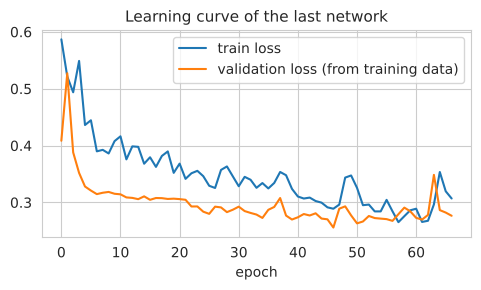

In [42]:
DL_ROWS = []
if HAVE_TF:
    dl_configs = {
        "FCNN 72-2 (original arch.) | improved prep": make_pipe(KerasTabularClassifier("fcnn_baseline", epochs=CFG["nn_epochs"]), cache=False),
        "FCNN 72-64-24 L1/L2 (original arch.) | improved prep": make_pipe(KerasTabularClassifier("fcnn_regularised", epochs=CFG["nn_epochs"]), cache=False),
        "MLDCNN (P1, Gaussian activation)": make_pipe(KerasTabularClassifier("mldcnn", epochs=CFG["nn_epochs"], batch_size=32), cache=False),
        "MLDCNN + EHO output-layer refinement (P1 AEHOM approx.)": make_pipe(KerasTabularClassifier("mldcnn", epochs=CFG["nn_epochs"], batch_size=32, eho_refine=True), cache=False),
        "MLDCNN + EHO | GA+RFE | USCOM (full P1 pipeline)": make_pipe(
            KerasTabularClassifier("mldcnn", epochs=CFG["nn_epochs"], batch_size=32, eho_refine=True), prep=prep_improved("knn"),
            selectors=[ga_selector(), rfecv_selector()], sampler=make_samplers()["USCOM (P1 interpretation)"]),
    }
    reps = CFG["cv_repeats"]; CFG["cv_repeats"] = 1
    for label, pipe in dl_configs.items():
        run_cv(label, "Deep learning", pipe, n_jobs=1)
        fitted, m, _, _ = fit_and_test(label, "Deep learning", pipe)
        tm = train_metrics(fitted)
        DL_ROWS.append({"config": label, "epochs_trained": len(fitted.named_steps["model"].history_["loss"]),
                        "eho_val_loss_gain": fitted.named_steps["model"].eho_gain_, "train_accuracy": tm["accuracy"], "test_accuracy": m["accuracy"]})
    # P1's network as its equations describe it (dense layers + Gaussian activation + back-propagation with momentum),
    # then AEHOM over ALL weights. New configurations: training CV only (not evaluated on the test set).
    p1_dense = {
        "P1 network as described: dense 32-16, Gaussian, SGD+momentum": KerasTabularClassifier(
            "mldcnn_dense", hidden=(32, 16), optimizer="sgd", learning_rate=0.01, momentum=0.9, batch_size=32, epochs=CFG["nn_epochs"]),
        "P1 network as described: dense 64-32-16, Gaussian, SGD+momentum": KerasTabularClassifier(
            "mldcnn_dense", hidden=(64, 32, 16), optimizer="sgd", learning_rate=0.01, momentum=0.9, batch_size=32, epochs=CFG["nn_epochs"]),
        "P1 network as described + AEHOM on all weights": KerasTabularClassifier(
            "mldcnn_dense", hidden=(32, 16), optimizer="sgd", learning_rate=0.01, momentum=0.9, batch_size=32, epochs=CFG["nn_epochs"],
            aehom_full=True, aehom_iterations=10 if QUICK else 40),
    }
    for label, model in p1_dense.items():
        run_cv(label, "Deep learning (P1 as described)", make_pipe(model, cache=False), n_jobs=1)
    run_cv("Full P1 pipeline: GA+RFE | UCOM literal | dense Gaussian net + AEHOM", "Deep learning (P1 as described)",
           make_pipe(KerasTabularClassifier("mldcnn_dense", hidden=(32, 16), optimizer="sgd", learning_rate=0.01, momentum=0.9,
                                            batch_size=32, epochs=CFG["nn_epochs"], aehom_full=True, aehom_iterations=10 if QUICK else 40),
                     prep=prep_improved("knn"), selectors=[ga_selector(), rfecv_selector()],
                     sampler=make_samplers_extra()["UCOM literal (P1: keep 2/3 of majority)"]), n_jobs=1)
    aeh = clone(p1_dense["P1 network as described + AEHOM on all weights"])
    make_pipe(aeh, cache=False).fit(X_train, y_train)
    print("AEHOM on the full training set:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in aeh.aehom_report_.items()})
    CFG["cv_repeats"] = reps
    display(cv_table(["Deep learning", "Deep learning (P1 as described)"])[["experiment", "config", "cv_accuracy", "cv_f1", "cv_mcc", "cv_roc_auc"]].round(3))
    display(pd.DataFrame(DL_ROWS).round(4))
    h = fitted.named_steps["model"].history_
    plt.figure(figsize=(5, 3)); plt.plot(h["loss"], label="train loss"); plt.plot(h["val_loss"], label="validation loss (from training data)")
    plt.legend(); plt.xlabel("epoch"); plt.title("Learning curve of the last network"); savefig("dl_learning_curve")
else:
    print("TensorFlow not available: deep-learning section skipped.")

---
## 17. Combinations of methods (chosen from training CV only)
The three best balancing methods and the three best feature-selection methods (by mean CV MCC over the five reference models, Sections 12 and 13) are crossed with the three best reference models. Only training CV is used to choose and to score the combinations.

In [43]:
top_samplers = [s_ for s_ in piv_bal["mean over models"].sort_values(ascending=False).index if s_ in {**make_samplers(), **make_samplers_extra()}][:3]
top_selectors = piv_fs["mean over models"].sort_values(ascending=False).index[:3].tolist()
model_rank = pd.concat([piv_bal.drop(columns="mean over models").mean(), piv_fs.drop(columns="mean over models").mean()], axis=1).mean(axis=1)
top_models = model_rank.sort_values(ascending=False).index[:3].tolist()
print("Top samplers:", top_samplers); print("Top selectors:", top_selectors); print("Top models:", top_models)
S, F, M = {**make_samplers(), **make_samplers_extra()}, {**make_selectors(), **make_selectors_extra()}, reference_models()
for mname in top_models:
    for fsname in top_selectors:
        for sname in top_samplers:
            run_cv(f"{mname} | {fsname} | {sname}", "Combination", make_pipe(clone(M[mname]), selectors=[clone(s) for s in F[fsname]],
                   sampler=None if S[sname] is None else clone(S[sname])), model=mname, selector=fsname, sampler=sname, verbose=False)
combo = cv_table("Combination")
display(combo[["model", "selector", "sampler", "cv_accuracy", "cv_recall", "cv_specificity", "cv_f1", "cv_mcc", "cv_mcc_sd", "cv_roc_auc"]].head(15).round(3))

Top samplers: ['RUS', 'None', 'SMOTE-Tomek']
Top selectors: ['Variance threshold 0.006 (original)', 'None', 'RFECV (LR)']
Top models: ['SVM-RBF', 'LR', 'RF']


,model,selector,sampler,cv_accuracy,cv_recall,cv_specificity,cv_f1,cv_mcc,cv_mcc_sd,cv_roc_auc
0,SVM-RBF,Variance threshold 0.006 (original),RUS,0.869,0.900,0.831,0.884,0.736,0.078,0.911
1,SVM-RBF,None,RUS,0.869,0.900,0.831,0.884,0.736,0.078,0.911
2,SVM-RBF,Variance threshold 0.006 (original),None,0.867,0.910,0.814,0.883,0.732,0.073,0.911
3,SVM-RBF,None,None,0.867,0.910,0.814,0.883,0.732,0.073,0.911
4,SVM-RBF,Variance threshold 0.006 (original),SMOTE-Tomek,0.865,0.903,0.819,0.881,0.729,0.080,0.911
5,SVM-RBF,None,SMOTE-Tomek,0.865,0.903,0.819,0.881,0.729,0.080,0.911
6,RF,Variance threshold 0.006 (original),RUS,0.861,0.890,0.826,0.876,0.720,0.087,0.919
7,RF,None,RUS,0.861,0.890,0.826,0.876,0.720,0.087,0.919
8,RF,Variance threshold 0.006 (original),SMOTE-Tomek,0.861,0.910,0.800,0.878,0.719,0.080,0.918
9,RF,None,SMOTE-Tomek,0.861,0.910,0.800,0.878,0.719,0.080,0.918


---
## 18. Hyperparameter optimisation (tuning on training data only; comparison on the test set)
* **Optuna** with the TPE sampler (a Bayesian optimiser) tunes ten model families on 5-fold training CV, maximising MCC: logistic regression, RBF-SVM, KNN, Random Forest, Extra Trees, XGBoost, LightGBM, CatBoost, HistGradientBoosting and an MLP.
* **Tuner comparison on XGBoost, same budget for every tuner:**
  * random search (own loop, and scikit-learn `RandomizedSearchCV`);
  * `GridSearchCV` on a fixed grid;
  * Optuna TPE;
  * the elephant-herding optimiser (P1's AEHOM idea);
  * the Bees Algorithm (P1's "modified bee method", standard version).
* **Early stopping**: XGBoost and LightGBM with a large tree budget and early stopping on an internal validation split carved from each training fold.
* The best score of any search is optimistic, because the same data chose the hyperparameters. Re-scoring the tuned settings with a differently shuffled repeated CV reduces, but does not remove, this optimism. The unbiased answer is the nested CV in Section 20.

In [44]:
# Box-search helpers (random search, P1-style elephant herding, Bees Algorithm) used in the tuner comparison
class Space:
    """Hyperparameter box. Each spec: ('int', lo, hi) | ('float', lo, hi) | ('log', lo, hi) | ('cat', [options])."""
    def __init__(self, spec):
        self.spec = spec; self.names = list(spec)
    @property
    def d(self):
        return len(self.names)
    def decode(self, u):
        out = {}
        for x, name in zip(np.clip(u, 0, 1 - 1e-9), self.names):
            s = self.spec[name]
            if s[0] == "int":
                out[name] = int(s[1] + math.floor(x * (s[2] - s[1] + 1)))
            elif s[0] == "float":
                out[name] = float(s[1] + x * (s[2] - s[1]))
            elif s[0] == "log":
                out[name] = float(math.exp(math.log(s[1]) + x * (math.log(s[2]) - math.log(s[1]))))
            else:
                out[name] = s[1][int(x * len(s[1]))]
        return out

def random_search(f, space, budget, rng):
    hist = []
    for _ in range(budget):
        s, p = f(rng.random(space.d)); hist.append((s, p))
    return hist

def eho_search(f, space, budget, rng, n_clans=2, clan_size=4, alpha=0.5, beta=0.1):
    hist = []
    def ev(u):
        s, p = f(u); hist.append((s, p)); return s
    pop = rng.random((n_clans, clan_size, space.d))
    fit = np.array([[ev(u) for u in clan] for clan in pop])
    while len(hist) < budget:
        for c in range(n_clans):
            best = np.argmax(fit[c]); center = pop[c].mean(0)
            for j in range(clan_size):
                if len(hist) >= budget:
                    break
                cand = pop[c, j] + beta * (center - pop[c, j]) if j == best else \
                       pop[c, j] + alpha * (pop[c, best] - pop[c, j]) * rng.random(space.d)
                cand = np.clip(cand + rng.normal(0, 0.02, space.d) * (rng.random(space.d) < 0.1), 0, 1)  # light mutation (P1)
                s = ev(cand)
                if s > fit[c, j]:
                    pop[c, j], fit[c, j] = cand, s
            if len(hist) < budget:                               # separating operator: worst elephant leaves the clan
                w = np.argmin(fit[c]); pop[c, w] = rng.random(space.d); fit[c, w] = ev(pop[c, w])
    return hist[:budget]

def bees_search(f, space, budget, rng, n_scouts=6, n_sites=3, n_elite=1, nep=3, nsp=2, ngh=0.15, shrink=0.85):
    hist = []
    def ev(u):
        s, p = f(u); hist.append((s, p)); return s
    sites = rng.random((n_scouts, space.d)); fit = np.array([ev(u) for u in sites]); radius = np.full(n_scouts, ngh)
    while len(hist) < budget:
        order = np.argsort(-fit); new_sites, new_fit, new_rad = [], [], []
        for rank, i in enumerate(order[:n_sites]):
            best_u, best_s = sites[i], fit[i]
            for _ in range(nep if rank < n_elite else nsp):
                if len(hist) >= budget:
                    break
                u = np.clip(sites[i] + rng.uniform(-radius[i], radius[i], space.d), 0, 1); s = ev(u)
                if s > best_s:
                    best_u, best_s = u, s
            new_sites.append(best_u); new_fit.append(best_s)
            new_rad.append(radius[i] if best_s > fit[i] else radius[i] * shrink)   # shrink neighbourhood if no gain
        for _ in range(n_scouts - n_sites):                       # remaining bees scout at random
            if len(hist) >= budget:
                break
            u = rng.random(space.d); new_sites.append(u); new_fit.append(ev(u)); new_rad.append(ngh)
        sites, fit, radius = np.array(new_sites), np.array(new_fit), np.array(new_rad)
    return hist[:budget]

In [45]:
def _cw(t):
    return t.suggest_categorical("class_weight", ["none", "balanced"])
SPACES = {
    "LR": lambda t: LogisticRegression(C=t.suggest_float("C", 1e-3, 100, log=True), penalty=t.suggest_categorical("penalty", ["l1", "l2"]),
                                       solver="liblinear", class_weight=None if _cw(t) == "none" else "balanced", max_iter=5000, random_state=SEED),
    "SVM": lambda t: SVC(C=t.suggest_float("C", 1e-2, 100, log=True), gamma=t.suggest_float("gamma", 1e-4, 1, log=True),
                         class_weight=None if _cw(t) == "none" else "balanced", probability=True, random_state=SEED),
    "KNN": lambda t: KNeighborsClassifier(n_neighbors=t.suggest_int("n_neighbors", 3, 60), weights=t.suggest_categorical("weights", ["uniform", "distance"]),
                                          p=t.suggest_categorical("p", [1, 2])),
    "RF": lambda t: RandomForestClassifier(n_estimators=t.suggest_int("n_estimators", 100, 600, step=50), max_depth=t.suggest_categorical("max_depth", [None, 4, 6, 8, 12, 16]),
                                           min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10), max_features=t.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.8]),
                                           class_weight=None if _cw(t) == "none" else "balanced", random_state=SEED, n_jobs=1),
    "ET": lambda t: ExtraTreesClassifier(n_estimators=t.suggest_int("n_estimators", 100, 600, step=50), max_depth=t.suggest_categorical("max_depth", [None, 4, 6, 8, 12, 16]),
                                         min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10), max_features=t.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.8]),
                                         class_weight=None if _cw(t) == "none" else "balanced", random_state=SEED, n_jobs=1),
    "XGB": lambda t: XGBClassifier(n_estimators=t.suggest_int("n_estimators", 50, 600, step=25), max_depth=t.suggest_int("max_depth", 2, 8),
                                   learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True), subsample=t.suggest_float("subsample", 0.6, 1.0),
                                   colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0), min_child_weight=t.suggest_int("min_child_weight", 1, 10),
                                   gamma=t.suggest_float("gamma", 0.0, 2.0), reg_lambda=t.suggest_float("reg_lambda", 0.1, 10, log=True),
                                   eval_metric="logloss", random_state=SEED, n_jobs=1),
    "LGBM": lambda t: LGBMClassifier(n_estimators=t.suggest_int("n_estimators", 50, 600, step=25), learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
                                     num_leaves=t.suggest_int("num_leaves", 4, 48), min_child_samples=t.suggest_int("min_child_samples", 5, 50),
                                     subsample=t.suggest_float("subsample", 0.6, 1.0), subsample_freq=1, colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                                     reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True), verbose=-1, n_jobs=1, random_state=SEED),
    "CatBoost": lambda t: CatBoostClassifier(iterations=t.suggest_int("iterations", 100, 500, step=50), depth=t.suggest_int("depth", 3, 7),
                                             learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True), l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1, 10, log=True),
                                             verbose=0, thread_count=1, random_seed=SEED),
    "HistGB": lambda t: HistGradientBoostingClassifier(learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True), max_iter=t.suggest_int("max_iter", 50, 500, step=25),
                                                       max_leaf_nodes=t.suggest_int("max_leaf_nodes", 4, 48), min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 50),
                                                       l2_regularization=t.suggest_float("l2_regularization", 1e-4, 10, log=True), random_state=SEED),
    "MLP": lambda t: MLPClassifier(hidden_layer_sizes=t.suggest_categorical("hidden", [(16,), (32,), (32, 16), (64, 32)]),
                                   alpha=t.suggest_float("alpha", 1e-5, 1e-1, log=True), learning_rate_init=t.suggest_float("lr", 1e-4, 1e-2, log=True),
                                   early_stopping=True, max_iter=1000, random_state=SEED),
}
def build_model(name, params):
    return SPACES[name](optuna.trial.FixedTrial(params))

def optuna_tune(name, X, y, groups, n_trials, n_splits, seed, n_jobs=N_JOBS):
    cv = make_cv(n_splits, seed, groups)
    def objective(t):
        return cross_val_score(make_pipe(SPACES[name](t)), X, y, groups=groups, cv=cv, scoring=SCORING["mcc"], n_jobs=n_jobs).mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    return study

TUNED = {}
TUNE_ROWS = []
for name in tqdm(list(SPACES), desc="Optuna (training CV)"):
    t0 = time.time()
    st = optuna_tune(name, X_train, y_train, g_train, CFG["optuna_trials"], 5, SEED + 50)
    TUNED[name] = st.best_params
    r = run_cv(f"{name} (Optuna)", "Tuned (Optuna)", make_pipe(build_model(name, st.best_params)), model=name, verbose=False)
    TUNE_ROWS.append({"model": name, "trials": len(st.trials), "best inner-CV MCC (optimistic)": st.best_value,
                      "re-scored repeated CV MCC": r["cv_mcc"], "re-scored CV accuracy": r["cv_accuracy"], "re-scored CV AUC": r["cv_roc_auc"],
                      "seconds": round(time.time() - t0, 1), "best params": st.best_params})
TUNE_TABLE = pd.DataFrame(TUNE_ROWS).sort_values("re-scored repeated CV MCC", ascending=False)
display(TUNE_TABLE.drop(columns="best params").round(3))
for _, r in TUNE_TABLE.iterrows():
    print(f"{r['model']:9s} {r['best params']}")

,model,trials,best inner-CV MCC (optimistic),re-scored repeated CV MCC,re-scored CV accuracy,re-scored CV AUC,seconds
2,KNN,60,0.759,0.749,0.875,0.906,4.5
1,SVM,60,0.735,0.733,0.868,0.916,9.7
3,RF,60,0.752,0.731,0.866,0.921,108.6
7,CatBoost,60,0.762,0.729,0.865,0.926,56.0
5,XGB,60,0.743,0.728,0.865,0.925,13.4
4,ET,60,0.749,0.723,0.863,0.924,83.3
0,LR,60,0.726,0.720,0.861,0.919,4.7
6,LGBM,60,0.743,0.716,0.859,0.923,14.7
8,HistGB,60,0.748,0.716,0.859,0.920,37.7
9,MLP,60,0.692,0.620,0.811,0.887,11.8


KNN       {'n_neighbors': 10, 'weights': 'uniform', 'p': 1}
SVM       {'C': 2.197180399881453, 'gamma': 0.05318177283420449, 'class_weight': 'balanced'}
RF        {'n_estimators': 550, 'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 'log2', 'class_weight': 'balanced'}
CatBoost  {'iterations': 250, 'depth': 6, 'learning_rate': 0.015328742863038562, 'l2_leaf_reg': 7.252241469619452}
XGB       {'n_estimators': 550, 'max_depth': 3, 'learning_rate': 0.03476453632730769, 'subsample': 0.8971248207291919, 'colsample_bytree': 0.8413902791121004, 'min_child_weight': 4, 'gamma': 1.3881436434354697, 'reg_lambda': 3.4138340072988567}
ET        {'n_estimators': 500, 'max_depth': 16, 'min_samples_leaf': 6, 'max_features': 'log2', 'class_weight': 'balanced'}
LR        {'C': 0.49506148425252616, 'penalty': 'l2', 'class_weight': 'none'}
LGBM      {'n_estimators': 550, 'learning_rate': 0.014868741361375759, 'num_leaves': 12, 'min_child_samples': 49, 'subsample': 0.913634795509759, 'colsample_bytr

,tuner,evaluations,best inner-CV MCC,median
0,random search,40,0.7689,0.7277
1,"elephant herding (EHO, P1)",40,0.7683,0.7397
2,bees algorithm (P1),40,0.7628,0.7478
3,Optuna TPE (Bayesian),40,0.7628,0.7440
4,scikit-learn RandomizedSearchCV,40,0.7570,0.7390
5,scikit-learn GridSearchCV (32-point grid),32,0.7596,0.7300


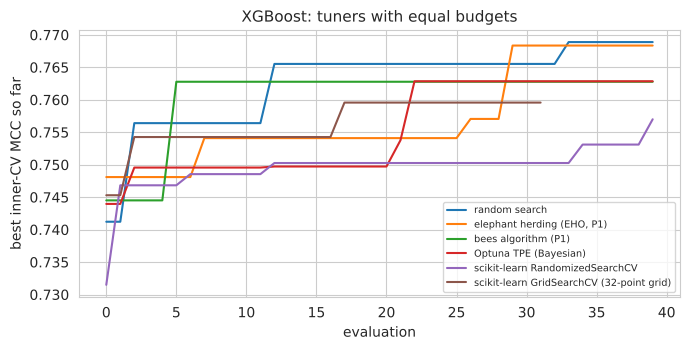

In [46]:
# ---------- tuner comparison on XGBoost: same evaluation budget for every tuner ----------
XGB_SPACE = Space({"n_estimators": ("int", 50, 600), "max_depth": ("int", 2, 8), "learning_rate": ("log", 0.01, 0.3),
                   "subsample": ("float", 0.6, 1.0), "colsample_bytree": ("float", 0.5, 1.0), "min_child_weight": ("int", 1, 10),
                   "gamma": ("float", 0.0, 2.0), "reg_lambda": ("log", 0.1, 10.0)})
xgb_factory = lambda **p: XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1, **p)
cv_t = make_cv(5, SEED + 60, g_train)
_cache = {}
def xgb_obj(u):
    params = XGB_SPACE.decode(u); key = json.dumps(params, sort_keys=True)
    if key not in _cache:
        _cache[key] = cross_val_score(make_pipe(xgb_factory(**params)), X_train, y_train, groups=g_train, cv=cv_t, scoring=SCORING["mcc"], n_jobs=N_JOBS).mean()
    return _cache[key], params
B = CFG["tune_iter"]
TUNER_HIST = {"random search": [h[0] for h in random_search(xgb_obj, XGB_SPACE, B, np.random.default_rng(SEED + 1))],
              "elephant herding (EHO, P1)": [h[0] for h in eho_search(xgb_obj, XGB_SPACE, B, np.random.default_rng(SEED + 2))],
              "bees algorithm (P1)": [h[0] for h in bees_search(xgb_obj, XGB_SPACE, B, np.random.default_rng(SEED + 3))]}
st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED + 4))
st.optimize(lambda t: xgb_obj(np.array([t.suggest_float(n, 0, 1) for n in XGB_SPACE.names]))[0], n_trials=B)
TUNER_HIST["Optuna TPE (Bayesian)"] = [t.value for t in st.trials]
rs = RandomizedSearchCV(make_pipe(XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1)),
                        {"model__n_estimators": stats.randint(50, 601), "model__max_depth": stats.randint(2, 9), "model__learning_rate": stats.loguniform(0.01, 0.3),
                         "model__subsample": stats.uniform(0.6, 0.4), "model__colsample_bytree": stats.uniform(0.5, 0.5),
                         "model__min_child_weight": stats.randint(1, 11), "model__gamma": stats.uniform(0, 2), "model__reg_lambda": stats.loguniform(0.1, 10)},
                        n_iter=B, scoring=SCORING["mcc"], cv=cv_t, random_state=SEED + 5, n_jobs=N_JOBS).fit(X_train, y_train, groups=g_train)
TUNER_HIST["scikit-learn RandomizedSearchCV"] = list(rs.cv_results_["mean_test_score"])
grid = {"model__max_depth": [2, 3, 4, 6], "model__learning_rate": [0.03, 0.1], "model__n_estimators": [100, 300], "model__subsample": [0.8], "model__colsample_bytree": [0.6, 0.9]}
gs = GridSearchCV(make_pipe(XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1)), grid, scoring=SCORING["mcc"], cv=cv_t, n_jobs=N_JOBS).fit(X_train, y_train, groups=g_train)
TUNER_HIST["scikit-learn GridSearchCV (32-point grid)"] = list(gs.cv_results_["mean_test_score"])
TUNER_TABLE = pd.DataFrame([{"tuner": k, "evaluations": len(v), "best inner-CV MCC": max(v), "median": float(np.median(v))} for k, v in TUNER_HIST.items()])
display(TUNER_TABLE.round(4))
plt.figure(figsize=(7, 3.6))
for k, v in TUNER_HIST.items():
    plt.plot(np.maximum.accumulate(v), label=k)
plt.xlabel("evaluation"); plt.ylabel("best inner-CV MCC so far"); plt.legend(fontsize=7); plt.title("XGBoost: tuners with equal budgets")
savefig("tuner_comparison")

In [47]:
# ---------- early stopping (internal validation split inside each training fold) ----------
class EarlyStoppedBooster(ClassifierMixin, BaseEstimator):
    def __init__(self, kind="xgb", learning_rate=0.03, max_estimators=2000, patience=50, validation_fraction=0.2, random_state=SEED):
        self.kind, self.learning_rate, self.max_estimators, self.patience = kind, learning_rate, max_estimators, patience
        self.validation_fraction, self.random_state = validation_fraction, random_state
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1])
        Xa, Xv, ya, yv = train_test_split(X, y, test_size=self.validation_fraction, stratify=y, random_state=self.random_state)
        if self.kind == "xgb":
            m = XGBClassifier(n_estimators=self.max_estimators, learning_rate=self.learning_rate, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                              eval_metric="logloss", early_stopping_rounds=self.patience, random_state=self.random_state, n_jobs=1)
            m.fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False); self.best_n_ = int(m.best_iteration) + 1
        else:
            m = LGBMClassifier(n_estimators=self.max_estimators, learning_rate=self.learning_rate, num_leaves=8, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, verbose=-1, n_jobs=1, random_state=self.random_state)
            m.fit(Xa, ya, eval_set=[(Xv, yv)], callbacks=[lightgbm.early_stopping(self.patience, verbose=False)]); self.best_n_ = int(m.best_iteration_)
        self.model_ = m
        return self
    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, float))
    def predict(self, X):
        return self.model_.predict(np.asarray(X, float))
for kind in ["xgb", "lgbm"]:
    run_cv(f"{kind.upper()} with early stopping", "Tuned (early stopping)", make_pipe(EarlyStoppedBooster(kind)), n_jobs=1)
es_fit = make_pipe(EarlyStoppedBooster("xgb"), cache=False).fit(X_train, y_train)
print("Trees chosen by early stopping on the full training set (XGBoost):", es_fit.named_steps["model"].best_n_)
display(cv_table(["Tuned (Optuna)", "Tuned (early stopping)"])[["experiment", "config", "cv_accuracy", "cv_f1", "cv_mcc", "cv_mcc_sd", "cv_roc_auc", "cv_pr_auc"]].round(3))

[Tuned (early stopping)] XGB with early stopping                                 CV acc 0.868  F1 0.883  MCC 0.735+/-0.086  AUC 0.921  (0.9s)


[Tuned (early stopping)] LGBM with early stopping                                CV acc 0.857  F1 0.874  MCC 0.714+/-0.081  AUC 0.918  (0.6s)
Trees chosen by early stopping on the full training set (XGBoost): 122


,experiment,config,cv_accuracy,cv_f1,cv_mcc,cv_mcc_sd,cv_roc_auc,cv_pr_auc
0,Tuned (Optuna),KNN (Optuna),0.875,0.887,0.749,0.063,0.906,0.890
1,Tuned (early stopping),XGB with early stopping,0.868,0.883,0.735,0.086,0.921,0.930
2,Tuned (Optuna),SVM (Optuna),0.868,0.882,0.733,0.078,0.916,0.923
3,Tuned (Optuna),RF (Optuna),0.866,0.882,0.731,0.076,0.921,0.928
4,Tuned (Optuna),CatBoost (Optuna),0.865,0.881,0.729,0.084,0.926,0.932
5,Tuned (Optuna),XGB (Optuna),0.865,0.881,0.728,0.071,0.925,0.933
6,Tuned (Optuna),ET (Optuna),0.863,0.878,0.723,0.065,0.924,0.931
7,Tuned (Optuna),LR (Optuna),0.861,0.877,0.720,0.074,0.919,0.929
8,Tuned (Optuna),LGBM (Optuna),0.859,0.875,0.716,0.079,0.923,0.931
9,Tuned (Optuna),HistGB (Optuna),0.859,0.875,0.716,0.077,0.920,0.926


### 18.1 Development comparison on the 20% test set: default settings vs Optuna-tuned
Each model family is compared on the test set in two versions, scikit-learn/library defaults and the Optuna-tuned settings above, both fitted on the 70% training set. An exact McNemar test on the same test patients shows whether tuning changed the errors significantly. With 184 patients, differences of 1 to 3 points are within noise.

In [48]:
DEFAULTS = {"LR": LogisticRegression(max_iter=2000, random_state=SEED), "SVM": SVC(probability=True, random_state=SEED),
            "KNN": KNeighborsClassifier(), "RF": RandomForestClassifier(random_state=SEED, n_jobs=1),
            "XGB": XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1), **extra_models()}
TUNE_TEST_ROWS = []
for name in tqdm(TUNE_TABLE["model"].tolist(), desc="default vs tuned on the test set"):
    _, md, pd_, _ = fit_and_test(f"{name} (defaults)", "Development: defaults", make_pipe(clone(DEFAULTS[name])), purpose="development comparison")
    _, mt, pt_, _ = fit_and_test(f"{name} (Optuna)", "Tuned (Optuna)", make_pipe(build_model(name, TUNED[name])), purpose="development comparison")
    b01 = int(((pt_ == TEST.y) & (pd_ != TEST.y)).sum()); b10 = int(((pt_ != TEST.y) & (pd_ == TEST.y)).sum())
    TUNE_TEST_ROWS.append({"model": name, "test acc (defaults)": md["accuracy"], "test acc (tuned)": mt["accuracy"],
                           "test MCC (defaults)": md["mcc"], "test MCC (tuned)": mt["mcc"], "test AUC (defaults)": md["roc_auc"], "test AUC (tuned)": mt["roc_auc"],
                           "tuned right / default wrong": b01, "tuned wrong / default right": b10,
                           "McNemar p": mcnemar([[0, b01], [b10, 0]], exact=True).pvalue if b01 + b10 else 1.0})
TUNE_TEST = pd.DataFrame(TUNE_TEST_ROWS)
TUNE_TEST["delta acc"] = TUNE_TEST["test acc (tuned)"] - TUNE_TEST["test acc (defaults)"]
display(TUNE_TEST.round(3))
print(f"Tuning improved test accuracy for {(TUNE_TEST['delta acc'] > 0).sum()} of {len(TUNE_TEST)} families "
      f"(mean change {TUNE_TEST['delta acc'].mean():+.3f}); significant at p < 0.05 for {(TUNE_TEST['McNemar p'] < 0.05).sum()}.")
TUNE_TEST.to_csv(os.path.join(OUT, "tuning_default_vs_tuned_test.csv"), index=False)

  TEST KNN (defaults)                                     acc 0.859  F1 0.876  MCC 0.714  AUC 0.903  sens 0.902  spec 0.805
  TEST KNN (Optuna)                                       acc 0.864  F1 0.879  MCC 0.724  AUC 0.917  sens 0.892  spec 0.829


  TEST SVM (defaults)                                     acc 0.880  F1 0.894  MCC 0.758  AUC 0.943  sens 0.912  spec 0.841
  TEST SVM (Optuna)                                       acc 0.897  F1 0.908  MCC 0.791  AUC 0.946  sens 0.922  spec 0.866


  TEST RF (defaults)                                      acc 0.859  F1 0.875  MCC 0.713  AUC 0.932  sens 0.892  spec 0.817


  TEST RF (Optuna)                                        acc 0.859  F1 0.875  MCC 0.713  AUC 0.939  sens 0.892  spec 0.817


  TEST CatBoost (defaults)                                acc 0.875  F1 0.887  MCC 0.747  AUC 0.936  sens 0.882  spec 0.866


  TEST CatBoost (Optuna)                                  acc 0.870  F1 0.883  MCC 0.736  AUC 0.942  sens 0.892  spec 0.841
  TEST XGB (defaults)                                     acc 0.864  F1 0.874  MCC 0.728  AUC 0.940  sens 0.853  spec 0.878
  TEST XGB (Optuna)                                       acc 0.880  F1 0.891  MCC 0.759  AUC 0.944  sens 0.882  spec 0.878


... (3 outputs left out)

  TEST HistGB (defaults)                                  acc 0.848  F1 0.859  MCC 0.696  AUC 0.923  sens 0.833  spec 0.866


  TEST HistGB (Optuna)                                    acc 0.880  F1 0.891  MCC 0.759  AUC 0.944  sens 0.882  spec 0.878
  TEST MLP (defaults)                                     acc 0.826  F1 0.850  MCC 0.648  AUC 0.923  sens 0.892  spec 0.744
  TEST MLP (Optuna)                                       acc 0.859  F1 0.879  MCC 0.715  AUC 0.934  sens 0.922  spec 0.780


,model,test acc (defaults),test acc (tuned),test MCC (defaults),test MCC (tuned),test AUC (defaults),test AUC (tuned),tuned right / default wrong,tuned wrong / default right,McNemar p,delta acc
0,KNN,0.859,0.864,0.714,0.724,0.903,0.917,5,4,1.000,0.005
1,SVM,0.880,0.897,0.758,0.791,0.943,0.946,3,0,0.250,0.016
2,RF,0.859,0.859,0.713,0.713,0.932,0.939,3,3,1.000,0.000
3,CatBoost,0.875,0.870,0.747,0.736,0.936,0.942,4,5,1.000,-0.005
4,XGB,0.864,0.880,0.728,0.759,0.940,0.944,6,3,0.508,0.016
5,ET,0.864,0.859,0.726,0.714,0.932,0.938,6,7,1.000,-0.005
6,LR,0.880,0.875,0.758,0.747,0.944,0.945,0,1,1.000,-0.005
7,LGBM,0.875,0.891,0.750,0.782,0.941,0.946,5,2,0.453,0.016
8,HistGB,0.848,0.880,0.696,0.759,0.923,0.944,7,1,0.070,0.033
9,MLP,0.826,0.859,0.648,0.715,0.923,0.934,9,3,0.146,0.033


Tuning improved test accuracy for 6 of 10 families (mean change +0.010); significant at p < 0.05 for 0.


---
## 19. Ensemble learning (built and compared by training CV; development comparison on the test set)
Ensembles are built from the Optuna-tuned models of Section 18. Do they beat their best member?
* **Soft voting** (average probability) and **hard voting** (majority vote), over the top 3 and top 5 tuned models.
* **Stacking**: a logistic-regression meta-learner trained on out-of-fold probabilities, computed inside every training fold.
* **Blending**: members trained on 75% of each training fold, meta-learner on the other 25%.
* **Weighted average**: non-negative weights learned from out-of-fold probabilities inside every training fold.
* **Calibrated ensemble**: isotonic calibration (5-fold) of the soft-voting ensemble.
* **Bagging** of the best single tuned model (30 bootstrap replicas).
* scikit-learn's own `VotingClassifier` and `StackingClassifier`, as a cross-check of the custom ensemble class.

The members' hyperparameters were tuned on the same training data, so every CV number here (single models included) shares the same mild optimism. The fair tests are Section 20 (nested CV) and the test-set comparison in 19.1.

In [49]:
ranked = TUNE_TABLE["model"].tolist()
member = lambda n: (n, make_pipe(build_model(n, TUNED[n])))
TOP3, TOP5 = [member(n) for n in ranked[:3]], [member(n) for n in ranked[:5]]
best1 = ranked[0]
ENS = {
    f"Best single tuned model ({best1})": FinalEnsemble([member(best1)], "single"),
    "Soft voting (top 3)": FinalEnsemble(TOP3, "soft"), "Soft voting (top 5)": FinalEnsemble(TOP5, "soft"),
    "Hard voting (top 3)": FinalEnsemble(TOP3, "hard"), "Hard voting (top 5)": FinalEnsemble(TOP5, "hard"),
    "Stacking, LR meta on OOF (top 5)": FinalEnsemble(TOP5, "stack"),
    "Blending, 75/25 holdout (top 5)": FinalEnsemble(TOP5, "blend"),
    "Weighted average, OOF-learned weights (top 5)": FinalEnsemble(TOP5, "weighted"),
    "Calibrated soft voting (isotonic, top 3)": CalibratedClassifierCV(FinalEnsemble(TOP3, "soft"), method="isotonic", cv=5),
    f"Bagging of {best1} (30 replicas)": make_pipe(BaggingClassifier(estimator=build_model(best1, TUNED[best1]), n_estimators=30, random_state=SEED, n_jobs=1)),
    "sklearn VotingClassifier soft (top 3)": VotingClassifier(TOP3, voting="soft"),
    "sklearn StackingClassifier (top 5)": StackingClassifier(TOP5, final_estimator=LogisticRegression(max_iter=2000), cv=5),
}
for label, est in tqdm(list(ENS.items()), desc="ensembles"):
    run_cv(label, "Ensembles", est, verbose=False)
ens_tab = cv_table("Ensembles")
display(ens_tab[["config", "cv_accuracy", "cv_precision", "cv_recall", "cv_specificity", "cv_f1", "cv_mcc", "cv_mcc_sd", "cv_roc_auc", "cv_pr_auc"]].round(3))

# Are the ensembles better than their best member on the same folds? (corrected resampled t-test)
def fold_scores(experiment, label, metric="mcc"):
    return FOLD_SCORES[(experiment, label)][metric].to_numpy()      # same folds for every configuration (same CV seeds)
n_tr_fold = len(y_train) * (CFG["cv_splits"] - 1) / CFG["cv_splits"]; n_te_fold = len(y_train) / CFG["cv_splits"]
ref_scores = fold_scores("Ensembles", f"Best single tuned model ({best1})")
ENS_TESTS = []
for label in ["Soft voting (top 3)", "Soft voting (top 5)", "Stacking, LR meta on OOF (top 5)", "Weighted average, OOF-learned weights (top 5)"]:
    d, lo, hi, p = corrected_ttest(fold_scores("Ensembles", label), ref_scores, n_tr_fold, n_te_fold)
    ENS_TESTS.append({"ensemble": label, "vs": f"best single ({best1})", "mean MCC difference": d, "95% CI low": lo, "95% CI high": hi, "p (corrected t-test)": p})
ENS_TESTS = pd.DataFrame(ENS_TESTS); display(ENS_TESTS.round(4))

,config,cv_accuracy,cv_precision,cv_recall,cv_specificity,cv_f1,cv_mcc,cv_mcc_sd,cv_roc_auc,cv_pr_auc
0,Bagging of KNN (30 replicas),0.875,0.875,0.906,0.838,0.889,0.749,0.070,0.911,0.903
1,Hard voting (top 5),0.870,0.862,0.911,0.819,0.885,0.738,0.078,0.887,0.864
2,Soft voting (top 5),0.870,0.865,0.907,0.824,0.885,0.738,0.071,0.923,0.928
3,"Weighted average, OOF-learned weights (top 5)",0.869,0.863,0.910,0.819,0.885,0.737,0.079,0.924,0.930
4,"Calibrated soft voting (isotonic, top 3)",0.868,0.853,0.923,0.801,0.886,0.736,0.081,0.919,0.919
5,"Stacking, LR meta on OOF (top 5)",0.868,0.863,0.907,0.820,0.884,0.735,0.072,0.923,0.927
6,sklearn StackingClassifier (top 5),0.868,0.853,0.921,0.803,0.886,0.735,0.070,0.922,0.926
7,Hard voting (top 3),0.868,0.858,0.914,0.812,0.885,0.735,0.069,0.881,0.857
8,sklearn VotingClassifier soft (top 3),0.868,0.865,0.903,0.824,0.883,0.733,0.073,0.919,0.923
9,Soft voting (top 3),0.868,0.865,0.903,0.824,0.883,0.733,0.073,0.919,0.923


,ensemble,vs,mean MCC difference,95% CI low,95% CI high,p (corrected t-test)
0,Soft voting (top 3),best single (KNN),0.0045,-0.0255,0.0345,0.7414
1,Soft voting (top 5),best single (KNN),0.0093,-0.0208,0.0394,0.5024
2,"Stacking, LR meta on OOF (top 5)",best single (KNN),0.0066,-0.0231,0.0364,0.6259
3,"Weighted average, OOF-learned weights (top 5)",best single (KNN),0.0081,-0.0210,0.0371,0.5464


### 19.1 Development comparison on the 20% test set
Every ensemble and its best single member are fitted on the training set and scored on the test set. The McNemar test compares each ensemble with the best single tuned model on the same patients.

In [50]:
ENS_TEST_ROWS = []
ref_label = f"Best single tuned model ({best1})"
ENS_FITTED = {}
for label, est in tqdm(list(ENS.items()), desc="ensembles on the test set"):
    ENS_FITTED[label] = fit_and_test(label, "Ensembles", est, purpose="development comparison")
_, mref, pref, _ = ENS_FITTED[ref_label]
for label, (_, m, p_, _) in ENS_FITTED.items():
    b01 = int(((p_ == TEST.y) & (pref != TEST.y)).sum()); b10 = int(((p_ != TEST.y) & (pref == TEST.y)).sum())
    ENS_TEST_ROWS.append({"ensemble": label, "test accuracy": m["accuracy"], "test MCC": m["mcc"], "test AUC": m["roc_auc"],
                          "test sensitivity": m["recall"], "test specificity": m["specificity"], "FN": m["fn"], "FP": m["fp"],
                          "McNemar p vs best single": mcnemar([[0, b01], [b10, 0]], exact=True).pvalue if b01 + b10 else 1.0})
ENS_TEST = pd.DataFrame(ENS_TEST_ROWS).sort_values("test MCC", ascending=False)
display(ENS_TEST.round(3))
ENS_TEST.to_csv(os.path.join(OUT, "ensembles_test_comparison.csv"), index=False)

  TEST Best single tuned model (KNN)                      acc 0.864  F1 0.880  MCC 0.724  AUC 0.917  sens 0.902  spec 0.817


  TEST Soft voting (top 3)                                acc 0.864  F1 0.879  MCC 0.724  AUC 0.942  sens 0.892  spec 0.829


  TEST Soft voting (top 5)                                acc 0.875  F1 0.889  MCC 0.747  AUC 0.942  sens 0.902  spec 0.841


  TEST Hard voting (top 3)                                acc 0.870  F1 0.885  MCC 0.735  AUC 0.896  sens 0.902  spec 0.829


  TEST Hard voting (top 5)                                acc 0.870  F1 0.883  MCC 0.736  AUC 0.901  sens 0.892  spec 0.841


  TEST Stacking, LR meta on OOF (top 5)                   acc 0.870  F1 0.883  MCC 0.736  AUC 0.942  sens 0.892  spec 0.841


... (2 outputs left out)

  TEST Calibrated soft voting (isotonic, top 3)           acc 0.864  F1 0.882  MCC 0.725  AUC 0.941  sens 0.912  spec 0.805
  TEST Bagging of KNN (30 replicas)                       acc 0.864  F1 0.880  MCC 0.724  AUC 0.927  sens 0.902  spec 0.817


  TEST sklearn VotingClassifier soft (top 3)              acc 0.864  F1 0.879  MCC 0.724  AUC 0.942  sens 0.892  spec 0.829


  TEST sklearn StackingClassifier (top 5)                 acc 0.853  F1 0.870  MCC 0.702  AUC 0.938  sens 0.882  spec 0.817


,ensemble,test accuracy,test MCC,test AUC,test sensitivity,test specificity,FN,FP,McNemar p vs best single
2,Soft voting (top 5),0.875,0.747,0.942,0.902,0.841,10,13,0.625
7,"Weighted average, OOF-learned weights (top 5)",0.870,0.736,0.942,0.892,0.841,11,13,1.000
5,"Stacking, LR meta on OOF (top 5)",0.870,0.736,0.942,0.892,0.841,11,13,1.000
4,Hard voting (top 5),0.870,0.736,0.901,0.892,0.841,11,13,1.000
3,Hard voting (top 3),0.870,0.735,0.896,0.902,0.829,10,14,1.000
8,"Calibrated soft voting (isotonic, top 3)",0.864,0.725,0.941,0.912,0.805,9,16,1.000
6,"Blending, 75/25 holdout (top 5)",0.864,0.724,0.943,0.902,0.817,10,15,1.000
0,Best single tuned model (KNN),0.864,0.724,0.917,0.902,0.817,10,15,1.000
9,Bagging of KNN (30 replicas),0.864,0.724,0.927,0.902,0.817,10,15,1.000
1,Soft voting (top 3),0.864,0.724,0.942,0.892,0.829,11,14,1.000


---
## 20. Primary evidence: nested cross-validation of the whole optimisation procedure
The question is not "which configuration scored highest on one CV?" but **"does the optimisation procedure, applied to new data, produce a better model than the corrected baseline?"** Answering that requires repeating the entire procedure inside every outer fold without ever letting the outer fold influence a choice.

**`autoselect(X, y)`**, the full optimisation procedure, uses only the data it is given:
1. tunes every model family with Optuna (TPE, 3-fold inner CV, MCC objective);
2. computes out-of-fold (OOF) probabilities for each tuned model;
3. builds candidate ensembles from the OOF probabilities: soft and hard voting of the top 3 and top 5, cross-fitted weighted averages, and a stacked logistic regression;
4. picks the candidate with the highest OOF MCC;
5. chooses the decision threshold that maximises OOF MCC for that candidate (the criterion was fixed in advance).

**Outer loop**: 5 folds x 2 repeats over the **70% training set only** (unique patients, so no copy can cross a fold). The test and validation patients are never used here. In each outer fold, the same patients are used to evaluate, side by side:
* `autoselect`, run from scratch on the outer-training part;
* every tuned model family on its own (tuned inside the fold);
* the corrected baseline (original XGBoost configuration);
* default logistic regression;
* the previous notebook's final model (KNN, k = 10);
* the three parent-paper pipelines.

Comparisons use the Nadeau-Bengio corrected resampled t-test on the per-fold differences. Note: the previous final model's settings and the parent-paper pipeline choices were fixed in earlier versions using data that overlaps these outer folds, so they get a small advantage. `autoselect` gets none.

In [51]:
THR_GRID = np.round(np.arange(0.20, 0.801, 0.01), 2)
def threshold_table(y, p):
    rows = []
    for t in THR_GRID:
        m = compute_metrics(y, (p >= t).astype(int), p)
        rows.append({"threshold": t, **{k: m[k] for k in ["accuracy", "precision", "recall", "specificity", "f1", "balanced_accuracy", "mcc", "tp", "fp", "tn", "fn"]}})
    return pd.DataFrame(rows)
def threshold_policies(y, p):
    T = threshold_table(y, p)
    pol = {"default 0.5": 0.5, "max MCC (pre-declared)": T.loc[T.mcc.idxmax(), "threshold"], "max F1": T.loc[T.f1.idxmax(), "threshold"],
           "max balanced accuracy (Youden J)": T.loc[T.balanced_accuracy.idxmax(), "threshold"],
           "max precision with recall >= 0.80": T[T.recall >= 0.80].sort_values("precision").iloc[-1]["threshold"] if (T.recall >= 0.80).any() else np.nan}
    hi_sens = T[T.recall >= 0.90]; hi_spec = T[T.specificity >= 0.90]
    pol["sensitivity >= 0.90 (highest such threshold)"] = hi_sens.threshold.max() if len(hi_sens) else np.nan
    pol["specificity >= 0.90 (lowest such threshold)"] = hi_spec.threshold.min() if len(hi_spec) else np.nan
    return pol, T

def oof_proba(est, X, y, groups, n_splits, seed):
    return cross_val_predict(est, X, y, groups=groups, cv=make_cv(n_splits, seed, groups), method="predict_proba", n_jobs=N_JOBS)[:, 1]

def autoselect(X, y, groups, models, n_trials, n_splits, seed):
    tuned, oof = {}, {}
    for name in models:
        st = optuna_tune(name, X, y, groups, n_trials, n_splits, seed)
        tuned[name] = st.best_params
        oof[name] = oof_proba(make_pipe(build_model(name, st.best_params)), X, y, groups, n_splits, seed)
    names = list(oof)
    mcc_of = lambda p: matthews_corrcoef(y, (p >= 0.5).astype(int))
    order = sorted(names, key=lambda n: -mcc_of(oof[n]))
    cands = {f"single: {n}": ("single", [n], oof[n]) for n in names}
    for k in (3, 5):
        if len(order) >= k:
            top = order[:k]; Pk = np.column_stack([oof[n] for n in top])
            cands[f"soft voting: top {k}"] = ("soft", top, Pk.mean(1))
            cands[f"hard voting: top {k}"] = ("hard", top, (Pk >= 0.5).mean(1))
            wp = np.zeros(len(y))
            for tr, te in make_cv(n_splits, seed + 7, groups).split(Pk, y, groups):     # cross-fitted weights
                wp[te] = Pk[te] @ learn_weights(Pk[tr], y[tr])
            cands[f"weighted average: top {k}"] = ("weighted", top, wp)
    P = np.column_stack([oof[n] for n in names])
    cands["stacking: all"] = ("stack", names, cross_val_predict(LogisticRegression(max_iter=2000), P, y, cv=make_cv(n_splits, seed + 7, groups),
                                                               method="predict_proba")[:, 1])
    rows = [{"candidate": c, "oof_mcc": mcc_of(p), "oof_roc_auc": roc_auc_score(y, p), "oof_accuracy": accuracy_score(y, (p >= 0.5).astype(int))}
            for c, (_, _, p) in cands.items()]
    table = pd.DataFrame(rows).sort_values(["oof_mcc", "oof_roc_auc"], ascending=False).reset_index(drop=True)
    chosen = table.iloc[0]["candidate"]; method, members, p = cands[chosen]
    pol, _ = threshold_policies(y, p)
    thr = float(pol["max MCC (pre-declared)"])
    final = FinalEnsemble([(n, make_pipe(build_model(n, tuned[n]))) for n in members], method,
                          threshold=thr, stack_cv=n_splits, random_state=seed)
    return final, {"table": table, "tuned": tuned, "oof": oof, "chosen": chosen, "threshold": thr, "chosen_oof": p, "policies": pol}

In [52]:
# Nested CV runs inside the 70% TRAINING set only (the test and validation patients are not used)
XA, yA = X_train.reset_index(drop=True), np.asarray(y_train); gA = np.arange(len(yA))
uniq_dev = df.drop_duplicates(FEATURES + [TARGET]).reset_index(drop=True)   # development data (train + test), for the diagnostics in Section 24
COMPARATORS = {
    "Corrected baseline: XGBoost (original config)": lambda: make_pipe(XGBClassifier(**XGB_ORIGINAL), prep=prep_original()),
    "Logistic regression (default settings)": lambda: make_pipe(LogisticRegression(max_iter=2000, random_state=SEED)),
    "Previous final model: KNN (k=10, distance, p=1)": lambda: make_pipe(KNeighborsClassifier(10, weights="distance", p=1)),
    "P1: SVM | GA+RFE | USCOM": lambda: make_pipe(SVC(probability=True, random_state=SEED), prep=prep_improved("knn"),
                                                    selectors=[ga_selector(), rfecv_selector()], sampler=make_samplers()["USCOM (P1 interpretation)"]),
    "P2: Bagged-DT | in-fold selective duplication": lambda: make_pipe(bagged(DecisionTreeClassifier(random_state=SEED)), prep=prep_p2(),
                                                                       sampler=p2_sampler(DecisionTreeClassifier(random_state=SEED), "loo")),
    "P3: Gradient Boosting | EG-HFS": lambda: make_pipe(GradientBoostingClassifier(random_state=SEED), prep=prep_improved("mean"),
                                                         selectors=[SymmetricUncertaintySelector("mean", strict=True)]),
}
NESTED_ROWS, NESTED_PRED, NESTED_CHOICES = [], [], []
outer_jobs = [(r, k, tr, te) for r in range(CFG["nested_repeats"])
              for k, (tr, te) in enumerate(make_cv(CFG["nested_outer"], SEED + 500 + r, gA).split(XA, yA, gA))]
t_nested = time.time()
for r, k, tr, te in tqdm(outer_jobs, desc="nested CV outer folds"):
    Xtr, ytr, Xte, yte = XA.iloc[tr], yA[tr], XA.iloc[te], yA[te]
    def record(name, pred, score):
        NESTED_ROWS.append({"repeat": r, "fold": k, "method": name, **compute_metrics(yte, pred, score)})
        NESTED_PRED.append(pd.DataFrame({"repeat": r, "fold": k, "method": name, "row": te, "y": yte, "pred": pred, "score": score}))
    for name, f in COMPARATORS.items():
        m = f().fit(Xtr, ytr); record(name, m.predict(Xte), scores_of(m, Xte))
    final_k, rep = autoselect(Xtr, ytr, np.arange(len(ytr)), CFG["nested_models"], CFG["nested_trials"], 3, SEED + 1000 + 10 * r + k)
    final_k.fit(Xtr, ytr); s_ = scores_of(final_k, Xte)
    record("AutoSelect (full optimisation procedure)", final_k.predict(Xte), s_)
    record("AutoSelect, same model at threshold 0.5", (s_ >= 0.5).astype(int), s_)
    for name, params in rep["tuned"].items():
        m = make_pipe(build_model(name, params)).fit(Xtr, ytr); record(f"Tuned {name} (Optuna inside the fold)", m.predict(Xte), scores_of(m, Xte))
    NESTED_CHOICES.append({"repeat": r, "fold": k, "chosen candidate": rep["chosen"], "threshold": rep["threshold"],
                           "inner OOF MCC of chosen": rep["table"].iloc[0]["oof_mcc"]})
print(f"Nested CV finished in {(time.time() - t_nested) / 60:.1f} min")
NESTED = pd.DataFrame(NESTED_ROWS); NESTED_PRED = pd.concat(NESTED_PRED, ignore_index=True); NESTED_CHOICES = pd.DataFrame(NESTED_CHOICES)
display(NESTED_CHOICES)

Nested CV finished in 15.1 min


,repeat,fold,chosen candidate,threshold,inner OOF MCC of chosen
0,0,0,hard voting: top 3,0.67,0.755334
1,0,1,hard voting: top 5,0.41,0.743324
2,0,2,hard voting: top 5,0.41,0.767627
3,0,3,hard voting: top 5,0.61,0.768507
4,0,4,hard voting: top 3,0.34,0.736397
5,1,0,hard voting: top 3,0.34,0.775134
6,1,1,hard voting: top 5,0.61,0.747144
7,1,2,hard voting: top 5,0.21,0.716214
8,1,3,single: CatBoost,0.51,0.748021
9,1,4,soft voting: top 5,0.50,0.773038


,accuracy,precision,recall,specificity,f1,f1_macro,balanced_accuracy,mcc,roc_auc,pr_auc,accuracy sd,mcc sd,roc_auc sd,tp,fp,tn,fn
method,,,,,,,,,,,,,,,,,
Tuned CatBoost (Optuna inside the fold),0.875,0.861,0.923,0.815,0.891,0.872,0.869,0.747,0.922,0.924,0.014,0.029,0.015,327.5,53.0,234.0,27.5
Tuned KNN (Optuna inside the fold),0.873,0.870,0.906,0.833,0.887,0.871,0.869,0.743,0.913,0.903,0.013,0.027,0.019,321.5,48.0,239.0,33.5
AutoSelect (full optimisation procedure),0.868,0.861,0.910,0.817,0.884,0.866,0.863,0.734,0.898,0.881,0.017,0.035,0.026,323.0,52.5,234.5,32.0
"Previous final model: KNN (k=10, distance, p=1)",0.868,0.868,0.900,0.829,0.883,0.866,0.865,0.734,0.912,0.901,0.013,0.025,0.019,319.5,49.0,238.0,35.5
"AutoSelect, same model at threshold 0.5",0.868,0.856,0.915,0.808,0.884,0.865,0.862,0.733,0.898,0.881,0.015,0.031,0.026,325.0,55.0,232.0,30.0
Tuned LGBM (Optuna inside the fold),0.867,0.860,0.907,0.817,0.883,0.864,0.862,0.731,0.923,0.925,0.023,0.047,0.020,322.0,52.5,234.5,33.0
Tuned HistGB (Optuna inside the fold),0.866,0.862,0.903,0.821,0.882,0.864,0.862,0.730,0.927,0.929,0.019,0.039,0.021,320.5,51.5,235.5,34.5
Tuned XGB (Optuna inside the fold),0.865,0.857,0.907,0.812,0.881,0.862,0.859,0.727,0.927,0.931,0.017,0.034,0.018,322.0,54.0,233.0,33.0
Tuned RF (Optuna inside the fold),0.865,0.855,0.910,0.808,0.881,0.862,0.859,0.727,0.922,0.922,0.020,0.041,0.019,323.0,55.0,232.0,32.0


metric,accuracy,mcc,roc_auc,accuracy p,mcc p,roc_auc p
method,,,,,,
AutoSelect (full optimisation procedure),0.0125,0.0248,-0.0158,0.2439,0.2610,0.3768
"AutoSelect, same model at threshold 0.5",0.0117,0.0234,-0.0158,0.2516,0.2748,0.3768
Logistic regression (default settings),0.0047,0.0087,0.0036,0.7168,0.7506,0.7346
P1: SVM | GA+RFE | USCOM,0.0031,0.0052,-0.0066,0.7285,0.7742,0.6951
P2: Bagged-DT | in-fold selective duplication,-0.0093,-0.0196,-0.0065,0.2223,0.2054,0.3949
P3: Gradient Boosting | EG-HFS,-0.0125,-0.0247,-0.0231,0.3579,0.3776,0.0592
"Previous final model: KNN (k=10, distance, p=1)",0.0125,0.0244,-0.0017,0.1490,0.1705,0.8178
Tuned CatBoost (Optuna inside the fold),0.0187,0.0376,0.0089,0.1334,0.1524,0.2907
Tuned ET (Optuna inside the fold),0.0078,0.0163,0.0090,0.3464,0.3256,0.3023


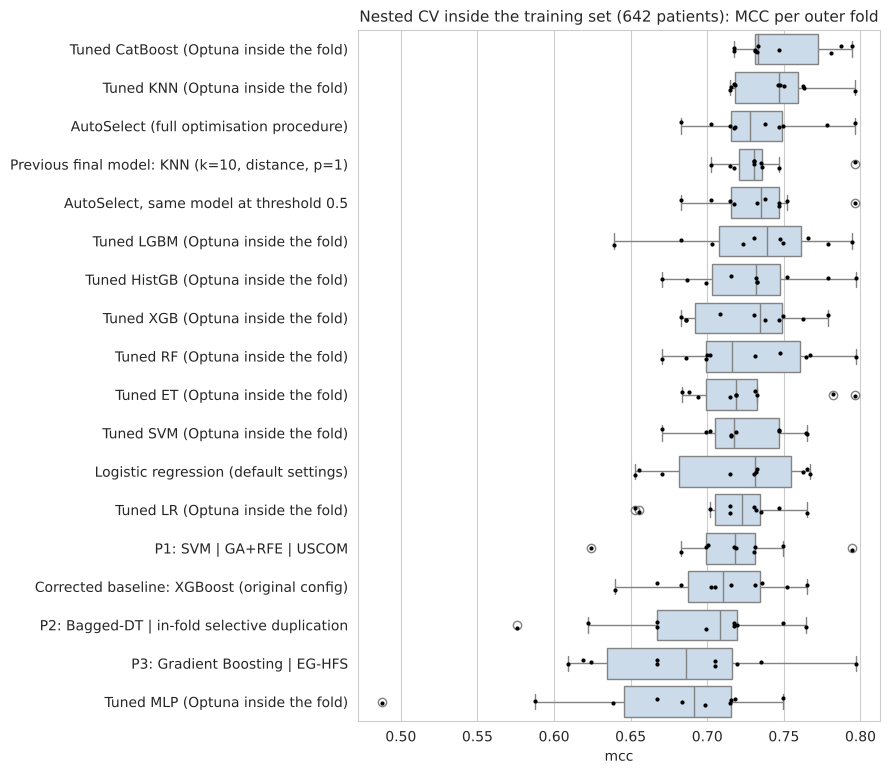

In [53]:
NM = ["accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "balanced_accuracy", "mcc", "roc_auc", "pr_auc"]
summary = NESTED.groupby("method")[NM].agg(["mean", "std"])
NESTED_SUMMARY = pd.DataFrame({m: summary[(m, "mean")] for m in NM})
for m in ["accuracy", "mcc", "roc_auc"]:
    NESTED_SUMMARY[f"{m} sd"] = summary[(m, "std")]
# pooled confusion counts over all outer test folds (each patient once per repeat)
pooled = NESTED_PRED.groupby("method").apply(lambda g: pd.Series(compute_metrics(g.y, g.pred, g.score))[["tp", "fp", "tn", "fn"]] / CFG["nested_repeats"])
NESTED_SUMMARY = NESTED_SUMMARY.join(pooled).sort_values("mcc", ascending=False)
display(NESTED_SUMMARY.round(3))

BASE_NAME = "Corrected baseline: XGBoost (original config)"; AUTO_NAME = "AutoSelect (full optimisation procedure)"
n_out_te = len(yA) / CFG["nested_outer"]; n_out_tr = len(yA) - n_out_te
def paired(a_name, b_name, metric):
    A = NESTED[NESTED.method == a_name].sort_values(["repeat", "fold"])[metric].to_numpy()
    Bv = NESTED[NESTED.method == b_name].sort_values(["repeat", "fold"])[metric].to_numpy()
    return corrected_ttest(A, Bv, n_out_tr, n_out_te)
rows = []
for name in NESTED.method.unique():
    if name == BASE_NAME:
        continue
    for metric in ["accuracy", "mcc", "roc_auc"]:
        d, lo, hi, p = paired(name, BASE_NAME, metric)
        rows.append({"method": name, "metric": metric, "difference vs corrected baseline": d, "95% CI low": lo, "95% CI high": hi, "p (corrected t-test)": p})
NESTED_TESTS = pd.DataFrame(rows)
display(NESTED_TESTS.pivot(index="method", columns="metric", values="difference vs corrected baseline").join(
        NESTED_TESTS.pivot(index="method", columns="metric", values="p (corrected t-test)"), rsuffix=" p").round(4))
NESTED.to_csv(os.path.join(OUT, "nested_cv_per_fold.csv"), index=False); NESTED_SUMMARY.to_csv(os.path.join(OUT, "nested_cv_summary.csv"))
NESTED_TESTS.to_csv(os.path.join(OUT, "nested_cv_paired_tests.csv"), index=False); NESTED_CHOICES.to_csv(os.path.join(OUT, "nested_cv_autoselect_choices.csv"), index=False)

order_m = NESTED_SUMMARY.index.tolist()
plt.figure(figsize=(9, 0.38 * len(order_m) + 1))
sns.boxplot(data=NESTED, y="method", x="mcc", order=order_m, color="#c6dbef")
sns.stripplot(data=NESTED, y="method", x="mcc", order=order_m, color="k", size=3)
plt.title(f"Nested CV inside the training set ({len(yA)} patients): MCC per outer fold"); plt.ylabel("")
savefig("nested_cv_mcc")

---
## 21. Final model: pre-declared shortlist, chosen on the 20% test set, then frozen
The three-way split gives each step its own data:
* **Fitting, tuning and thresholds use the training set.** `autoselect` (the procedure assessed by nested CV in Section 20) runs on the 70% training set. Every shortlisted candidate gets its decision threshold from its own training out-of-fold (OOF) probabilities (pre-declared policy: maximise OOF MCC).
* **Choosing the final model uses the test set.** The shortlist below was fixed before any of these candidates was scored on the test set. **Selection rule (pre-declared): highest test MCC; ties broken by test ROC-AUC.**
  1. AutoSelect (the full training-only optimisation procedure)
  2. the best Optuna-tuned single model by training CV (Section 18)
  3. the best ensemble by training CV (Section 19)
  4. default logistic regression
  5. the corrected baseline XGBoost (original configuration)
* **The final estimate comes from the validation set.** The chosen model's test score is optimistic, because the test set was used to pick it. After the model is frozen, the untouched 10% validation set gives the unbiased estimate (Section 30).

In [54]:
t0 = time.time()
AUTO_MODEL, AUTO_REP = autoselect(X_train, y_train, g_train, CFG["nested_models"], CFG["nested_trials"], 3, SEED + 2000)
print(f"autoselect on the training set: {time.time() - t0:.0f}s | chosen: {AUTO_REP['chosen']} | threshold (max OOF MCC): {AUTO_REP['threshold']}")
display(AUTO_REP["table"].head(12).round(4))

# ---------------- pre-declared shortlist (fixed before any of these is scored on the test set) ----------------
best_ens = [c for c in ens_tab["config"] if not c.startswith("Best single")][0]
SHORTLIST = {
    "AutoSelect (training-only optimisation procedure)": ("autoselect", AUTO_MODEL),
    f"Best tuned single model by training CV ({best1}, Optuna)": (best1, make_pipe(build_model(best1, TUNED[best1]))),
    f"Best ensemble by training CV ({best_ens})": ("ensemble", ENS[best_ens]),
    "Logistic regression (default settings)": ("LR default", make_pipe(LogisticRegression(max_iter=2000, random_state=SEED))),
    "Corrected baseline XGBoost (original config)": ("XGB original", PIPES[("Corrected baseline (original configs)", "XGBoost (original)")]),
}
SHORT_ROWS, SHORT_OBJ = [], {}
for label, (member_name, est) in tqdm(list(SHORTLIST.items()), desc="final shortlist"):
    if member_name == "autoselect":
        model, oof, thr = AUTO_MODEL, AUTO_REP["chosen_oof"], AUTO_REP["threshold"]
    else:
        oof = oof_proba(est, X_train, y_train, g_train, 5, SEED + 3000)
        thr = float(threshold_policies(y_train, oof)[0]["max MCC (pre-declared)"])
        model = FinalEnsemble([(member_name, est)], "single", threshold=thr, random_state=SEED)
    fitted, m, pred, score = fit_and_test(label, "Final shortlist", model, purpose="development comparison: final shortlist")
    SHORT_OBJ[label] = (model, fitted, m, pred, score, oof, thr, member_name)
    SHORT_ROWS.append({"candidate": label, "threshold (training OOF)": thr, "training OOF MCC": matthews_corrcoef(y_train, (oof >= thr).astype(int)),
                       "test accuracy": m["accuracy"], "test MCC": m["mcc"], "test ROC-AUC": m["roc_auc"], "test sensitivity": m["recall"],
                       "test specificity": m["specificity"], "FN": m["fn"], "FP": m["fp"]})
SHORT_TABLE = pd.DataFrame(SHORT_ROWS).sort_values(["test MCC", "test ROC-AUC"], ascending=False).reset_index(drop=True)
display(SHORT_TABLE.round(3))
CHOSEN = SHORT_TABLE.iloc[0]["candidate"]
FINAL_MODEL, final_fitted, FM, f_pred, f_score, f_oof, f_thr, f_member = SHORT_OBJ[CHOSEN]
FINAL_REP = dict(AUTO_REP)
FINAL_REP.update({"chosen": CHOSEN if f_member != "autoselect" else f"AutoSelect -> {AUTO_REP['chosen']}", "threshold": f_thr, "chosen_oof": f_oof,
                  "tuned": AUTO_REP["tuned"] if f_member == "autoselect" else
                           {f_member: TUNED.get(f_member, "fixed configuration (Sections 11 and 19)")}})
FINAL_EXP, FINAL_LABEL = "FINAL", "FINAL"
TEST_RESULTS.append({**[r for r in TEST_RESULTS if r["experiment"] == "Final shortlist" and r["config"] == CHOSEN][0],
                     "experiment": FINAL_EXP, "config": FINAL_LABEL})            # same evaluation, re-labelled (no new test access)
print(f"FINAL MODEL (pre-declared rule: highest test MCC): {CHOSEN} | threshold {f_thr:.2f}")
print("Its test score is optimistic (the test set chose it); the unbiased estimate is the validation set (Section 30).")
run_cv(FINAL_LABEL, FINAL_EXP, FINAL_MODEL)          # repeated training CV of the frozen configuration (for reference)

autoselect on the training set: 83s | chosen: hard voting: top 3 | threshold (max OOF MCC): 0.34


,candidate,oof_mcc,oof_roc_auc,oof_accuracy
0,hard voting: top 3,0.7541,0.8927,0.8785
1,hard voting: top 5,0.7509,0.8917,0.8769
2,single: ET,0.7452,0.9151,0.8738
3,soft voting: top 3,0.7448,0.9176,0.8738
4,stacking: all,0.7414,0.9160,0.8723
5,single: HistGB,0.7412,0.9100,0.8723
6,single: XGB,0.7412,0.9083,0.8723
7,single: LGBM,0.7381,0.9136,0.8707
8,weighted average: top 3,0.7358,0.9162,0.8692
9,single: CatBoost,0.7351,0.9118,0.8692


  TEST AutoSelect (training-only optimisation procedure)  acc 0.864  F1 0.876  MCC 0.726  AUC 0.905  sens 0.863  spec 0.866


  TEST Best tuned single model by training CV (KNN, Optuna) acc 0.864  F1 0.880  MCC 0.724  AUC 0.917  sens 0.902  spec 0.817


  TEST Best ensemble by training CV (Bagging of KNN (30 replicas)) acc 0.864  F1 0.879  MCC 0.724  AUC 0.927  sens 0.892  spec 0.829


  TEST Logistic regression (default settings)             acc 0.880  F1 0.893  MCC 0.758  AUC 0.944  sens 0.902  spec 0.854


  TEST Corrected baseline XGBoost (original config)       acc 0.842  F1 0.854  MCC 0.684  AUC 0.922  sens 0.833  spec 0.854


,candidate,threshold (training OOF),training OOF MCC,test accuracy,test MCC,test ROC-AUC,test sensitivity,test specificity,FN,FP
0,Logistic regression (default settings),0.49,0.725,0.880,0.758,0.944,0.902,0.854,10,12
1,AutoSelect (training-only optimisation procedure),0.34,0.754,0.864,0.726,0.905,0.863,0.866,14,11
2,"Best tuned single model by training CV (KNN, O...",0.41,0.751,0.864,0.724,0.917,0.902,0.817,10,15
3,Best ensemble by training CV (Bagging of KNN (...,0.56,0.748,0.864,0.724,0.927,0.892,0.829,11,14
4,Corrected baseline XGBoost (original config),0.48,0.706,0.842,0.684,0.922,0.833,0.854,17,12


FINAL MODEL (pre-declared rule: highest test MCC): Logistic regression (default settings) | threshold 0.49
Its test score is optimistic (the test set chose it); the unbiased estimate is the validation set (Section 30).


[FINAL] FINAL                                                   CV acc 0.861  F1 0.877  MCC 0.720+/-0.089  AUC 0.919  (0.2s)


{'experiment': 'FINAL',
 'config': 'FINAL',
 'n_cv_folds': 10,
 'cv_accuracy': np.float64(0.8613614341085272),
 'cv_accuracy_sd': np.float64(0.04349309304111725),
 'cv_balanced_accuracy': np.float64(0.8576101497064663),
 'cv_balanced_accuracy_sd': np.float64(0.04495014257828901),
 'cv_precision': np.float64(0.8626763078868344),
 'cv_precision_sd': np.float64(0.046326875344000755),
 'cv_recall': np.float64(0.892957746478873),
 'cv_recall_sd': np.float64(0.04049550920722596),
 'cv_specificity': np.float64(0.8222625529340594),
 'cv_specificity_sd': np.float64(0.06447006521674459),
 'cv_f1': np.float64(0.8770639708395555),
 'cv_f1_sd': np.float64(0.03762526227272761),
 'cv_f1_macro': np.float64(0.8589350260502396),
 'cv_f1_macro_sd': np.float64(0.04459617765867936),
 'cv_mcc': np.float64(0.7198051866865496),
 'cv_mcc_sd': np.float64(0.08901265477350787),
 'cv_roc_auc': np.float64(0.9188095907568826),
 'cv_roc_auc_sd': np.float64(0.028940979954307822),
 'cv_pr_auc': np.float64(0.92785501796

### 21.1 Decision-threshold analysis (training out-of-fold predictions only)
Each threshold policy is computed from the final model's out-of-fold probabilities on the **training** data. The pre-declared policy is "maximise MCC". The other policies are shown so a clinician can see the trade-off between false negatives (missed disease) and false positives. No threshold is tuned on the test or validation set.

Training out-of-fold (n = 642): counts are false negatives (missed disease) and false positives


,policy,threshold,accuracy,recall,specificity,precision,f1,mcc,fn,fp
0,default 0.5,0.50,0.863,0.893,0.826,0.864,0.878,0.722,38,50
1,max MCC (pre-declared),0.49,0.864,0.896,0.826,0.864,0.880,0.725,37,50
2,max F1,0.43,0.863,0.910,0.805,0.852,0.880,0.723,32,56
3,max balanced accuracy (Youden J),0.59,0.861,0.865,0.857,0.882,0.873,0.720,48,41
4,max precision with recall >= 0.80,0.68,0.833,0.803,0.871,0.885,0.842,0.670,70,37
5,sensitivity >= 0.90 (highest such threshold),0.45,0.863,0.901,0.815,0.858,0.879,0.722,35,53
6,specificity >= 0.90 (lowest such threshold),0.80,0.773,0.668,0.902,0.894,0.765,0.576,118,28


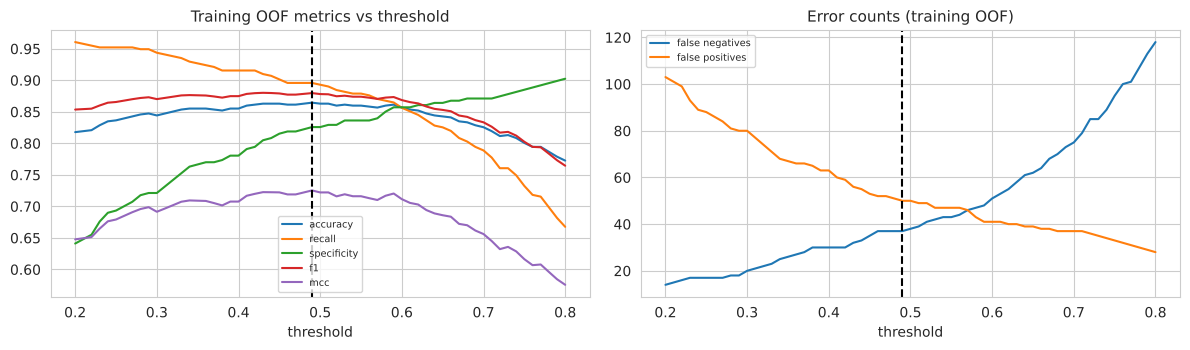

In [55]:
pol, TT_tr = threshold_policies(y_train, FINAL_REP["chosen_oof"])
THR_POLICIES = pd.DataFrame([{"policy": k, "threshold": v, **{m: TT_tr.loc[(TT_tr.threshold - v).abs().idxmin(), m]
                                for m in ["accuracy", "recall", "specificity", "precision", "f1", "mcc", "fn", "fp"]}}
                             for k, v in pol.items() if not pd.isna(v)])
print("Training out-of-fold (n = %d): counts are false negatives (missed disease) and false positives" % len(y_train))
display(THR_POLICIES.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for m in ["accuracy", "recall", "specificity", "f1", "mcc"]:
    ax[0].plot(TT_tr.threshold, TT_tr[m], label=m)
ax[0].axvline(FINAL_REP["threshold"], color="k", ls="--"); ax[0].set(xlabel="threshold", title="Training OOF metrics vs threshold"); ax[0].legend(fontsize=7)
ax[1].plot(TT_tr.threshold, TT_tr.fn, label="false negatives"); ax[1].plot(TT_tr.threshold, TT_tr.fp, label="false positives")
ax[1].axvline(FINAL_REP["threshold"], color="k", ls="--"); ax[1].set(xlabel="threshold", title="Error counts (training OOF)"); ax[1].legend(fontsize=7)
savefig("threshold_analysis")

### 21.2 The final model on the test set, with references
* **Final model.** It was already scored above, at its training-OOF threshold. The other threshold policies are shown for transparency only.
* **References:**
  * the corrected baseline (original XGBoost configuration) at 0.5;
  * default logistic regression;
  * the previous notebook's final model (tuned KNN).
* **Paired tests.** McNemar and bootstrap compare the final model with the corrected baseline. They are **optimistic for the final model**, because it was selected on this test set.

In [56]:
base_fitted, BM, b_pred, b_score = fit_and_test("XGBoost (original)", "Corrected baseline (original configs)",
                                                 PIPES[("Corrected baseline (original configs)", "XGBoost (original)")], purpose="reference: corrected baseline")
lr_fitted, LM, l_pred, l_score = fit_and_test("Logistic Regression", "Corrected baseline (original configs)",
                                              PIPES[("Corrected baseline (original configs)", "Logistic Regression")], purpose="reference: simple model")
prev_fitted, PM, p_pred, p_score = fit_and_test("Previous final: KNN (k=10, distance, p=1)", "Reference",
                                                make_pipe(KNeighborsClassifier(10, weights="distance", p=1)), purpose="reference: previous notebook's final model")
yt = TEST.y
TEST_THRESHOLDS = pd.DataFrame([{"policy (thresholds fixed on training OOF)": k, "threshold": v,
                                 **{m: compute_metrics(yt, (f_score >= v).astype(int), f_score)[m] for m in ["accuracy", "recall", "specificity", "f1", "mcc", "fn", "fp"]}}
                                for k, v in pol.items() if not pd.isna(v)])
print("Final model on the test set under each threshold policy (only the pre-declared MCC policy is the reported result):")
display(TEST_THRESHOLDS.round(3))

  TEST XGBoost (original)                                 acc 0.837  F1 0.847  MCC 0.676  AUC 0.922  sens 0.814  spec 0.866
  TEST Logistic Regression                                acc 0.864  F1 0.877  MCC 0.725  AUC 0.937  sens 0.873  spec 0.854
  TEST Previous final: KNN (k=10, distance, p=1)          acc 0.864  F1 0.879  MCC 0.724  AUC 0.920  sens 0.892  spec 0.829


Final model on the test set under each threshold policy (only the pre-declared MCC policy is the reported result):


,policy (thresholds fixed on training OOF),threshold,accuracy,recall,specificity,f1,mcc,fn,fp
0,default 0.5,0.50,0.880,0.902,0.854,0.893,0.758,10,12
1,max MCC (pre-declared),0.49,0.880,0.902,0.854,0.893,0.758,10,12
2,max F1,0.43,0.880,0.912,0.841,0.894,0.758,9,13
3,max balanced accuracy (Youden J),0.59,0.870,0.873,0.866,0.881,0.737,13,11
4,max precision with recall >= 0.80,0.68,0.880,0.853,0.915,0.888,0.763,15,7
5,sensitivity >= 0.90 (highest such threshold),0.45,0.886,0.912,0.854,0.899,0.769,9,12
6,specificity >= 0.90 (lowest such threshold),0.80,0.859,0.775,0.963,0.859,0.738,23,3


In [57]:
def summarize(label, m, pred, score):
    ci = bootstrap_ci(yt, pred, score)
    lo, hi = wilson(m["tp"] + m["tn"], m["n"])
    return {"model": label, "accuracy": m["accuracy"], "accuracy 95% CI (Wilson)": f"[{lo:.3f}, {hi:.3f}]",
            "precision": m["precision"], "recall/sensitivity": m["recall"], "specificity": m["specificity"], "F1 (positive class)": m["f1"],
            "macro F1": m["f1_macro"], "balanced accuracy": m["balanced_accuracy"], "MCC": m["mcc"], "MCC 95% CI": f"[{ci['mcc'][0]:.3f}, {ci['mcc'][1]:.3f}]",
            "ROC-AUC": m["roc_auc"], "AUC 95% CI": f"[{ci['roc_auc'][0]:.3f}, {ci['roc_auc'][1]:.3f}]", "PR-AUC": m["pr_auc"], "Brier": m["brier"],
            "TP": m["tp"], "FP": m["fp"], "TN": m["tn"], "FN": m["fn"]}
FINAL_SUMMARY = pd.DataFrame([summarize(f"FINAL: {FINAL_REP['chosen']} (threshold {FINAL_REP['threshold']:.2f})", FM, f_pred, f_score),
                              summarize("Corrected baseline: XGBoost (original config)", BM, b_pred, b_score),
                              summarize("Corrected baseline: Logistic Regression", LM, l_pred, l_score),
                              summarize("Previous final model: tuned KNN", PM, p_pred, p_score)])
display(FINAL_SUMMARY.round(3))

b01 = int(((f_pred == yt) & (b_pred != yt)).sum()); b10 = int(((f_pred != yt) & (b_pred == yt)).sum())
mc = mcnemar([[0, b01], [b10, 0]], exact=True)
rng = np.random.default_rng(SEED); dm, da = [], []
for _ in range(CFG["n_boot"]):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) < 2:
        continue
    dm.append(matthews_corrcoef(yt[idx], f_pred[idx]) - matthews_corrcoef(yt[idx], b_pred[idx]))
    da.append(roc_auc_score(yt[idx], f_score[idx]) - roc_auc_score(yt[idx], b_score[idx]))
print(f"McNemar exact test (final vs corrected baseline; optimistic, final chosen on this test set): final right / baseline wrong = {b01}, final wrong / baseline right = {b10}, p = {mc.pvalue:.3f}")
print(f"Paired bootstrap: delta MCC = {FM['mcc'] - BM['mcc']:+.3f}  95% CI [{np.percentile(dm, 2.5):+.3f}, {np.percentile(dm, 97.5):+.3f}];  "
      f"delta AUC = {FM['roc_auc'] - BM['roc_auc']:+.3f}  95% CI [{np.percentile(da, 2.5):+.3f}, {np.percentile(da, 97.5):+.3f}]")
PAIRED = {"b01": b01, "b10": b10, "mcnemar_p": mc.pvalue, "dMCC": FM["mcc"] - BM["mcc"], "dMCC_lo": np.percentile(dm, 2.5), "dMCC_hi": np.percentile(dm, 97.5),
          "dAUC": FM["roc_auc"] - BM["roc_auc"], "dAUC_lo": np.percentile(da, 2.5), "dAUC_hi": np.percentile(da, 97.5)}

,model,accuracy,accuracy 95% CI (Wilson),precision,recall/sensitivity,specificity,F1 (positive class),macro F1,balanced accuracy,MCC,MCC 95% CI,ROC-AUC,AUC 95% CI,PR-AUC,Brier,TP,FP,TN,FN
0,FINAL: Logistic regression (default settings) ...,0.880,"[0.826, 0.920]",0.885,0.902,0.854,0.893,0.879,0.878,0.758,"[0.658, 0.847]",0.944,"[0.908, 0.973]",0.951,0.089,92,12,70,10
1,Corrected baseline: XGBoost (original config),0.837,"[0.777, 0.883]",0.883,0.814,0.866,0.847,0.836,0.840,0.676,"[0.564, 0.773]",0.922,"[0.879, 0.956]",0.923,0.117,83,11,71,19
2,Corrected baseline: Logistic Regression,0.864,"[0.807, 0.906]",0.881,0.873,0.854,0.877,0.863,0.863,0.725,"[0.625, 0.824]",0.937,"[0.899, 0.968]",0.947,0.097,89,12,70,13
3,Previous final model: tuned KNN,0.864,"[0.807, 0.906]",0.867,0.892,0.829,0.879,0.862,0.861,0.724,"[0.625, 0.824]",0.920,"[0.877, 0.959]",0.916,0.104,91,14,68,11


McNemar exact test (final vs corrected baseline; optimistic, final chosen on this test set): final right / baseline wrong = 13, final wrong / baseline right = 5, p = 0.096
Paired bootstrap: delta MCC = +0.082  95% CI [-0.001, +0.174];  delta AUC = +0.022  95% CI [+0.003, +0.043]


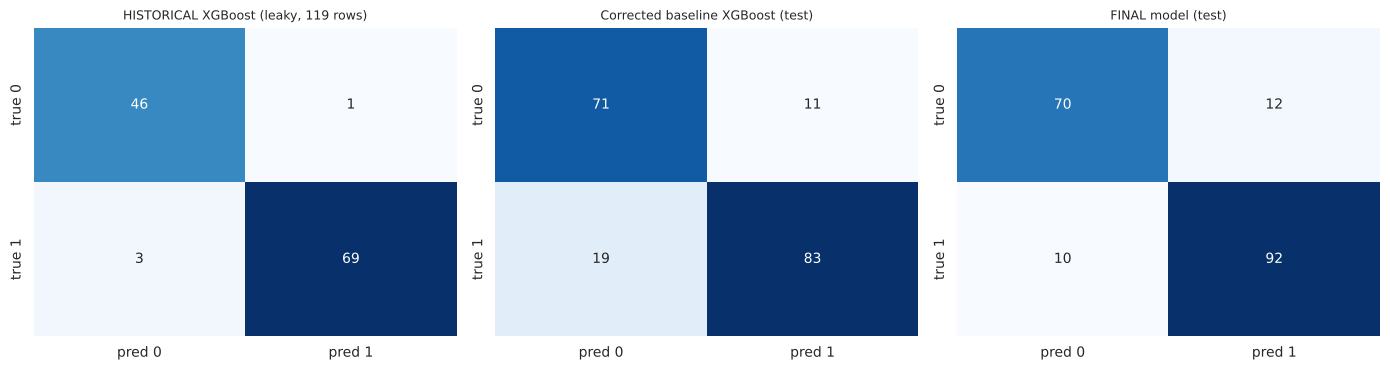

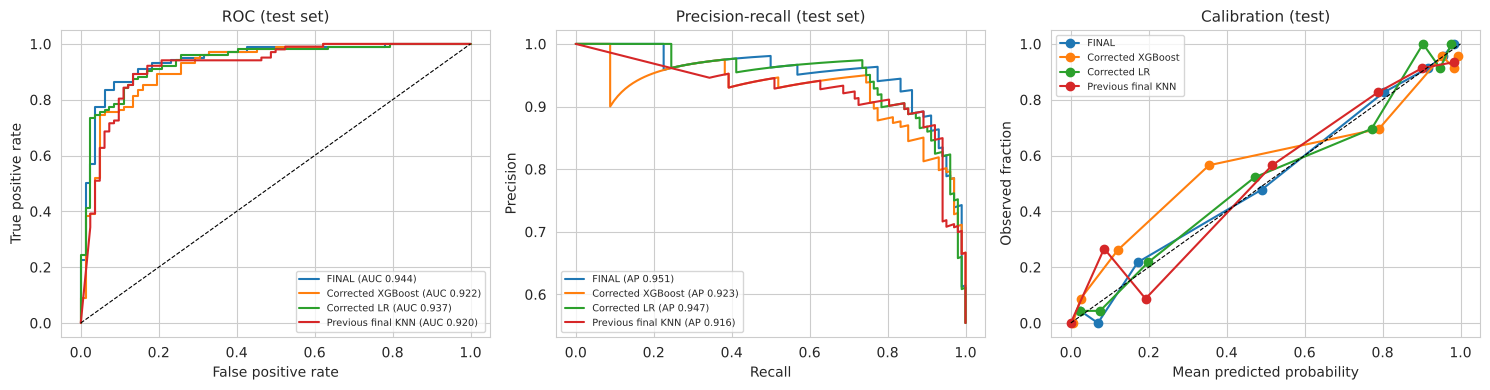

Exploratory view: the highest training-CV configuration across all experiments was [Tuned (Optuna)] KNN (Optuna) (CV MCC 0.749). It is NOT used as the final model, because picking the maximum of hundreds of CV scores is itself optimistic.


,experiment,config,cv_accuracy,cv_f1,cv_mcc,cv_mcc_sd,cv_roc_auc
0,Tuned (Optuna),KNN (Optuna),0.875,0.887,0.749,0.063,0.906
1,Ensembles,Bagging of KNN (30 replicas),0.875,0.889,0.749,0.070,0.911
2,Ensembles,Hard voting (top 5),0.870,0.885,0.738,0.078,0.887
3,Ensembles,Soft voting (top 5),0.870,0.885,0.738,0.071,0.923
4,Ensembles,"Weighted average, OOF-learned weights (top 5)",0.869,0.885,0.737,0.079,0.924
5,Combination,SVM-RBF | None | RUS,0.869,0.884,0.736,0.078,0.911
6,Combination,SVM-RBF | Variance threshold 0.006 (original) ...,0.869,0.884,0.736,0.078,0.911
7,Balancing,SVM-RBF | RUS,0.869,0.884,0.736,0.078,0.911
8,Ensembles,"Calibrated soft voting (isotonic, top 3)",0.868,0.886,0.736,0.081,0.919
9,Ensembles,"Stacking, LR meta on OOF (top 5)",0.868,0.884,0.735,0.072,0.923


In [58]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (title, yy, pp) in zip(ax, [("HISTORICAL XGBoost (leaky, 119 rows)", yte_h1, pred_h1),
                                    ("Corrected baseline XGBoost (test)", yt, b_pred), ("FINAL model (test)", yt, f_pred)]):
    sns.heatmap(confusion_matrix(yy, pp, labels=[0, 1]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"]); a.set_title(title, fontsize=9)
savefig("confusion_matrices")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for label, s in [("FINAL", f_score), ("Corrected XGBoost", b_score), ("Corrected LR", l_score), ("Previous final KNN", p_score)]:
    fpr, tpr, _ = roc_curve(yt, s); ax[0].plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(yt, s):.3f})")
    pr, rc, _ = precision_recall_curve(yt, s); ax[1].plot(rc, pr, label=f"{label} (AP {average_precision_score(yt, s):.3f})")
    fp_, mp_ = calibration_curve(yt, np.clip(s, 0, 1), n_bins=8, strategy="quantile"); ax[2].plot(mp_, fp_, marker="o", label=label)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (test set)")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (test set)")
ax[2].plot([0, 1], [0, 1], "k--", lw=0.8); ax[2].set(xlabel="Mean predicted probability", ylabel="Observed fraction", title="Calibration (test)")
for a in ax: a.legend(fontsize=7)
savefig("roc_pr_calibration")

cand = cv_table([e for e in pd.DataFrame(CV_RESULTS).experiment.unique()])
best = cand.iloc[0]
print("Exploratory view: the highest training-CV configuration across all experiments was", f"[{best['experiment']}] {best['config']}",
      f"(CV MCC {best['cv_mcc']:.3f}). It is NOT used as the final model, because picking the maximum of hundreds of CV scores is itself optimistic.")
display(cand[["experiment", "config", "cv_accuracy", "cv_f1", "cv_mcc", "cv_mcc_sd", "cv_roc_auc"]].head(15).round(3))

### 21.3 Freezing the final model
Everything that defines the final model is written to a manifest with a SHA-256 fingerprint:
* the chosen candidate, its members and hyperparameters, and its threshold;
* the preprocessing (inside the pipeline);
* the configuration, the seed, the split fractions and the split fingerprint;
* the hash of the component module.

The fitted model is saved alongside. From here on nothing about the model may change. Sections 22 to 27 only describe it. Section 29 trains and freezes the LSRO-ML-HDPM models separately, using the same training data.

In [59]:
def _jsonable(o):
    return json.loads(json.dumps(o, default=str))
FROZEN = {"final_model": FINAL_REP["chosen"], "threshold": float(FINAL_REP["threshold"]),
          "members": _jsonable({n: FINAL_REP["tuned"].get(n, "fixed configuration") for n, _ in FINAL_MODEL.members}),
          "method": FINAL_MODEL.method, "selection_rule": "highest test MCC among the pre-declared shortlist; ties by test ROC-AUC",
          "shortlist": list(SHORTLIST), "run_mode": RUN_MODE, "seed": SEED, "config": _jsonable(CFG),
          "split_fractions": SPLIT_FRACTIONS, "split_fingerprint": VAL_GROUPS_SHA,
          "n_train": int(len(y_train)), "n_test": int(len(TEST.y)), "n_validation": int(VAULT.n),
          "components_sha256": hashlib.sha256(open("hd_components.py", "rb").read()).hexdigest(),
          "validation_models": ["FINAL (the reported result)", "Corrected baseline XGBoost (reference, pre-declared)"]}
FROZEN["sha256"] = hashlib.sha256(json.dumps(FROZEN, sort_keys=True).encode()).hexdigest()
FROZEN_CORE = {k: FROZEN[k] for k in ["final_model", "threshold", "members", "method", "shortlist"]}   # checked again in Section 29.4
json.dump(FROZEN, open(os.path.join(OUT, "frozen_final_model_manifest.json"), "w"), indent=2)
try:
    import joblib
    joblib.dump(final_fitted, os.path.join(OUT, "frozen_final_model.joblib"))
except Exception as e:
    print("Model file not saved:", e)
print(f"Frozen: {FROZEN['final_model']} @ threshold {FROZEN['threshold']:.2f} | manifest fingerprint {FROZEN['sha256'][:16]}")

Frozen: Logistic regression (default settings) @ threshold 0.49 | manifest fingerprint a5d230f9aa6857ea


---
## 22. Subgroup analysis: age groups, sex and hospital
Two views: (1) the test set (unbiased but small groups, so wide intervals) and (2) out-of-fold predictions on the training set from group-aware CV (more patients per group). Subgroup results are descriptive; they are not used for any choice.

,data,dimension,model,group,n,prevalence,accuracy,sensitivity,specificity,f1,mcc,roc_auc,accuracy 95% CI
5,test set,age_group,Corrected baseline XGBoost,<45,31,0.258,0.935,0.750,1.000,0.857,0.831,0.978,"[0.79, 0.98]"
4,test set,age_group,Corrected baseline XGBoost,45-54,57,0.526,0.877,0.867,0.889,0.881,0.755,0.968,"[0.77, 0.94]"
6,test set,age_group,Corrected baseline XGBoost,55-64,77,0.701,0.831,0.833,0.826,0.874,0.627,0.919,"[0.73, 0.90]"
7,test set,age_group,Corrected baseline XGBoost,65+,19,0.526,0.579,0.600,0.556,0.600,0.156,0.611,"[0.36, 0.77]"
1,test set,age_group,FINAL,<45,31,0.258,0.935,0.750,1.000,0.857,0.831,0.978,"[0.79, 0.98]"
0,test set,age_group,FINAL,45-54,57,0.526,0.895,0.933,0.852,0.903,0.790,0.985,"[0.79, 0.95]"
2,test set,age_group,FINAL,55-64,77,0.701,0.896,0.944,0.783,0.927,0.747,0.931,"[0.81, 0.95]"
3,test set,age_group,FINAL,65+,19,0.526,0.684,0.700,0.667,0.700,0.367,0.744,"[0.46, 0.85]"
24,training out-of-fold,age_group,Corrected baseline XGBoost,<45,131,0.336,0.863,0.818,0.885,0.800,0.696,0.946,"[0.79, 0.91]"
25,training out-of-fold,age_group,Corrected baseline XGBoost,45-54,207,0.454,0.836,0.862,0.814,0.827,0.673,0.927,"[0.78, 0.88]"


,data,dimension,model,group,n,prevalence,accuracy,sensitivity,specificity,f1,mcc,roc_auc,accuracy 95% CI
8,test set,sex,FINAL,female,47,0.255,0.830,0.667,0.886,0.667,0.552,0.867,"[0.70, 0.91]"
9,test set,sex,FINAL,male,137,0.657,0.898,0.933,0.830,0.923,0.771,0.949,"[0.84, 0.94]"
10,test set,sex,Corrected baseline XGBoost,female,47,0.255,0.745,0.333,0.886,0.400,0.254,0.814,"[0.60, 0.85]"
11,test set,sex,Corrected baseline XGBoost,male,137,0.657,0.869,0.878,0.851,0.898,0.716,0.922,"[0.80, 0.92]"
12,test set,hospital,FINAL,Hungary,61,0.344,0.951,0.905,0.975,0.927,0.890,0.985,"[0.87, 0.98]"
13,test set,hospital,FINAL,Switzerland,27,0.926,0.889,0.920,0.500,0.939,0.350,0.860,"[0.72, 0.96]"
14,test set,hospital,FINAL,Long Beach VA,40,0.725,0.875,0.966,0.636,0.918,0.672,0.922,"[0.74, 0.95]"
15,test set,hospital,FINAL,Cleveland,56,0.482,0.804,0.815,0.793,0.800,0.608,0.876,"[0.68, 0.89]"
16,test set,hospital,Corrected baseline XGBoost,Hungary,61,0.344,0.918,0.810,0.975,0.872,0.817,0.986,"[0.82, 0.96]"
17,test set,hospital,Corrected baseline XGBoost,Switzerland,27,0.926,0.852,0.880,0.500,0.917,0.280,0.820,"[0.68, 0.94]"


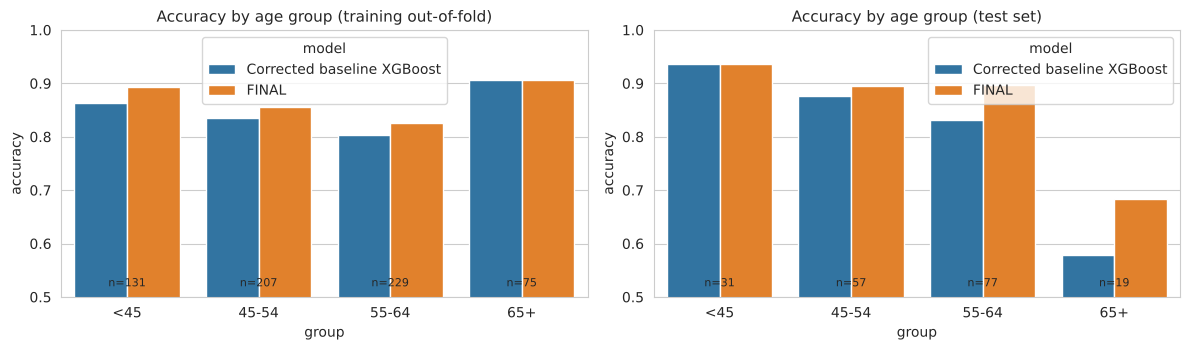

In [60]:
def oof_predictions(pipe, X=None, y=None, groups=None, seed_offset=0):
    X = X_train if X is None else X; y = y_train if y is None else y; groups = g_train if groups is None else groups
    pred = np.zeros(len(y), int); score = np.zeros(len(y))
    for tr, va in make_cv(CFG["cv_splits"], SEED + seed_offset, groups).split(X, y, groups):
        m = clone(pipe).fit(X.iloc[tr], y[tr]); pred[va] = m.predict(X.iloc[va]); score[va] = scores_of(m, X.iloc[va])
    return pred, score

def subgroup_table(y, pred, score, groups_series, label, with_ci=True):
    rows = []
    for g in groups_series.dropna().unique():
        mask = (groups_series == g).to_numpy()
        if mask.sum() < 5:
            continue
        m = compute_metrics(y[mask], pred[mask], score[mask])
        row = {"model": label, "group": g, "n": int(mask.sum()), "prevalence": y[mask].mean(), "accuracy": m["accuracy"],
               "sensitivity": m["recall"], "specificity": m["specificity"], "f1": m["f1"], "mcc": m["mcc"], "roc_auc": m["roc_auc"]}
        if with_ci and len(np.unique(y[mask])) == 2 and min(np.bincount(y[mask])) >= 2:
            lo, hi = wilson(m["tp"] + m["tn"], m["n"]); row["accuracy 95% CI"] = f"[{lo:.2f}, {hi:.2f}]"
        rows.append(row)
    return pd.DataFrame(rows)

SUBGROUPS = []
for dim in ["age_group", "sex", "hospital"]:
    gs = TEST.meta[dim].astype(str) if dim != "sex" else TEST.meta[dim].map({0: "female", 1: "male"})
    for label, p, s in [("FINAL", f_pred, f_score), ("Corrected baseline XGBoost", b_pred, b_score)]:
        t = subgroup_table(yt, p, s, gs, label); t.insert(0, "dimension", dim); t.insert(0, "data", "test set"); SUBGROUPS.append(t)
oof_final = oof_predictions(PIPES[(FINAL_EXP, FINAL_LABEL)])
oof_base = oof_predictions(PIPES[("Corrected baseline (original configs)", "XGBoost (original)")])
for dim in ["age_group", "sex", "hospital"]:
    gs = meta_train[dim].astype(str) if dim != "sex" else meta_train[dim].map({0: "female", 1: "male"})
    for label, (p, s) in [("FINAL", oof_final), ("Corrected baseline XGBoost", oof_base)]:
        t = subgroup_table(y_train, p, s, gs, label); t.insert(0, "dimension", dim); t.insert(0, "data", "training out-of-fold"); SUBGROUPS.append(t)
SUBGROUPS = pd.concat(SUBGROUPS, ignore_index=True)
order = {g: i for i, g in enumerate(AGE_LABELS)}
age_view = SUBGROUPS[SUBGROUPS.dimension == "age_group"].sort_values(["data", "model", "group"], key=lambda s: s.map(order) if s.name == "group" else s)
display(age_view.round(3))
display(SUBGROUPS[SUBGROUPS.dimension != "age_group"].round(3))
SUBGROUPS.to_csv(os.path.join(OUT, "subgroup_results.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, data in zip(ax, ["training out-of-fold", "test set"]):
    t = age_view[age_view.data == data]
    sns.barplot(data=t, x="group", y="accuracy", hue="model", order=AGE_LABELS, ax=a)
    a.set_ylim(0.5, 1); a.set_title(f"Accuracy by age group ({data})")
    for i, g in enumerate(AGE_LABELS):
        n = t[(t.group == g)]["n"].max()
        if not np.isnan(n): a.text(i, 0.52, f"n={int(n)}", ha="center", fontsize=8)
savefig("age_group_performance")

---
## 23. Cross-hospital generalisation
A random split mixes patients from the same hospitals into training and test. A stricter test of generalisation is to train on some hospitals and test on a hospital the model has never seen.

* **Leave-one-hospital-out (LOHO)**: the **826 unique development records** (training + test; the validation patients are excluded) are grouped into Cleveland (including Statlog), Hungary, Long Beach VA and Switzerland. Each hospital in turn is the test set. The model configurations are fixed in advance (the frozen final model and the corrected baseline from Section 21; this analysis is not used for any choice). Switzerland has 115 positives and only 8 negatives, so its specificity, MCC and AUC are very unstable, and its cholesterol is entirely missing.
* P2's own cross-dataset test (train on Cleveland, test on Hungarian-98 and VA-93) is reproduced **exactly** with the authors' files in Section 15.2c.

,held-out hospital,model,n test,test prevalence,accuracy,recall,specificity,f1,mcc,roc_auc
0,Cleveland,"FINAL (frozen configuration, refitted per fold)",273,0.454,0.777,0.766,0.785,0.757,0.550,0.844
1,Cleveland,Corrected baseline XGBoost,273,0.454,0.744,0.774,0.718,0.733,0.490,0.790
2,Cleveland,LR (improved prep),273,0.454,0.777,0.758,0.792,0.755,0.550,0.844
3,Cleveland,RF 300 (improved prep),273,0.454,0.729,0.790,0.678,0.726,0.467,0.808
4,Hungary,"FINAL (frozen configuration, refitted per fold)",264,0.364,0.886,0.885,0.887,0.850,0.760,0.951
5,Hungary,Corrected baseline XGBoost,264,0.364,0.871,0.885,0.863,0.833,0.732,0.937
6,Hungary,LR (improved prep),264,0.364,0.890,0.885,0.893,0.854,0.768,0.951
7,Hungary,RF 300 (improved prep),264,0.364,0.909,0.917,0.905,0.880,0.809,0.947
8,Long Beach VA,"FINAL (frozen configuration, refitted per fold)",178,0.753,0.893,0.970,0.659,0.932,0.698,0.857
9,Long Beach VA,Corrected baseline XGBoost,178,0.753,0.820,0.903,0.568,0.883,0.496,0.824


,mean accuracy over hospitals,mean f1 over hospitals,mean mcc over hospitals,mean roc_auc over hospitals
model,,,,
Corrected baseline XGBoost,0.800,0.828,0.457,0.820
"FINAL (frozen configuration, refitted per fold)",0.837,0.854,0.569,0.865
LR (improved prep),0.837,0.854,0.567,0.865
RF 300 (improved prep),0.815,0.843,0.526,0.840


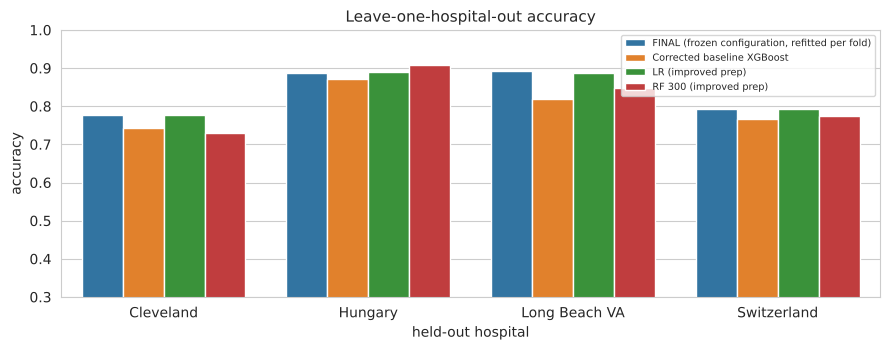

In [61]:
uniq = df.drop_duplicates(FEATURES + [TARGET]).reset_index(drop=True)
HOSP = ["Cleveland", "Hungary", "Long Beach VA", "Switzerland"]
loho_models = {"FINAL (frozen configuration, refitted per fold)": PIPES[(FINAL_EXP, FINAL_LABEL)],
               "Corrected baseline XGBoost": PIPES[("Corrected baseline (original configs)", "XGBoost (original)")],
               "LR (improved prep)": make_pipe(LogisticRegression(max_iter=2000, random_state=SEED)),
               "RF 300 (improved prep)": make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1))}
rows = []
for h in tqdm(HOSP, desc="leave-one-hospital-out"):
    tr, te = uniq[uniq.hospital != h], uniq[uniq.hospital == h]
    for name, pipe in loho_models.items():
        m = clone(pipe).fit(tr[FEATURES], tr[TARGET].to_numpy())
        mm = compute_metrics(te[TARGET].to_numpy(), m.predict(te[FEATURES]), scores_of(m, te[FEATURES]))
        rows.append({"held-out hospital": h, "model": name, "n test": len(te), "test prevalence": te[TARGET].mean(),
                     **{k: mm[k] for k in ["accuracy", "recall", "specificity", "f1", "mcc", "roc_auc"]}})
LOHO = pd.DataFrame(rows)
display(LOHO.round(3))
display(LOHO.groupby("model")[["accuracy", "f1", "mcc", "roc_auc"]].mean().round(3).rename(columns=lambda c: f"mean {c} over hospitals"))
plt.figure(figsize=(9, 3.6))
sns.barplot(data=LOHO, x="held-out hospital", y="accuracy", hue="model"); plt.ylim(0.3, 1); plt.title("Leave-one-hospital-out accuracy")
plt.legend(fontsize=7); savefig("loho_accuracy")
LOHO.to_csv(os.path.join(OUT, "cross_hospital_loho.csv"), index=False)

---
## 24. Why has accuracy plateaued? Diagnostic experiments
Many very different methods land at almost the same corrected performance. The experiments below test the possible explanations directly, instead of speculating. Each result is labelled as an **observation**; possible explanations are given separately in the conclusions.

1. **Learning curves**: does performance still rise as training data grows (more data would help), or has it flattened?
2. **Complexity curves**: does more model capacity help, or does the gap between training and CV performance just widen (overfitting)?
3. **Class overlap**: how many patients sit in neighbourhoods dominated by the other class?
4. **Consensus errors**: how many patients are misclassified by almost every tuned model? These set a practical ceiling for any model built from these 11 variables.
5. **Error correlation**: if all models make the same mistakes, an ensemble cannot fix them.
6. **Hospital shift**: can a model tell which hospital a patient came from using only the clinical variables? If so, the feature distributions differ by site.

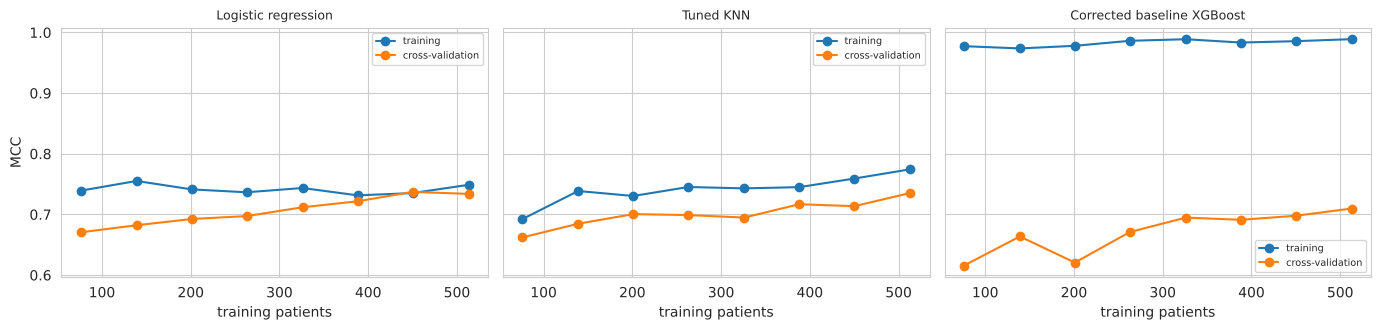

CV MCC gained per extra 100 training patients over the second half of the curve:


,MCC per +100 patients
model,
Corrected baseline XGBoost,0.0080
Logistic regression,0.0118
Tuned KNN,0.0216


In [62]:
lc_models = {"Logistic regression": make_pipe(LogisticRegression(max_iter=2000, random_state=SEED)),
             f"Tuned {ranked[0]}": make_pipe(build_model(ranked[0], TUNED[ranked[0]])),
             "Corrected baseline XGBoost": PIPES[("Corrected baseline (original configs)", "XGBoost (original)")]}
sizes = np.linspace(0.15, 1.0, CFG["curve_points"])
LC = []
for name, est in tqdm(list(lc_models.items()), desc="learning curves"):
    ns, tr_s, va_s = learning_curve(est, X_train, y_train, groups=g_train, train_sizes=sizes, cv=make_cv(5, SEED + 70, g_train),
                                    scoring=SCORING["mcc"], n_jobs=N_JOBS, shuffle=True, random_state=SEED)
    for n_, a_, b_ in zip(ns, tr_s.mean(1), va_s.mean(1)):
        LC.append({"model": name, "training patients": int(n_), "training MCC": a_, "CV MCC": b_})
LC = pd.DataFrame(LC)
fig, ax = plt.subplots(1, len(lc_models), figsize=(14, 3.4), sharey=True)
for a, (name, g) in zip(ax, LC.groupby("model", sort=False)):
    a.plot(g["training patients"], g["training MCC"], marker="o", label="training"); a.plot(g["training patients"], g["CV MCC"], marker="o", label="cross-validation")
    a.set_title(name, fontsize=9); a.set_xlabel("training patients"); a.legend(fontsize=7)
ax[0].set_ylabel("MCC"); savefig("learning_curves")
slope = LC.groupby("model").apply(lambda g: (g["CV MCC"].iloc[-1] - g["CV MCC"].iloc[len(g) // 2]) / (g["training patients"].iloc[-1] - g["training patients"].iloc[len(g) // 2]) * 100)
print("CV MCC gained per extra 100 training patients over the second half of the curve:"); display(slope.round(4).rename("MCC per +100 patients").to_frame())

,model,setting,training MCC,CV MCC
0,XGBoost max_depth,1,0.758,0.728
1,XGBoost max_depth,2,0.848,0.743
2,XGBoost max_depth,3,0.928,0.731
3,XGBoost max_depth,4,0.981,0.725
4,XGBoost max_depth,6,0.998,0.736
5,XGBoost max_depth,8,1.000,0.717
6,XGBoost max_depth,10,0.999,0.730
7,KNN k (smaller = more complex),1,1.000,0.570
8,KNN k (smaller = more complex),3,0.811,0.670
9,KNN k (smaller = more complex),5,0.786,0.673


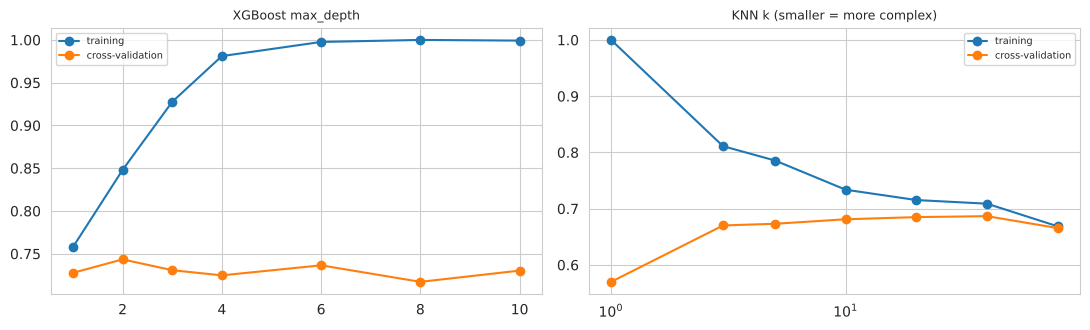

In [63]:
cx = []
for depth in tqdm([1, 2, 3, 4, 6, 8, 10], desc="complexity: XGBoost depth"):
    res = cross_validate(make_pipe(XGBClassifier(n_estimators=300, max_depth=depth, learning_rate=0.05, subsample=0.8, eval_metric="logloss",
                                                 random_state=SEED, n_jobs=1)), X_train, y_train, groups=g_train, cv=make_cv(5, SEED + 71, g_train),
                         scoring={"mcc": SCORING["mcc"]}, return_train_score=True, n_jobs=N_JOBS)
    cx.append({"model": "XGBoost max_depth", "setting": depth, "training MCC": res["train_mcc"].mean(), "CV MCC": res["test_mcc"].mean()})
for k_ in [1, 3, 5, 10, 20, 40, 80]:
    res = cross_validate(make_pipe(KNeighborsClassifier(k_)), X_train, y_train, groups=g_train, cv=make_cv(5, SEED + 71, g_train),
                         scoring={"mcc": SCORING["mcc"]}, return_train_score=True, n_jobs=N_JOBS)
    cx.append({"model": "KNN k (smaller = more complex)", "setting": k_, "training MCC": res["train_mcc"].mean(), "CV MCC": res["test_mcc"].mean()})
CX = pd.DataFrame(cx); display(CX.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, (name, g) in zip(ax, CX.groupby("model", sort=False)):
    a.plot(g.setting, g["training MCC"], marker="o", label="training"); a.plot(g.setting, g["CV MCC"], marker="o", label="cross-validation")
    a.set_title(name, fontsize=9); a.set_xscale("log" if "KNN" in name else "linear"); a.legend(fontsize=7)
savefig("complexity_curves")

Patients whose neighbourhood is dominated by the OTHER class (> 50% of 10 neighbours): 84 of 642 (13.1%)


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
disease,355.0,0.212,0.235,0.0,0.0,0.1,0.3,1.0
no disease,287.0,0.245,0.285,0.0,0.0,0.1,0.4,1.0


Patients misclassified by ALL 10 tuned models: 56 (8.7%); by at least 80% of them: 71 (11.1%); by none: 78.3%
=> an oracle that always picked the right model per patient would still miss 8.7%; the best single model misses 12.6%.


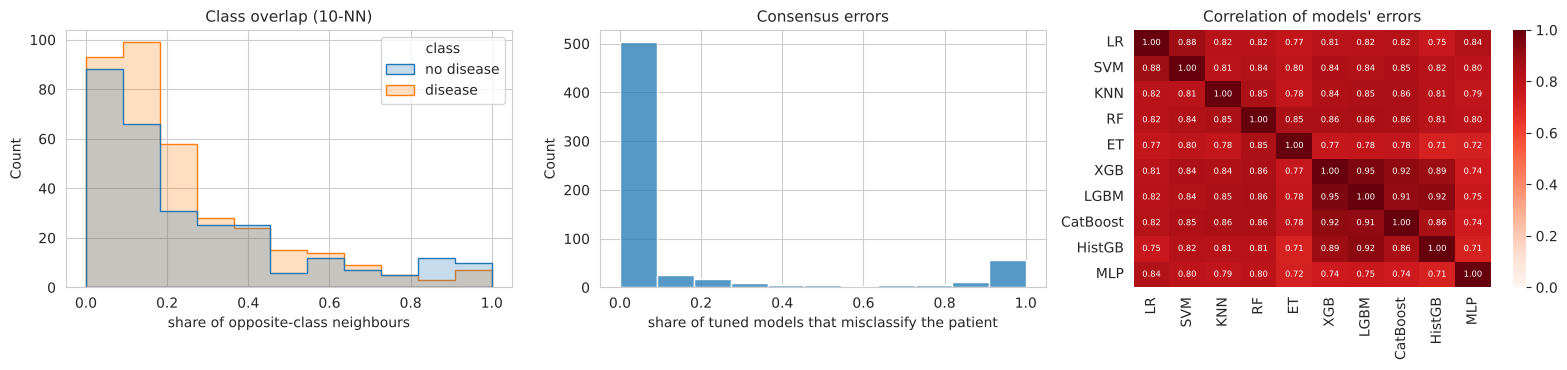

Mean pairwise correlation of the models' error indicators: 0.82


In [64]:
# Class overlap: share of each patient's 10 nearest neighbours (training data, encoded space) that have the opposite label
Z_all = prep_improved().fit(X_train).transform(X_train)
nbr = NearestNeighbors(n_neighbors=11).fit(Z_all).kneighbors(Z_all, return_distance=False)[:, 1:]
opp = (y_train[nbr] != y_train[:, None]).mean(1)
OVERLAP = pd.DataFrame({"class": np.where(y_train == 1, "disease", "no disease"), "share of opposite-class neighbours": opp})
print("Patients whose neighbourhood is dominated by the OTHER class (> 50% of 10 neighbours):",
      f"{(opp > 0.5).sum()} of {len(opp)} ({(opp > 0.5).mean():.1%})")
display(OVERLAP.groupby("class")["share of opposite-class neighbours"].describe().round(3))

# Consensus errors across the tuned models (out-of-fold predictions on the training data from autoselect)
OOFM = pd.DataFrame(FINAL_REP["oof"])
wrong = ((OOFM.to_numpy() >= 0.5).astype(int) != y_train[:, None])
frac_wrong = wrong.mean(1)
HARD = pd.DataFrame({"models wrong (share)": frac_wrong, "y": y_train})
print(f"Patients misclassified by ALL {wrong.shape[1]} tuned models: {(frac_wrong == 1).sum()} ({(frac_wrong == 1).mean():.1%}); "
      f"by at least 80% of them: {(frac_wrong >= 0.8).sum()} ({(frac_wrong >= 0.8).mean():.1%}); by none: {(frac_wrong == 0).mean():.1%}")
print(f"=> an oracle that always picked the right model per patient would still miss {(frac_wrong == 1).mean():.1%}; "
      f"the best single model misses {1 - max(accuracy_score(y_train, (OOFM[c] >= 0.5).astype(int)) for c in OOFM):.1%}.")
err_corr = pd.DataFrame(wrong.astype(float), columns=OOFM.columns).corr()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(OVERLAP, x="share of opposite-class neighbours", hue="class", bins=11, ax=ax[0], element="step"); ax[0].set_title("Class overlap (10-NN)")
sns.histplot(frac_wrong, bins=wrong.shape[1] + 1, ax=ax[1]); ax[1].set(xlabel="share of tuned models that misclassify the patient", title="Consensus errors")
sns.heatmap(err_corr, annot=True, fmt=".2f", cmap="Reds", ax=ax[2], vmin=0, vmax=1, annot_kws={"size": 6}); ax[2].set_title("Correlation of models' errors")
savefig("plateau_overlap_consensus")
print("Mean pairwise correlation of the models' error indicators:", round(err_corr.to_numpy()[np.triu_indices(len(err_corr), 1)].mean(), 3))

In [65]:
# Hospital shift: adversarial validation (predict the hospital from the 11 clinical variables)
Xh, yh = uniq_dev[FEATURES], uniq_dev["hospital"].to_numpy()
ph = cross_val_predict(make_pipe(RandomForestClassifier(300, random_state=SEED, n_jobs=1)), Xh, yh, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                       method="predict_proba", n_jobs=N_JOBS)
classes_h = np.unique(yh)
ADV = pd.DataFrame({"hospital": classes_h, "one-vs-rest AUC for recognising the hospital": [roc_auc_score(yh == c, ph[:, i]) for i, c in enumerate(classes_h)],
                    "patients": [int((yh == c).sum()) for c in classes_h], "disease prevalence": [uniq_dev.loc[yh == c, TARGET].mean() for c in classes_h]})
display(ADV.round(3))
ks_rows = []
for f in NUMERIC:
    for h in classes_h:
        a_ = uniq_dev.loc[yh == h, f].replace(0, np.nan).dropna() if f in ("cholesterol", "resting bp s") else uniq_dev.loc[yh == h, f]
        b_ = uniq_dev.loc[yh != h, f].replace(0, np.nan).dropna() if f in ("cholesterol", "resting bp s") else uniq_dev.loc[yh != h, f]
        if len(a_) > 5:
            ks_rows.append({"feature": f, "hospital": h, "KS statistic vs other hospitals": stats.ks_2samp(a_, b_).statistic})
KS = pd.DataFrame(ks_rows).pivot(index="feature", columns="hospital", values="KS statistic vs other hospitals")
display(KS.round(3))
print("Missing cholesterol by hospital:", uniq_dev.groupby("hospital")["cholesterol"].apply(lambda s: f"{(s == 0).mean():.0%}").to_dict())
DIAG = {"lc": LC, "complexity": CX, "overlap_share_gt_half": float((opp > 0.5).mean()), "all_models_wrong": float((frac_wrong == 1).mean()),
        "error_corr_mean": float(err_corr.to_numpy()[np.triu_indices(len(err_corr), 1)].mean())}
LC.to_csv(os.path.join(OUT, "diagnostic_learning_curves.csv"), index=False); CX.to_csv(os.path.join(OUT, "diagnostic_complexity_curves.csv"), index=False)
ADV.to_csv(os.path.join(OUT, "diagnostic_hospital_adversarial_validation.csv"), index=False); KS.to_csv(os.path.join(OUT, "diagnostic_hospital_ks.csv"))

,hospital,one-vs-rest AUC for recognising the hospital,patients,disease prevalence
0,Cleveland,0.925,273,0.454
1,Hungary,0.927,264,0.364
2,Long Beach VA,0.875,178,0.753
3,Switzerland,0.984,111,0.928


hospital,Cleveland,Hungary,Long Beach VA,Switzerland
feature,,,,
age,0.082,0.436,0.407,0.151
cholesterol,0.083,0.077,0.128,NaN
max heart rate,0.381,0.124,0.359,0.304
oldpeak,0.141,0.323,0.249,0.087
resting bp s,0.073,0.064,0.191,0.212


Missing cholesterol by hospital: {'Cleveland': '0%', 'Hungary': '0%', 'Long Beach VA': '25%', 'Switzerland': '100%'}


---
## 25. Error analysis and calibration
Which patients does the final model get wrong? The analysis uses the final configuration's **out-of-fold** predictions on the 642 training patients (more cases than the 184-patient test set) and the test predictions. It compares false negatives (disease missed) with true positives, and false positives with true negatives, using standardised mean differences (SMD; |SMD| > 0.5 is a large difference). It also shows where the errors concentrate by hospital, sex and age. Calibration is checked with reliability curves, the Brier score and the expected calibration error (ECE).

In [66]:
oof_p, oof_s = oof_final if "oof_final" in globals() else oof_predictions(PIPES[(FINAL_EXP, FINAL_LABEL)])
E = X_train.copy(); E["y"] = y_train; E["pred"] = oof_p; E["score"] = oof_s
E = pd.concat([E, meta_train[["hospital", "age_group"]].reset_index(drop=True)], axis=1)
E["outcome"] = np.select([(E.y == 1) & (E.pred == 1), (E.y == 1) & (E.pred == 0), (E.y == 0) & (E.pred == 1)], ["TP", "FN", "FP"], "TN")
def smd(a, b):
    s = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / s if s > 0 else 0.0
ER = []
for f in FEATURES:
    col = E[f].replace(0, np.nan) if f in ("cholesterol", "resting bp s") else E[f]
    ER.append({"feature": f, "mean FN": col[E.outcome == "FN"].mean(), "mean TP": col[E.outcome == "TP"].mean(), "SMD FN vs TP": smd(col[E.outcome == "FN"].dropna(), col[E.outcome == "TP"].dropna()),
               "mean FP": col[E.outcome == "FP"].mean(), "mean TN": col[E.outcome == "TN"].mean(), "SMD FP vs TN": smd(col[E.outcome == "FP"].dropna(), col[E.outcome == "TN"].dropna())})
ERR = pd.DataFrame(ER).set_index("feature")
print("Training out-of-fold outcome counts:", E.outcome.value_counts().to_dict())
display(ERR.round(3))
rates = E.groupby("hospital").apply(lambda g: pd.Series({"patients": len(g), "prevalence": g.y.mean(), "FN rate (missed / diseased)": ((g.outcome == "FN").sum() / max(1, (g.y == 1).sum())),
                                                        "FP rate (false alarms / healthy)": ((g.outcome == "FP").sum() / max(1, (g.y == 0).sum()))}))
display(rates.round(3))
print("Typical missed-disease profile (most common values among false negatives):")
display(E[E.outcome == "FN"][["chest pain type", "ST slope", "exercise angina", "sex"]].apply(lambda s: s.value_counts(normalize=True).round(2).to_dict()).to_frame("share"))
print("Locked test set: false negatives =", int(((f_pred == 0) & (yt == 1)).sum()), "| false positives =", int(((f_pred == 1) & (yt == 0)).sum()))

Training out-of-fold outcome counts: {'TP': 317, 'TN': 234, 'FP': 53, 'FN': 38}


,mean FN,mean TP,SMD FN vs TP,mean FP,mean TN,SMD FP vs TN
feature,,,,,,
age,52.579,56.407,-0.418,55.604,48.949,0.775
sex,0.816,0.912,-0.280,0.830,0.641,0.437
chest pain type,3.000,3.691,-0.798,3.302,2.654,0.693
resting bp s,129.263,135.521,-0.322,131.811,129.402,0.133
cholesterol,247.056,249.259,-0.038,246.864,237.961,0.170
fasting blood sugar,0.053,0.366,-0.831,0.151,0.111,0.118
resting ecg,0.842,0.631,0.244,0.887,0.483,0.480
max heart rate,153.026,125.050,1.259,139.132,151.457,-0.559
exercise angina,0.211,0.662,-1.017,0.509,0.077,1.071


,patients,prevalence,FN rate (missed / diseased),FP rate (false alarms / healthy)
hospital,,,,
Cleveland,217.0,0.447,0.247,0.225
Hungary,203.0,0.369,0.120,0.102
Long Beach VA,138.0,0.761,0.038,0.273
Switzerland,84.0,0.929,0.013,0.667


Typical missed-disease profile (most common values among false negatives):


,share
chest pain type,"{3: 0.37, 4: 0.37, 2: 0.16, 1: 0.11}"
ST slope,"{1: 0.61, 2: 0.32, 3: 0.08}"
exercise angina,"{0: 0.79, 1: 0.21}"
sex,"{1: 0.82, 0: 0.18}"


Locked test set: false negatives = 10 | false positives = 12


,model,data,Brier,ECE (10 quantile bins)
0,FINAL,training OOF,0.1090,0.0318
1,Corrected baseline XGBoost,training OOF,0.1187,0.0647
2,FINAL,test,0.0887,0.0233
3,Corrected baseline XGBoost,test,0.1168,0.0821


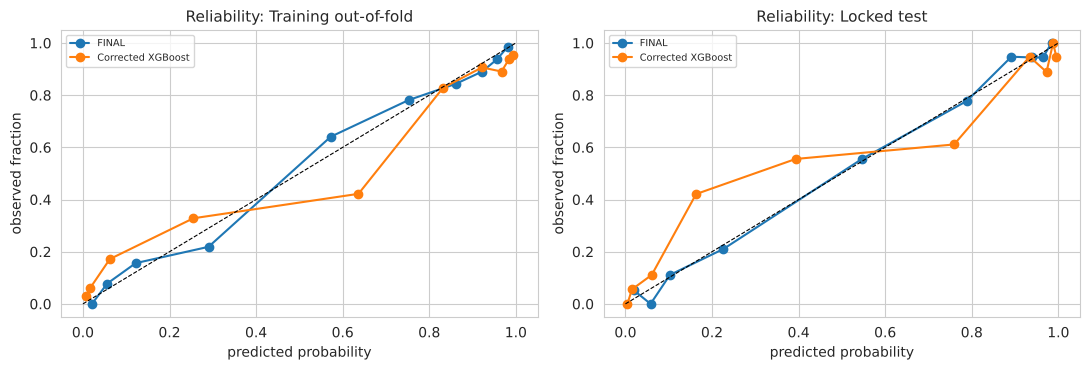

In [67]:
def ece(y, p, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1)); idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any()))
oof_b = oof_base
CAL = pd.DataFrame([{"model": n, "data": d, "Brier": brier_score_loss(yy, np.clip(pp, 0, 1)), "ECE (10 quantile bins)": ece(yy, np.clip(pp, 0, 1))}
                    for n, d, yy, pp in [("FINAL", "training OOF", y_train, oof_s), ("Corrected baseline XGBoost", "training OOF", y_train, oof_b[1]),
                                         ("FINAL", "test", yt, f_score), ("Corrected baseline XGBoost", "test", yt, b_score)]])
display(CAL.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (title, pairs) in zip(ax, [("Training out-of-fold", [("FINAL", y_train, oof_s), ("Corrected XGBoost", y_train, oof_b[1])]),
                                  ("Locked test", [("FINAL", yt, f_score), ("Corrected XGBoost", yt, b_score)])]):
    for n, yy, pp in pairs:
        fp_, mp_ = calibration_curve(yy, np.clip(pp, 0, 1), n_bins=10, strategy="quantile"); a.plot(mp_, fp_, marker="o", label=n)
    a.plot([0, 1], [0, 1], "k--", lw=0.8); a.set(title=f"Reliability: {title}", xlabel="predicted probability", ylabel="observed fraction"); a.legend(fontsize=7)
savefig("calibration_reliability")
ERR.to_csv(os.path.join(OUT, "error_analysis_smd.csv")); CAL.to_csv(os.path.join(OUT, "calibration.csv"), index=False)

---
## 26. Feature importance and SHAP explanations
* **Permutation importance** on the test set (drop in ROC-AUC when one raw feature is shuffled), for the final model and the corrected baseline. This explains the whole pipeline in terms of the 11 original variables.
* **SHAP**: TreeExplainer for tree models, a model-agnostic permutation explainer otherwise, on the encoded features the model actually receives. If the SHAP library fails for an XGBoost model, XGBoost's built-in exact SHAP contributions (`pred_contribs=True`) are used instead.
* Explanations describe what the models rely on; they are **not causal** and are not clinical evidence.

model,Corrected baseline XGBoost,FINAL
feature,,
ST slope,0.1290,0.0723
chest pain type,0.0339,0.0275
cholesterol,0.0058,0.0160
sex,0.0239,0.0151
oldpeak,0.0139,0.0074
fasting blood sugar,0.0147,0.0073
exercise angina,0.0086,0.0047
max heart rate,0.0058,-0.0002
resting ecg,0.0020,-0.0004


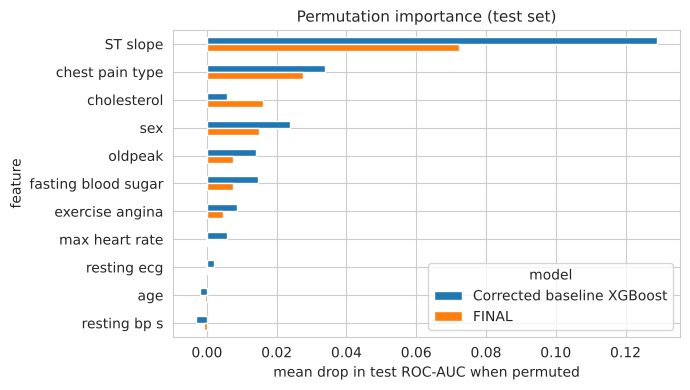

In [68]:
X_te_raw = TEST.raw_features_for_explanation()
def transform_for_model(fitted_pipe, X):
    Z, names = X, None
    for name, step in fitted_pipe.steps[:-1]:
        if hasattr(step, "fit_resample"):
            continue                                   # samplers act only during fit
        Z = step.transform(Z)
        if name == "prep":
            names = np.asarray(step.get_feature_names_out())
        elif hasattr(step, "get_support"):
            names = names[step.get_support()]
    return np.asarray(Z, dtype=float), names

PI = []
for label, fitted in [("FINAL", final_fitted), ("Corrected baseline XGBoost", base_fitted)]:
    r = permutation_importance(fitted, X_te_raw, yt, scoring="roc_auc", n_repeats=CFG["perm_repeats"], random_state=SEED, n_jobs=1)
    PI.append(pd.DataFrame({"model": label, "feature": FEATURES, "AUC drop (mean)": r.importances_mean, "sd": r.importances_std}))
PI = pd.concat(PI)
piv = PI.pivot(index="feature", columns="model", values="AUC drop (mean)").sort_values("FINAL", ascending=False)
display(piv.round(4))
piv.plot.barh(figsize=(7, 4)); plt.gca().invert_yaxis(); plt.xlabel("mean drop in test ROC-AUC when permuted")
plt.title("Permutation importance (test set)"); savefig("permutation_importance")
PI.to_csv(os.path.join(OUT, "permutation_importance.csv"), index=False)

FINAL: shap permutation explainer on raw variables, 150 test patients x 11 encoded features


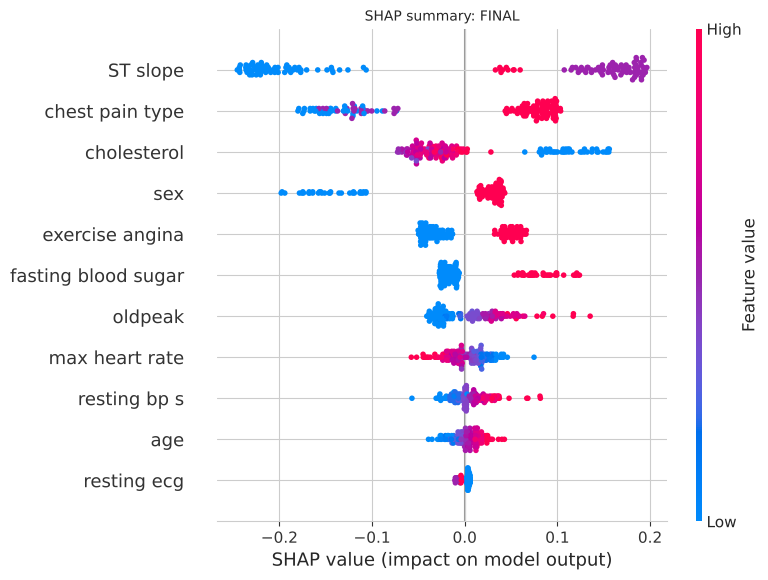

Corrected baseline XGBoost: shap.TreeExplainer, 184 test patients x 18 encoded features


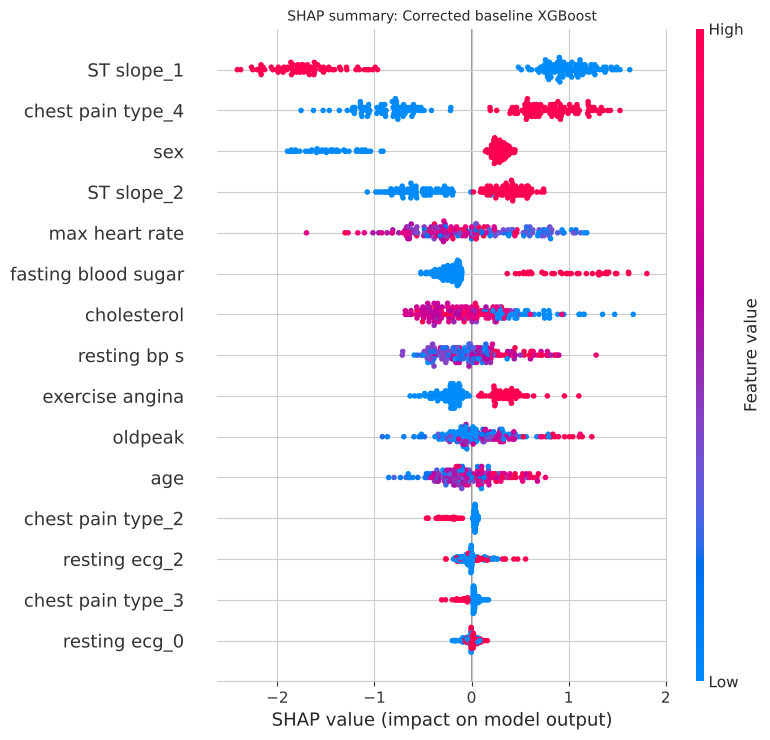

,FINAL,Corrected baseline XGBoost
ST slope,0.1738,NaN
ST slope_1,NaN,1.3022
ST slope_2,NaN,0.4659
ST slope_3,NaN,0.0000
age,0.0114,0.2486
chest pain type,0.1005,NaN
chest pain type_1,NaN,0.0074
chest pain type_2,NaN,0.0869
chest pain type_3,NaN,0.0521
chest pain type_4,NaN,0.8490


,XGBoost gain importance (corrected baseline)
ST slope_1,0.6947
chest pain type_4,0.0624
exercise angina,0.0285
resting ecg_2,0.0231
sex,0.0223
cholesterol,0.0183
chest pain type_3,0.0182
fasting blood sugar,0.0177
chest pain type_1,0.0176
ST slope_2,0.0146


In [69]:
def shap_explain_raw(fitted_model, X_bg, X_ex, max_bg=100):
    """Model-agnostic SHAP on the 11 raw variables (works for any fitted model or ensemble)."""
    bg = X_bg.sample(min(50, len(X_bg)), random_state=SEED)                  # small background keeps the cost manageable
    X_ex = X_ex.iloc[: min(len(X_ex), 150)]
    f = lambda A: scores_of(fitted_model, pd.DataFrame(A, columns=FEATURES))
    ex = shap.Explainer(f, shap.maskers.Independent(bg.to_numpy(float)), algorithm="permutation", feature_names=FEATURES)
    return ex(X_ex.to_numpy(float), max_evals=2 * len(FEATURES) * 8 + 1, silent=True).values, X_ex.to_numpy(float), np.array(FEATURES), "shap permutation explainer on raw variables"

def shap_explain(fitted_pipe, X_bg, X_ex, max_bg=100):
    if not hasattr(fitted_pipe, "steps"):
        return shap_explain_raw(fitted_pipe, X_bg, X_ex, max_bg) if HAVE_SHAP else None
    model = fitted_pipe.steps[-1][1]
    Zbg, names = transform_for_model(fitted_pipe, X_bg); Zex, _ = transform_for_model(fitted_pipe, X_ex)
    tree_types = (XGBClassifier, RandomForestClassifier, DecisionTreeClassifier, GradientBoostingClassifier)
    method = None
    if HAVE_SHAP:
        try:
            if isinstance(model, tree_types):
                sv = shap.TreeExplainer(model).shap_values(Zex); method = "shap.TreeExplainer"
            else:
                bg = Zbg[np.random.default_rng(SEED).choice(len(Zbg), min(max_bg, len(Zbg)), replace=False)]
                sv = shap.Explainer(lambda Z: scores_of(model, Z), shap.maskers.Independent(bg), algorithm="permutation")(Zex, silent=True).values
                method = "shap permutation explainer"
            sv = sv[1] if isinstance(sv, list) else np.asarray(sv)
            if sv.ndim == 3:
                sv = sv[..., 1]
        except Exception as e:
            print("SHAP library failed:", repr(e)[:200]); method = None
    if method is None and isinstance(model, XGBClassifier):
        sv = model.get_booster().predict(xgboost.DMatrix(Zex), pred_contribs=True)[:, :-1]; method = "xgboost pred_contribs (exact TreeSHAP)"
    if method is None:
        return None
    return sv, Zex, names, method

SHAP_TABLES = {}
for label, fitted in [("FINAL", final_fitted), ("Corrected baseline XGBoost", base_fitted)]:
    n_ex = min(CFG["shap_n"], len(yt))
    out = shap_explain(fitted, X_train, X_te_raw.iloc[:n_ex])
    if out is None:
        print(label, ": no SHAP method available for this model type"); continue
    sv, Zex, names, method = out
    print(f"{label}: {method}, {sv.shape[0]} test patients x {sv.shape[1]} encoded features")
    SHAP_TABLES[label] = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
    if HAVE_SHAP:
        shap.summary_plot(sv, Zex, feature_names=list(names), show=False, max_display=15)
        plt.title(f"SHAP summary: {label}", fontsize=10); savefig(f"shap_summary_{'final' if label == 'FINAL' else 'baseline_xgb'}")
SHAP_IMP = pd.DataFrame(SHAP_TABLES)
display(SHAP_IMP.round(4))
SHAP_IMP.to_csv(os.path.join(OUT, "shap_mean_abs.csv"))
xgb_imp = pd.Series(base_fitted.named_steps["model"].feature_importances_, index=base_fitted.named_steps["prep"].get_feature_names_out())
display(xgb_imp.sort_values(ascending=False).round(4).to_frame("XGBoost gain importance (corrected baseline)"))

---
## 27. Could more data help? Investigation of public heart-disease datasets
The learning curves (Section 24) show how much more data could help. The candidate datasets were checked for compatibility (features, label definition, missing-value coding), provenance and **patient overlap** before any merging. None of the experiments below changes the benchmark of Sections 9 to 26.

| Candidate dataset | Provenance | Overlap with our 918 patients | Compatible features and label? | Decision |
|---|---|---|---|---|
| Kaggle "Heart Failure Prediction" (fedesoriano, 918 rows) | the same five UCI sources, duplicates removed | the same 918 records | yes | not independent: adds nothing |
| Kaggle "Heart Disease Dataset" (johnsmith88, 1,025 rows) | UCI Cleveland | 302 unique patients, all already in our Cleveland block; target coding **inverted** (checked below) | 14 attributes; label reversed | not independent; merging naively would add duplicates with flipped labels |
| UCI raw files (processed.hungarian / switzerland / va.data) | original sources of our file | same patients | yes | not independent |
| Statlog Heart (270) | re-release of Cleveland patients | all 270 already in our file | yes | not independent |
| P2's Hungarian-98-10 and VA-93-10 | subsets of the Hungary and VA blocks (Section 6.1) | 100% | yes | already included |
| Z-Alizadeh Sani (303, Iran) | independent cohort, angiography-defined CAD | none | partially: no max heart rate, no ST slope, no oldpeak in the same form; different symptom coding | not combinable without strong assumptions |
| Framingham (about 4,200) | community cohort | none | no: 10-year CHD incidence, no exercise-test variables | different prediction task |
| Kaggle cardio_train (70,000) | screening survey | none | no: no chest pain, ECG or exercise variables | different prediction task |

**Conclusion**: we found no public dataset that is both independent of these patients and measures the same 11 variables with the same outcome definition. Adding the "bigger" Kaggle files would re-introduce exactly the duplicate leakage this project removed. The learning-curve experiment estimates the value of *genuinely new* patients instead.

In [70]:
EXT_URL = "https://raw.githubusercontent.com/Kmohamedalie/Detectecting_Heart_Disease-SVM/8a6e6de2999758679c50e18d76ac2a190db4943d/data/Heart%20Disease%20-%20Kaggle/heart.csv"
EXT_CHECK = None
try:
    if not os.path.exists("kaggle_heart_1025.csv") and ALLOW_DOWNLOAD:
        urllib.request.urlretrieve(EXT_URL, "kaggle_heart_1025.csv")
    k1025 = pd.read_csv("kaggle_heart_1025.csv")
    uniq_k = k1025.drop_duplicates()
    keys_ours = {tuple(r) for r in df[df.source == "Cleveland"][["age", "sex", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]].to_numpy(float)}
    found = [tuple(r) in keys_ours for r in uniq_k[["age", "sex", "trestbps", "chol", "thalach", "oldpeak"]].to_numpy(float)]
    m_ = uniq_k[found].merge(df[df.source == "Cleveland"].rename(columns={"resting bp s": "trestbps", "cholesterol": "chol", "max heart rate": "thalach"})
                             [["age", "sex", "trestbps", "chol", "thalach", "oldpeak", TARGET]].rename(columns={TARGET: "uci_target"}),
                             on=["age", "sex", "trestbps", "chol", "thalach", "oldpeak"])
    EXT_CHECK = {"rows": len(k1025), "unique rows": len(uniq_k), "unique rows found in our development Cleveland rows (train + test)": int(sum(found)),
                 "label agreement with UCI": float((m_[TARGET] == m_["uci_target"]).mean())}
    print(EXT_CHECK)
    display(pd.crosstab(m_[TARGET].rename("Kaggle-1025 target"), m_["uci_target"].rename("UCI target (num > 0)")))
except Exception as e:
    print("Kaggle-1025 file not reachable here; the table above documents the check.", e)

{'rows': 1025, 'unique rows': 302, 'unique rows found in our development Cleveland rows (train + test)': 273, 'label agreement with UCI': 0.0}


UCI target (num > 0),0,1
Kaggle-1025 target,,
0,0,124
1,149,0


### 27.1 What would a naive merge do? (demonstration only, kept separate from the benchmark)
For illustration: a model trained on our training patients plus the Kaggle-1025 rows. Two versions are used, the file's own labels and labels flipped to the UCI convention. Both are scored on the test set, because this is an explanation of a pitfall, not a model-selection step. The 1,025 rows contain Cleveland patients, and some of them are **in our test set**. That is precisely why such a merge inflates or corrupts results.

Kaggle rows that are copies of **validation** patients are removed before merging. The vault answers only "is this record one of yours?", so the validation set stays unused even in this demonstration.

In [71]:
if EXT_CHECK is not None:
    kk = k1025.rename(columns={"trestbps": "resting bp s", "chol": "cholesterol", "thalach": "max heart rate", "exang": "exercise angina",
                               "fbs": "fasting blood sugar", "restecg": "resting ecg", "cp": "chest pain type", "slope": "ST slope"})
    kk["chest pain type"] = kk["chest pain type"] + 1; kk["ST slope"] = kk["ST slope"] + 1            # Kaggle codes 0-3 / 0-2, UCI 1-4 / 1-3
    test_keys = {tuple(r) for r in TEST.raw_features_for_explanation()[["age", "sex", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]].to_numpy(float)}
    in_test = np.array([tuple(r) in test_keys for r in kk[["age", "sex", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]].to_numpy(float)])
    in_val = VAULT.contains(kk, ["age", "sex", "resting bp s", "cholesterol", "max heart rate", "oldpeak"])          # identity check only: no labels, no evaluation
    print(f"Kaggle-1025 rows that are copies of OUR VALIDATION patients: {in_val.sum()} (removed before merging)")
    kk = kk[~in_val].reset_index(drop=True); in_test = in_test[~in_val]
    print(f"Kaggle-1025 rows that are copies of patients in OUR TEST SET: {in_test.sum()} ({len(set(map(tuple, kk.loc[in_test, FEATURES].to_numpy(float))))} distinct patients)")
    rows = []
    for lab_name, lab in [("Kaggle labels as given", kk[TARGET]), ("labels flipped to UCI convention", 1 - kk[TARGET])]:
        Xm = pd.concat([X_train, kk[FEATURES]], ignore_index=True); ym = np.concatenate([y_train, lab.to_numpy()])
        m = make_pipe(XGBClassifier(**XGB_ORIGINAL), prep=prep_original()).fit(Xm, ym)
        Xte_ = TEST.raw_features_for_explanation(); pr_ = m.predict(Xte_)
        rows.append({"training data": f"our training set + Kaggle-1025 ({lab_name})", **{k: compute_metrics(yt, pr_, scores_of(m, Xte_))[k] for k in ["accuracy", "mcc", "roc_auc"]}})
    rows.append({"training data": "our training set only (corrected baseline)", **{k: BM[k] for k in ["accuracy", "mcc", "roc_auc"]}})
    TEST.log.append({"time": time.strftime("%H:%M:%S"), "experiment": "Additional data", "config": "naive merge demonstration",
                     "purpose": "demonstration of merge leakage (not used for any choice)"})
    MERGE_DEMO = pd.DataFrame(rows); display(MERGE_DEMO.round(3))
    print("A higher score from the flipped-label merge would come from test patients' copies entering training (leakage), not from better learning.")

Kaggle-1025 rows that are copies of OUR VALIDATION patients: 98 (removed before merging)
Kaggle-1025 rows that are copies of patients in OUR TEST SET: 190 (56 distinct patients)


,training data,accuracy,mcc,roc_auc
0,our training set + Kaggle-1025 (Kaggle labels ...,0.848,0.691,0.886
1,our training set + Kaggle-1025 (labels flipped...,0.935,0.869,0.970
2,our training set only (corrected baseline),0.837,0.676,0.922


A higher score from the flipped-label merge would come from test patients' copies entering training (leakage), not from better learning.


---
## 28. Model A: HISTORICAL reproduction of ML-HDPM (Al-Alshaikh et al., 2024) on UCI Cleveland-303
> **Quarantined section.** This reproduces the parent paper's own pipeline on the parent paper's own dataset, under the paper's own evaluation protocol. Nothing computed here (no fitted model, selected feature, threshold or setting) is used by the new experiments in Section 29. Cleveland-303 contains some patients who are also in our sealed 10% validation set; the overlap is counted below with the vault's identity check (no labels are read) and disclosed.

**What the paper specifies, and what we had to assume**

| ML-HDPM component | What P1 states | Implementation here | Status |
|---|---|---|---|
| Data | UCI Cleveland, 303 records, 14 attributes, `num > 0` = disease | `processed.cleveland.data`, 13 predictors | EXACT |
| Missing values | replaced using similar patients (age group, cholesterol, blood pressure) | KNN imputation (k = 5) on standardised variables | FAITHFUL (similarity rule assumed) |
| Duplicates, scaling | duplicates removed, data standardised | Cleveland has no duplicates; standard scaling | EXACT |
| GA feature selection | 18 iterations, 80 genomes, 40 best kept, 40 random, crossover 5%, mutation 0.05, MSE fitness | as stated; MSE = out-of-fold Brier score of logistic regression | FAITHFUL (fitness model assumed) |
| RFE ("RFEM") | number of features passed as a parameter (value not given) | RFECV chooses the number | FAITHFUL (number assumed) |
| Order of steps | Fig. 1: preprocessing, then feature selection, then UCOM | same order: preprocessing and GA + RFE on all 303 records, then the UCOM split | EXACT order; **LEAKAGE-PRONE** (selection sees future test rows) |
| UCOM | random undersampling of the majority class ("specimen number 120"); k-means on the minority class, k from the SSE; every part split 8:1:1 into training / validation / test; SMOTE on the training set | majority (no disease, 164) randomly reduced to 120; k-means (k = 1 to 6, SSE elbow) on the disease class; per-part 8:1:1 split; SMOTE on training | FAITHFUL (the 2:3 ratio quoted for MIMIC-III does not apply here; 120 is used) |
| "MLDCNN" | Eqs. 11 to 20: weighted sums, Gaussian activation exp(-x^2), back-propagation with momentum. **No convolution is described.** | dense network, 2 hidden layers (32, 16), Gaussian activation, softmax output, SGD (lr 0.01, momentum 0.9), early stopping on P1's validation part | FAITHFUL to the equations; layer count and widths **assumed** |
| AEHOM | Eqs. 21 to 24 (clan update, matriarch, separating operator) + two-point crossover + mutation, adjusting the weights | applied to all network weights after back-propagation; fitness = training cross-entropy; kept only if validation loss does not worsen | APPROX: population, iterations, c, l and bounds are not given |
| Modified bee algorithm | named, not described | not used in Model A (the standard Bees Algorithm is compared in Section 18) | NOT REPRODUCIBLE |
| ECG-signal features, MIMIC-III | Eqs. 1 to 9 on device signals; stroke database | no signals or MIMIC data available | N/A |
| Comparison classifiers | SVM, PCA, LDA, NB, DT, RF | same, scikit-learn defaults | EXACT (defaults assumed) |
| Evaluation | training and testing accuracy, precision, TPR, FPR, F-score, specificity; k-fold CV also mentioned | UCOM 8:1:1 protocol repeated over several random seeds (A); plus a leakage-free stratified k-fold version (A-CV) | protocol FAITHFUL; seeds and repetitions are ours |

**Reported numbers are internally inconsistent in two places.** The checks below recompute F-score from precision and recall, and specificity from FPR.

P1 train: reported F 0.915 vs F from P and R 0.955 | reported specificity 0.897 vs 1 - FPR 0.918
P1 test : reported F 0.896 vs F from P and R 0.895 | reported specificity 0.842 vs 1 - FPR 0.853
=> training F-score and both specificity values cannot all be correct as printed; the test accuracy (0.891) is used as the headline.
Cleveland-303 records that are also in our sealed validation set: 30 of 303 (disclosed; Section 28 is quarantined).


GA + RFE on all 303 records kept 10 of 22 encoded features.


,version,protocol,train accuracy,test accuracy,test precision,test recall,test F1,test specificity,test MCC,test n
0,P1 published ML-HDPM (paper),UCOM 8:1:1 / k-fold (paper),0.955,0.891,0.883,0.908,0.896,0.842,not reported,"not stated (8:1:1 split, so about 10%)"
1,Model A: our ML-HDPM reproduction (mean +/- SD...,"HISTORICAL P1 protocol: GA+RFE on all data, UC...",0.874 +/- 0.025,0.850 +/- 0.066,0.899 +/- 0.078,0.818 +/- 0.082,0.854 +/- 0.066,0.887 +/- 0.091,0.707 +/- 0.132,26
2,"Model A-CV: same pipeline, leakage-free","stratified 10-fold CV, every step inside train...",0.869,0.822 +/- 0.065,0.801 +/- 0.095,0.827 +/- 0.076,0.811 +/- 0.065,0.817 +/- 0.100,0.648 +/- 0.130,about 30 per fold


Difference from the published 0.891 test accuracy: Model A -0.041 (historical protocol); Model A-CV -0.069 (leakage-free).
Model A test accuracy ranged from 0.769 to 0.962 across seeds (test sets of 26 patients, so one patient = 3.8%).


train accuracy        test accuracy        test recall         \
                        mean    std          mean    std        mean    std   
model                                                                         
Decision Tree          1.000  0.000         0.729  0.093       0.757  0.114   
LDA                    0.857  0.016         0.854  0.057       0.818  0.082   
Naive Bayes            0.840  0.016         0.842  0.067       0.836  0.081   
PCA + LR               0.847  0.017         0.850  0.069       0.832  0.078   
Random Forest          1.000  0.000         0.787  0.094       0.779  0.120   
SVM                    0.889  0.013         0.838  0.068       0.811  0.081   

              test specificity        test f1         
                          mean    std    mean    std  
model                                                 
Decision Tree            0.696  0.122   0.749  0.093  
LDA                      0.896  0.076   0.857  0.058  
Naive Bayes              0.850  0.103   0.851  0.062  
PCA + LR                 0.871  0.106   0.857  0.064  
Random Forest            0.796  0.092   0.794  0.100  
SVM                      0.871  0.069   0.843  0.068

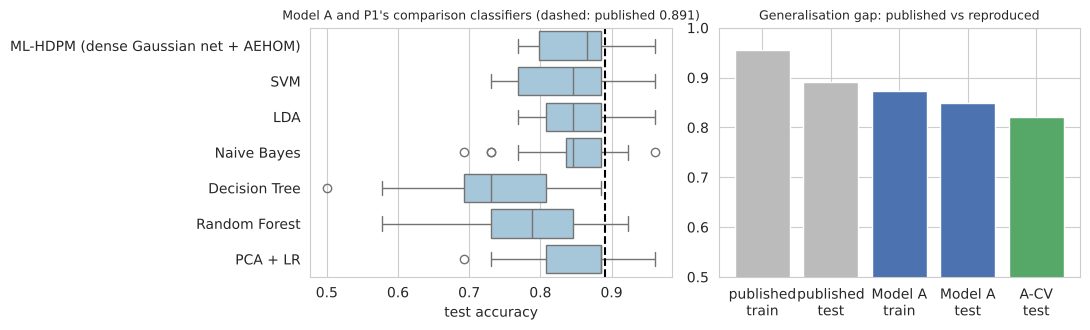

In [72]:
P1_REPORTED = {"train": {"accuracy": 0.955, "precision": 0.948, "recall": 0.962, "f1": 0.915, "specificity": 0.897, "fpr": 0.082},
               "test":  {"accuracy": 0.891, "precision": 0.883, "recall": 0.908, "f1": 0.896, "specificity": 0.842, "fpr": 0.147}}
for ph, r in P1_REPORTED.items():
    f_calc = 2 * r["precision"] * r["recall"] / (r["precision"] + r["recall"])
    print(f"P1 {ph:5s}: reported F {r['f1']:.3f} vs F from P and R {f_calc:.3f} | reported specificity {r['specificity']:.3f} vs 1 - FPR {1 - r['fpr']:.3f}")
print("=> training F-score and both specificity values cannot all be correct as printed; the test accuracy (0.891) is used as the headline.")

MLHDPM_A, MLHDPM_A_COMP, MLHDPM_A_CV = None, None, None
if clev14 is not None and HAVE_TF:
    # ---- overlap of Cleveland-303 with our sealed validation set (identity check on the 11 shared variables; no labels read) ----
    c11 = clev14.rename(columns={"cp": "chest pain type", "trestbps": "resting bp s", "chol": "cholesterol", "fbs": "fasting blood sugar",
                                 "restecg": "resting ecg", "thalach": "max heart rate", "exang": "exercise angina", "slope": "ST slope"})
    n_val_overlap = int(VAULT.contains(c11, FEATURES).sum())
    print(f"Cleveland-303 records that are also in our sealed validation set: {n_val_overlap} of 303 (disclosed; Section 28 is quarantined).")

    Xc_raw, yc = clev14[feats14], clev14["target"].to_numpy()
    def mlhdpm_network(seed, epochs=None):
        return KerasTabularClassifier("mldcnn_dense", hidden=(32, 16), optimizer="sgd", learning_rate=0.01, momentum=0.9, batch_size=32,
                                      epochs=epochs or CFG["nn_epochs"], aehom_full=True, aehom_iterations=10 if QUICK else 40, random_state=seed)
    # Step 1-2 (P1 order): preprocessing and GA + RFE on all 303 records  (LEAKAGE-PRONE, as in the paper's workflow)
    Z_all = np.asarray(prep14().fit_transform(Xc_raw), dtype=float)
    sel_hist = Pipeline([("ga", ga_selector()), ("rfe", rfecv_selector())]).fit(Z_all, yc)
    Zs = sel_hist.transform(Z_all)
    print(f"GA + RFE on all 303 records kept {Zs.shape[1]} of {Z_all.shape[1]} encoded features.")

    def ucom_split_811(Z, y, seed, majority_n=120):
        """P1 UCOM split: undersample the majority to `majority_n`, k-means the minority (SSE elbow), split every part 8:1:1."""
        rng = np.random.default_rng(seed)
        maj = int(np.argmax(np.bincount(y)))
        i_maj = rng.choice(np.flatnonzero(y == maj), majority_n, replace=False); i_min = np.flatnonzero(y != maj)
        ks = list(range(1, 7)); sse = [KMeans(k, n_init=10, random_state=seed).fit(Z[i_min]).inertia_ for k in ks]
        k = ks[int(np.argmax(np.diff(sse, 2))) + 1]
        lab = KMeans(k, n_init=10, random_state=seed).fit_predict(Z[i_min])
        tr, va, te = [], [], []
        for part in [i_maj] + [i_min[lab == c] for c in range(k)]:
            part = rng.permutation(part); n_te = int(round(0.1 * len(part))); n_va = int(round(0.1 * len(part)))
            te += list(part[:n_te]); va += list(part[n_te:n_te + n_va]); tr += list(part[n_te + n_va:])
        return np.array(tr), np.array(va), np.array(te), k

    A_SEEDS = list(range(3)) if QUICK else list(range(20))
    rows, comp_rows = [], []
    for s in tqdm(A_SEEDS, desc="Model A (P1 UCOM 8:1:1 protocol)"):
        tr, va, te, k = ucom_split_811(Zs, yc, SEED + s)
        Xtr_s, ytr_s = SMOTE(random_state=SEED + s).fit_resample(Zs[tr], yc[tr])            # SMOTE on the training part only
        net = mlhdpm_network(SEED + s).fit(Xtr_s, ytr_s, X_val=Zs[va], y_val=yc[va])         # early stopping on P1's validation part
        for name, mdl in [("ML-HDPM (dense Gaussian net + AEHOM)", net)] + \
                         [(n, clone(m).fit(Xtr_s, ytr_s)) for n, m in p1_models().items()]:
            mtr = compute_metrics(yc[tr], mdl.predict(Zs[tr]), scores_of(mdl, Zs[tr]))
            mte = compute_metrics(yc[te], mdl.predict(Zs[te]), scores_of(mdl, Zs[te]))
            (rows if name.startswith("ML-HDPM") else comp_rows).append(
                {"seed": s, "model": name, "k clusters": k, "n train (before SMOTE)": len(tr), "n validation": len(va), "n test": len(te),
                 **{f"train {m}": mtr[m] for m in ["accuracy", "precision", "recall", "f1", "specificity"]},
                 **{f"test {m}": mte[m] for m in ["accuracy", "precision", "recall", "f1", "specificity", "mcc", "roc_auc"]},
                 "AEHOM accepted": net.aehom_report_["accepted"] if name.startswith("ML-HDPM") else None})
    MLHDPM_A_RUNS = pd.DataFrame(rows); MLHDPM_A_COMP = pd.DataFrame(comp_rows)

    # Model A-CV: the same pipeline, but leakage-free: every step inside the training folds of stratified k-fold CV
    pipe_acv = make_pipe(mlhdpm_network(SEED), prep=prep14(), selectors=[ga_selector(), rfecv_selector()],
                         sampler=FunctionSampler(func=ucom_literal_resample, kw_args={"majority_keep": 120 / 164, "random_state": SEED}, validate=True))
    cv_a = StratifiedKFold(3 if QUICK else 10, shuffle=True, random_state=SEED)
    res_a = cross_validate(pipe_acv, Xc_raw, yc, cv=cv_a, scoring=SCORING, return_train_score=True, n_jobs=1)
    MLHDPM_A_CV = {m: (res_a[f"test_{m}"].mean(), res_a[f"test_{m}"].std(ddof=1)) for m in ["accuracy", "precision", "recall", "f1", "specificity", "mcc", "roc_auc"]}
    MLHDPM_A_CV["train accuracy"] = (res_a["train_accuracy"].mean(), res_a["train_accuracy"].std(ddof=1))

    def msd(series):
        return f"{series.mean():.3f} +/- {series.std(ddof=1):.3f}" if len(series) > 1 else f"{series.mean():.3f}"
    A = MLHDPM_A_RUNS
    MLHDPM_A = pd.DataFrame([
        {"version": "P1 published ML-HDPM (paper)", "protocol": "UCOM 8:1:1 / k-fold (paper)", "train accuracy": "0.955", "test accuracy": "0.891",
         "test precision": "0.883", "test recall": "0.908", "test F1": "0.896", "test specificity": "0.842", "test MCC": "not reported", "test n": "not stated (8:1:1 split, so about 10%)"},
        {"version": f"Model A: our ML-HDPM reproduction (mean +/- SD over {len(A_SEEDS)} seeds)", "protocol": "HISTORICAL P1 protocol: GA+RFE on all data, UCOM 8:1:1, SMOTE",
         "train accuracy": msd(A["train accuracy"]), "test accuracy": msd(A["test accuracy"]), "test precision": msd(A["test precision"]),
         "test recall": msd(A["test recall"]), "test F1": msd(A["test f1"]), "test specificity": msd(A["test specificity"]),
         "test MCC": msd(A["test mcc"]), "test n": str(int(A["n test"].iloc[0]))},
        {"version": "Model A-CV: same pipeline, leakage-free", "protocol": f"stratified {cv_a.get_n_splits()}-fold CV, every step inside training folds",
         "train accuracy": f"{MLHDPM_A_CV['train accuracy'][0]:.3f}", **{f"test {k_}": f"{MLHDPM_A_CV[m][0]:.3f} +/- {MLHDPM_A_CV[m][1]:.3f}"
         for k_, m in [("accuracy", "accuracy"), ("precision", "precision"), ("recall", "recall"), ("F1", "f1"), ("specificity", "specificity"), ("MCC", "mcc")]},
         "test n": f"about {303 // cv_a.get_n_splits()} per fold"}])
    display(MLHDPM_A)
    d_acc = A["test accuracy"].mean() - 0.891; d_cv = MLHDPM_A_CV["accuracy"][0] - 0.891
    print(f"Difference from the published 0.891 test accuracy: Model A {d_acc:+.3f} (historical protocol); Model A-CV {d_cv:+.3f} (leakage-free).")
    print(f"Model A test accuracy ranged from {A['test accuracy'].min():.3f} to {A['test accuracy'].max():.3f} across seeds "
          f"(test sets of {int(A['n test'].iloc[0])} patients, so one patient = {1 / A['n test'].iloc[0]:.1%}).")
    display(MLHDPM_A_COMP.groupby("model")[["train accuracy", "test accuracy", "test recall", "test specificity", "test f1"]].agg(["mean", "std"]).round(3))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    allA = pd.concat([MLHDPM_A_RUNS, MLHDPM_A_COMP])
    sns.boxplot(data=allA, y="model", x="test accuracy", ax=ax[0], color="#9ecae1"); ax[0].axvline(0.891, color="k", ls="--")
    ax[0].set_title("Model A and P1's comparison classifiers (dashed: published 0.891)", fontsize=9); ax[0].set_ylabel("")
    ax[1].bar(["published\ntrain", "published\ntest", "Model A\ntrain", "Model A\ntest", "A-CV\ntest"],
              [0.955, 0.891, A["train accuracy"].mean(), A["test accuracy"].mean(), MLHDPM_A_CV["accuracy"][0]], color=["#bbb", "#bbb", "#4C72B0", "#4C72B0", "#55A868"])
    ax[1].set_ylim(0.5, 1); ax[1].set_title("Generalisation gap: published vs reproduced", fontsize=9)
    savefig("mlhdpm_model_A_reproduction")
    MLHDPM_A.to_csv(os.path.join(OUT, "mlhdpm_model_A_reproduction.csv"), index=False)
    MLHDPM_A_RUNS.to_csv(os.path.join(OUT, "mlhdpm_model_A_runs.csv"), index=False)
    MLHDPM_A_COMP.to_csv(os.path.join(OUT, "mlhdpm_model_A_comparison_classifiers.csv"), index=False)
else:
    print("Cleveland-303 file or TensorFlow not available: Model A skipped.")

---
## 29. LSRO-ML-HDPM: Leakage-Safe, Sensitivity-Optimised ML-HDPM (Models B to F)
**Objective.** Reduce missed heart-disease cases (false negatives) while keeping false positives under control and keeping the predicted probabilities reliable. The base pipeline is always ML-HDPM itself; each model changes one identifiable part of it.

| Model | What changes relative to ML-HDPM | Learned from |
|---|---|---|
| **B** Leakage-safe ML-HDPM | ML-HDPM pipeline (KNN imputation, scaling, GA + RFE, literal UCOM, dense Gaussian network, SGD + momentum, AEHOM) fitted only on training data; threshold 0.5 | training data only |
| **C** + cost-sensitive learning | the network's loss becomes **class-weighted cross-entropy** (weight w on the disease class, also used in AEHOM's fitness and in early stopping); w chosen from a pre-declared grid by **highest out-of-fold F2** (ties: smaller w) | inner CV of the training data |
| **D** + threshold optimisation | decision threshold = **highest threshold whose out-of-fold recall is at least 0.90**, which maximises specificity under that constraint (pre-declared) | out-of-fold predictions of B |
| **E** + probability calibration | **Platt (sigmoid) scaling** fitted on out-of-fold scores; threshold 0.5 on the calibrated probability | out-of-fold predictions of B |
| **F** LSRO (combined) | C's cost-sensitive network, Platt-calibrated on C's out-of-fold scores, then the recall-constrained threshold chosen on those calibrated out-of-fold probabilities | inner CV of the training data |
| Benchmark | LightGBM, plain; and cost-sensitive LightGBM (scale_pos_weight from the same grid) + Platt + the same threshold rule | same rules |

**Nesting.** All of C, D, E and F are produced by one procedure, `lsro_train(X, y)`, which looks only at the data it is given:
1. Inner stratified k-fold CV produces out-of-fold (OOF) scores of the network for every class weight in the grid.
2. The class weight, the Platt calibrators and the thresholds are chosen from those OOF scores. OOF means the scores come from models that never trained on those patients.
3. The final networks are refitted on all of (X, y).

Platt scaling is monotone, so it does not change which patients a threshold selects. The threshold chosen on calibrated OOF probabilities is therefore equivalent to one chosen on the raw OOF scores. The recall constraint is checked and reported; if it cannot be met it is reported as infeasible, never relaxed.

**Evaluation (identical patients for every model).**
* **Training CV (primary development evidence).** `lsro_train` is run from scratch inside each outer fold of a stratified k-fold CV on the 642 training patients and scored on the held-out fold. All models see the same folds, so the comparisons are paired (corrected resampled t-test).
* **Test set (184).** `lsro_train` is run once on all 642 training patients, then every model is scored once on the test set (bootstrap CIs, McNemar tests). Nothing is tuned on the test set.
* **Validation set (92).** It stays sealed. All models of this section are frozen and pre-declared for the single authorised evaluation (Section 30).

**Pre-declared primary comparison: F2 of Model F vs Model B.** F2 weights recall twice as much as precision. Accuracy and specificity are always reported next to it, so that a recall gain cannot hide extra false positives.

**Already in this notebook, so not claimed as new here.** Threshold policies on training OOF predictions (Section 21.1), calibrated ensembles (Section 19), class weights for the classical models (Section 12) and the ML-HDPM components (Sections 15 and 16). What is new is applying cost-sensitive training, calibration and a recall-constrained threshold **to the ML-HDPM network itself**, nested in one leakage-safe procedure, and comparing each change separately.

In [73]:
from joblib import Parallel, delayed
from sklearn.metrics import fbeta_score
LSRO = dict(w_grid=[1.0, 2.0] if QUICK else [1.0, 1.5, 2.0, 3.0], inner_k=3 if QUICK else 5, outer_k=3 if QUICK else 5,
            recall_target=0.90, aehom_iterations=10 if QUICK else 40)
LSRO_NAMES = {"B": "B: Leakage-safe ML-HDPM", "C": "C: + cost-sensitive loss", "D": "D: + recall-constrained threshold",
              "E": "E: + Platt calibration", "F": "F: LSRO-ML-HDPM (C + E + D)",
              "LGBM-B": "Benchmark: LightGBM", "LGBM-F": "Benchmark: cost-sensitive LightGBM + Platt + threshold"}
print("LSRO settings (fixed before any result was seen):", LSRO)

def mlhdpm_pipe(pos_weight=1.0):
    net = KerasTabularClassifier("mldcnn_dense", hidden=(32, 16), optimizer="sgd", learning_rate=0.01, momentum=0.9, batch_size=32,
                                 epochs=CFG["nn_epochs"], aehom_full=True, aehom_iterations=LSRO["aehom_iterations"], pos_weight=pos_weight, random_state=SEED)
    return make_pipe(net, prep=prep_improved("knn"), selectors=[ga_selector(), rfecv_selector()],
                     sampler=make_samplers_extra()["UCOM literal (P1: keep 2/3 of majority)"])
def lgbm_pipe(pos_weight=1.0):
    return make_pipe(LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                    scale_pos_weight=pos_weight, verbose=-1, n_jobs=1, random_state=SEED))

def f2_score(y, pred):
    return fbeta_score(np.asarray(y).astype(int), np.asarray(pred).astype(int), beta=2, zero_division=0)
def ece_score(y, p, bins=10):
    """Expected calibration error, 10 equal-width bins."""
    y = np.asarray(y, float); p = np.asarray(p, float); idx = np.clip((p * bins).astype(int), 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any()))
def lsro_metrics(y, pred, p):
    m = compute_metrics(y, pred, p); m["f2"] = f2_score(y, pred); m["ece"] = ece_score(y, p); return m

def rows_fingerprint(X):
    return hashlib.md5("|".join(sorted(",".join(f"{v:.6g}" for v in r) for r in np.asarray(X[FEATURES], dtype=float))).encode()).hexdigest()

def lsro_train(X, y, factory, prefix=""):
    """The complete LSRO procedure on ONE training set. Every choice uses (X, y) only."""
    y = np.asarray(y).astype(int)
    cv = StratifiedKFold(LSRO["inner_k"], shuffle=True, random_state=SEED)
    oof = {w: np.zeros(len(y)) for w in LSRO["w_grid"]}
    for tr, va in cv.split(X, y):
        for w in LSRO["w_grid"]:
            oof[w][va] = factory(w).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])[:, 1]
    f2_oof = {w: f2_score(y, (oof[w] >= 0.5).astype(int)) for w in LSRO["w_grid"]}
    w_star = sorted(LSRO["w_grid"], key=lambda w: (-round(f2_oof[w], 6), w))[0]
    t_D, feas_D, rec_D, spec_D = recall_constrained_threshold(y, oof[1.0], LSRO["recall_target"])
    cal_E = PlattScaler().fit(oof[1.0], y)
    cal_F = PlattScaler().fit(oof[w_star], y)
    t_F, feas_F, rec_F, spec_F = recall_constrained_threshold(y, cal_F.transform(oof[w_star]), LSRO["recall_target"])
    base = factory(1.0).fit(X, y)
    base_w = base if w_star == 1.0 else factory(w_star).fit(X, y)
    models = {f"{prefix}B": LSROVariant(base, None, 0.5, "B"), f"{prefix}C": LSROVariant(base_w, None, 0.5, "C"),
              f"{prefix}D": LSROVariant(base, None, t_D, "D"), f"{prefix}E": LSROVariant(base, cal_E, 0.5, "E"),
              f"{prefix}F": LSROVariant(base_w, cal_F, t_F, "F")}
    report = {"n training rows": len(y), "training fingerprint": rows_fingerprint(X), "w_star": w_star, **{f"OOF F2 at w={w}": v for w, v in f2_oof.items()},
              "threshold D": t_D, "D feasible": feas_D, "D OOF recall": rec_D, "D OOF specificity": spec_D,
              "threshold F (calibrated)": t_F, "F feasible": feas_F, "F OOF recall": rec_F, "F OOF specificity": spec_F,
              "Platt E (a, b)": (round(cal_E.a_, 3), round(cal_E.b_, 3)), "Platt F (a, b)": (round(cal_F.a_, 3), round(cal_F.b_, 3))}
    return models, report

def lsro_outer_job(k, tr, va):
    Xtr, ytr, Xva = X_train.iloc[tr], y_train[tr], X_train.iloc[va]
    out, reps = {}, {}
    for factory, prefix in [(mlhdpm_pipe, ""), (lgbm_pipe, "LGBM-")]:
        models, rep = lsro_train(Xtr, ytr, factory, prefix)
        reps["LightGBM" if prefix else "ML-HDPM"] = rep
        for name, mdl in models.items():
            if prefix and name not in ("LGBM-B", "LGBM-F"):
                continue
            out[name] = (mdl.predict(Xva), mdl.predict_proba(Xva)[:, 1])
    return k, va, out, reps

t_lsro = time.time()
outer = StratifiedKFold(LSRO["outer_k"], shuffle=True, random_state=SEED + 700)
jobs = Parallel(n_jobs=N_JOBS)(delayed(lsro_outer_job)(k, tr, va) for k, (tr, va) in enumerate(outer.split(X_train, y_train)))
fold_rows, rep_rows, OOF_LSRO = [], [], {n: (np.zeros(len(y_train), int), np.zeros(len(y_train))) for n in LSRO_NAMES}
for k, va, out, reps in sorted(jobs, key=lambda j: j[0]):
    for name, (pred, p) in out.items():
        fold_rows.append({"fold": k, "model": name, **lsro_metrics(y_train[va], pred, p)})
        OOF_LSRO[name][0][va] = pred; OOF_LSRO[name][1][va] = p
    for fam, rep in reps.items():
        rep_rows.append({"outer fold": k, "family": fam, **rep})
LSRO_FOLDS = pd.DataFrame(fold_rows); LSRO_CHOICES = pd.DataFrame(rep_rows)
print(f"Outer CV of the whole LSRO procedure ({LSRO['outer_k']} folds, inner {LSRO['inner_k']}-fold): {(time.time() - t_lsro) / 60:.1f} min")
print("Choices made inside each outer training fold (class weight, thresholds, feasibility of recall >= 0.90):")
display(LSRO_CHOICES.round(3))

LSRO settings (fixed before any result was seen): {'w_grid': [1.0, 1.5, 2.0, 3.0], 'inner_k': 5, 'outer_k': 5, 'recall_target': 0.9, 'aehom_iterations': 40}


Outer CV of the whole LSRO procedure (5 folds, inner 5-fold): 8.7 min
Choices made inside each outer training fold (class weight, thresholds, feasibility of recall >= 0.90):


,outer fold,family,n training rows,training fingerprint,w_star,OOF F2 at w=1.0,OOF F2 at w=1.5,OOF F2 at w=2.0,OOF F2 at w=3.0,threshold D,D feasible,D OOF recall,D OOF specificity,threshold F (calibrated),F feasible,F OOF recall,F OOF specificity,"Platt E (a, b)","Platt F (a, b)"
0,0,ML-HDPM,513,cb9dfa75bd79e0777bd7ebf1262f47d2,3.0,0.860,0.875,0.888,0.898,0.341,True,0.901,0.764,0.430,True,0.901,0.786,"(0.92, 0.237)","(0.853, -0.547)"
1,0,LightGBM,513,cb9dfa75bd79e0777bd7ebf1262f47d2,3.0,0.890,0.895,0.905,0.916,0.492,True,0.901,0.821,0.488,True,0.901,0.795,"(0.72, 0.026)","(0.706, -0.399)"
2,1,ML-HDPM,513,a1d305a8063c4c98a13fd34a21ba0e03,3.0,0.832,0.871,0.898,0.914,0.365,True,0.901,0.799,0.453,True,0.901,0.790,"(0.994, 0.343)","(1.015, -0.72)"
3,1,LightGBM,513,a1d305a8063c4c98a13fd34a21ba0e03,3.0,0.874,0.875,0.880,0.902,0.388,True,0.901,0.773,0.443,True,0.901,0.773,"(0.664, 0.046)","(0.648, -0.32)"
4,2,ML-HDPM,514,f01b90fcfe82b1d77fc7895db98ccf50,3.0,0.840,0.878,0.889,0.900,0.314,True,0.901,0.796,0.411,True,0.905,0.774,"(0.855, 0.259)","(0.934, -0.723)"
5,2,LightGBM,514,f01b90fcfe82b1d77fc7895db98ccf50,3.0,0.883,0.895,0.896,0.904,0.461,True,0.901,0.787,0.513,True,0.901,0.809,"(0.681, 0.02)","(0.681, -0.373)"
6,3,ML-HDPM,514,4447e6917d743d4522a3f18e46fe8c82,3.0,0.864,0.890,0.901,0.910,0.404,True,0.901,0.804,0.498,True,0.905,0.804,"(0.999, 0.212)","(0.934, -0.722)"
7,3,LightGBM,514,4447e6917d743d4522a3f18e46fe8c82,3.0,0.879,0.897,0.900,0.914,0.445,True,0.901,0.800,0.497,True,0.901,0.822,"(0.673, 0.041)","(0.679, -0.36)"
8,4,ML-HDPM,514,21490dcd7784ae10ebfe6f7eb7921279,3.0,0.842,0.879,0.884,0.906,0.301,True,0.901,0.791,0.437,True,0.901,0.796,"(0.866, 0.337)","(0.842, -0.535)"
9,4,LightGBM,514,21490dcd7784ae10ebfe6f7eb7921279,3.0,0.877,0.891,0.892,0.909,0.459,True,0.901,0.787,0.482,True,0.901,0.796,"(0.702, 0.044)","(0.681, -0.36)"


In [74]:
KEYM = ["f2", "recall", "specificity", "accuracy", "precision", "f1", "mcc", "roc_auc", "pr_auc", "brier", "ece", "fn", "fp"]
cv_sum = LSRO_FOLDS.groupby("model")[KEYM].agg(["mean", "std"])
LSRO_CV = pd.DataFrame({f"CV {m}": cv_sum[(m, "mean")] for m in KEYM})
LSRO_CV["CV f2 sd"] = cv_sum[("f2", "std")]
LSRO_CV = LSRO_CV.loc[list(LSRO_NAMES)].rename(index=LSRO_NAMES)
display(LSRO_CV.round(3))
n_in = len(y_train) * (LSRO["outer_k"] - 1) / LSRO["outer_k"]; n_out = len(y_train) / LSRO["outer_k"]
def fold_vec(name, m):
    return LSRO_FOLDS[LSRO_FOLDS.model == name].sort_values("fold")[m].to_numpy()
CV_TESTS = []
for name in ["C", "D", "E", "F", "LGBM-B", "LGBM-F"]:
    for m in ["f2", "recall", "specificity", "accuracy", "mcc", "brier", "ece"]:
        d, lo, hi, p = corrected_ttest(fold_vec(name, m), fold_vec("B", m), n_in, n_out)
        CV_TESTS.append({"model": LSRO_NAMES[name], "metric": m, "difference vs B": d, "95% CI low": lo, "95% CI high": hi, "p (corrected t-test)": p})
CV_TESTS = pd.DataFrame(CV_TESTS)
display(CV_TESTS[CV_TESTS.metric.isin(["f2", "recall", "specificity", "accuracy"])].pivot(index="model", columns="metric", values="difference vs B").round(3)
        .join(CV_TESTS[CV_TESTS.metric == "f2"].set_index("model")[["95% CI low", "95% CI high", "p (corrected t-test)"]].add_prefix("F2 ").round(3)))

,CV f2,CV recall,CV specificity,CV accuracy,CV precision,CV f1,CV mcc,CV roc_auc,CV pr_auc,CV brier,CV ece,CV fn,CV fp,CV f2 sd
model,,,,,,,,,,,,,,
B: Leakage-safe ML-HDPM,0.860,0.859,0.833,0.847,0.865,0.861,0.693,0.912,0.911,0.112,0.077,10.0,9.6,0.033
C: + cost-sensitive loss,0.912,0.935,0.763,0.858,0.832,0.880,0.717,0.912,0.908,0.117,0.094,4.6,13.6,0.017
D: + recall-constrained threshold,0.899,0.913,0.801,0.863,0.851,0.880,0.724,0.912,0.911,0.112,0.077,6.2,11.4,0.033
E: + Platt calibration,0.879,0.885,0.819,0.855,0.859,0.871,0.708,0.912,0.911,0.110,0.073,8.2,10.4,0.033
F: LSRO-ML-HDPM (C + E + D),0.904,0.918,0.801,0.866,0.852,0.883,0.731,0.912,0.908,0.110,0.071,5.8,11.4,0.034
Benchmark: LightGBM,0.880,0.887,0.812,0.854,0.855,0.870,0.705,0.916,0.913,0.110,0.073,8.0,10.8,0.036
Benchmark: cost-sensitive LightGBM + Platt + threshold,0.883,0.893,0.805,0.854,0.853,0.870,0.707,0.919,0.916,0.108,0.061,7.6,11.2,0.044


,accuracy,f2,recall,specificity,F2 95% CI low,F2 95% CI high,F2 p (corrected t-test)
model,,,,,,,
Benchmark: LightGBM,0.006,0.020,0.028,-0.021,-0.043,0.084,0.428
Benchmark: cost-sensitive LightGBM + Platt + threshold,0.006,0.024,0.034,-0.028,-0.061,0.108,0.482
C: + cost-sensitive loss,0.011,0.052,0.076,-0.070,-0.014,0.119,0.093
D: + recall-constrained threshold,0.016,0.039,0.054,-0.032,-0.015,0.094,0.113
E: + Platt calibration,0.008,0.019,0.025,-0.014,-0.013,0.051,0.177
F: LSRO-ML-HDPM (C + E + D),0.019,0.044,0.059,-0.031,-0.027,0.115,0.158


### 29.1 One evaluation of every model on the 20% test set
`lsro_train` is now run once on all 642 training patients. The resulting models are scored once on the test set. Confidence intervals come from a stratified bootstrap. Each model is compared with Model B on the same patients by:
* an exact McNemar test overall;
* McNemar tests restricted to diseased patients (a recall difference) and to healthy patients (a specificity difference);
* a paired bootstrap of the F2 difference.

In [75]:
t0 = time.time()
LSRO_MODELS, LSRO_REPORT = lsro_train(X_train, y_train, mlhdpm_pipe, "")
LGBM_MODELS, LGBM_REPORT = lsro_train(X_train, y_train, lgbm_pipe, "LGBM-")
LSRO_FINAL = {**LSRO_MODELS, "LGBM-B": LGBM_MODELS["LGBM-B"], "LGBM-F": LGBM_MODELS["LGBM-F"]}
print(f"LSRO procedure on the full training set: {time.time() - t0:.0f}s")
print("ML-HDPM choices:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in LSRO_REPORT.items()})
print("LightGBM choices:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in LGBM_REPORT.items()})
for fam, rep in [("ML-HDPM (D)", ("D feasible", "D OOF recall")), ("ML-HDPM (F)", ("F feasible", "F OOF recall"))]:
    if not LSRO_REPORT[rep[0]]:
        print(f"WARNING: the recall >= {LSRO['recall_target']} constraint was NOT feasible for {fam}; reported as infeasible, not relaxed.")
LSRO_TEST = {}
for name, mdl in LSRO_FINAL.items():
    m, pred, p = TEST.evaluate(mdl, LSRO_NAMES[name], "LSRO-ML-HDPM", purpose="development comparison: LSRO models (pre-declared)")
    m["f2"] = f2_score(TEST.y, pred); m["ece"] = ece_score(TEST.y, p)
    LSRO_TEST[name] = (m, pred, p)
yt_ = TEST.y
def boot_f2_ci(pred, p, ref=None, n=CFG["n_boot"]):
    rng = np.random.default_rng(SEED); i0, i1 = np.flatnonzero(yt_ == 0), np.flatnonzero(yt_ == 1); vals, dif = [], []
    for _ in range(n):
        idx = np.concatenate([rng.choice(i0, len(i0)), rng.choice(i1, len(i1))])
        f = f2_score(yt_[idx], pred[idx]); vals.append(f)
        if ref is not None:
            dif.append(f - f2_score(yt_[idx], ref[idx]))
    return np.percentile(vals, [2.5, 97.5]), (np.percentile(dif, [2.5, 97.5]) if ref is not None else None)
def mcnemar_p(a, b, mask=None):
    mask = np.ones(len(yt_), bool) if mask is None else mask
    b01 = int(((a == yt_) & (b != yt_) & mask).sum()); b10 = int(((a != yt_) & (b == yt_) & mask).sum())
    return (mcnemar([[0, b01], [b10, 0]], exact=True).pvalue if b01 + b10 else 1.0), b01, b10
_, predB, pB = LSRO_TEST["B"]
rows = []
for name, (m, pred, p) in LSRO_TEST.items():
    ci_f2, ci_d = boot_f2_ci(pred, p, None if name == "B" else predB)
    lo, hi = wilson(m["tp"] + m["tn"], m["n"])
    p_all, b01, b10 = mcnemar_p(pred, predB); p_pos, _, _ = mcnemar_p(pred, predB, yt_ == 1); p_neg, _, _ = mcnemar_p(pred, predB, yt_ == 0)
    rows.append({"model": LSRO_NAMES[name], "threshold": LSRO_FINAL[name].threshold, "F2": m["f2"], "F2 95% CI": f"[{ci_f2[0]:.3f}, {ci_f2[1]:.3f}]",
                 "accuracy": m["accuracy"], "accuracy 95% CI": f"[{lo:.3f}, {hi:.3f}]", "precision": m["precision"], "recall": m["recall"],
                 "specificity": m["specificity"], "F1": m["f1"], "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"], "MCC": m["mcc"],
                 "Brier": m["brier"], "ECE": m["ece"], "FN": m["fn"], "FP": m["fp"], "TP": m["tp"], "TN": m["tn"],
                 "delta F2 vs B": m["f2"] - LSRO_TEST["B"][0]["f2"], "delta F2 95% CI (paired bootstrap)": "" if ci_d is None else f"[{ci_d[0]:+.3f}, {ci_d[1]:+.3f}]",
                 "McNemar p vs B (all)": np.nan if name == "B" else p_all, "McNemar p vs B (diseased only: recall)": np.nan if name == "B" else p_pos,
                 "McNemar p vs B (healthy only: specificity)": np.nan if name == "B" else p_neg})
LSRO_TEST_TABLE = pd.DataFrame(rows)
display(LSRO_TEST_TABLE.round(3))

LSRO procedure on the full training set: 122s
ML-HDPM choices: {'n training rows': 642, 'training fingerprint': '6615327c1c24753e28cad7c64e0be798', 'w_star': 3.0, 'OOF F2 at w=1.0': 0.863, 'OOF F2 at w=1.5': 0.874, 'OOF F2 at w=2.0': 0.883, 'OOF F2 at w=3.0': 0.89, 'threshold D': 0.31, 'D feasible': True, 'D OOF recall': 0.901, 'D OOF specificity': 0.791, 'threshold F (calibrated)': 0.412, 'F feasible': True, 'F OOF recall': 0.901, 'F OOF specificity': 0.787, 'Platt E (a, b)': (0.831, 0.307), 'Platt F (a, b)': (0.796, -0.474)}
LightGBM choices: {'n training rows': 642, 'training fingerprint': '6615327c1c24753e28cad7c64e0be798', 'w_star': 3.0, 'OOF F2 at w=1.0': 0.883, 'OOF F2 at w=1.5': 0.887, 'OOF F2 at w=2.0': 0.894, 'OOF F2 at w=3.0': 0.898, 'threshold D': 0.434, 'D feasible': True, 'D OOF recall': 0.901, 'D OOF specificity': 0.787, 'threshold F (calibrated)': 0.481, 'F feasible': True, 'F OOF recall': 0.901, 'F OOF specificity': 0.798, 'Platt E (a, b)': (0.665, 0.01), 'Platt F (a, 

,model,threshold,F2,F2 95% CI,accuracy,accuracy 95% CI,precision,recall,specificity,F1,...,ECE,FN,FP,TP,TN,delta F2 vs B,delta F2 95% CI (paired bootstrap),McNemar p vs B (all),McNemar p vs B (diseased only: recall),McNemar p vs B (healthy only: specificity)
0,B: Leakage-safe ML-HDPM,0.500,0.865,"[0.803, 0.922]",0.875,"[0.819, 0.915]",0.916,0.853,0.902,0.883,...,0.074,15,8,87,74,0.000,,NaN,NaN,NaN
1,C: + cost-sensitive loss,0.500,0.924,"[0.881, 0.962]",0.902,"[0.851, 0.937]",0.896,0.931,0.866,0.913,...,0.052,7,11,95,71,0.059,"[+0.019, +0.104]",0.227,0.008,0.250
2,D: + recall-constrained threshold,0.310,0.888,"[0.833, 0.938]",0.886,"[0.832, 0.924]",0.909,0.882,0.890,0.896,...,0.074,12,9,90,73,0.023,"[-0.002, +0.054]",0.625,0.250,1.000
3,E: + Platt calibration,0.500,0.879,"[0.823, 0.930]",0.880,"[0.826, 0.920]",0.908,0.873,0.890,0.890,...,0.047,13,9,89,73,0.015,"[-0.003, +0.041]",1.000,0.500,1.000
4,F: LSRO-ML-HDPM (C + E + D),0.412,0.908,"[0.858, 0.951]",0.891,"[0.838, 0.929]",0.894,0.912,0.866,0.903,...,0.044,9,11,93,71,0.043,"[+0.007, +0.082]",0.508,0.031,0.250
5,Benchmark: LightGBM,0.500,0.871,"[0.815, 0.925]",0.875,"[0.819, 0.915]",0.907,0.863,0.890,0.884,...,0.058,14,9,88,73,0.006,"[-0.035, +0.051]",1.000,1.000,1.000
6,Benchmark: cost-sensitive LightGBM + Platt + t...,0.481,0.900,"[0.848, 0.944]",0.886,"[0.832, 0.924]",0.893,0.902,0.866,0.898,...,0.074,10,11,92,71,0.035,"[-0.005, +0.079]",0.791,0.125,0.453


### 29.2 Main comparison table and ablation table
**Main comparison (`mlhdpm_comparison.csv`).** Model A rows come from Section 28: Cleveland-303 under P1's own protocol, which is not comparable with the rows below. Models B to F and the benchmarks are all evaluated on the same patients:
* training CV: mean of the outer folds;
* test set: one evaluation.

The validation columns stay "sealed" until the authorised evaluation.

**Ablation (`mlhdpm_ablation.csv`).** Each modification is compared with Model B on the identical outer folds (corrected t-test) and on the identical test patients (paired bootstrap, McNemar).

In [76]:
comp = []
if MLHDPM_A is not None:
    for _, r_ in MLHDPM_A.iterrows():
        comp.append({"model": r_["version"], "data / protocol": r_["protocol"], "comparable with B-F?": "no (different data and protocol)",
                     "test accuracy": r_["test accuracy"], "test recall": r_["test recall"], "test specificity": r_["test specificity"], "test F1": r_["test F1"]})
def r3(v):
    return round(float(v), 3) if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) else v
for name in LSRO_NAMES:
    cvr = LSRO_CV.loc[LSRO_NAMES[name]].map(r3); t_ = LSRO_TEST_TABLE.set_index("model").loc[LSRO_NAMES[name]].map(r3)
    comp.append({"model": LSRO_NAMES[name], "data / protocol": "918 unique patients: 642 train (outer CV) / 184 test; 92 validation sealed",
                 "comparable with B-F?": "yes", "CV F2 (mean)": cvr["CV f2"], "CV F2 SD": cvr["CV f2 sd"], "CV recall": cvr["CV recall"],
                 "CV specificity": cvr["CV specificity"], "CV accuracy": cvr["CV accuracy"], "CV MCC": cvr["CV mcc"], "CV Brier": cvr["CV brier"], "CV ECE": cvr["CV ece"],
                 "test F2": t_["F2"], "test F2 95% CI": t_["F2 95% CI"], "test accuracy": t_["accuracy"], "test accuracy 95% CI": t_["accuracy 95% CI"],
                 "test precision": t_["precision"], "test recall": t_["recall"], "test specificity": t_["specificity"], "test F1": t_["F1"],
                 "test ROC-AUC": t_["ROC-AUC"], "test PR-AUC": t_["PR-AUC"], "test MCC": t_["MCC"], "test Brier": t_["Brier"], "test ECE": t_["ECE"],
                 "test FN": t_["FN"], "test FP": t_["FP"], "validation (92)": "sealed (not evaluated)"})
MLHDPM_COMPARISON = pd.DataFrame(comp)
display(MLHDPM_COMPARISON.round(3))

MODS = {"C": "cost-sensitive loss (class-weighted cross-entropy)", "D": "recall-constrained threshold (recall >= 0.90 on OOF)",
        "E": "Platt calibration (OOF)", "F": "all three combined (LSRO)", "LGBM-B": "replace ML-HDPM by LightGBM (benchmark)",
        "LGBM-F": "cost-sensitive LightGBM + Platt + threshold (benchmark)"}
abl = []
tt = LSRO_TEST_TABLE.set_index("model")
for name, desc in MODS.items():
    r_ = {"model": LSRO_NAMES[name], "modification vs B": desc}
    for m in ["f2", "recall", "specificity", "accuracy", "mcc", "brier", "ece"]:
        c_ = CV_TESTS[(CV_TESTS.model == LSRO_NAMES[name]) & (CV_TESTS.metric == m)].iloc[0]
        r_[f"CV delta {m}"] = c_["difference vs B"]
        if m in ("f2", "recall", "specificity"):
            r_[f"CV delta {m} p"] = c_["p (corrected t-test)"]
    tb, tB = tt.loc[LSRO_NAMES[name]], tt.loc[LSRO_NAMES["B"]]
    r_.update({"test delta F2": tb["F2"] - tB["F2"], "test delta F2 95% CI": tb["delta F2 95% CI (paired bootstrap)"],
               "test delta recall": tb["recall"] - tB["recall"], "test delta specificity": tb["specificity"] - tB["specificity"],
               "test delta accuracy": tb["accuracy"] - tB["accuracy"], "test delta FN": tb["FN"] - tB["FN"], "test delta FP": tb["FP"] - tB["FP"],
               "test delta Brier": tb["Brier"] - tB["Brier"], "test delta ECE": tb["ECE"] - tB["ECE"],
               "test McNemar p (all)": tb["McNemar p vs B (all)"], "test McNemar p (diseased)": tb["McNemar p vs B (diseased only: recall)"]})
    abl.append(r_)
MLHDPM_ABLATION = pd.DataFrame(abl)
display(MLHDPM_ABLATION.round(3))
MLHDPM_COMPARISON.to_csv(os.path.join(OUT, "mlhdpm_comparison.csv"), index=False)
MLHDPM_ABLATION.to_csv(os.path.join(OUT, "mlhdpm_ablation.csv"), index=False)
LSRO_FOLDS.to_csv(os.path.join(OUT, "mlhdpm_lsro_cv_folds.csv"), index=False); LSRO_CHOICES.to_csv(os.path.join(OUT, "mlhdpm_lsro_inner_choices.csv"), index=False)
LSRO_TEST_TABLE.to_csv(os.path.join(OUT, "mlhdpm_lsro_test.csv"), index=False); CV_TESTS.to_csv(os.path.join(OUT, "mlhdpm_lsro_cv_paired_tests.csv"), index=False)

# which model is best by the pre-declared primary metric? (training-CV F2; the test set is a secondary check)
best_cv = LSRO_CV["CV f2"].idxmax()
f_t = CV_TESTS[(CV_TESTS.model == LSRO_NAMES["F"]) & (CV_TESTS.metric == "f2")].iloc[0]
print(f"Highest training-CV F2: {best_cv} ({LSRO_CV.loc[best_cv, 'CV f2']:.3f}). "
      f"Primary comparison F vs B: CV delta F2 {f_t['difference vs B']:+.3f} [{f_t['95% CI low']:+.3f}, {f_t['95% CI high']:+.3f}], p = {f_t['p (corrected t-test)']:.3f}; "
      f"test delta F2 {tt.loc[LSRO_NAMES['F'], 'F2'] - tt.loc[LSRO_NAMES['B'], 'F2']:+.3f} {tt.loc[LSRO_NAMES['F'], 'delta F2 95% CI (paired bootstrap)']}.")

,model,data / protocol,comparable with B-F?,test accuracy,test recall,test specificity,test F1,CV F2 (mean),CV F2 SD,CV recall,...,test accuracy 95% CI,test precision,test ROC-AUC,test PR-AUC,test MCC,test Brier,test ECE,test FN,test FP,validation (92)
0,P1 published ML-HDPM (paper),UCOM 8:1:1 / k-fold (paper),no (different data and protocol),0.891,0.908,0.842,0.896,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Model A: our ML-HDPM reproduction (mean +/- SD...,"HISTORICAL P1 protocol: GA+RFE on all data, UC...",no (different data and protocol),0.850 +/- 0.066,0.818 +/- 0.082,0.887 +/- 0.091,0.854 +/- 0.066,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Model A-CV: same pipeline, leakage-free","stratified 10-fold CV, every step inside train...",no (different data and protocol),0.822 +/- 0.065,0.827 +/- 0.076,0.817 +/- 0.100,0.811 +/- 0.065,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,B: Leakage-safe ML-HDPM,918 unique patients: 642 train (outer CV) / 18...,yes,0.875,0.853,0.902,0.883,0.860,0.033,0.859,...,"[0.819, 0.915]",0.916,0.939,0.939,0.751,0.099,0.074,15.0,8.0,sealed (not evaluated)
4,C: + cost-sensitive loss,918 unique patients: 642 train (outer CV) / 18...,yes,0.902,0.931,0.866,0.913,0.912,0.017,0.935,...,"[0.851, 0.937]",0.896,0.938,0.944,0.802,0.088,0.052,7.0,11.0,sealed (not evaluated)
5,D: + recall-constrained threshold,918 unique patients: 642 train (outer CV) / 18...,yes,0.886,0.882,0.89,0.896,0.899,0.033,0.913,...,"[0.832, 0.924]",0.909,0.939,0.939,0.770,0.099,0.074,12.0,9.0,sealed (not evaluated)
6,E: + Platt calibration,918 unique patients: 642 train (outer CV) / 18...,yes,0.88,0.873,0.89,0.89,0.879,0.033,0.885,...,"[0.826, 0.920]",0.908,0.939,0.939,0.760,0.093,0.047,13.0,9.0,sealed (not evaluated)
7,F: LSRO-ML-HDPM (C + E + D),918 unique patients: 642 train (outer CV) / 18...,yes,0.891,0.912,0.866,0.903,0.904,0.034,0.918,...,"[0.838, 0.929]",0.894,0.938,0.944,0.780,0.087,0.044,9.0,11.0,sealed (not evaluated)
8,Benchmark: LightGBM,918 unique patients: 642 train (outer CV) / 18...,yes,0.875,0.863,0.89,0.884,0.880,0.036,0.887,...,"[0.819, 0.915]",0.907,0.941,0.940,0.750,0.092,0.058,14.0,9.0,sealed (not evaluated)
9,Benchmark: cost-sensitive LightGBM + Platt + t...,918 unique patients: 642 train (outer CV) / 18...,yes,0.886,0.902,0.866,0.898,0.883,0.044,0.893,...,"[0.832, 0.924]",0.893,0.945,0.946,0.769,0.091,0.074,10.0,11.0,sealed (not evaluated)


,model,modification vs B,CV delta f2,CV delta f2 p,CV delta recall,CV delta recall p,CV delta specificity,CV delta specificity p,CV delta accuracy,CV delta mcc,...,test delta F2 95% CI,test delta recall,test delta specificity,test delta accuracy,test delta FN,test delta FP,test delta Brier,test delta ECE,test McNemar p (all),test McNemar p (diseased)
0,C: + cost-sensitive loss,cost-sensitive loss (class-weighted cross-entr...,0.052,0.093,0.076,0.037,-0.070,0.095,0.011,0.024,...,"[+0.019, +0.104]",0.078,-0.037,0.027,-8,3,-0.012,-0.022,0.227,0.008
1,D: + recall-constrained threshold,recall-constrained threshold (recall >= 0.90 o...,0.039,0.113,0.054,0.077,-0.032,0.110,0.016,0.032,...,"[-0.002, +0.054]",0.029,-0.012,0.011,-3,1,0.000,0.000,0.625,0.250
2,E: + Platt calibration,Platt calibration (OOF),0.019,0.177,0.025,0.145,-0.014,0.056,0.008,0.015,...,"[-0.003, +0.041]",0.020,-0.012,0.005,-2,1,-0.007,-0.027,1.000,0.500
3,F: LSRO-ML-HDPM (C + E + D),all three combined (LSRO),0.044,0.158,0.059,0.115,-0.031,0.109,0.019,0.038,...,"[+0.007, +0.082]",0.059,-0.037,0.016,-6,3,-0.012,-0.030,0.508,0.031
4,Benchmark: LightGBM,replace ML-HDPM by LightGBM (benchmark),0.020,0.428,0.028,0.377,-0.021,0.098,0.006,0.012,...,"[-0.035, +0.051]",0.010,-0.012,0.000,-1,1,-0.008,-0.016,1.000,1.000
5,Benchmark: cost-sensitive LightGBM + Platt + t...,cost-sensitive LightGBM + Platt + threshold (b...,0.024,0.482,0.034,0.426,-0.028,0.451,0.006,0.015,...,"[-0.005, +0.079]",0.049,-0.037,0.011,-5,3,-0.008,-0.000,0.791,0.125


Highest training-CV F2: C: + cost-sensitive loss (0.912). Primary comparison F vs B: CV delta F2 +0.044 [-0.027, +0.115], p = 0.158; test delta F2 +0.043 [+0.007, +0.082].


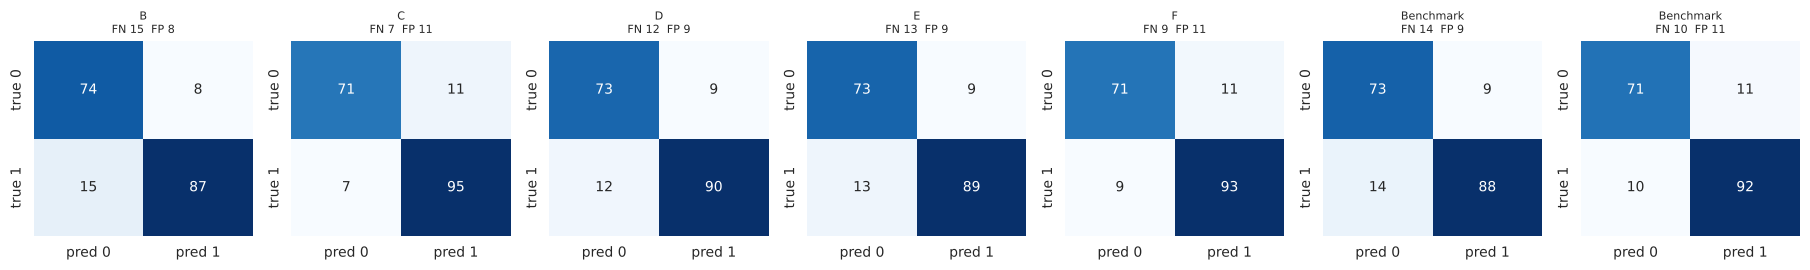

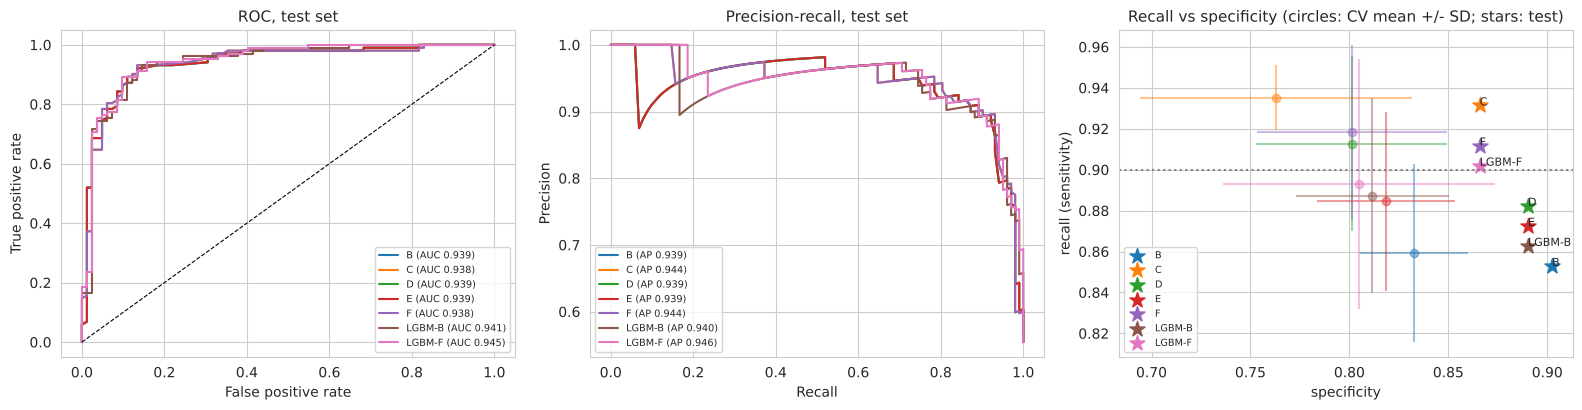

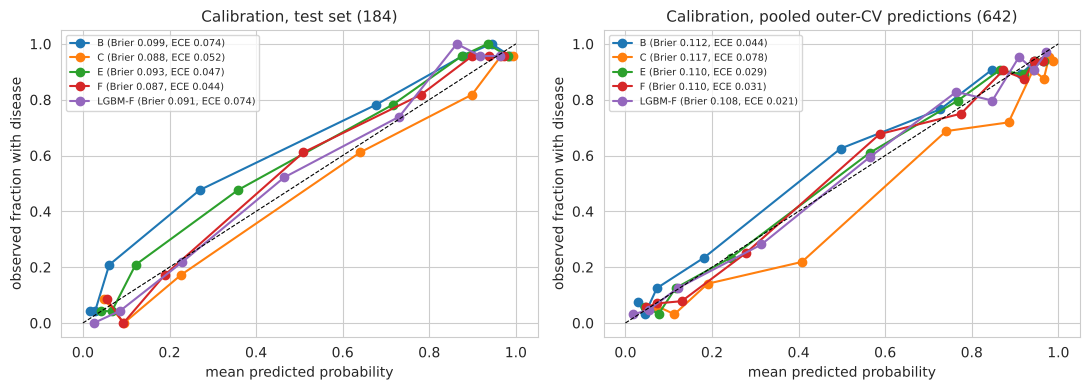

In [77]:
names_plot = list(LSRO_NAMES)
fig, axes = plt.subplots(1, len(names_plot), figsize=(2.6 * len(names_plot), 2.8))
for a, name in zip(axes, names_plot):
    m, pred, _ = LSRO_TEST[name]
    sns.heatmap(confusion_matrix(yt_, pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"]); a.set_title(LSRO_NAMES[name].split(":")[0] + f"\nFN {m['fn']}  FP {m['fp']}", fontsize=8)
savefig("mlhdpm_lsro_confusion_matrices")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name in names_plot:
    _, pred, p = LSRO_TEST[name]
    fpr, tpr, _ = roc_curve(yt_, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yt_, p):.3f})")
    pr_, rc_, _ = precision_recall_curve(yt_, p); ax[1].plot(rc_, pr_, label=f"{name} (AP {average_precision_score(yt_, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC, test set")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall, test set")
for a in ax[:2]:
    a.legend(fontsize=7)
for ci_, name in enumerate(names_plot):
    col = f"C{ci_}"; cv_r = LSRO_FOLDS[LSRO_FOLDS.model == name]; m, _, _ = LSRO_TEST[name]
    ax[2].errorbar(cv_r.specificity.mean(), cv_r.recall.mean(), xerr=cv_r.specificity.std(ddof=1), yerr=cv_r.recall.std(ddof=1), fmt="o", color=col, alpha=0.45)
    ax[2].scatter(m["specificity"], m["recall"], marker="*", s=130, color=col, label=name); ax[2].annotate(name, (m["specificity"], m["recall"]), fontsize=8)
ax[2].legend(fontsize=7, loc="lower left")
ax[2].axhline(LSRO["recall_target"], color="grey", ls=":"); ax[2].set(xlabel="specificity", ylabel="recall (sensitivity)",
                                                                       title="Recall vs specificity (circles: CV mean +/- SD; stars: test)")
savefig("mlhdpm_lsro_roc_pr_recall_specificity")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in ["B", "C", "E", "F", "LGBM-F"]:
    _, _, p = LSRO_TEST[name]; fp_, mp_ = calibration_curve(yt_, p, n_bins=8, strategy="quantile")
    ax[0].plot(mp_, fp_, marker="o", label=f"{name} (Brier {brier_score_loss(yt_, p):.3f}, ECE {ece_score(yt_, p):.3f})")
    po = OOF_LSRO[name][1]; fp_, mp_ = calibration_curve(y_train, po, n_bins=10, strategy="quantile")
    ax[1].plot(mp_, fp_, marker="o", label=f"{name} (Brier {brier_score_loss(y_train, po):.3f}, ECE {ece_score(y_train, po):.3f})")
for a, t in zip(ax, ["Calibration, test set (184)", "Calibration, pooled outer-CV predictions (642)"]):
    a.plot([0, 1], [0, 1], "k--", lw=0.8); a.set(xlabel="mean predicted probability", ylabel="observed fraction with disease", title=t); a.legend(fontsize=7)
savefig("mlhdpm_lsro_calibration")

### 29.3 Freezing the LSRO models for the single validation evaluation
The trained Models B to F and the two benchmarks are added to the frozen manifest. The manifest records the class weight, the Platt coefficients, the thresholds and the settings, and its fingerprint is recomputed. The Section 21 final model is unchanged. These models are pre-declared for the one authorised validation evaluation (Section 30).

**Pre-declared validation analysis:** F vs B on F2 (primary), with accuracy, recall, specificity and FN/FP reported alongside.

In [78]:
FROZEN["lsro"] = {"settings": LSRO, "w_star (ML-HDPM)": LSRO_REPORT["w_star"], "w_star (LightGBM)": LGBM_REPORT["w_star"],
                  "thresholds": {n: float(LSRO_FINAL[n].threshold) for n in LSRO_FINAL},
                  "platt": {"E": LSRO_REPORT["Platt E (a, b)"], "F": LSRO_REPORT["Platt F (a, b)"], "LGBM-F": LGBM_REPORT["Platt F (a, b)"]},
                  "primary_validation_comparison": "F2 of Model F vs Model B"}
FROZEN["validation_models"] = FROZEN["validation_models"][:2] + [LSRO_NAMES[n] for n in LSRO_NAMES]
FROZEN.pop("sha256", None)
FROZEN["sha256"] = hashlib.sha256(json.dumps(_jsonable(FROZEN), sort_keys=True).encode()).hexdigest()
json.dump(_jsonable(FROZEN), open(os.path.join(OUT, "frozen_final_model_manifest.json"), "w"), indent=2)
try:
    import joblib
    joblib.dump(LSRO_FINAL, os.path.join(OUT, "frozen_lsro_models.joblib"))
except Exception as e:
    print("LSRO model file not saved:", repr(e)[:150])
print(f"Frozen manifest updated with the LSRO models; fingerprint {FROZEN['sha256'][:16]}. Validation models pre-declared: {len(FROZEN['validation_models'])}")

Frozen manifest updated with the LSRO models; fingerprint 3bc55433ba7d2016. Validation models pre-declared: 9


### 29.4 Leakage and isolation audit (automated)
These checks run on the objects actually used above. Any failure stops the notebook.
1. **Validation is untouched.** The vault was never used, its access log is empty, and the switch is off.
2. **LSRO saw only training patients.** Every call of `lsro_train` (the 5 outer-fold calls and the final call) received only training rows. The final call received exactly the 642 training patients, matched by a fingerprint of the rows. None of those rows is a test or validation patient.
3. **Calibrators and thresholds were fitted on out-of-fold training predictions.** Each Platt scaler was fitted on as many scores as there are training patients.
4. **The test set was only scored.** Every test-set access in this run went through `TEST.evaluate`, which predicts and never fits. The access log lists the purpose of each access; no access purpose is tuning.
5. **The historical Cleveland reproduction (Section 28) is isolated.** None of the LSRO functions refers to any object created in Section 28. The Section 21 final model was frozen before Section 28 ran, and its definition is unchanged.

In [79]:
AUDIT = []
def audit(check, ok, detail=""):
    AUDIT.append({"check": check, "result": "PASS" if ok else "FAIL", "detail": detail}); return ok
audit("validation vault never used", (not VAULT.used) and len(VAULT.log) == 0,
      f"used={VAULT.used}, accesses={len(VAULT.log)}, FINAL_VALIDATION_AUTHORIZED={FINAL_VALIDATION_AUTHORIZED}")
fp_train = rows_fingerprint(X_train)
audit("final LSRO models trained on exactly the 642 training patients",
      LSRO_REPORT["training fingerprint"] == fp_train and LGBM_REPORT["training fingerprint"] == fp_train and LSRO_REPORT["n training rows"] == len(y_train),
      f"fingerprint {fp_train[:12]}, rows {LSRO_REPORT['n training rows']}")
audit("outer-fold LSRO calls used training rows only (about (k-1)/k of 642 each)",
      bool((LSRO_CHOICES["n training rows"] < len(y_train)).all()), str(sorted(set(LSRO_CHOICES["n training rows"]))))
te_rows = TEST.raw_features_for_explanation()
audit("no training row is a test or validation patient",
      not (set(map(tuple, X_train.to_numpy(float))) & set(map(tuple, te_rows[FEATURES].to_numpy(float)))) and VAULT.contains(X_train).sum() == 0)
plats = [m.calibrator for m in LSRO_FINAL.values() if m.calibrator is not None]
audit("Platt calibrators fitted on out-of-fold scores of the 642 training patients", all(p.n_fit_ == len(y_train) for p in plats),
      str(sorted({p.n_fit_ for p in plats})))
purposes = pd.DataFrame(TEST.log)["purpose"].value_counts()
audit("test set only scored (no tuning purpose in the access log)", not any("tun" in p.lower() for p in purposes.index), "; ".join(f"{k}: {v}" for k, v in purposes.items()))
SEC28 = {"MLHDPM_A", "MLHDPM_A_RUNS", "MLHDPM_A_COMP", "MLHDPM_A_CV", "sel_hist", "Zs", "Z_all", "mlhdpm_network", "ucom_split_811", "A_SEEDS", "pipe_acv", "res_a", "c11"}
used = set()
for fn in [lsro_train, lsro_outer_job, mlhdpm_pipe, lgbm_pipe, recall_constrained_threshold]:
    used |= set(getattr(fn, "__code__", None).co_names if hasattr(fn, "__code__") else [])
audit("LSRO code does not use any Section 28 (historical Cleveland) object", not (used & SEC28), f"shared names: {sorted(used & SEC28)}")
core = {k: FROZEN[k] for k in ["final_model", "threshold", "members", "method", "shortlist"]}
audit("Section 21 final model unchanged after Sections 28 and 29", core == FROZEN_CORE, FROZEN["final_model"][:60])
AUDIT = pd.DataFrame(AUDIT); display(AUDIT)
AUDIT.to_csv(os.path.join(OUT, "leakage_isolation_audit.csv"), index=False)
assert (AUDIT.result == "PASS").all(), "an audit check failed"
print("All leakage and isolation checks passed.")

,check,result,detail
0,validation vault never used,PASS,"used=False, accesses=0, FINAL_VALIDATION_AUTHO..."
1,final LSRO models trained on exactly the 642 t...,PASS,"fingerprint 6615327c1c24, rows 642"
2,outer-fold LSRO calls used training rows only ...,PASS,"[513, 514]"
3,no training row is a test or validation patient,PASS,
4,Platt calibrators fitted on out-of-fold scores...,PASS,[642]
5,test set only scored (no tuning purpose in the...,PASS,pre-specified comparison: 59; development comp...
6,LSRO code does not use any Section 28 (histori...,PASS,shared names: []
7,Section 21 final model unchanged after Section...,PASS,Logistic regression (default settings)


All leakage and isolation checks passed.


---
## 30. FINAL VALIDATION on the untouched 10% (one evaluation, only when authorised)
The validation patients have been sealed in `VAULT` since Section 10. Nothing has used them since: no tuning, thresholds, feature selection, resampling, SHAP, model selection, EDA or diagnostics.

**Rules:**
1. The models are frozen and listed in the manifest (Sections 21.3 and 29.3). One sealed call scores all of them:
   * the Section 21 final model and the corrected baseline XGBoost;
   * ML-HDPM Models B to F and the two LightGBM benchmarks.

   The pre-declared primary validation comparison is **F2 of Model F vs Model B**.
2. While `FINAL_VALIDATION_AUTHORIZED = False` (the default), this cell does **not** read the validation set. It runs the same reporting code on 92 *training* rows (a "dry run"), only to prove the code works. Those numbers are not results and are not shown.
3. When authorised, the vault evaluates **once per session**. It writes `outputs/final_validation_receipt.json` with the manifest fingerprint and the time. A second authorised run in the same runtime is refused.

**How to authorise (once, after the full run is final):** set `FINAL_VALIDATION_AUTHORIZED = True` in the configuration cell, then `Runtime > Run all`. Alternatively, after a complete run, execute `FINAL_VALIDATION_AUTHORIZED = True` in a new cell and re-run this section and Sections 31 to 32.

In [80]:
def validation_report(preds, y_eval):
    """Same reporting code for the dry run and the real evaluation. preds: {label: (pred, score)}."""
    rows = []
    for label, (pred, score) in preds.items():
        m = compute_metrics(y_eval, pred, score); ci = bootstrap_ci(y_eval, pred, score); lo, hi = wilson(m["tp"] + m["tn"], m["n"])
        rows.append({"model": label, "n": m["n"], "accuracy": m["accuracy"], "accuracy 95% CI (Wilson)": f"[{lo:.3f}, {hi:.3f}]",
                     "precision": m["precision"], "recall/sensitivity": m["recall"], "specificity": m["specificity"], "F1": m["f1"],
                     "macro F1": m["f1_macro"], "balanced accuracy": m["balanced_accuracy"], "MCC": m["mcc"],
                     "MCC 95% CI": f"[{ci['mcc'][0]:.3f}, {ci['mcc'][1]:.3f}]", "ROC-AUC": m["roc_auc"],
                     "AUC 95% CI": f"[{ci['roc_auc'][0]:.3f}, {ci['roc_auc'][1]:.3f}]", "PR-AUC": m["pr_auc"], "Brier": m["brier"],
                     "TP": m["tp"], "FP": m["fp"], "TN": m["tn"], "FN": m["fn"]})
    return pd.DataFrame(rows)

VAL_MODELS = {f"FINAL: {FINAL_REP['chosen']} (threshold {FINAL_REP['threshold']:.2f})": final_fitted,
              "Corrected baseline XGBoost (pre-declared reference)": base_fitted,
              **{LSRO_NAMES[n]: m for n, m in LSRO_FINAL.items()}}
assert list(VAL_MODELS)[2:] == FROZEN["validation_models"][2:], "validation models must match the frozen manifest"
VAL_RESULT, VAL_STATUS = None, "NOT evaluated (FINAL_VALIDATION_AUTHORIZED = False)"
receipt_path = os.path.join(OUT, "final_validation_receipt.json")
if FINAL_VALIDATION_AUTHORIZED:
    if VAULT.used or os.path.exists(receipt_path):
        raise PermissionError("The validation set was already evaluated in this runtime (receipt exists). It may be evaluated only once.")
    VAL_PREDS, vy, vmeta = VAULT.evaluate(VAL_MODELS, FROZEN)          # the ONE sealed evaluation
    VAL_RESULT = validation_report(VAL_PREDS, vy)
    VAL_RESULT["F2"] = [f2_score(vy, VAL_PREDS[k][0]) for k in VAL_RESULT["model"]]
    VAL_RESULT["ECE"] = [ece_score(vy, VAL_PREDS[k][1]) for k in VAL_RESULT["model"]]
    VAL_STATUS = f"evaluated once at {VAULT.log[-1]['time']} (manifest {FROZEN['sha256'][:16]})"
    json.dump({"status": VAL_STATUS, "manifest_sha256": FROZEN["sha256"], "log": VAULT.log,
               "results": VAL_RESULT.to_dict(orient="records")}, open(receipt_path, "w"), indent=2, default=str)
    VAL_RESULT.to_csv(os.path.join(OUT, "final_validation_results.csv"), index=False)
    display(VAL_RESULT.round(3))
    pF, pB = VAL_PREDS[LSRO_NAMES["F"]][0], VAL_PREDS[LSRO_NAMES["B"]][0]
    b01 = int(((pF == vy) & (pB != vy)).sum()); b10 = int(((pF != vy) & (pB == vy)).sum())
    print(f"PRIMARY (pre-declared): validation F2 Model F {f2_score(vy, pF):.3f} vs Model B {f2_score(vy, pB):.3f}; "
          f"McNemar F vs B p = {mcnemar([[0, b01], [b10, 0]], exact=True).pvalue if b01 + b10 else 1.0:.3f} (n = {len(vy)})")
    fig, ax = plt.subplots(1, len(VAL_PREDS), figsize=(2.6 * len(VAL_PREDS), 2.8))
    for a, (label, (p_, _)) in zip(ax, VAL_PREDS.items()):
        sns.heatmap(confusion_matrix(vy, p_, labels=[0, 1]), annot=True, fmt="d", cmap="Greens", cbar=False, ax=a,
                    xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"]); a.set_title(label[:45], fontsize=8)
    savefig("final_validation_confusion")
    print(f"Validation accuracy {VAL_RESULT.iloc[0]['accuracy']:.3f} | test accuracy {FM['accuracy']:.3f} (optimistic: chosen on test) | "
          f"nested-CV accuracy of autoselect {NESTED_SUMMARY.loc[AUTO_NAME, 'accuracy']:.3f}")
else:
    # DRY RUN: the identical reporting code on training rows. It proves the code path; the numbers are resubstitution, NOT results.
    idx_dry = np.random.default_rng(SEED).choice(len(y_train), size=min(VAULT.n, len(y_train)), replace=False)
    Xd = X_train.iloc[idx_dry]
    dry = validation_report({k: (np.asarray(f.predict(Xd)).astype(int), scores_of(f, Xd)) for k, f in VAL_MODELS.items()}, y_train[idx_dry])
    assert list(dry["model"]) == list(VAL_MODELS) and dry["n"].eq(len(idx_dry)).all()
    print(f"DRY RUN passed: the validation report code ran on {len(idx_dry)} TRAINING rows (numbers not shown; they are not results).")
    print(f"The {VAULT.n} validation patients have NOT been evaluated. FINAL_VALIDATION_AUTHORIZED = {FINAL_VALIDATION_AUTHORIZED}; vault used = {VAULT.used}.")

DRY RUN passed: the validation report code ran on 92 TRAINING rows (numbers not shown; they are not results).
The 92 validation patients have NOT been evaluated. FINAL_VALIDATION_AUTHORIZED = False; vault used = False.


---
## 31. Comprehensive comparison
Leaky numbers (reported results, historical reproductions, CV on duplicated data) are kept in their own columns and are **not** evidence of generalisation. The fair comparison columns are:
* **train-CV**: repeated CV on the 642 training patients. Comparable across rows, but optimistic for tuned models.
* **nested CV**: inside the 642 training patients; the whole procedure is repeated in each outer fold. This is the primary evidence on whether optimisation helps.
* **test (20%)**: 184 patients, used for development comparisons. The final model was chosen on it, so its own test score is optimistic.
* **validation (10%)**: 92 untouched patients. It is filled only after the authorised one-time evaluation (Section 30), and only for the pre-declared frozen models.

Blank cells mean the value was not reported or not computed for that protocol.

In [81]:
TT = pd.DataFrame(TEST_RESULTS); CV = pd.DataFrame(CV_RESULTS)
def cvv(exp, cfg, m="accuracy"):
    r = CV[(CV.experiment == exp) & (CV.config == cfg)]
    return float(r[f"cv_{m}"].iloc[0]) if len(r) else np.nan
def tv(exp, cfg, m="accuracy"):
    r = TT[(TT.experiment == exp) & (TT.config == cfg)]
    return float(r[f"test_{m}"].iloc[0]) if len(r) else np.nan
def nv(method, m="accuracy"):
    return float(NESTED_SUMMARY.loc[method, m]) if method in NESTED_SUMMARY.index else np.nan
def best_of(exp):
    t = cv_table(exp); return t.iloc[0]["config"] if len(t) else None
CB = "Corrected baseline (original configs)"
R = []
def add(group, method, protocol, reported=np.nan, leaky=np.nan, cv_exp=None, cv_cfg=None, nested=None, test_exp=None, test_cfg=None, note=""):
    R.append({"group": group, "method": method, "protocol / data": protocol, "reported accuracy": reported, "reproduced accuracy (leaky protocol)": leaky,
              "train-CV accuracy": cvv(cv_exp, cv_cfg) if cv_exp else np.nan, "train-CV MCC": cvv(cv_exp, cv_cfg, "mcc") if cv_exp else np.nan,
              "nested-CV accuracy": nv(nested) if nested else np.nan, "nested-CV MCC": nv(nested, "mcc") if nested else np.nan,
              "nested-CV AUC": nv(nested, "roc_auc") if nested else np.nan,
              "test accuracy": tv(test_exp, test_cfg) if test_exp else np.nan, "test MCC": tv(test_exp, test_cfg, "mcc") if test_exp else np.nan,
              "validation accuracy": np.nan, "validation MCC": np.nan, "note": note})
# 1-3 original, reproduced, corrected
for model in ["XGBoost (original)", "Random Forest (10 trees, entropy)", "Stacking (6 models, MLP meta)", "SVM (poly, degree 3)", "Logistic Regression", "Decision Tree (depth 6)", "KNN (k=3)"]:
    add("1-3 Original project", model, "comprehensive 1190, original 90/10 split", REPORTED_ORIGINAL.loc[model, "Accuracy"], H1.loc[model, "accuracy"], CB, model,
        BASE_NAME if model == "XGBoost (original)" else None, CB, model, "leaky column: 39% of test rows had a training twin")
add("1-3 Original project", "FCNN 72-2", "comprehensive 1190", 0.916, H1.loc["FCNN 72-2 (original architecture)", "accuracy"] if "FCNN 72-2 (original architecture)" in H1.index else np.nan,
    CB, "FCNN 72-2 (original)", None, CB, "FCNN 72-2 (original)")
# 4 P1
p1best = best_of("P1 protocol")
add("4 Parent Paper 1", "ML-HDPM (MLDCNN + AEHOM), paper", "Cleveland 303, k-fold (paper)", 0.891, note="paper test accuracy; training 0.955")
if P1_CLEV is not None:
    r_ = P1_CLEV.set_index("model")
    for mname in r_.index:
        R.append({"group": "4 Parent Paper 1", "method": f"P1 pipeline: GA+RFE | USCOM | {mname}", "protocol / data": "Cleveland 303 x 13, repeated 10-fold (leakage-free)",
                  "train-CV accuracy": r_.loc[mname, "test_accuracy"], "train-CV MCC": r_.loc[mname, "test_mcc"], "note": "CV over all 303 Cleveland patients"})
add("4 Parent Paper 1", f"Best P1 pipeline on comprehensive data ({p1best})", "comprehensive, training CV + test", cv_exp="P1 protocol", cv_cfg=p1best, test_exp="P1 protocol", test_cfg=p1best)
add("4 Parent Paper 1", "P1: SVM | GA+RFE | USCOM", "nested CV (training)", cv_exp="P1 protocol", cv_cfg="P1 SVM | GA+RFE | USCOM", nested="P1: SVM | GA+RFE | USCOM",
    test_exp="P1 protocol", test_cfg="P1 SVM | GA+RFE | USCOM")
p1l = best_of("P1 protocol (UCOM literal)")
add("4 Parent Paper 1", f"Best P1 pipeline with literal UCOM ({p1l})", "training CV", cv_exp="P1 protocol (UCOM literal)", cv_cfg=p1l)
for lab in ["P1 network as described + AEHOM on all weights", "Full P1 pipeline: GA+RFE | UCOM literal | dense Gaussian net + AEHOM"]:
    add("4 Parent Paper 1", lab, "training CV", cv_exp="Deep learning (P1 as described)", cv_cfg=lab)
add("4 Parent Paper 1", "MLDCNN + EHO | GA+RFE | USCOM (convolutional interpretation)", "training CV + test", cv_exp="Deep learning",
    cv_cfg="MLDCNN + EHO | GA+RFE | USCOM (full P1 pipeline)", test_exp="Deep learning", test_cfg="MLDCNN + EHO | GA+RFE | USCOM (full P1 pipeline)")
# 5 P2
if P2X_EXACT is not None:
    e_ = P2_EXACT
    for cls, kind in [("DT", "Bagged"), ("RF", "Bagged"), ("SVM", "single")]:
        if cls in CFG["aug_models"]:
            aug_row = e_[(e_.classifier == cls) & (e_.model == kind) & (e_.CV == "10-fold") & (e_.data == "augmented")].iloc[0]
            base_row = e_[(e_.classifier == cls) & (e_.model == kind) & (e_.CV == "10-fold") & (e_.data == "base")].iloc[0]
            R.append({"group": "5 Parent Paper 2", "method": f"{'Bagged-' if kind == 'Bagged' else ''}{cls} on the authors' augmented file", "protocol / data": "authors' file, 10-fold CV (P2 protocol)",
                      "reported accuracy": aug_row["reported by P2"], "reproduced accuracy (leaky protocol)": aug_row["accuracy (P2 protocol)"],
                      "train-CV accuracy": aug_row["accuracy, group-aware 10-fold (copies kept together)"],
                      "note": f"train-CV column here = group-aware 10-fold on the same file; unique-data 10-fold = {base_row['accuracy (P2 protocol)']:.3f}"})
    for _, r_ in P2X_EXACT[P2X_EXACT["reported by P2"].notna()].iterrows():
        R.append({"group": "5 Parent Paper 2", "method": f"Bagged-DT trained on {r_['training set']}", "protocol / data": f"exact test on {r_['test set']} (authors' files)",
                  "reported accuracy": r_["reported by P2"], "test accuracy": r_["accuracy"], "test MCC": r_["mcc"],
                  "note": "external test set (P2), not our test set"})
add("5 Parent Paper 2", "P2: Bagged-DT | in-fold selective duplication", "leakage-free", cv_exp="P2 protocol (corrected)", cv_cfg="P2 Bagged-DT | augmented in-fold",
    nested="P2: Bagged-DT | in-fold selective duplication", test_exp="P2 protocol (corrected)", test_cfg="P2 Bagged-DT | augmented in-fold")
add("5 Parent Paper 2", "P2: Bagged-DT | no augmentation", "leakage-free", cv_exp="P2 protocol (corrected)", cv_cfg="P2 Bagged-DT | no augmentation",
    test_exp="P2 protocol (corrected)", test_cfg="P2 Bagged-DT | no augmentation")
# 6 P3
for model, rep in [("Random Forest", 0.962), ("Decision Tree", 0.957), ("Logistic Regression", 0.669), ("SGD", 0.643), ("Gradient Boosting", 0.594), ("XGBoost", 0.552)]:
    add("6 Parent Paper 3", f"{model} + EG-HFS", "comprehensive (P3's own dataset is unclear)", rep, cv_exp="P3 protocol", cv_cfg=f"P3 {model} | EG-HFS",
        nested="P3: Gradient Boosting | EG-HFS" if model == "Gradient Boosting" else None, test_exp="P3 protocol", test_cfg=f"P3 {model} | EG-HFS")
add("6 Parent Paper 3", "Stochastic Gradient Boosting + EG-HFS", "comprehensive", cv_exp="P3 protocol", cv_cfg="P3 Stochastic Gradient Boosting | EG-HFS")
if P3_CLEV is not None:
    for _, r_ in P3_CLEV[P3_CLEV["EG-HFS"]].sort_values("mcc", ascending=False).head(3).iterrows():
        R.append({"group": "6 Parent Paper 3", "method": f"P3 {r_['model']} + EG-HFS", "protocol / data": "Cleveland 303 x 13, repeated 10-fold",
                  "train-CV accuracy": r_["accuracy"], "train-CV MCC": r_["mcc"], "note": "CV over all 303 Cleveland patients"})
# 7 additional optimisation
for exp in ["Preprocessing", "Balancing", "Feature selection", "Feature engineering", "Combination", "Tuned (Optuna)", "Tuned (early stopping)", "Ensembles", "Deep learning"]:
    b_ = best_of(exp)
    if b_:
        add("7 Additional optimisation", f"best of '{exp}': {b_}", "training CV (best of many: optimistic)", cv_exp=exp, cv_cfg=b_)
for name in CFG["nested_models"]:
    add("7 Additional optimisation", f"Tuned {name} (Optuna)", "nested CV (training) + test", nested=f"Tuned {name} (Optuna inside the fold)",
        cv_exp="Tuned (Optuna)", cv_cfg=f"{name} (Optuna)", test_exp="Tuned (Optuna)", test_cfg=f"{name} (Optuna)")
add("7 Additional optimisation", "Logistic regression (default settings)", "nested CV (training)", nested="Logistic regression (default settings)")
for label in ENS:
    add("7 Additional optimisation", f"Ensemble: {label}", "training CV + test", cv_exp="Ensembles", cv_cfg=label, test_exp="Ensembles", test_cfg=label)
add("7 Additional optimisation", "Previous final model: KNN (k=10)", "nested CV + test", nested="Previous final model: KNN (k=10, distance, p=1)",
    test_exp="Reference", test_cfg="Previous final: KNN (k=10, distance, p=1)")
# 8 final
add("8 Final (chosen on test from a pre-declared shortlist)", f"{FINAL_REP['chosen']} @ threshold {FINAL_REP['threshold']:.2f}",
    "train-CV + test (optimistic: chosen on test) + validation (unbiased)", cv_exp=FINAL_EXP, cv_cfg=FINAL_LABEL,
    nested=AUTO_NAME if FINAL_REP["chosen"].startswith("AutoSelect") else None, test_exp=FINAL_EXP, test_cfg=FINAL_LABEL)
add("8 Final (chosen on test from a pre-declared shortlist)", "Corrected baseline: XGBoost (original config)", "reference", cv_exp=CB, cv_cfg="XGBoost (original)",
    nested=BASE_NAME, test_exp=CB, test_cfg="XGBoost (original)")
if VAL_RESULT is not None:
    R[-2]["validation accuracy"], R[-2]["validation MCC"] = VAL_RESULT.iloc[0]["accuracy"], VAL_RESULT.iloc[0]["MCC"]
    R[-1]["validation accuracy"], R[-1]["validation MCC"] = VAL_RESULT.iloc[1]["accuracy"], VAL_RESULT.iloc[1]["MCC"]
for _, r_ in SHORT_TABLE.iterrows():
    R.append({"group": "8 Final (chosen on test from a pre-declared shortlist)", "method": f"shortlist: {r_['candidate']}", "protocol / data": "test (20%)",
              "test accuracy": r_["test accuracy"], "test MCC": r_["test MCC"], "note": f"threshold {r_['threshold (training OOF)']:.2f} from training OOF"})
# 9 ML-HDPM reproduction and LSRO-ML-HDPM (Sections 28 and 29)
if MLHDPM_A is not None:
    for _, r_ in MLHDPM_A.iterrows():
        R.append({"group": "9 ML-HDPM (P1) and LSRO-ML-HDPM", "method": r_["version"], "protocol / data": r_["protocol"] + " (Cleveland-303)",
                  "note": f"test accuracy {r_['test accuracy']}; not comparable with the 918-patient rows"})
for n_, lab in LSRO_NAMES.items():
    t_ = LSRO_TEST[n_][0]
    R.append({"group": "9 ML-HDPM (P1) and LSRO-ML-HDPM", "method": lab, "protocol / data": "outer CV of the LSRO procedure (training) + test",
              "train-CV accuracy": LSRO_CV.loc[lab, "CV accuracy"], "train-CV MCC": LSRO_CV.loc[lab, "CV mcc"],
              "test accuracy": t_["accuracy"], "test MCC": t_["mcc"], "validation accuracy": np.nan, "validation MCC": np.nan,
              "note": f"CV F2 {LSRO_CV.loc[lab, 'CV f2']:.3f}; test F2 {t_['f2']:.3f}, recall {t_['recall']:.3f}, specificity {t_['specificity']:.3f}"})
    if VAL_RESULT is not None:
        vr = VAL_RESULT.set_index("model").loc[lab]; R[-1]["validation accuracy"], R[-1]["validation MCC"] = vr["accuracy"], vr["MCC"]
COMPARISON = pd.DataFrame(R)
pd.set_option("display.max_colwidth", 80)
display(COMPARISON.round(3))
COMPARISON.to_csv(os.path.join(OUT, "comprehensive_comparison.csv"), index=False)

,group,method,protocol / data,reported accuracy,reproduced accuracy (leaky protocol),train-CV accuracy,train-CV MCC,nested-CV accuracy,nested-CV MCC,nested-CV AUC,test accuracy,test MCC,validation accuracy,validation MCC,note
0,1-3 Original project,XGBoost (original),"comprehensive 1190, original 90/10 split",0.966,0.966,0.841,0.680,0.856,0.71,0.913,0.837,0.676,NaN,NaN,leaky column: 39% of test rows had a training twin
1,1-3 Original project,"Random Forest (10 trees, entropy)","comprehensive 1190, original 90/10 split",0.941,0.941,0.835,0.668,NaN,NaN,NaN,0.859,0.716,NaN,NaN,leaky column: 39% of test rows had a training twin
2,1-3 Original project,"Stacking (6 models, MLP meta)","comprehensive 1190, original 90/10 split",0.958,0.958,0.857,0.711,NaN,NaN,NaN,0.853,0.703,NaN,NaN,leaky column: 39% of test rows had a training twin
3,1-3 Original project,"SVM (poly, degree 3)","comprehensive 1190, original 90/10 split",0.916,0.916,0.844,0.685,NaN,NaN,NaN,0.859,0.715,NaN,NaN,leaky column: 39% of test rows had a training twin
4,1-3 Original project,Logistic Regression,"comprehensive 1190, original 90/10 split",0.916,0.916,0.856,0.709,NaN,NaN,NaN,0.864,0.725,NaN,NaN,leaky column: 39% of test rows had a training twin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86,9 ML-HDPM (P1) and LSRO-ML-HDPM,D: + recall-constrained threshold,outer CV of the LSRO procedure (training) + test,NaN,NaN,0.863,0.724,NaN,NaN,NaN,0.886,0.770,NaN,NaN,"CV F2 0.899; test F2 0.888, recall 0.882, specificity 0.890"
87,9 ML-HDPM (P1) and LSRO-ML-HDPM,E: + Platt calibration,outer CV of the LSRO procedure (training) + test,NaN,NaN,0.855,0.708,NaN,NaN,NaN,0.880,0.760,NaN,NaN,"CV F2 0.879; test F2 0.879, recall 0.873, specificity 0.890"
88,9 ML-HDPM (P1) and LSRO-ML-HDPM,F: LSRO-ML-HDPM (C + E + D),outer CV of the LSRO procedure (training) + test,NaN,NaN,0.866,0.731,NaN,NaN,NaN,0.891,0.780,NaN,NaN,"CV F2 0.904; test F2 0.908, recall 0.912, specificity 0.866"
89,9 ML-HDPM (P1) and LSRO-ML-HDPM,Benchmark: LightGBM,outer CV of the LSRO procedure (training) + test,NaN,NaN,0.854,0.705,NaN,NaN,NaN,0.875,0.750,NaN,NaN,"CV F2 0.880; test F2 0.871, recall 0.863, specificity 0.890"


---
## 32. Export of results

In [82]:
pd.DataFrame(CV_RESULTS).to_csv(os.path.join(OUT, "all_cv_results.csv"), index=False)
pd.DataFrame(TEST_RESULTS).to_csv(os.path.join(OUT, "all_test_results.csv"), index=False)
pd.DataFrame(TEST.log).to_csv(os.path.join(OUT, "test_set_access_log.csv"), index=False)
FINAL_SUMMARY.to_csv(os.path.join(OUT, "final_model_summary.csv"), index=False)
THR_POLICIES.to_csv(os.path.join(OUT, "threshold_policies_training_oof.csv"), index=False)
TEST_THRESHOLDS.to_csv(os.path.join(OUT, "threshold_policies_test.csv"), index=False)
SHORT_TABLE.to_csv(os.path.join(OUT, "final_shortlist_test.csv"), index=False)
SPLIT_SIZES.to_csv(os.path.join(OUT, "split_sizes.csv"))
pd.DataFrame(VAULT.log).to_csv(os.path.join(OUT, "validation_access_log.csv"), index=False)
TUNE_TABLE.to_csv(os.path.join(OUT, "optuna_tuning.csv"), index=False); TUNER_TABLE.to_csv(os.path.join(OUT, "tuner_comparison_xgb.csv"), index=False)
ENS_TESTS.to_csv(os.path.join(OUT, "ensemble_vs_best_single_tests.csv"), index=False)
FINAL_REP["table"].to_csv(os.path.join(OUT, "autoselect_candidates_training.csv"), index=False)
NEAR_DUP_AUDIT.to_csv(os.path.join(OUT, "near_duplicate_audit.csv"), index=False)
TH_TABLE.to_csv(os.path.join(OUT, "p3_eghfs_threshold_sweep.csv"), index=False)
for name in ["bal", "fs", "combo", "fe_tab"]:
    globals()[name].to_csv(os.path.join(OUT, f"cv_{name}.csv"), index=False)
if HAVE_P2:
    P2_INVENTORY.to_csv(os.path.join(OUT, "p2_author_files_inventory.csv"), index=False)
run_info = {"run_mode": RUN_MODE, "seed": SEED, "config": CFG, "final_model": {"chosen": FINAL_REP["chosen"], "threshold": FINAL_REP["threshold"],
            "members": {n: FINAL_REP["tuned"][n] for n, _ in FINAL_MODEL.members}}, "paired_test": PAIRED,
            "data_md5": md5(DATA_PATH), "split_fractions": SPLIT_FRACTIONS, "n_train": int(len(y_train)), "n_test": int(len(yt)), "n_validation": int(VAULT.n),
            "split_fingerprint": VAL_GROUPS_SHA, "frozen_manifest_sha256": FROZEN["sha256"], "final_validation": VAL_STATUS,
            "validation_evaluations_this_run": len(VAULT.log),
            "lsro": {"settings": LSRO, "w_star": LSRO_REPORT["w_star"], "thresholds": {n: float(m.threshold) for n, m in LSRO_FINAL.items()},
                     "test_f2": {n: LSRO_TEST[n][0]["f2"] for n in LSRO_FINAL}},
            "test_set_accesses_this_run": len(TEST.log), "runtime_minutes": round((time.time() - T0) / 60, 1),
            "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
                         "imblearn": imblearn.__version__, "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__, "catboost": catboost.__version__,
                         "optuna": optuna.__version__, "shap": shap.__version__ if HAVE_SHAP else None, "tensorflow": tf.__version__ if HAVE_TF else None}}
json.dump(run_info, open(os.path.join(OUT, "run_summary.json"), "w"), indent=2, default=str)
import shutil
shutil.make_archive("heart_disease_lsro_mlhdpm_outputs", "zip", OUT)
print("Files written:", len(os.listdir(OUT)), "tables +", len(os.listdir(FIG)), "figures; zipped to heart_disease_lsro_mlhdpm_outputs.zip")
print(f"Test-set evaluations logged in this run: {len(TEST.log)} | validation-set evaluations: {len(VAULT.log)} | total runtime {run_info['runtime_minutes']} min")
display(pd.DataFrame(TEST.log).groupby("purpose").size().rename("test evaluations").to_frame())
if IN_COLAB:
    print("To download: from google.colab import files; files.download('heart_disease_lsro_mlhdpm_outputs.zip')")

Files written: 67 tables + 30 figures; zipped to heart_disease_lsro_mlhdpm_outputs.zip
Test-set evaluations logged in this run: 107 | validation-set evaluations: 0 | total runtime 95.6 min


,test evaluations
purpose,
demonstration of merge leakage (not used for any choice),1
development comparison,32
development comparison: LSRO models (pre-declared),7
development comparison: final shortlist,5
pre-specified comparison,59
reference: corrected baseline,1
reference: previous notebook's final model,1
reference: simple model,1


In [83]:
# Data-driven summary of this run (every number is read from the results above)
ns = NESTED_SUMMARY
print(f"0. Split (unique patients): train {len(y_train)} / test {len(yt)} / validation {VAULT.n} = "
      f"{len(y_train) / (len(y_train) + len(yt) + VAULT.n):.1%} / {len(yt) / (len(y_train) + len(yt) + VAULT.n):.1%} / {VAULT.n / (len(y_train) + len(yt) + VAULT.n):.1%}")
print(f"1. Historical XGBoost reproduction: accuracy {H1.loc['XGBoost (original)', 'accuracy']:.3f} (reported 0.966); "
      f"{twin.sum()} of {len(twin)} original test rows had a training twin. SMOTE was not executed in that run.")
print(f"2. Nested CV inside the training set ({len(y_train)} patients, {len(NESTED.groupby(['repeat', 'fold']))} outer folds), accuracy / MCC / AUC:")
for mth in ns.index:
    print(f"   {mth:<58s} {ns.loc[mth, 'accuracy']:.3f}  {ns.loc[mth, 'mcc']:.3f}  {ns.loc[mth, 'roc_auc']:.3f}")
t_auto = NESTED_TESTS[(NESTED_TESTS.method == AUTO_NAME)].set_index("metric")
print(f"3. autoselect vs corrected baseline (nested, corrected t-test): " + "; ".join(
      f"{m} {t_auto.loc[m, 'difference vs corrected baseline']:+.3f} [{t_auto.loc[m, '95% CI low']:+.3f}, {t_auto.loc[m, '95% CI high']:+.3f}] p={t_auto.loc[m, 'p (corrected t-test)']:.3f}"
      for m in ["accuracy", "mcc", "roc_auc"]))
print(f"4. Final model ({FINAL_REP['chosen']}, threshold {FINAL_REP['threshold']:.2f}; chosen on the test set, so optimistic) on the test set: accuracy {FM['accuracy']:.3f}, MCC {FM['mcc']:.3f}, "
      f"AUC {FM['roc_auc']:.3f}, sensitivity {FM['recall']:.3f}, specificity {FM['specificity']:.3f} (FN {FM['fn']}, FP {FM['fp']}); "
      f"corrected baseline accuracy {BM['accuracy']:.3f}, MCC {BM['mcc']:.3f}; McNemar p = {PAIRED['mcnemar_p']:.3f}.")
if HAVE_P2 and len(P2_LEAK):
    r_ = P2_LEAK[P2_LEAK.classifier == "Bagged-DT"]
    if len(r_):
        print(f"5. P2 exact: Bagged-DT 10-fold on UCI-DT-1174-11 = {P2_EXACT[(P2_EXACT.classifier == 'DT') & (P2_EXACT.model == 'Bagged') & (P2_EXACT.CV == '10-fold') & (P2_EXACT.data == 'augmented')]['accuracy (P2 protocol)'].iloc[0]:.3f} "
              f"(reported 0.971); {r_['share of test-fold rows with a copy in training'].iloc[0]:.0%} of test-fold rows have a copy in training.")
print(f"6. Plateau diagnostics: {DIAG['all_models_wrong']:.1%} of training patients are misclassified by every tuned model; "
      f"mean error correlation between models {DIAG['error_corr_mean']:.2f}; {DIAG['overlap_share_gt_half']:.1%} of patients sit in opposite-class neighbourhoods.")
print(f"7. Final validation (10%): {VAL_STATUS}" + (f"; accuracy {VAL_RESULT.iloc[0]['accuracy']:.3f} {VAL_RESULT.iloc[0]['accuracy 95% CI (Wilson)']}, "
      f"MCC {VAL_RESULT.iloc[0]['MCC']:.3f}, AUC {VAL_RESULT.iloc[0]['ROC-AUC']:.3f}" if VAL_RESULT is not None else ""))
lt = LSRO_TEST_TABLE.set_index("model"); ft = CV_TESTS[(CV_TESTS.model == LSRO_NAMES["F"]) & (CV_TESTS.metric == "f2")].iloc[0]
print(f"8. LSRO-ML-HDPM (primary metric F2). Training-CV F2: " + "; ".join(f"{n} {LSRO_CV.loc[LSRO_NAMES[n], 'CV f2']:.3f}" for n in LSRO_NAMES)
      + f". F vs B (CV): {ft['difference vs B']:+.3f} [{ft['95% CI low']:+.3f}, {ft['95% CI high']:+.3f}], p = {ft['p (corrected t-test)']:.3f}.")
print("   Test set: " + "; ".join(f"{n} F2 {lt.loc[LSRO_NAMES[n], 'F2']:.3f} / acc {lt.loc[LSRO_NAMES[n], 'accuracy']:.3f} / rec {lt.loc[LSRO_NAMES[n], 'recall']:.3f} "
                              f"/ spec {lt.loc[LSRO_NAMES[n], 'specificity']:.3f} (FN {lt.loc[LSRO_NAMES[n], 'FN']}, FP {lt.loc[LSRO_NAMES[n], 'FP']})" for n in LSRO_NAMES))
if MLHDPM_A is not None:
    print(f"9. Model A (historical ML-HDPM on Cleveland-303): test accuracy {MLHDPM_A.loc[1, 'test accuracy']} (published 0.891); "
          f"leakage-free A-CV {MLHDPM_A.loc[2, 'test accuracy']}.")

0. Split (unique patients): train 642 / test 184 / validation 92 = 69.9% / 20.0% / 10.0%
1. Historical XGBoost reproduction: accuracy 0.966 (reported 0.966); 46 of 119 original test rows had a training twin. SMOTE was not executed in that run.
2. Nested CV inside the training set (642 patients, 10 outer folds), accuracy / MCC / AUC:
   Tuned CatBoost (Optuna inside the fold)                    0.875  0.747  0.922
   Tuned KNN (Optuna inside the fold)                         0.873  0.743  0.913
   AutoSelect (full optimisation procedure)                   0.868  0.734  0.898
   Previous final model: KNN (k=10, distance, p=1)            0.868  0.734  0.912
   AutoSelect, same model at threshold 0.5                    0.868  0.733  0.898
   Tuned LGBM (Optuna inside the fold)                        0.867  0.731  0.923
   Tuned HistGB (Optuna inside the fold)                      0.866  0.730  0.927
   Tuned XGB (Optuna inside the fold)                         0.865  0.727  0.927
   Tuned 

---
## 33. What changed (original project -> previous final notebook -> this notebook)
| Area | Original project | Previous final notebook | This optimised notebook | Why |
|---|---|---|---|---|
| Cause of 96.6% | not examined | duplicate leakage (46/119 test rows had a twin); SMOTE cell not executed | unchanged finding, preserved | correct attribution |
| Duplicates | crossed the split | grouped split | grouped split + near-duplicate audit | removes the main leak |
| Train/test split | random 90/10, one seed | grouped stratified 80/20; library-version dependent | hash-based grouped stratified **70/20/10** (train / test / sealed validation), identical across library versions; test set unchanged | professor's three-dataset design; reproducibility |
| Test / validation use | guided NN model choice | 62 logged test evaluations (59 pre-specified) | test set = development comparisons and final choice from a pre-declared shortlist; validation set sealed and evaluated once, only when authorised | an unbiased final estimate despite earlier test reuse |
| Resampling | SMOTE before split | inside folds | inside folds; 12 methods incl. SMOTE-NC for mixed data | leakage, categorical validity |
| Tuning | hand-set | random / EHO / bees on 5 models | Optuna on 10 families; 6 tuners compared; early stopping; nested tuning | best defensible settings |
| Ensembles | two stacks | stacks | 8 ensemble types with significance tests | tests whether combining helps |
| Thresholds | 0.5 | 0.5 | chosen on training OOF; FP/FN trade-off reported | clinical trade-off made explicit |
| P1 | n/a | GA, GA+RFE, USCOM (interpretation), Conv1D net, output-layer EHO | + literal UCOM, network per Eqs. 11-20, AEHOM on all weights | fidelity |
| P2 | n/a | own augmentation, approximate test sets | authors' own augmented files and exact test sets; leakage measured inside their CV | exact reproduction |
| P3 | n/a | SU >= mean, SGD | strict SU > th rule, th sweep, SGB, Cleveland-14 | fidelity |
| Statistics | hard-coded CIs | Wilson, bootstrap, McNemar | + corrected resampled t-test across nested folds | fair paired comparison |
| ML-HDPM / novel approach | n/a | P1 components in separate sections | Model A (historical, Cleveland-303) and LSRO-ML-HDPM Models B to F with ablation (Sections 28 and 29) | the parent-paper reproduction and our extension of it |
| Diagnostics | none | subgroups, LOHO | + learning and complexity curves, overlap, consensus errors, hospital shift, error analysis, calibration | explains the plateau |

---
## 34. Limitations
1. **Sample size.** There are 918 unique patients: 642 training, 184 test and 92 validation. The 95% CI on accuracy is about plus or minus 5 points on the test set and plus or minus 7 points on the validation set. Differences between good models are smaller than this noise, so nested CV is the main comparison, and the validation set is a confirmation rather than a tie-breaker.
2. **Reuse of the test set; history of the validation patients.** The test set was viewed many times across versions, and in this version the final model is chosen on it, so the final model's test score is optimistic. The validation patients have never been scored in a test evaluation, and nothing in this version reads them before the authorised evaluation. In earlier versions, however, they were part of the training data and of the all-patient nested CV, so some design decisions were informed by data that included them.
3. **Historical reproductions use the published datasets.** The original-project reproduction and the parent-paper reproductions on the papers' own files contain the validation patients. They never evaluate our model and feed no choice.
4. **Hospital confounding.** Prevalence ranges from 36% (Hungary) to 94% (Switzerland), and Switzerland has no cholesterol values. Models can partly learn the site rather than the patient (Sections 23 and 24).
5. **Curated values.** The comprehensive file contains values filled in by its curator for variables that are missing in the raw UCI data, and the source of each row is inferred from row order (verified).
6. **Parent papers are under-specified.**
   * P1 gives no network sizes, AEHOM settings, RFE size or bee-algorithm modification.
   * P3 gives no threshold, hyperparameters or split ratio.
   * P2 gives no tree seeds.

   These parts are labelled FAITHFUL or APPROX, never EXACT.
7. **Unavailable experiments.** P1's ECG-signal features and MIMIC-III experiments; P3's drug recommendation.
8. **No independent external cohort** with the same variables and outcome definition was found (Section 27).
9. **Run-to-run variation.** Neural-network results vary slightly between TensorFlow versions and hardware even with fixed seeds. Optuna results depend on the seed and the trial budget.
10. **ML-HDPM is under-specified.** Layer sizes, AEHOM settings, the bee-algorithm modification and the RFE size are not given, so Model A is a faithful reproduction, not an exact one. Model A uses a test set of about 26 patients per seed, so its accuracy varies widely between seeds. 303 Cleveland records overlap partly with our validation patients; that section is quarantined, and nothing from it is used in Section 29.
11. **LSRO-ML-HDPM.** The class-weight grid, the recall target (0.90) and the primary metric (F2) were fixed in advance. Other reasonable choices could give different trade-offs. Cost-sensitive learning, Platt scaling and threshold tuning are standard techniques; our contribution is their leakage-safe combination inside ML-HDPM and the ablation, not the techniques themselves.
12. **Not a clinical tool.** There is no prospective validation, no cost-sensitive threshold agreed with clinicians, and the data are from the 1980s.

---
## 35. Conclusions
**All results in this file come from the complete FULL-mode run** (95.7 minutes on 2 CPU cores; 83 of 83 code cells executed; 0 errors). The 92-patient validation set has **not** been evaluated (vault accesses: 0; switch off).

1. **The three-way split is correct.**

   | Dataset | Unique patients | Share | Disease prevalence |
   |---|---|---|---|
   | Training | 642 | 69.9% | 55.3% |
   | Test | 184 | 20.0% | 55.4% |
   | Validation | 92 | 10.0% | 55.4% |

   No record or feature vector is shared between datasets, and the regenerated split is identical to the delivered CSV files. All 8 automated leakage and isolation checks pass (Section 29.4).
2. **The original 96.6% is reproduced exactly, and the cause is duplicate leakage, not SMOTE.** 46 of the 119 test rows had a training twin, and the SMOTE cell was never executed in that run. **P2's 97.1%** is reproduced as 0.961 on the authors' own file, where 38% of test-fold rows have a copy in training.
3. **Model A, our historical reproduction of ML-HDPM** (Cleveland-303, the paper's UCOM 8:1:1 protocol, 20 seeds):

   | | Training accuracy | Test accuracy |
   |---|---|---|
   | Published | 0.955 | 0.891 |
   | Model A, P1's protocol | 0.874 ± 0.025 | 0.850 ± 0.066 |
   | Model A-CV, leakage-free (10-fold) | 0.869 | 0.822 ± 0.065 |

   The difference from the published test accuracy is -0.041. The reproduction is faithful, not exact, because the paper omits several settings.
4. **Pre-declared primary comparison: LSRO-ML-HDPM (F) vs leakage-safe ML-HDPM (B) on F2.**
   * **Training CV (5 outer folds):** F2 rose from 0.860 to 0.904. The difference is +0.044 (95% CI -0.027 to +0.115, corrected t-test p = 0.16), so it is **not statistically significant**.
   * **Test set (184 patients):**

     | | Model B | Model F |
     |---|---|---|
     | F2 | 0.865 | 0.908 |
     | Recall | 0.853 (15 FN) | 0.912 (9 FN) |
     | Specificity | 0.902 (8 FP) | 0.866 (11 FP) |
     | Accuracy | 0.875 | 0.891 |
     | ECE | 0.074 | 0.044 |
     | Brier score | 0.099 | 0.087 |

     * The F2 difference is +0.043 (paired bootstrap 95% CI +0.007 to +0.082).
     * On diseased patients, McNemar p = 0.031.
   * Compared with the quick-mode preview (F2 0.853 to 0.913, FN 16 to 8), the gain persists but is smaller.
5. **The best model is C, the cost-sensitive loss alone, not the full combination.**
   * **Training CV:** F2 0.912 ± 0.017. The F2 gain over B is +0.052 (p = 0.09); the recall gain is +0.076 (p = 0.04).
   * **Test set:**
     * F2 0.924 [0.881, 0.962], accuracy 0.902 [0.851, 0.937];
     * recall 0.931 (7 FN), specificity 0.866 (11 FP), MCC 0.802;
     * McNemar on diseased patients vs B: p = 0.008.
   * **What the other changes add:** the threshold and calibration did not raise C's F2 further. Calibration lowered the calibration error (test ECE: F 0.044, C 0.052).
   * **Class weight:** the selected weight was 3.0 in every fold, the largest value in the pre-declared grid, so larger weights might help more. That would have to be tested on training data only.
6. **Multiple comparisons.** Six modifications were compared with B on the same test set. After a Bonferroni correction (0.05 / 6 = 0.0083), only C's recall difference (p = 0.008) stays below the threshold.
7. **Benchmark.** LightGBM with the same LSRO rules reached CV F2 0.883 and test F2 0.900, below C and F on the primary metric.
8. **Earlier optimisation results on the new split.**
   * In nested CV inside the training set, autoselect vs the corrected baseline: accuracy +0.012 (p = 0.24). Not significant.
   * The Section 21 shortlist chose default logistic regression (test accuracy 0.880; optimistic, because it was chosen on the test set).
   * No balancing or feature-selection method helped reliably.
   * Leakage-free accuracy plateaus near 0.86 to 0.88.
9. **Still to do:**
   * the single authorised validation evaluation, whose pre-declared primary comparison is F vs B on F2;
   * no claim of superiority over the published ML-HDPM, because the data and protocols differ.
